In [6]:
def classify_rainfall(values, wet_threshold=0.05, prominence=0.2, min_separation=2):
    values = np.asarray(values, dtype=float)
    wet = np.flatnonzero(values > wet_threshold)

    if len(wet) == 0:
        return {'n_peaks': 0, 'modality': 'dry', 'peaks': [], 'trimmed_values': values[:0]}

    values = values[wet[0]:wet[-1] + 1]

    peaks, props = find_peaks(values, height=20, distance=min_separation)

    # Include endpoints as potential peaks if they are sufficiently prominent
#     if len(values) > 1 and values[0] > values[1] and values[0] - np.min(values) >= prominence:
#         peaks = np.append(peaks, 0)
#     if len(values) > 1 and values[-1] > values[-2] and values[-1] - np.min(values) >= prominence:
#         peaks = np.append(peaks, len(values) - 1)

    peaks = np.unique(peaks)
    n_peaks = len(peaks)

    modality = 'unimodal' if n_peaks == 1 else 'bimodal' if n_peaks == 2 else 'multimodal' if n_peaks > 2 else 'no clear peak'

    return {'n_peaks': n_peaks, 'modality': modality, 'peaks': peaks, 'trimmed_values': values}

def classify_modality(values, height=10, min_distance=3, wet_threshold=0.05):
    
    if len(values) == 0 or np.max(values) <= 0:
        print("HELP!!")
        return {'n_peaks': 0, 'modality': 'no clear peak', 'peaks': np.array([], dtype=int), 'trimmed_values': values}

    # Short events: explicitly identify the maximum
    if len(values) <= 2:
        peaks = np.array([np.argmax(values)])
    else:
        peaks, _ = find_peaks(values, height=10, distance=min_distance)
        
        # Allow for the peak coming first
        if values[0] >= height and (len(values) == 1 or values[0] > values[1]):
            peaks = np.append(peaks, 0)

        if len(values) > 1 and values[-1] >= height and values[-1] > values[-2]:
            peaks = np.append(peaks, len(values) - 1)

        peaks = np.sort(np.unique(peaks))
        peaks = np.unique(peaks)
        
    n_peaks = len(peaks)
    modality = {0: 'no clear peak', 1: 'unimodal', 2: 'bimodal'}.get(n_peaks, 'multimodal')

    return {'n_peaks': n_peaks, 'modality': modality, 'peaks': peaks, 'trimmed_values': values}


In [2]:
def plot_pixel_grid(stats_sub, suptitle):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    axes = axes.ravel()
    for ax, (_, row) in zip(axes, stats_sub.iterrows()):
        sub = clean[clean["peak_cell_id"] == row["peak_cell_id"]]
        ax.scatter(sub[xvar], sub[yvar], s=12, alpha=0.6)
        m, c = np.polyfit(sub[xvar], sub[yvar], 1)
        xs = np.linspace(sub[xvar].min(), sub[xvar].max(), 50)
        ax.plot(xs, m * xs + c, color="red", lw=1.5)
        ax.set_title(f"cell ({int(row['x_idx_global'])}, {int(row['y_idx_global'])})  "
                     f"Spearmans corr={row['spearmans_corr_coefficient']:.2f}, p={row['p']}, n={int(row['n'])}", fontsize=9)
        ax.set_xlabel(xvar); ax.set_ylabel(yvar)
    for ax in axes[len(stats_sub):]:
        ax.set_visible(False)
    fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    return fig

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import zscore, linregress
import matplotlib.pyplot as plt
import sys
import geopandas as gpd
import statsmodels.formula.api as smf
import scipy.stats as stats
from scipy.signal import find_peaks
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sys.path.insert(1, '../ProcessEvents')
sys.path.insert(1, 'RandomForest/')
from config import CATCHMENT_LOOKUP_DICT, ENSEMBLE_MEMBERS, CATCHMENTS
from PrepDataFunctions import *

In [4]:
# df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
#                         remove_events_with_zero_flooding = False)
# df = df[df['mean_sm_2_before_event'].notna()]

# rainfall_events_all_df = create_temporal_subset(df, "before", 2020).copy()

In [2]:
fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl"
rainfall_events_all_df = pd.read_pickle(fp)
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")

In [3]:
cols = ["x_coord", "y_coord"]
rainfall_events_all_df["peak_cell_id"] = rainfall_events_all_df.groupby(cols, sort=False).ngroup()

Pixel 4: 83 events
[1.26017065e+01 2.76875210e+00 3.61475199e-02 5.20900955e+01
 1.90678024e+01 8.11289668e-01 5.08769937e-02]
Event index: 4, result: bimodal, n_peaks: 2


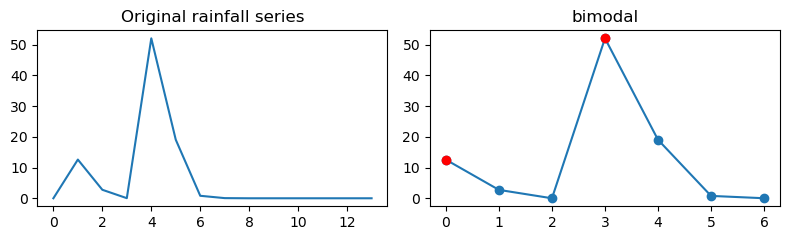

[30.565939    0.24763778]
Event index: 6, result: unimodal, n_peaks: 1


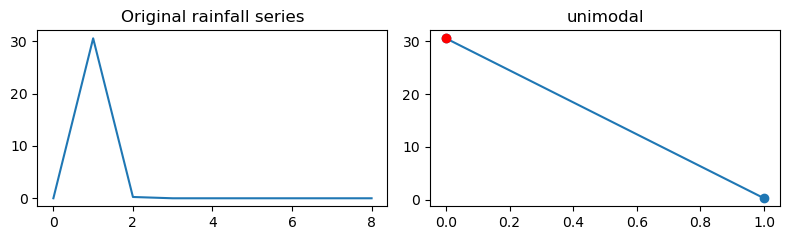

[3.57521591e+01 3.10149565e-02 3.03240180e+00 4.29058343e-01
 2.19203740e-01 1.24575782e+00]
Event index: 22, result: unimodal, n_peaks: 1


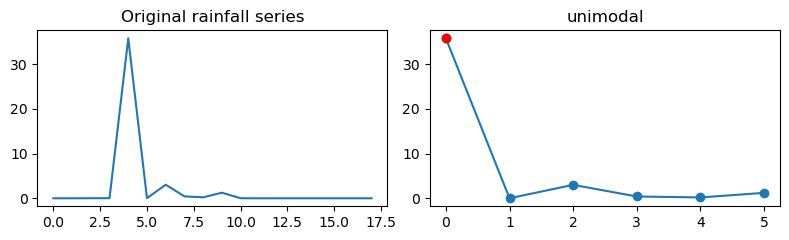

[ 3.9184215  1.6725135  7.3334517 51.296043   5.4328561]
Event index: 49, result: unimodal, n_peaks: 1


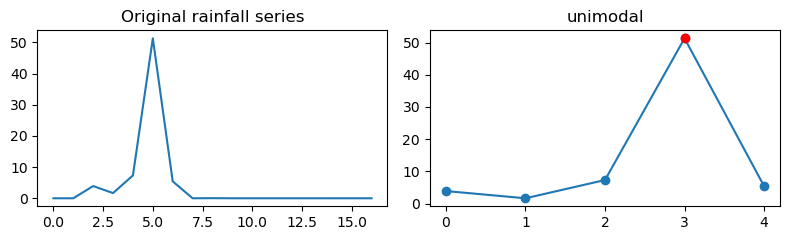

[7.8126532e-01 7.5998870e-03 6.3098557e-02 4.7378292e+00 3.0482798e+01
 1.8973680e+01 3.1666058e-01]
Event index: 54, result: unimodal, n_peaks: 1


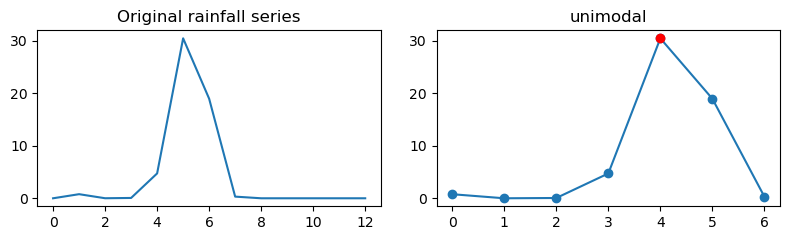

[ 0.07239129  6.1326756   9.7920656   0.24935782 31.239256   16.255404
 13.645734    2.6443253 ]
Event index: 60, result: unimodal, n_peaks: 1


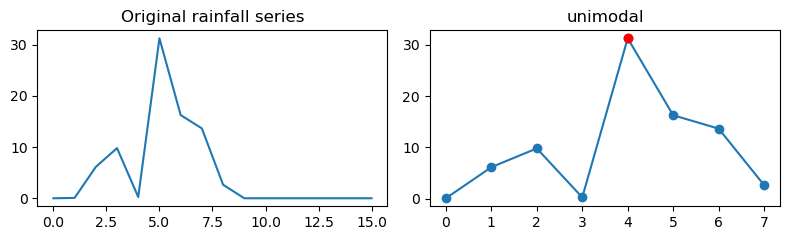

[ 0.21624452 14.139533   50.753849   26.242689    0.35565659  4.7368336
  0.20449273]
Event index: 63, result: unimodal, n_peaks: 1


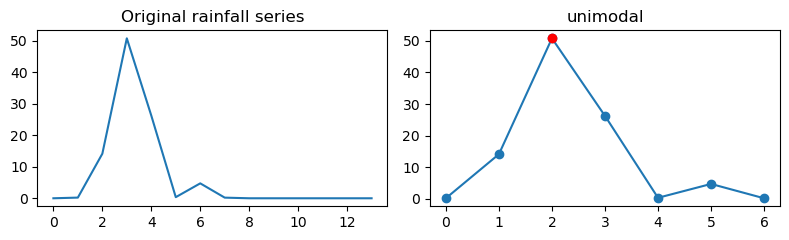

[6.3678563e-01 9.2317313e-02 3.0758150e-04 2.2512524e+01 3.5674656e+01
 5.5347395e-01]
Event index: 78, result: unimodal, n_peaks: 1


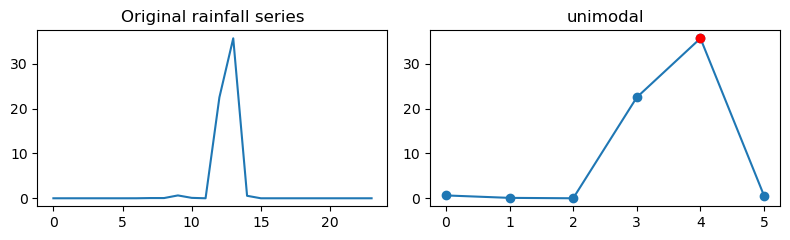

[1.9944578e-01 3.8031527e-01 4.7981065e-02 1.0009292e-06 3.7948373e-06
 2.5488014e-06 5.8091532e-06 1.0133346e-06 4.4850945e-01 2.5613906e+00
 6.6540022e+00 5.0414188e+01 5.2041653e+01 3.7676519e-01]
Event index: 98, result: unimodal, n_peaks: 1


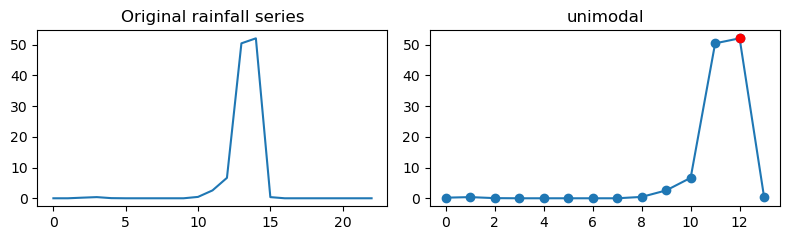

[ 1.7475891   0.23894773  0.42223978  5.1705952   0.23565814 19.374006
 47.581646    3.6913061   0.46781746]
Event index: 121, result: unimodal, n_peaks: 1


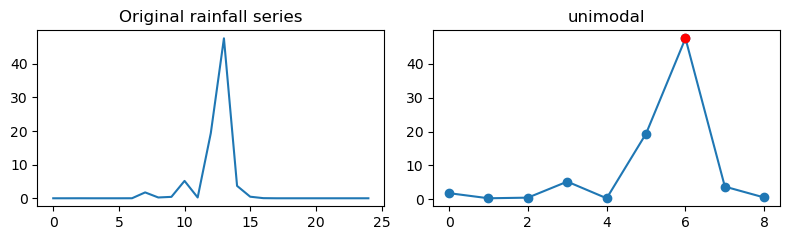

[ 0.24115701 20.74052    34.018688   29.184271    4.3575997  18.273249
  7.6585441   8.9138994   0.66705126  1.6652349 ]
Event index: 145, result: bimodal, n_peaks: 2


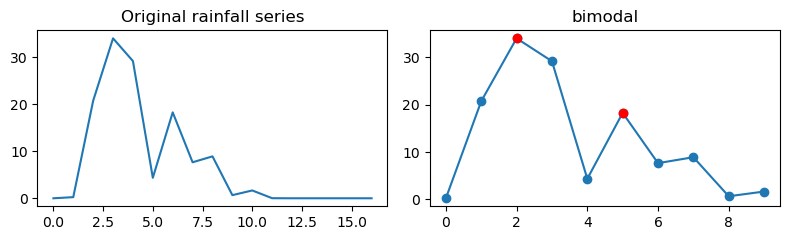

[1.3150207e+00 2.2133535e-01 4.8195259e-03 2.9810790e-03 2.6214225e-04
 4.7800645e-01 4.8077160e-01 4.8129258e-01 4.8248482e+01 1.7914864e+01]
Event index: 147, result: unimodal, n_peaks: 1


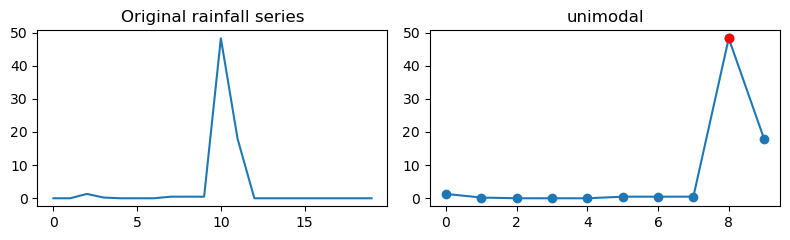

[4.0609562e-01 3.5423409e+01 1.6604488e+01 2.0211060e+01 2.2782290e+00
 2.3137029e-02 1.4215082e-06 9.4530668e-07 1.0124521e-06 1.5754786e-06
 5.4948189e-04 2.9967364e-02 1.6498539e-04 7.8244720e-06 3.0651861e-07
 1.1219804e-06 2.4596339e-03 5.0577903e-01 3.2634255e-01]
Event index: 195, result: unimodal, n_peaks: 1


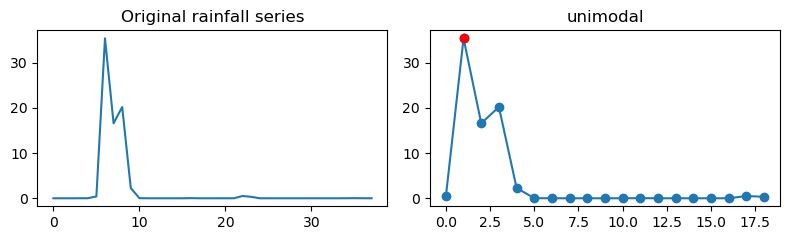

[8.9299224e-02 3.3381955e-05 1.7276221e-06 4.2753649e-01 3.3665993e+01
 9.3532684e+01 2.9096534e+00]
Event index: 213, result: unimodal, n_peaks: 1


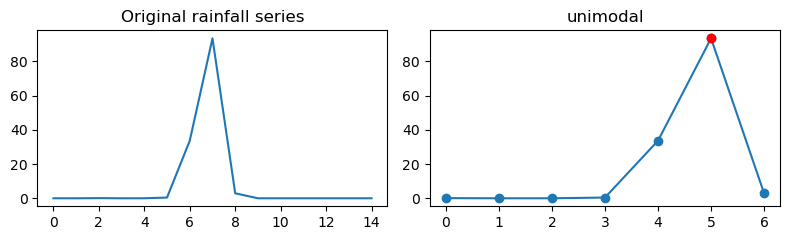

[7.6391399e-01 1.0320012e+01 3.0392137e-01 5.2924815e-06 4.3526864e+00
 4.3707008e+01 3.0485349e+00 1.7443655e-01 4.5186152e-06 3.9093766e-06
 8.1488124e-06 5.0907693e-07 7.5658153e-07 9.7609757e-07 2.4775451e-02
 1.8791431e-01]
Event index: 226, result: bimodal, n_peaks: 2


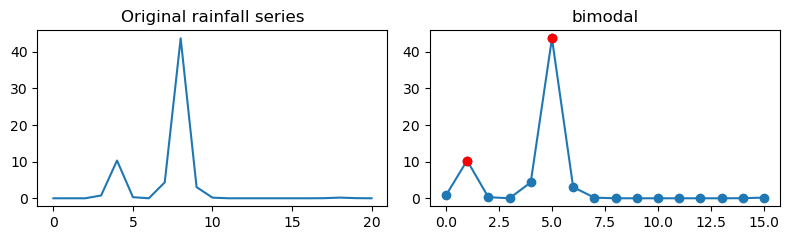

[38.404156]
Event index: 236, result: unimodal, n_peaks: 1


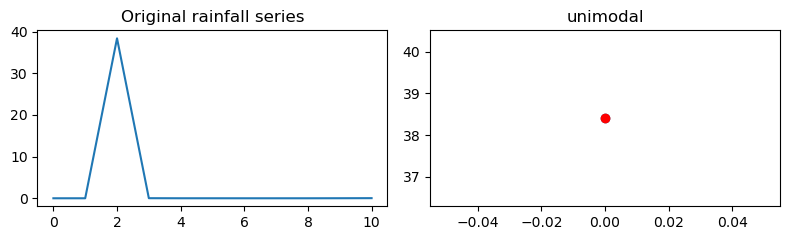

[1.6793597e-01 1.5547101e+00 2.4193454e+00 5.3183754e-07 2.1100022e-01
 5.0575309e-02 7.4246291e-06 1.5923036e-06 1.0179333e-06 7.5332308e-04
 1.2993355e-06 1.4148254e+00 1.5314143e-06 7.9924014e-04 2.1459558e+00
 1.9637591e-06 7.2209950e-06 2.2911485e-03 2.6816288e-01 2.3407159e-05
 1.2375663e-02 5.0486510e-06 2.0214629e-06 6.0604849e+00 7.7823028e-02
 2.9946995e-04 8.0753360e-03 6.0254157e-01 4.0184777e-06 2.4769584e-02
 3.3070627e-04 6.8438128e-03 5.4175477e-03 2.1070162e-05 1.4957340e-04
 1.7324808e-06 1.3466748e-06 1.8507995e-06 1.3379314e-06 1.3489558e-06
 2.5401794e-06 1.0761890e+00 2.5666375e-02 2.8566518e+00 1.7507567e-06
 6.3262053e-07 2.5072825e-07 4.5439771e-01 3.0976992e+00 1.1044547e-01
 3.2972787e-02 7.7906498e-03 6.7087298e-05 4.8906231e-01 1.0636714e-06
 8.5784899e-07 9.9630074e-07 1.9762922e-06 3.1736563e-05 4.7809544e+00
 3.0657743e+01 1.6824986e+01 5.1887037e-04 9.4145605e-07 4.3109100e-02
 2.8934306e-01]
Event index: 247, result: unimodal, n_peaks: 1


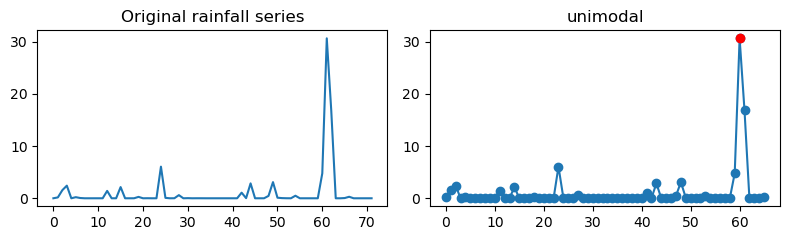

[11.672112  36.188213   1.2395401]
Event index: 298, result: unimodal, n_peaks: 1


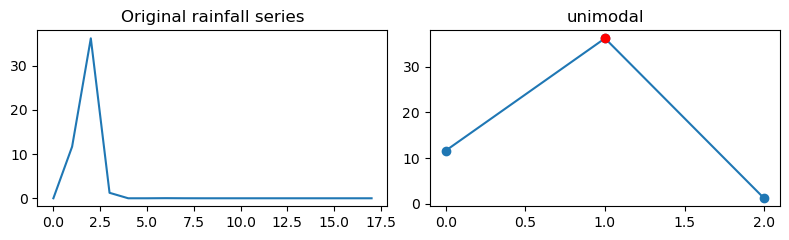

[3.3059880e-01 1.5549384e-01 1.1695780e-02 1.1063194e-06 1.3175883e-06
 8.3347619e-02 1.5378178e-02 1.7645944e-02 2.8698340e-02 3.4730064e+01
 9.6356592e+00 1.4733497e+01 9.9681664e+00 5.6294928e+00]
Event index: 300, result: unimodal, n_peaks: 1


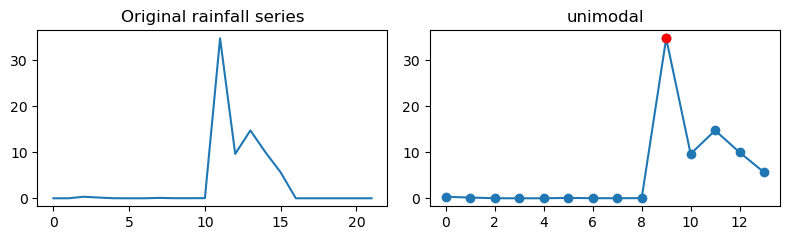

[1.12879537e-01 1.26468927e-01 7.86450598e-03 8.78844261e+00
 1.18426740e+00 1.09458335e-06 1.22301469e-06 9.72300654e-07
 2.26501515e-06 1.31690990e-06 1.55013879e-06 7.10885956e-07
 4.38835651e-01 4.38171513e-02 9.42119896e-01 5.27919674e+00
 2.60659613e-06 3.27574387e-02 7.50756383e-01 2.20253396e+00
 1.67318687e-01 3.04636751e-06 7.23807773e-07 9.13627900e-07
 1.27500539e-06 1.69208465e-06 2.63662514e-06 5.72765586e-08
 7.67236656e-07 2.21205205e-02 1.11139916e-01 2.96646959e-07
 2.98658711e-06 2.93514677e-05 1.09302528e-05 5.87475697e-05
 1.75215483e-01 1.43540055e-01 6.85423464e-02 3.52656901e-01
 5.49655390e+00 2.48800802e+00 2.37156272e-01 8.76853937e-06
 3.23751806e-06 1.06907703e-06 1.25833947e-06 6.60597743e-06
 9.91151202e-04 2.16465760e-05 4.04384639e-03 6.52190352e-07
 2.78686552e-04 1.03620834e+01 3.39205246e+01 3.57969704e+01
 7.38881588e+00 6.98476185e-07 3.77647808e-07 7.75057673e-01
 2.50324905e-01]
Event index: 308, result: unimodal, n_peaks: 1


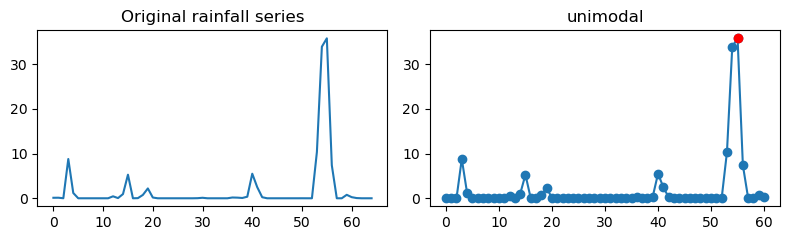

[6.8118967e-02 1.0078849e+00 3.3807969e-06 4.6449536e-06 5.0377721e-06
 3.8859894e-06 3.0810638e-06 2.0819075e-06 8.7333392e-06 5.6210269e-05
 5.4059934e-04 1.2974794e-01 4.7873539e+01 6.8617485e+01 1.9625460e+01]
Event index: 341, result: unimodal, n_peaks: 1


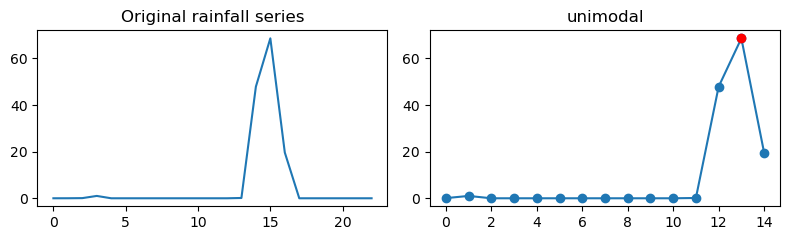

[4.3729439e+00 1.3187337e-02 1.5163992e-01 9.5083380e-01 1.0252911e+01
 3.0311365e+01 2.3941226e+00]
Event index: 348, result: unimodal, n_peaks: 1


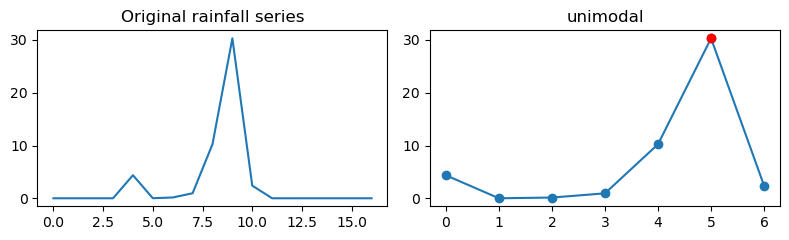

[4.0000150e-01 3.1191772e-01 1.0955490e-03 2.2337763e-03 1.8255513e-02
 4.6765313e+00 7.5679263e-03 5.0062440e-06 6.3925072e-05 2.3832559e-03
 7.9790940e+00 1.0689604e+01 6.5489471e-02 3.9396408e+01 4.0863295e+00
 5.1510563e+01 4.3847157e+01 1.4550314e+01 1.1830790e+00]
Event index: 404, result: bimodal, n_peaks: 2


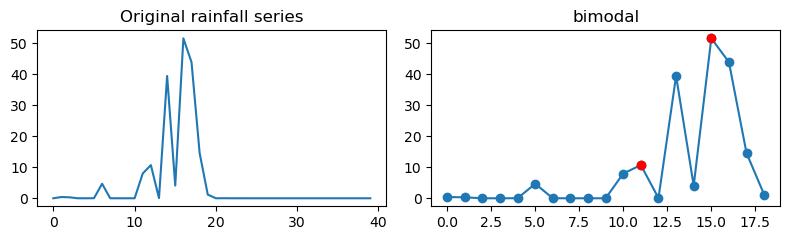

[41.6861   11.564371]
Event index: 474, result: unimodal, n_peaks: 1


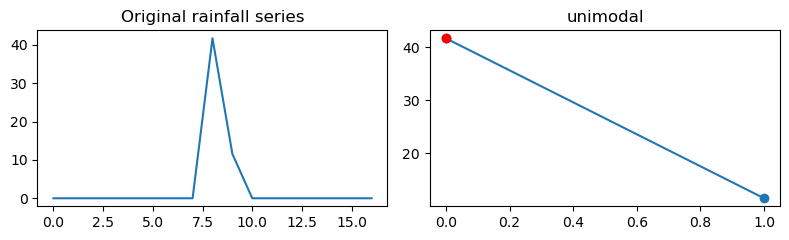

[3.0615326e+01 1.7104324e+01 5.3154320e-01 5.2997437e-03 7.8529373e-02]
Event index: 488, result: unimodal, n_peaks: 1


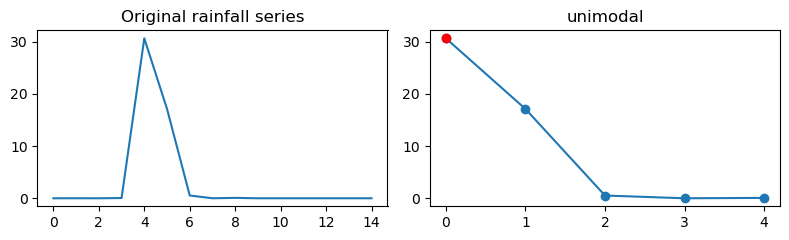

[ 0.68095183 49.679531    4.6054006 ]
Event index: 547, result: unimodal, n_peaks: 1


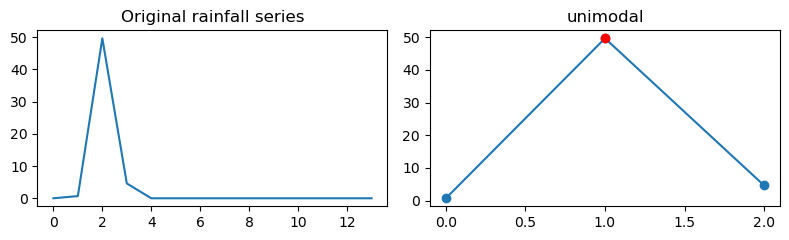

[3.6023670e-01 7.5668311e-07 1.9816985e-06 1.2329325e-06 1.7275444e-04
 1.8062674e-01 9.2696323e+00 3.2899410e+01 2.4234076e+01 2.3187220e+00
 5.3311080e-02]
Event index: 553, result: unimodal, n_peaks: 1


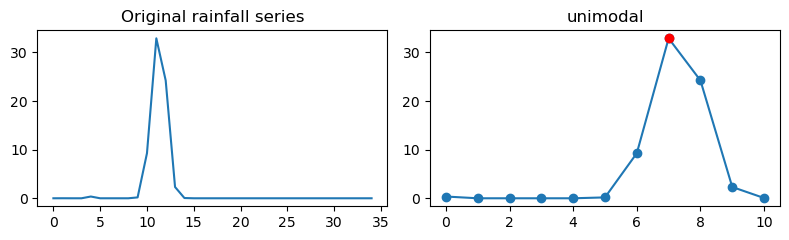

[9.37529850e+00 3.96614532e+01 1.54895052e-01 8.45516473e-03
 2.15219259e-01 1.21139863e-06 3.14909130e-06 1.58601051e-06
 1.59815193e-06 9.76176693e-07 2.14519878e-06 2.45671615e-01]
Event index: 567, result: unimodal, n_peaks: 1


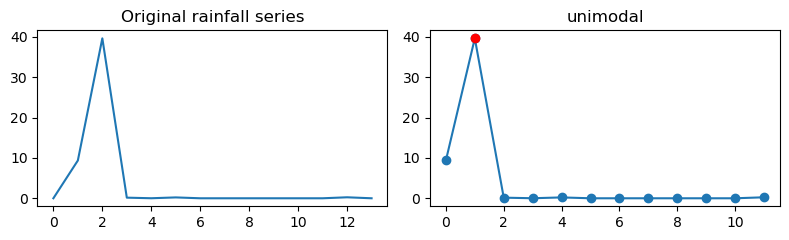

[ 0.39535883  5.7305508  50.776321    1.0818312 ]
Event index: 569, result: unimodal, n_peaks: 1


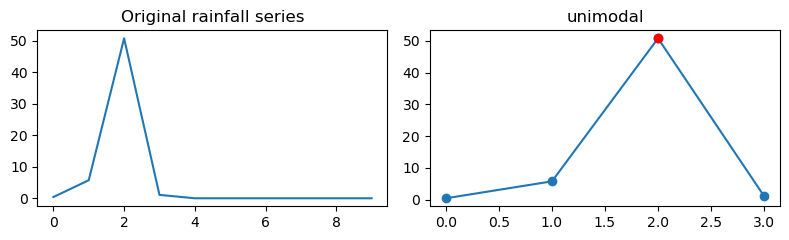

[ 8.0164471  33.713375    6.1561852   0.80604726  0.08285481]
Event index: 571, result: unimodal, n_peaks: 1


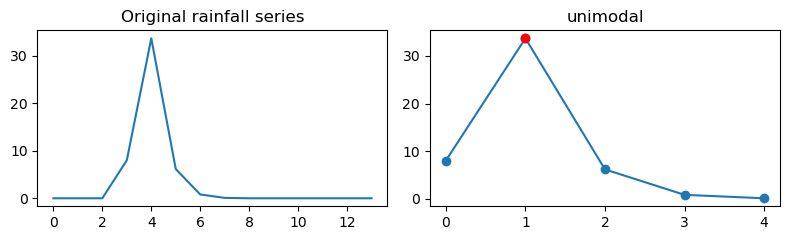

[ 0.50590843  3.9599235   4.8841367   1.5390338  37.64743     3.6412554 ]
Event index: 615, result: unimodal, n_peaks: 1


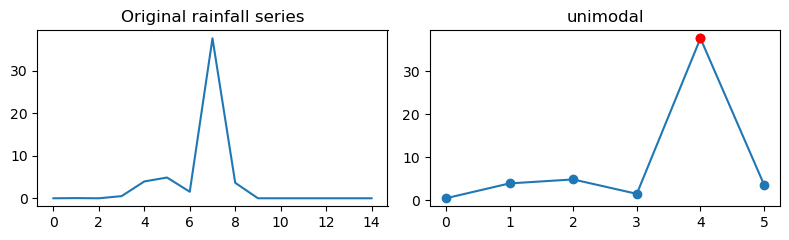

[ 0.33203623 30.903786    2.5876632 ]
Event index: 635, result: unimodal, n_peaks: 1


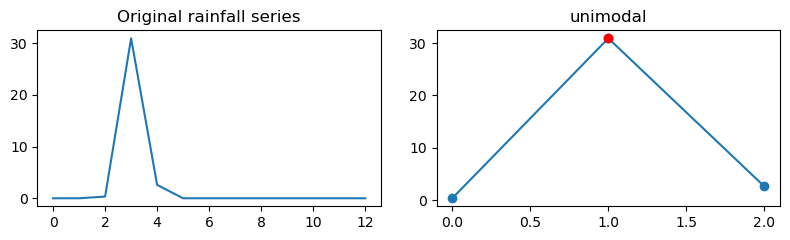

[ 0.05834408  0.05028173  1.1608411   4.6052456   2.8943245  34.226959
  7.0433998   6.4407301   5.0057478   1.2603127   0.40225303  0.27041531
  0.31694648  0.38731512]
Event index: 650, result: unimodal, n_peaks: 1


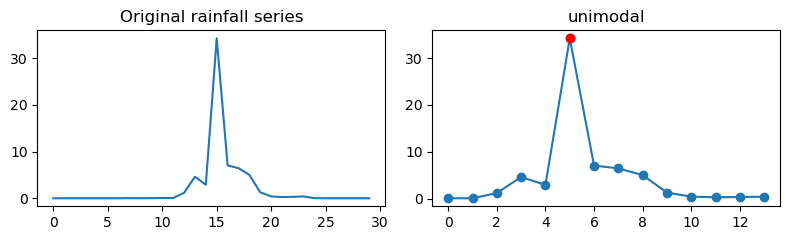

[5.6318631e+00 1.0013730e+01 9.8751478e+00 6.5032326e-02 2.5499463e+00
 4.8490593e+01 1.1578987e+01 5.1212849e+01 1.2409200e+01 1.6814606e-02
 5.9151978e-07 7.2061255e-07 1.2455095e-03 5.9139904e-02]
Event index: 683, result: bimodal, n_peaks: 2


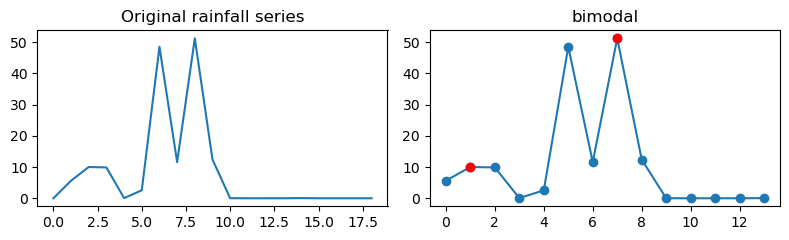

[3.98813415e+00 3.23277702e+01 9.90371513e+00 9.79817867e+00
 7.13859940e+00 2.50322199e+00 2.54143886e-02 7.99498737e-01
 2.93437302e-01 1.53384435e+00 1.93988311e+00 3.91684842e+00
 3.75533938e+00 1.23935986e+00 2.87174992e-02 1.65835845e-05
 1.20213335e-04 2.58860236e-05 2.19021376e-06 8.62938293e-07
 4.33985974e-07 4.20763035e-06 1.14063041e-05 1.60571337e-01
 5.45773923e-01 4.86831367e-03 5.20608664e-01 2.60116792e+00
 5.26971996e-01 7.66857713e-02 1.60121590e-01 1.88510966e+00
 6.18925691e-01 5.09812199e-02 3.35758645e-03 5.04793934e-06
 7.23810168e-04 1.71424925e-01]
Event index: 691, result: unimodal, n_peaks: 1


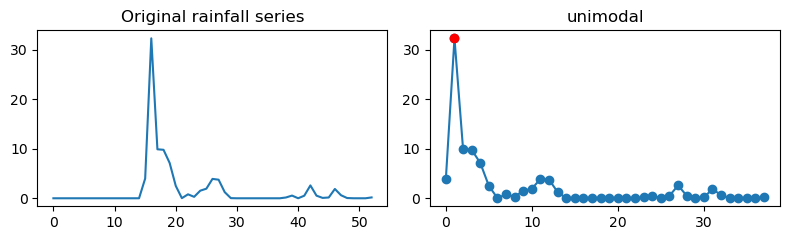

[ 1.5144444  3.4383876  5.5197635  7.4534316 10.91799   33.109337
 24.509687   0.5150227]
Event index: 798, result: unimodal, n_peaks: 1


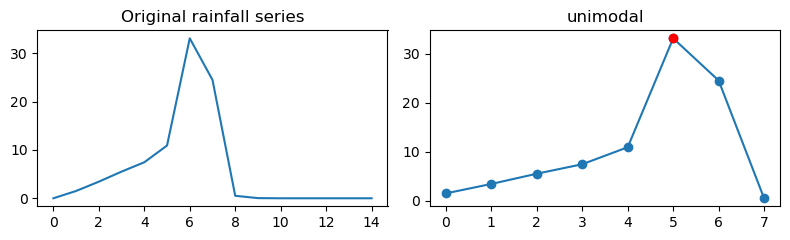

[1.04099996e-01 6.40818071e+00 3.12976437e+01 5.80281639e+01
 1.03574181e+01 5.56880832e-02 5.29191084e-02 3.82315022e-07
 2.94333531e-05 1.19432254e-04 9.31929317e-05 3.46336674e-05
 6.84241604e-06 2.42943588e-06 1.73721128e-06 4.13585440e-05
 3.41554805e-05 5.43483160e-03 4.41291122e-05 8.95714311e-06
 4.27690793e-06 4.35943633e-01]
Event index: 807, result: unimodal, n_peaks: 1


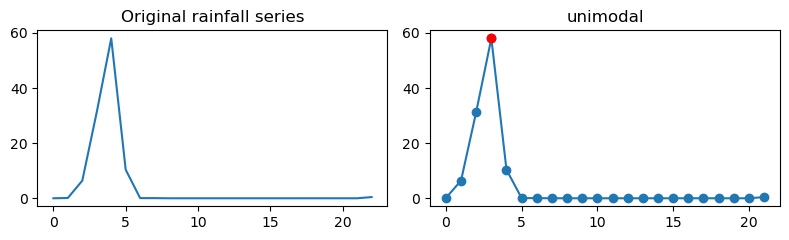

[ 0.13090552 37.135136    0.17868428]
Event index: 848, result: unimodal, n_peaks: 1


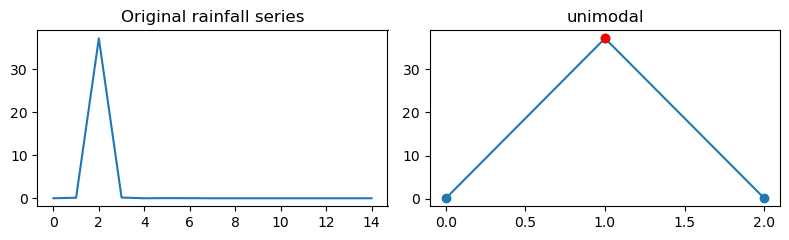

[ 7.6299376  59.93293    14.457528   13.404166    0.06422926]
Event index: 851, result: unimodal, n_peaks: 1


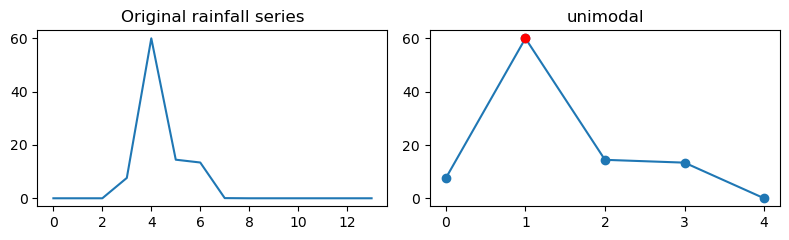

[2.9852304e-01 1.0014199e-06 6.7115838e-07 5.9255575e-07 2.3435444e-02
 3.0307448e-02 5.8899021e-01 1.7502879e-03 3.4842316e-07 2.5831838e-07
 4.0169943e-02 5.4026591e-03 1.4221720e+00 1.1662479e-02 5.1640439e-01
 1.3466374e-02 2.1100441e-07 6.4343817e-07 6.9485253e-07 1.1489876e-06
 4.3003132e-07 9.2620752e-07 4.6048672e-07 1.8361429e+00 2.5885961e+00
 3.1148748e+01 4.7875819e+00 1.5270216e+01 6.1599326e+00 2.5181310e+00
 3.4958884e-01 3.2571351e-04 1.2151763e-06 5.7165119e-07 4.0709232e-03
 5.4735470e-01 2.4023917e-01 4.4203812e-01 2.9211736e+00 5.4917564e+00
 1.0972647e+01 7.3510444e-01]
Event index: 863, result: bimodal, n_peaks: 2


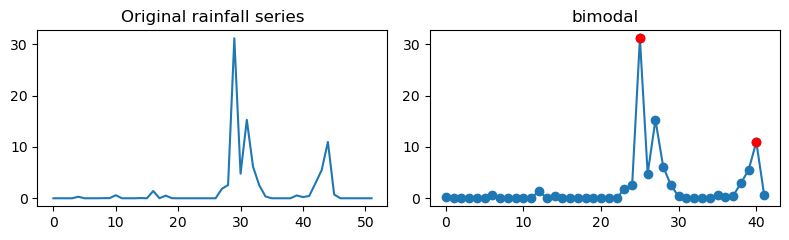

[ 0.18229637 32.080963    0.59887403 19.398046    0.41930076]
Event index: 897, result: unimodal, n_peaks: 1


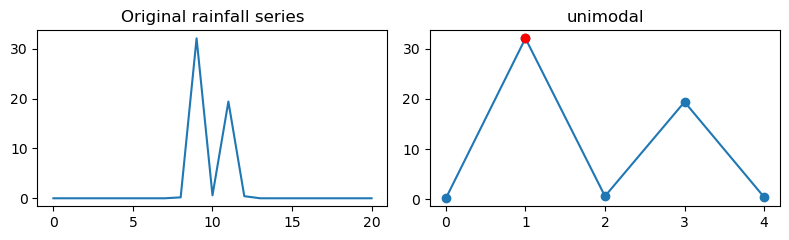

[1.3292244e+01 1.7635968e+00 4.9467758e+01 3.7133984e+01 1.7043028e+00
 1.2854937e-01 2.6064445e-03 9.2286808e-07 7.6002846e-07 5.9357558e-07
 1.4042891e-07 2.8332281e-07 8.4188933e-08 1.1076686e-05 8.0386454e-01
 1.3625281e+00]
Event index: 904, result: bimodal, n_peaks: 2


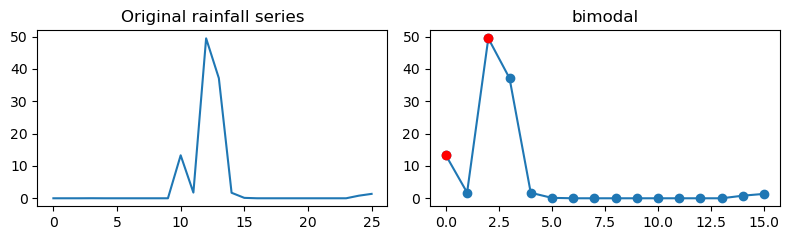

[2.6910744e+01 5.8271515e+01 2.3128735e+01 1.4004234e-02 6.2503438e-03
 3.4745865e-06 2.0410434e-05 6.2171380e-06 1.8414601e-06 8.1472768e-07
 2.6040984e-06 1.5259893e-06 1.7374924e-06 9.2284581e-06 3.3869263e-05
 7.7698672e-01]
Event index: 907, result: unimodal, n_peaks: 1


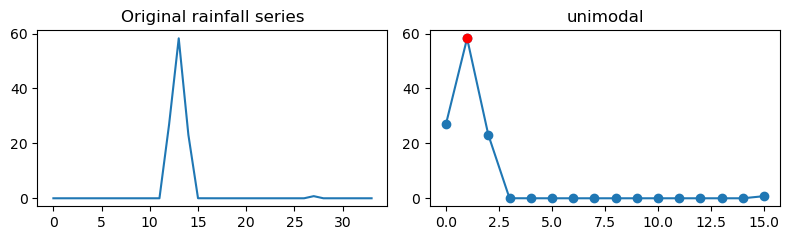

[42.936939   3.8619998]
Event index: 917, result: unimodal, n_peaks: 1


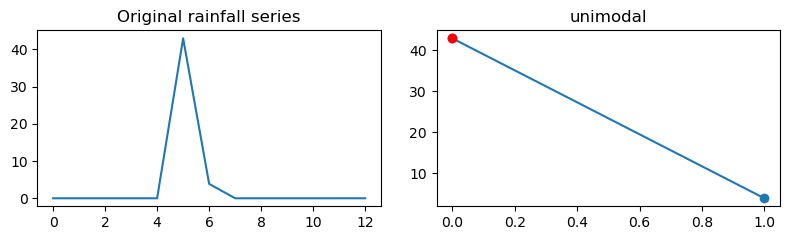

[ 0.07048648  0.10173262  4.6544518   0.3220605   5.7051191  45.458927
 21.915361    0.18287271]
Event index: 921, result: unimodal, n_peaks: 1


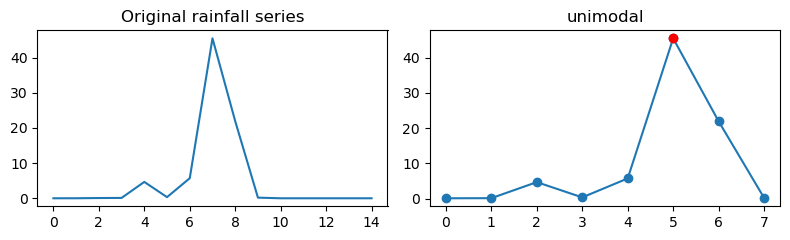

[ 4.4896445 30.161354   4.9277811 85.59581   27.595119  21.926548
  3.8233082]
Event index: 922, result: unimodal, n_peaks: 1


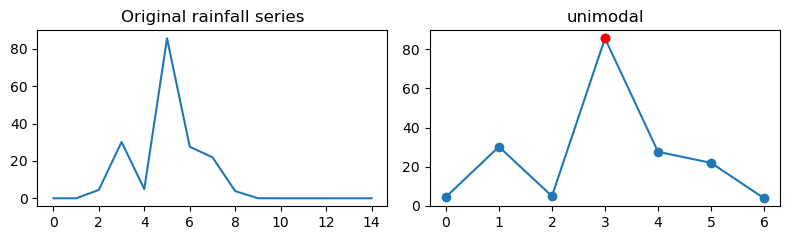

[1.00372307e-01 4.21663981e-06 2.02807635e-01 1.91277422e-06
 4.15007807e-02 6.96143731e-02 1.15357906e-01 9.57419991e-01
 6.33158028e-01 1.35676324e-01 6.53357688e-07 1.05768390e-06
 8.08232983e-07 2.66734103e-04 9.31234467e-07 7.40800083e-01
 2.94294906e+00 3.83698583e+00 6.42210603e-01 1.50547779e+00
 5.45695305e+00 6.35288143e+00 2.13831878e+00 5.48653364e+00
 2.98325479e-01 1.79410927e-06 1.52429857e-06 9.23188491e-05
 1.49170461e-03 2.62693720e-06 3.22641995e-06 3.63930690e-06
 2.92138293e-06 2.78197899e-06 2.82027668e-06 3.35075073e-02
 3.21548737e-06 5.63740921e+00 2.42647729e-06 1.77924244e-06
 1.43780017e-06 1.19490562e-06 5.70851682e-07 7.90909951e-07
 6.35352699e-05 4.90162165e-06 1.42515296e-06 8.05504328e-07
 8.77097307e-07 6.39785867e-07 7.52001995e-07 3.33846435e-02
 4.38725634e-04 5.36449534e-07 1.47247499e-06 1.29678745e-06
 1.38629741e-06 1.02674437e-06 3.96370471e-01 1.22317958e+00
 1.05538702e-05 4.69530642e-05 1.24411054e-06 6.08035975e-07
 4.76232022e-01 3.497980

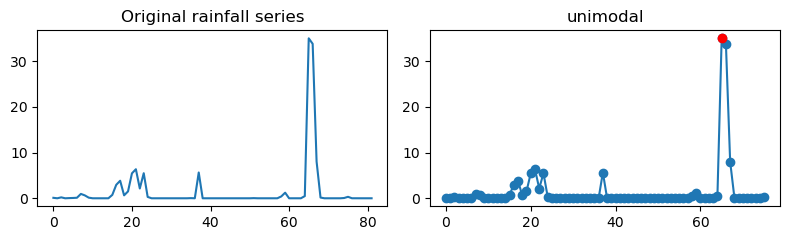

[ 2.8491912   3.4822168  10.812291   34.254627    0.26402342]
Event index: 944, result: unimodal, n_peaks: 1


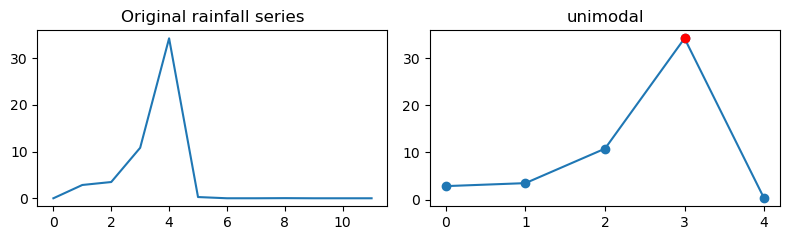

[1.5336318e+00 3.0725739e+01 1.4032600e+01 3.0389266e+00 1.5535063e+00
 1.4522390e+00 4.5297712e-01 1.8387436e-07 3.1665596e-07 1.3320274e-08
 0.0000000e+00 6.5196964e-08 5.0373961e-05 3.7084076e-06 2.3702247e-01]
Event index: 951, result: unimodal, n_peaks: 1


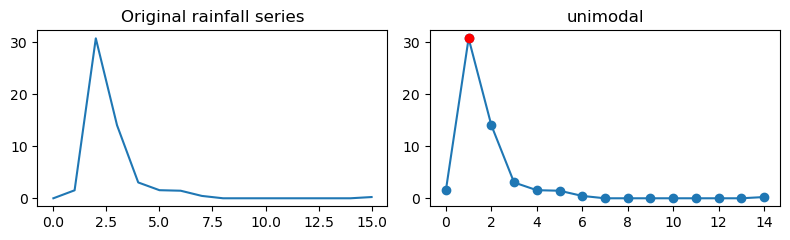

[5.2114053e+00 3.3949245e+01 1.1816305e+01 5.5685573e+00 1.2668126e+00
 9.9365162e-03 8.0822235e-07 6.3638606e-07 1.1023732e-06 3.4134735e-06
 5.2971500e-06 2.2576130e-06 1.4358668e-01]
Event index: 969, result: unimodal, n_peaks: 1


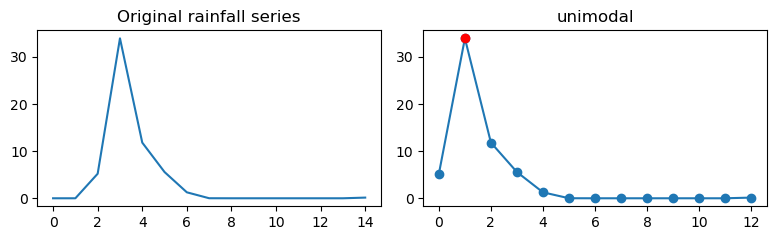

[ 0.33323258  5.8281479  38.443165    5.764183  ]
Event index: 976, result: unimodal, n_peaks: 1


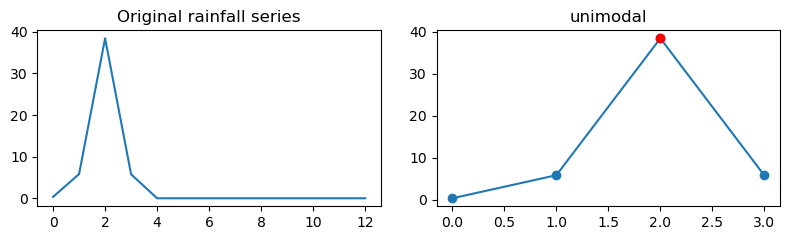

[ 0.07154745  6.2385354  31.062338   11.22756     3.461937    0.57742637]
Event index: 994, result: unimodal, n_peaks: 1


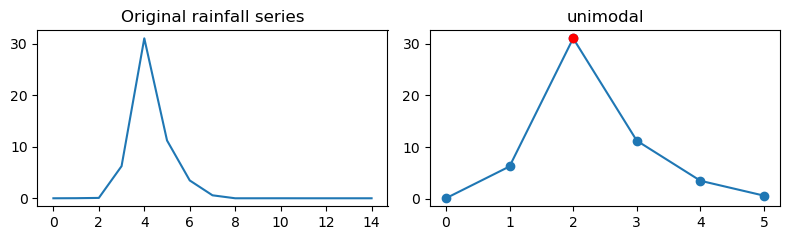

[6.2660319e-01 4.1427300e-03 1.5550242e-01 3.6946716e+01 5.8184731e-01
 1.0329348e+00]
Event index: 1033, result: unimodal, n_peaks: 1


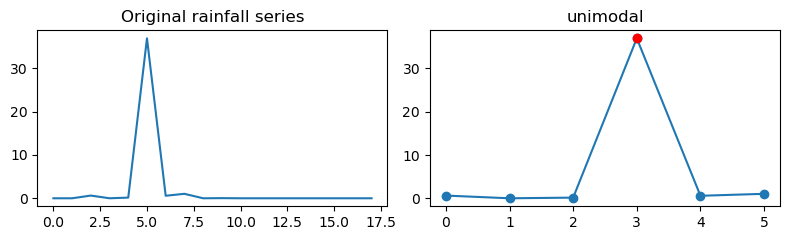

[5.0115556e-01 2.1046922e+00 2.4012564e-02 1.5812848e-02 5.1812804e-03
 1.3511243e+00 4.4312550e+01 7.7404132e+00 5.8880563e+00 2.2339782e-06
 3.1039360e-06 5.3540034e+00 1.9295695e-01 6.1836810e+00 1.1169922e-01]
Event index: 1086, result: unimodal, n_peaks: 1


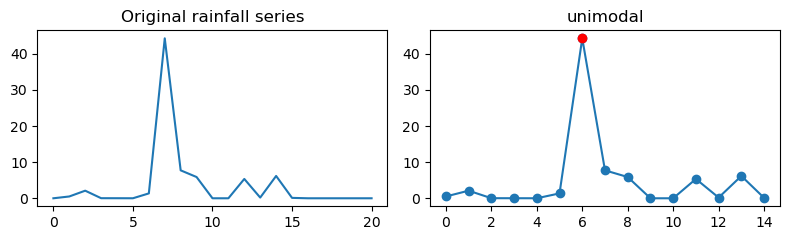

[ 1.736802   6.9734969 37.330719   4.7846513]
Event index: 1102, result: unimodal, n_peaks: 1


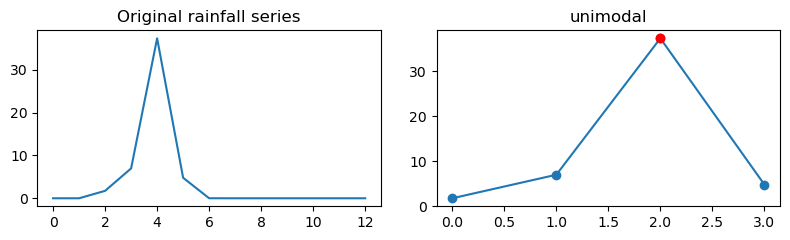

[1.7411928e+00 1.7716357e+00 4.5372090e+00 6.5766740e+00 8.9815998e+00
 8.8082752e+00 1.5349296e+01 3.3458118e+01 7.1861467e+00 1.1145523e-01
 4.0985918e+00 3.4121389e+00 4.8267174e-01 9.3612271e-06 2.8035854e-06
 1.9906581e-06 4.6136538e-06 1.3581055e-06 1.1939032e-06 1.9816209e-01]
Event index: 1111, result: unimodal, n_peaks: 1


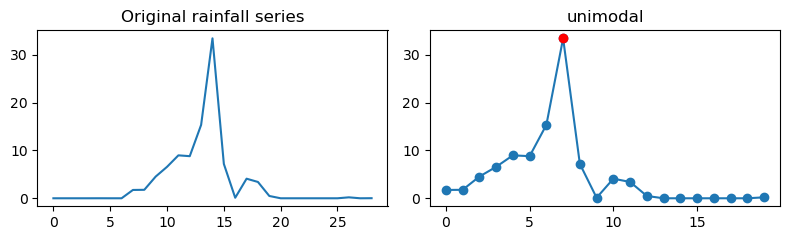

[ 7.7033    27.431852  33.296169   2.8895299  0.0804866]
Event index: 1127, result: unimodal, n_peaks: 1


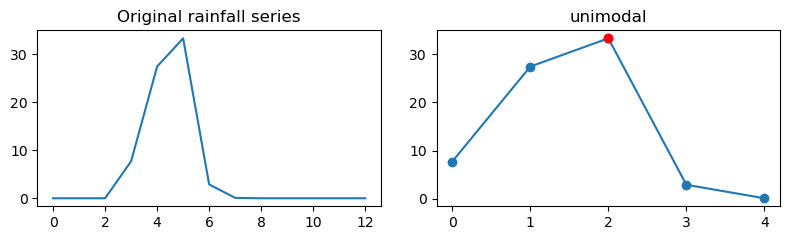

[ 1.9426993  38.061573    0.42783499]
Event index: 1168, result: unimodal, n_peaks: 1


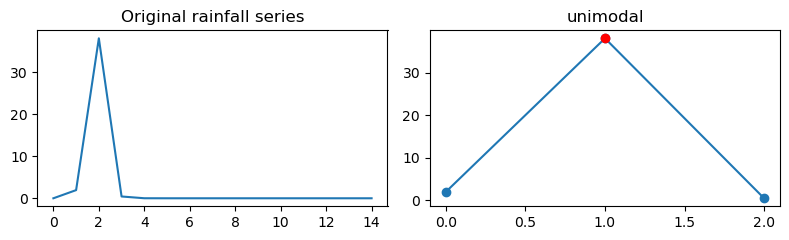

[13.77812   34.365189   2.0912397]
Event index: 1191, result: unimodal, n_peaks: 1


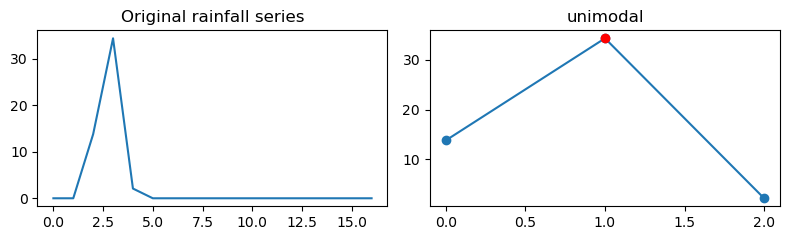

[ 0.81279576  0.14235687 30.43424     4.7864947 ]
Event index: 1200, result: unimodal, n_peaks: 1


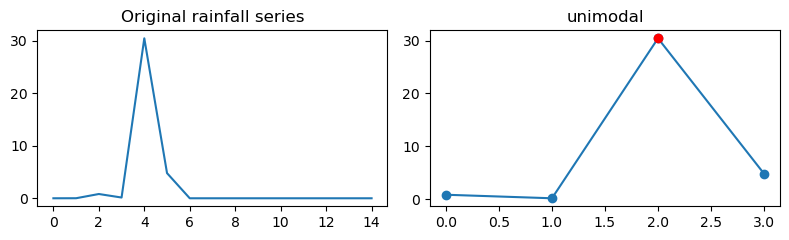

[3.0582657e-01 1.0269737e-06 1.2281309e+01 2.1492502e+01 3.5143456e+01
 4.8409390e-01]
Event index: 1233, result: unimodal, n_peaks: 1


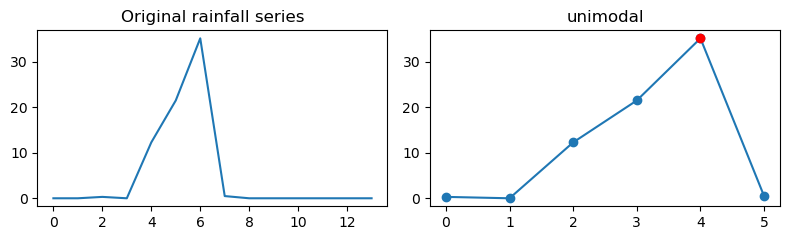

[6.3301764e-02 9.5405336e-04 3.5933326e-06 2.7912158e-06 1.3631871e-03
 1.7832428e-01 5.5841005e-01 2.2525274e+01 4.6520576e+01 8.1123590e+00
 1.6961782e-01]
Event index: 1243, result: unimodal, n_peaks: 1


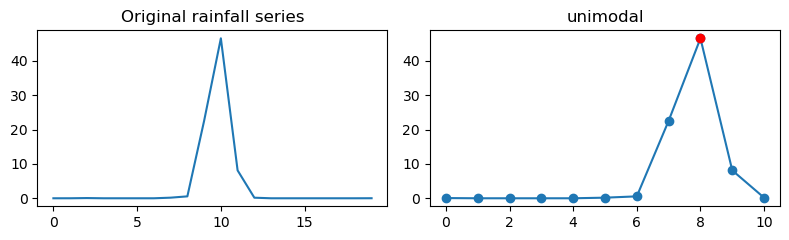

[2.19163489e+00 8.97363853e+00 3.60756645e+01 2.87397366e+01
 7.93597603e+00 1.24214016e-01 2.34075770e-01 4.01809253e-03
 8.21497478e-03 5.73192835e-02 3.25679827e+00 1.61795447e-06
 9.89331901e-01 1.06702462e-01 7.33146258e-03 1.05441071e-03
 6.56314739e-07 1.04321589e-06 1.89430750e-06 1.93395408e-06
 6.91861032e-06 5.54779964e-03 1.48460126e+00 5.85424066e-01
 1.65064455e-06 1.74864218e-01 1.23803802e-02 3.02427611e-03
 1.13946171e-02 5.99548042e-01]
Event index: 1258, result: unimodal, n_peaks: 1


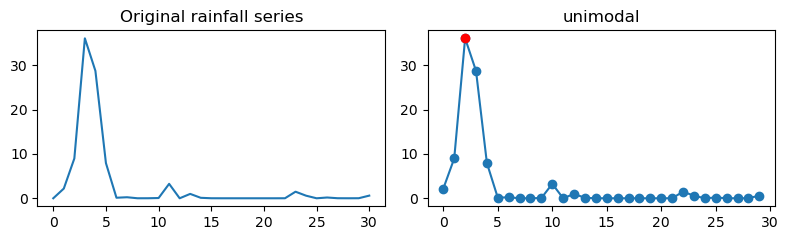

[ 5.3664308 32.812778   8.2394218]
Event index: 1268, result: unimodal, n_peaks: 1


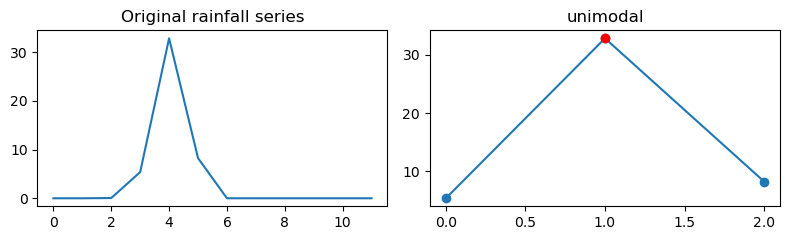

[2.7310472e+01 2.3061738e+00 1.6107476e+00 2.0620218e-02 3.4820867e+00
 4.6082760e+01 1.8693764e+01 5.0711858e-01 3.2577759e-01]
Event index: 1291, result: bimodal, n_peaks: 2


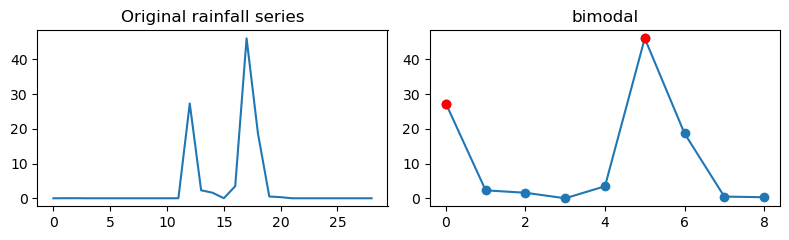

[6.7941405e-02 4.6358309e+00 2.1670252e+01 6.1421939e-03 3.8086066e-06
 3.6478364e-06 2.9143416e-07 5.1961484e-07 9.4784275e-07 4.9293735e-03
 8.2394479e-07 1.1825610e+00 4.2973827e+01 7.8635578e+00]
Event index: 1303, result: bimodal, n_peaks: 2


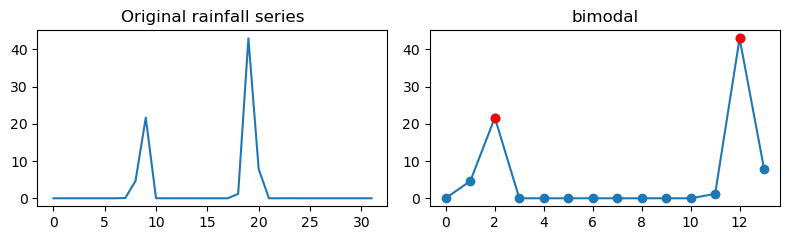

[6.17223322e-01 3.78709245e+00 5.90164065e-01 2.05243111e+00
 3.13009310e+00 1.59455089e-06 1.56000158e-06 1.24685323e-06
 1.70348653e-06 6.51451387e-03 1.71408283e-05 6.35682397e-07
 3.03759975e-07 2.67595202e-01 4.48721920e-07 5.25919631e-07
 1.17887747e+00 3.32259464e+00 2.70957053e-02 1.27774160e-06
 9.52886301e-04 4.10966123e-07 9.87893701e-01 7.67943501e-01
 3.74101009e-03 2.01615646e-01 4.63169627e-03 1.94622635e-06
 1.11003612e-06 4.06337676e-07 9.93855679e-07 2.58125533e-06
 2.84195048e-05 6.73331022e-02 3.55437130e-01 4.23755422e-02
 2.57741212e-05 1.40747636e-06 2.13045096e+00 1.52178502e+00
 3.32267036e+01 2.29888039e+01 3.47210455e+00]
Event index: 1306, result: unimodal, n_peaks: 1


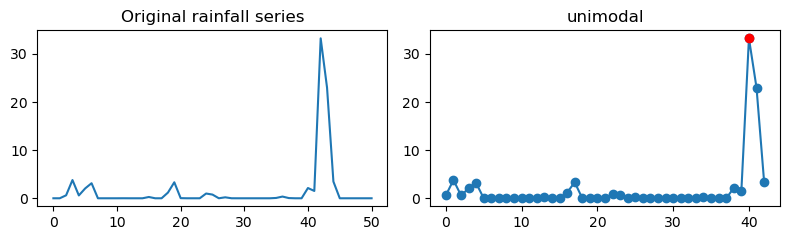

[9.6295919e+00 1.4041909e+00 5.9488342e+01 1.4474011e+01 9.2559285e-02
 4.4689856e-02 1.4481533e-01 1.8353570e+00 2.8832271e+00 2.0627377e+00]
Event index: 1311, result: unimodal, n_peaks: 1


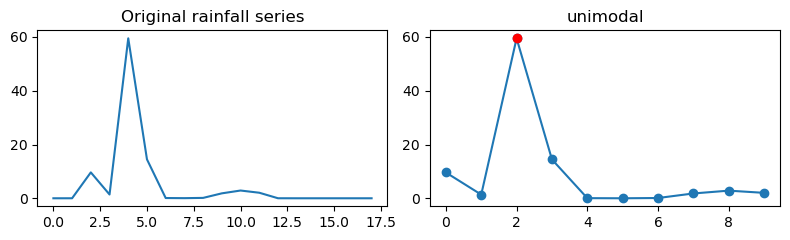

[8.84997666e-01 1.58663750e+00 3.69745374e-01 4.24183236e-06
 7.42672796e-07 8.65704123e-07 1.34723820e-02 1.54949407e-06
 5.37661428e-04 6.65361267e-06 4.00156761e-03 1.00403063e-01
 6.42535388e-01 2.53672533e-06 2.87445187e-06 2.21170899e-06
 2.02493084e-06 2.40971281e-06 1.25452505e-06 1.44474041e-06
 1.04074945e-06 7.71242231e-02 4.85101223e-01 1.64301912e-06
 2.32931507e-06 1.71250349e-06 4.02658003e-07 1.30827284e+00
 4.30220270e+00 3.27868152e+00 1.32389879e+01 3.08064499e+01
 3.17855060e-01]
Event index: 1325, result: unimodal, n_peaks: 1


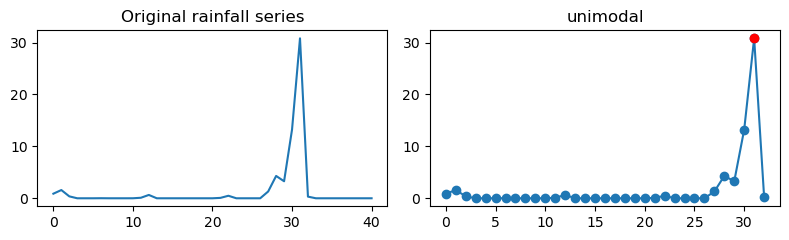

[1.9940816e-01 5.3907865e-01 2.1712422e-05 1.2476623e-05 5.5798155e-06
 3.8027087e-01 3.3501197e-02 8.1568661e+00 5.0703350e+01 9.8752308e+00
 1.2207010e-02 6.5423433e-06 1.4624857e-02 2.4774145e-06 9.0742402e-02
 4.0509361e-01 2.0831920e-05 8.0614969e-02]
Event index: 1331, result: unimodal, n_peaks: 1


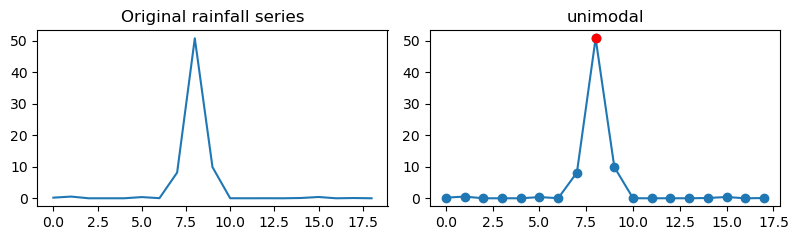

[10.777528   1.5602162 46.795372   5.4830151]
Event index: 1349, result: bimodal, n_peaks: 2


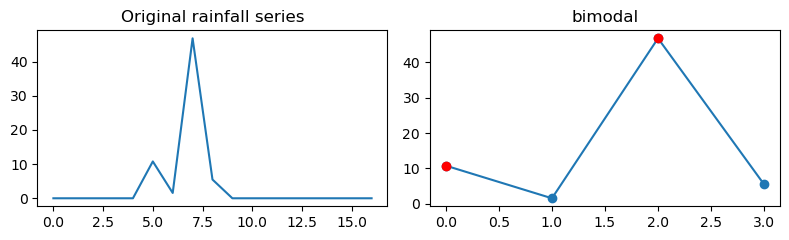

[ 1.2179824   0.57292175  1.6672431  56.475807   28.876961    8.9307852 ]
Event index: 1359, result: unimodal, n_peaks: 1


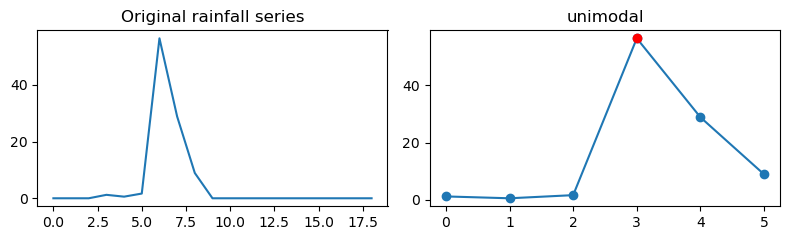

[2.8156751e-01 1.7995569e+00 1.4525520e-02 1.7690377e-02 2.6433097e-06
 2.8740720e-05 2.8192294e+00 7.4258924e-02 1.8332429e-02 1.6783016e-06
 2.8077802e-06 9.3846327e-01 1.0801162e-01 1.7903914e-03 2.9738026e-03
 4.6932392e+00 1.4764385e+00 1.9587666e+01 3.1556597e+01 2.7494364e+00]
Event index: 1382, result: unimodal, n_peaks: 1


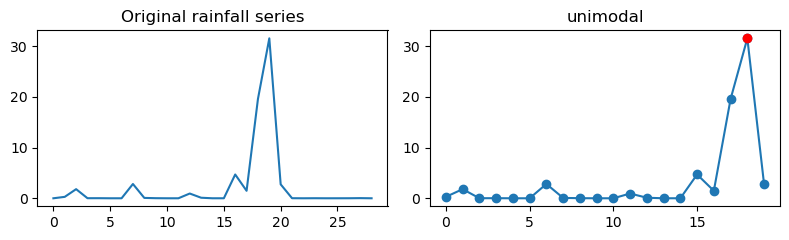

[2.2362635e+00 3.9694660e+01 6.9558468e+00 2.5501640e-07 1.4165684e+01
 3.9025047e+00]
Event index: 1413, result: bimodal, n_peaks: 2


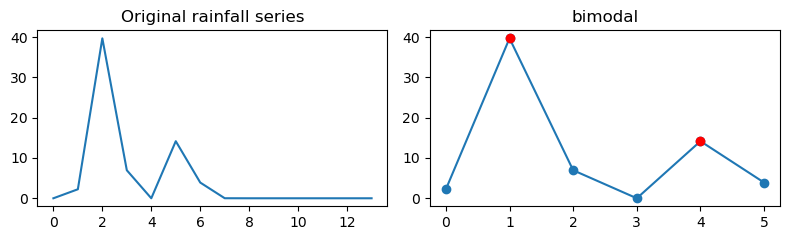

[3.1648907e-01 1.4013306e+00 1.3180157e+00 2.0285285e-01 5.7881575e+00
 2.4747726e-02 8.0957847e-07 6.0698784e-07 5.2466834e-07 9.9633327e-03
 2.1728455e+01 3.5053589e+01 1.5752911e+01 8.9082909e+00 1.4636917e-02
 1.4865194e-06 5.2142050e-04 6.5574878e-01 1.2045011e-01 9.1411981e-05
 6.8116485e-04 5.8837333e-03 8.6852740e-03 6.9703171e-03 7.3104684e-04
 2.3236307e-05 9.9152965e-07 2.2228456e+00 2.5900421e+00 3.0999216e-01
 4.2275419e+00 4.2772316e+01 1.5618925e+00]
Event index: 1426, result: bimodal, n_peaks: 2


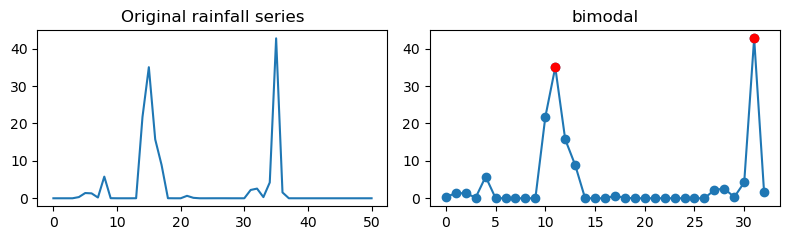

[2.4498464e-01 3.1715939e+00 3.1771651e-03 7.8025823e-06 3.7097291e-03
 5.5644087e-02 2.1135819e-04 5.3237757e-04 1.0887028e-06 8.3600342e-02
 4.2900972e-02 8.5147889e-07 1.5064423e-01 1.9886962e-01 3.0106463e+00
 1.4451576e+01 4.8276928e+01 2.1099284e+00 1.2528365e+00]
Event index: 1524, result: unimodal, n_peaks: 1


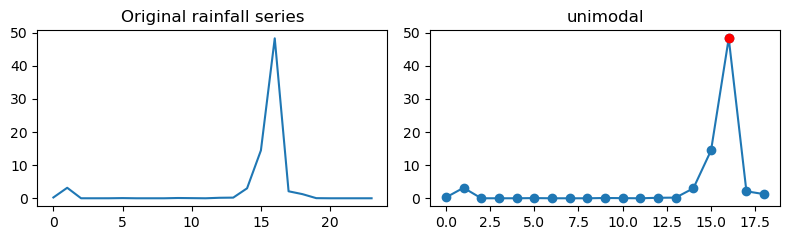

[3.7771335e+00 2.4000305e-05 1.2180738e+01 3.0293575e+01 4.6882561e-01]
Event index: 1535, result: unimodal, n_peaks: 1


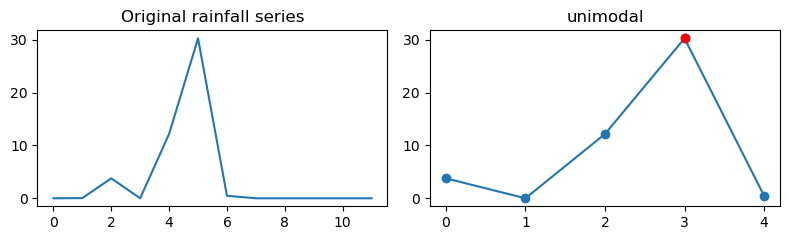

[ 0.93273479 31.459631   40.992355    0.94405657]
Event index: 1549, result: unimodal, n_peaks: 1


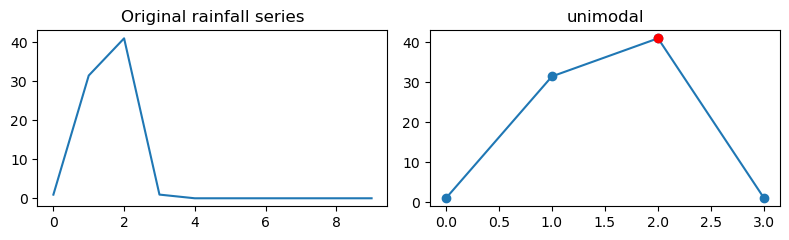

[ 2.3345344 36.332527  29.188223  20.352135   4.4012876]
Event index: 1578, result: unimodal, n_peaks: 1


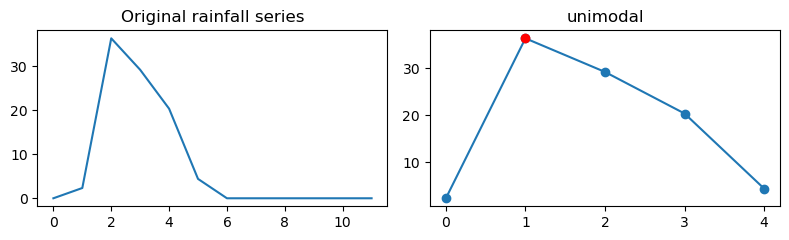

[ 1.566303    3.9843926   1.6985391   0.85145235 16.931019   53.593884
  4.9594069   6.9219537   8.9763775   9.6344595   0.1568123   1.5760455 ]
Event index: 1593, result: unimodal, n_peaks: 1


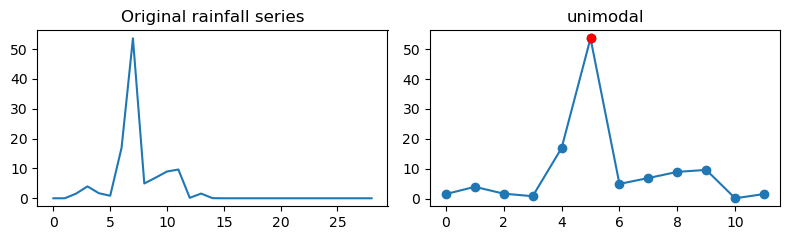

[2.3122127e-01 8.7320320e-03 2.2934958e-06 2.1932997e-04 1.3704242e-03
 6.7232536e-06 2.7156530e-06 1.2159886e-06 3.1076132e-07 2.2539589e-07
 3.4619393e-07 6.5621492e-07 4.9970630e-01 7.6729479e+00 9.8511428e-02
 3.2479694e+01 1.3867038e+01 3.3188573e-01]
Event index: 1620, result: unimodal, n_peaks: 1


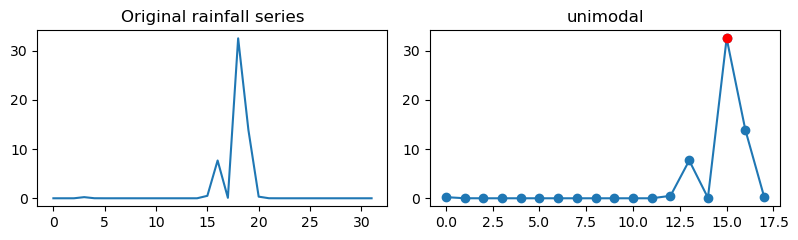

[2.1726157e-01 3.0191556e-01 4.2171981e-03 3.4479767e-01 4.0905671e+00
 3.0210432e+01 3.0999436e+00 2.5345042e+00 5.9311042e+00 2.5428219e+00
 2.5876461e-02 1.4557772e-02 1.7496036e-02 1.5895532e-01]
Event index: 1638, result: unimodal, n_peaks: 1


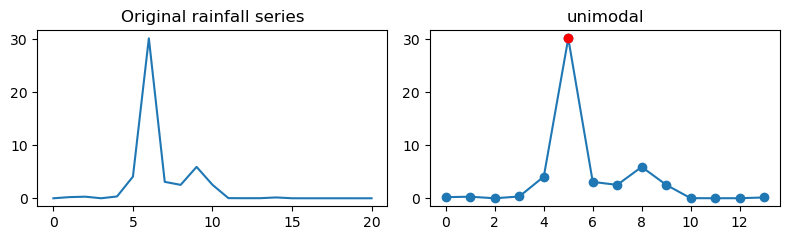

[3.3031365e-01 1.5300373e+00 5.0614605e+00 3.9396480e-01 2.0471135e-02
 4.1739084e-04 1.0918290e-04 5.1067153e-04 3.5066187e-05 1.9029623e-06
 1.9215490e-04 4.4866848e-01 5.6985654e-03 8.7161158e-07 4.0900410e-05
 4.4037253e-04 9.6757176e-06 2.1442778e+01 4.3655346e+01 9.0138807e+00
 4.7662687e+00 2.3717569e-01]
Event index: 1652, result: unimodal, n_peaks: 1


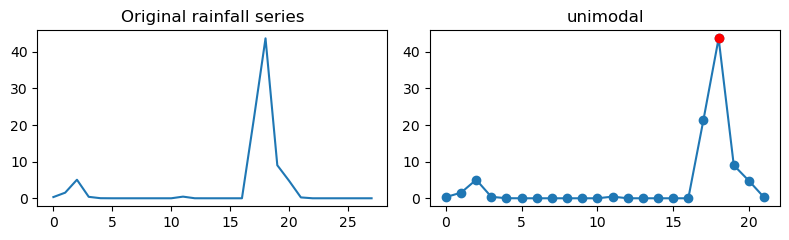

Pixel 11: 79 events
[2.4800196e+01 4.1930721e+01 1.1265305e+00 2.6852806e+00 5.8525970e-04
 5.6799784e+00 6.4975963e+00]
Event index: 12, result: unimodal, n_peaks: 1


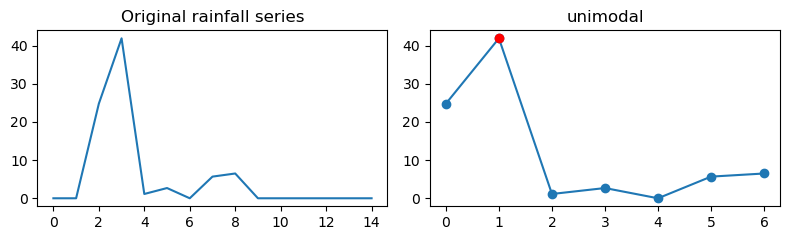

[63.274544   4.0663371]
Event index: 13, result: unimodal, n_peaks: 1


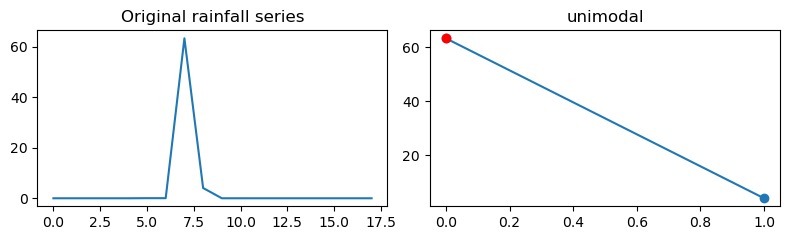

[12.23733    12.905028   47.15414    11.086541    0.31474844  1.2162081
  0.45803827]
Event index: 59, result: unimodal, n_peaks: 1


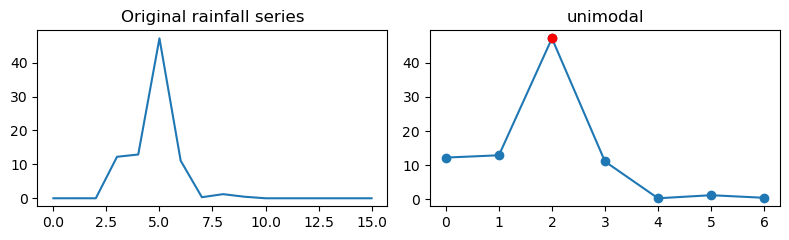

[1.7969744e-01 3.9346153e-07 6.4770666e-07 1.3381972e-03 3.9444792e-01
 2.5935415e-05 7.1612644e-01 4.0905237e-02 3.7167406e-06 1.2691624e-05
 5.2208132e-03 9.0077013e-02 3.1901953e+00 4.8894658e+00 9.0368309e+00
 7.8669338e+00 7.7879658e+00 4.3510303e+00 6.5099092e+00 1.3489734e+01
 3.5148849e+01 7.7711196e+00 3.1063101e+00 8.5398048e-02 5.6842902e-07
 1.0502849e-06 4.4819466e-03 5.4102950e-03 4.7039595e-02 7.9098505e-01
 9.8316543e-02]
Event index: 102, result: unimodal, n_peaks: 1


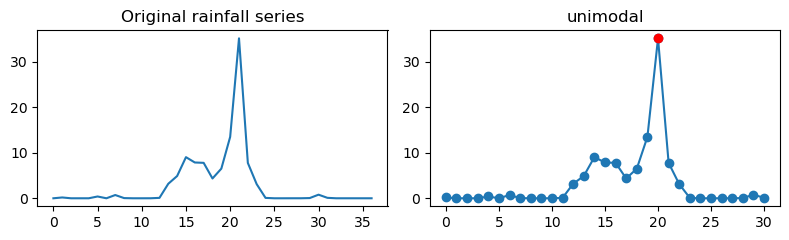

[ 0.20070669 10.679635   30.433437   18.022648    2.8760078   1.5411949
  3.5719633   3.8505476   1.9321948   1.3849459   1.9623501   2.016089
  2.603515    2.5222175   0.7320857   0.9466752   1.844333    1.6374217
  1.3981744   0.8111659   0.40751916  1.0979936   1.0175984   0.5508447
  0.74225795  0.14427565  0.12334611  0.07083109]
Event index: 157, result: unimodal, n_peaks: 1


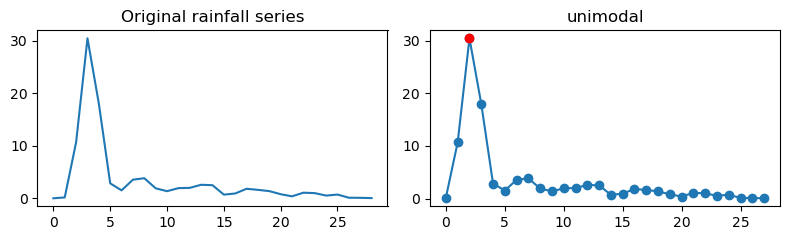

[5.0343186e-01 7.5738716e-01 6.0978319e-02 1.7982000e-02 3.6605203e-04
 1.2932629e-04 1.3770511e+00 2.4575857e-03 8.0327547e-01 1.0723327e-03
 5.7275951e-02 2.5401688e-01 7.4816972e-01 4.0019119e-01 2.3740528e+00
 1.2174358e+01 1.3571306e+00 2.2189209e-01 6.4328623e-01 3.4011188e-03
 1.7654255e-06 2.3192615e-06 5.0956804e-02 2.6994921e-02 2.5012177e-01
 9.5450830e-01 3.3730862e+01 2.3483118e+01 2.4230116e+01 1.9330450e+01
 2.8860211e+00 7.4176051e-02 1.4310840e-05 4.3091793e-05 4.6795553e-06
 1.9782555e-04 5.4472055e-02]
Event index: 180, result: bimodal, n_peaks: 2


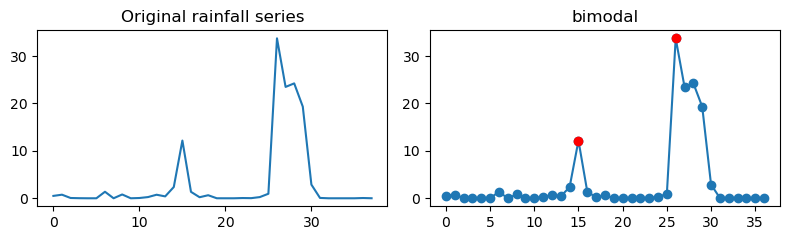

[ 6.7385402  32.998547    6.2295499   2.4200299   0.05201373]
Event index: 190, result: unimodal, n_peaks: 1


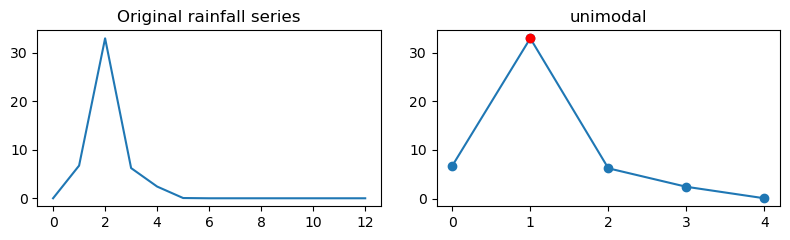

[12.818596  31.606167   5.9106803]
Event index: 211, result: unimodal, n_peaks: 1


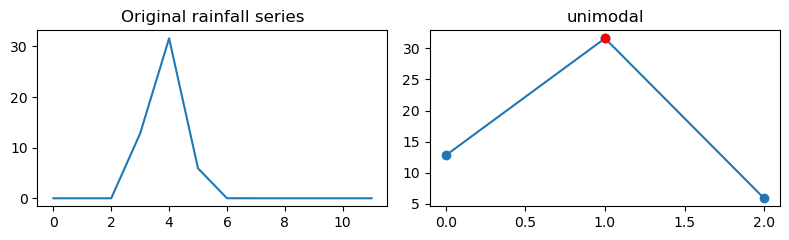

[ 0.55744916  0.77177924  6.9854655   8.4252787  16.895519   40.269302
  0.42606586]
Event index: 228, result: unimodal, n_peaks: 1


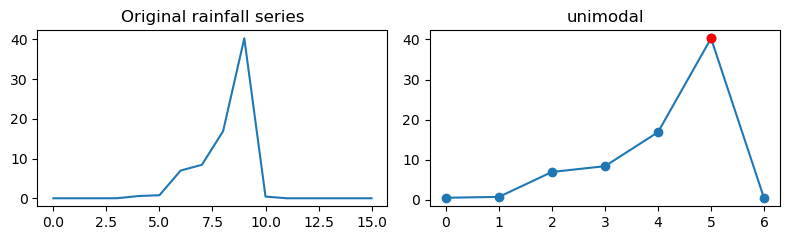

[13.049467  29.904583  48.549595  42.742611   2.3693922]
Event index: 231, result: unimodal, n_peaks: 1


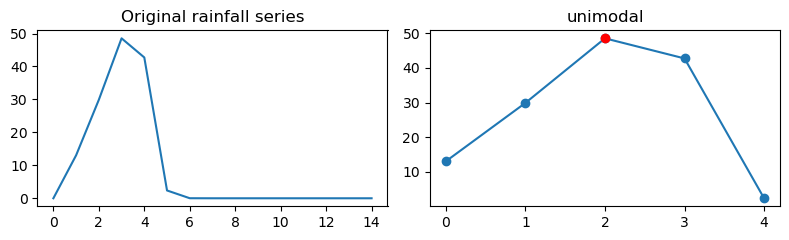

[ 0.38504452 21.18754    37.230202    2.5245016 ]
Event index: 290, result: unimodal, n_peaks: 1


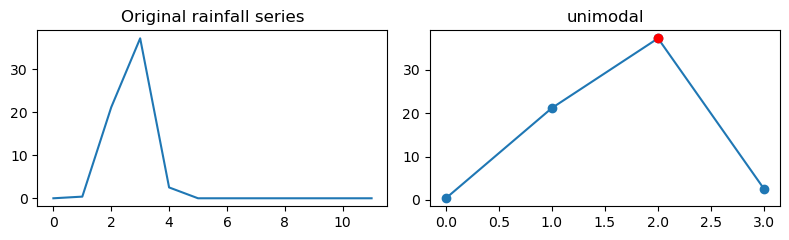

[6.4914577e-02 1.1132902e-02 3.2640455e+00 5.2317829e+00 1.4131810e+01
 3.0337177e+01 9.3718576e+00 1.7872648e+00 1.1101661e+00 1.3610530e-01]
Event index: 318, result: unimodal, n_peaks: 1


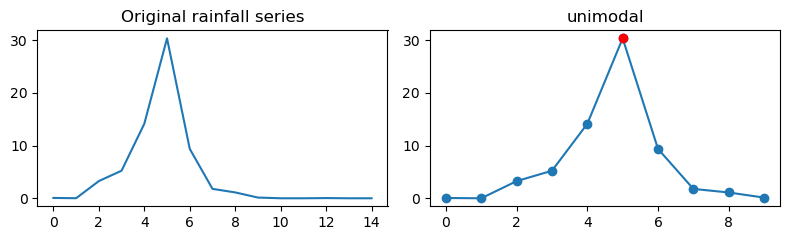

[3.0228851e+00 2.3461912e-06 4.0864020e-06 1.1856637e-06 1.5443054e-06
 8.8049507e-07 3.4545144e-01 6.9435185e-01 1.4686880e+00 4.9922153e-01
 4.8689805e-02 6.8140045e-02 2.3630934e+01 5.7395538e+01 1.2662410e+01
 2.0310742e-01]
Event index: 327, result: unimodal, n_peaks: 1


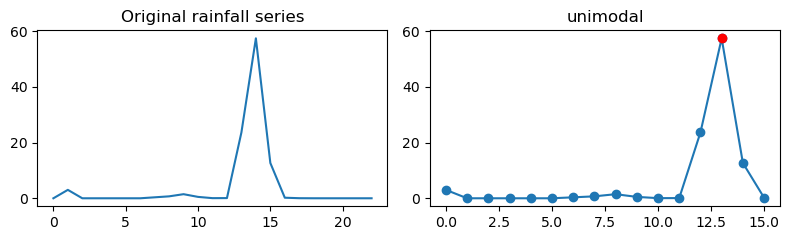

[ 0.28241065 34.280499   54.801315   10.137786    3.9423635 ]
Event index: 339, result: unimodal, n_peaks: 1


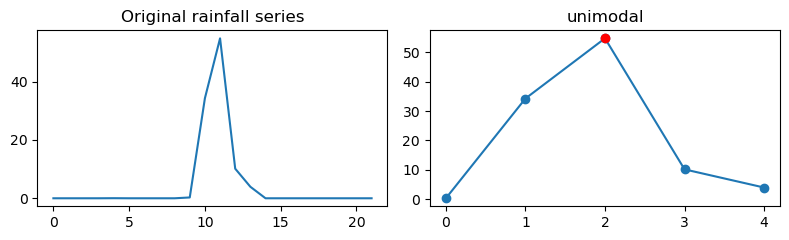

[ 0.19840287  3.189188    4.6204662   1.6402645   0.05513271  0.72200638
  8.1926022   8.0190258  40.962769   16.101196    9.8651428   6.3988981
  2.4628568   0.41971073  0.43560442  0.28177553  0.15340109]
Event index: 382, result: unimodal, n_peaks: 1


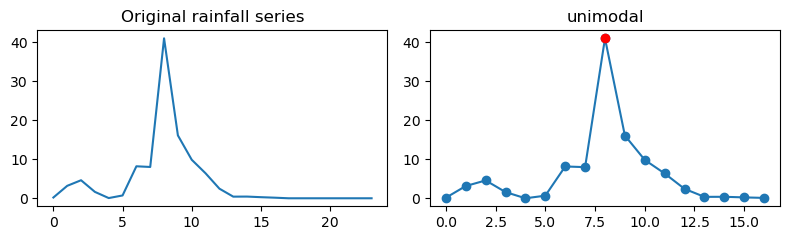

[ 1.4692876  49.488026   15.847236    0.36384404]
Event index: 390, result: unimodal, n_peaks: 1


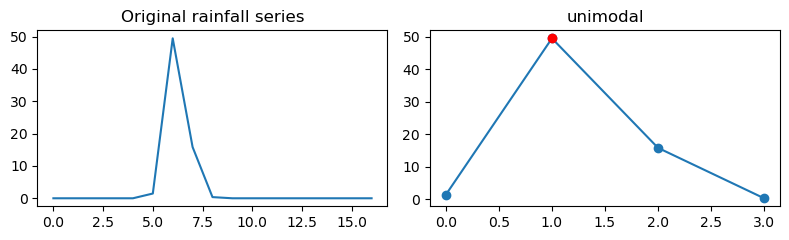

[2.1886735e+00 2.1292872e+00 1.6122793e-01 2.9673991e-05 5.6420145e-06
 2.2359373e-04 3.0346607e+01 6.7800183e+00 2.0459964e+00 6.9645410e+00
 2.8077130e+00 1.7121058e+00]
Event index: 432, result: unimodal, n_peaks: 1


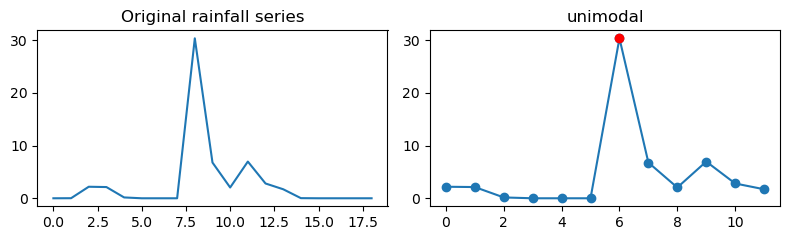

[ 1.2948529  38.214077   11.794079    0.07510461  0.07909221  0.15326765
  0.09266713]
Event index: 513, result: unimodal, n_peaks: 1


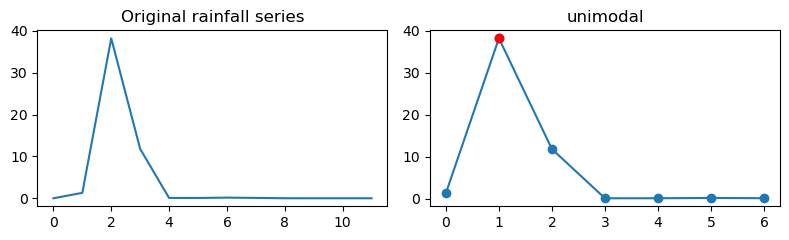

[2.3873253e-01 7.3534088e+00 1.4709097e-01 2.5591143e+01 5.8954460e+01
 8.3499870e+00 4.4097371e+00 6.5166230e+00 4.4973555e+00 2.2827728e+01
 1.5005927e+01 9.6805552e-03 5.5799483e-06 2.8664043e-02 5.2889921e-03
 1.8887476e-06 1.5732037e-06 1.5590430e-06 1.4387745e-06 1.2112594e-06
 3.2637602e-06 2.2746435e-06 3.1196969e-06 6.0003372e-06 6.5512791e-06
 7.7373447e+00 7.6607086e-02]
Event index: 537, result: bimodal, n_peaks: 2


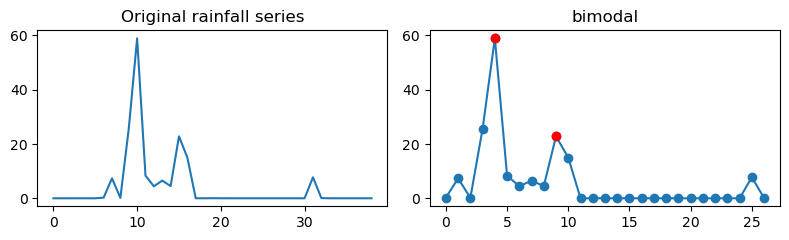

[2.8716832e-01 3.0433149e+00 1.6317213e+00 1.3892784e+00 1.4376651e-01
 8.2184088e-05 9.9350536e-01 3.0686536e-01 1.3225075e+00 4.5302976e-03
 3.1438225e-04 9.0612222e-05 1.2771525e-04 1.8761944e-03 2.0005705e+01
 5.0177032e+01 3.1875758e+00 8.7019944e-06 8.4396538e-07 3.1660629e-06
 7.0624952e-07 5.8040069e-07 6.9752218e-07 1.3197240e-01 5.7955030e-02]
Event index: 539, result: unimodal, n_peaks: 1


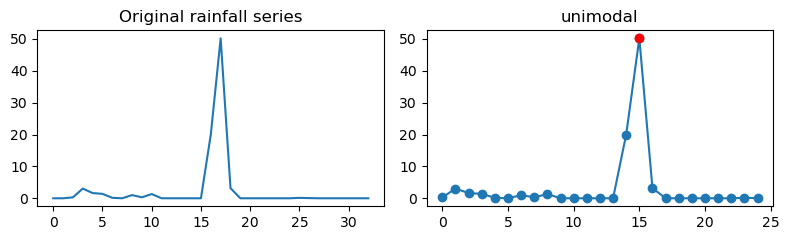

[1.0964895e+00 3.1626923e+01 4.3992286e+00 3.5434349e+00 3.4862044e+00
 4.0929979e-01 5.7333148e-07 5.0526927e-07 6.5726738e-07 9.2941671e-05
 6.2608331e-01 1.2269189e-06 2.6891387e-06 3.7744474e-06 1.6689120e-06
 1.0137654e-01]
Event index: 544, result: unimodal, n_peaks: 1


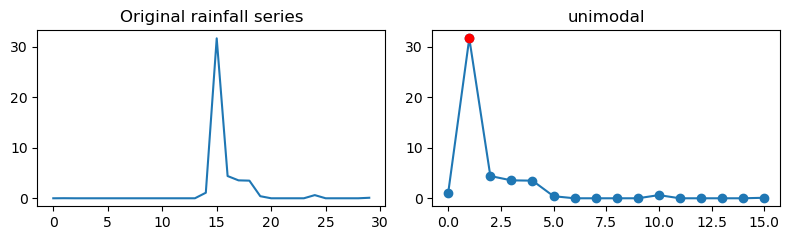

[7.4708784e-01 2.5286984e+00 1.1813961e+01 5.8233273e+01 2.9278476e+00
 1.3428507e-06 2.9969152e-07 4.4735913e+00 2.8477862e-01 1.2737496e+01
 1.8355634e-02 9.2566915e-02 5.0382274e-03 2.0656070e-07 3.0607944e-07
 7.2095986e-07 7.5621529e-07 1.1659540e-06 1.3456686e-06 2.1111582e-06
 8.8225175e-07 1.0571231e-02 1.4488806e-01 1.5463394e-06 1.1416285e+00
 1.4332881e+00 1.3823443e-06 1.5516272e-06 2.4933302e+00 8.5206432e+00
 3.4069455e+00 1.0916989e-01 1.3042950e-05 6.9530971e-02 1.2362015e+00
 1.1141878e-05 8.8316125e-01 1.5029041e-01 7.0234732e-06 3.1687507e-01
 1.2498774e-01 1.1093399e-05 9.1388114e-02]
Event index: 550, result: bimodal, n_peaks: 2


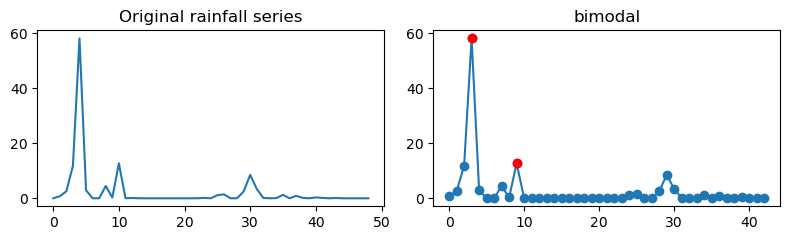

[9.3734026e-02 3.3544086e-02 7.2427042e-02 6.5475931e+00 3.5291798e+01
 6.8028188e+00]
Event index: 552, result: unimodal, n_peaks: 1


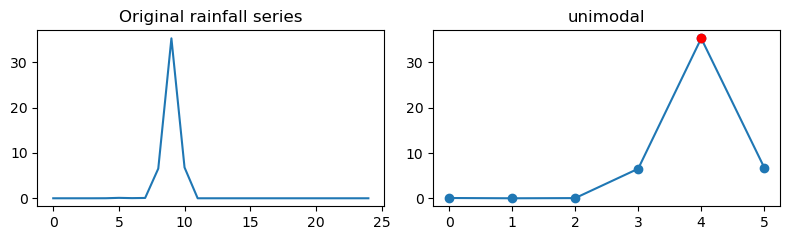

[1.2255415e+01 9.4663096e-07 2.4241695e-06 8.1197925e-07 6.9864672e-07
 2.2274174e+01 6.2764336e+01 1.0383665e+01 1.9038497e-01 5.1070134e-07
 2.9806056e+00 3.9812975e+00 4.9051750e-01 2.8768401e-03 2.6133389e-07
 6.3079403e-07 2.4017642e-01 2.6862319e+00]
Event index: 585, result: bimodal, n_peaks: 2


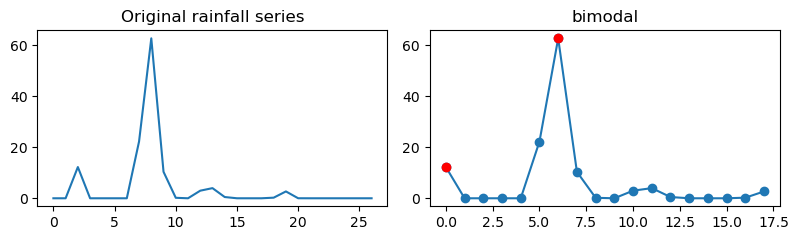

[57.070545   2.4042664]
Event index: 593, result: unimodal, n_peaks: 1


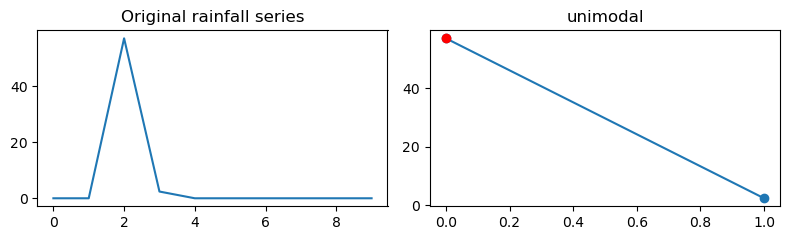

[2.1089599e-01 1.1268291e-06 1.0350346e-06 8.1894195e-01 3.5948565e+00
 1.8190236e-03 7.2347074e+00 1.8030275e+01 3.4308231e+01 1.0022279e+00]
Event index: 616, result: unimodal, n_peaks: 1


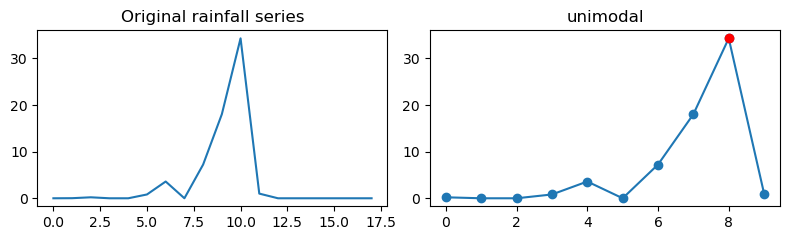

[5.9821524e-02 2.5754926e-01 8.0973962e-07 7.0449624e-07 1.0474736e-06
 2.3265480e-01 2.3001166e-06 8.4988886e-07 3.3037242e-07 3.3527635e-07
 4.9404053e-07 3.4822827e-07 4.2468588e-07 1.0067981e+00 3.6081985e+01
 1.0547770e+00]
Event index: 633, result: unimodal, n_peaks: 1


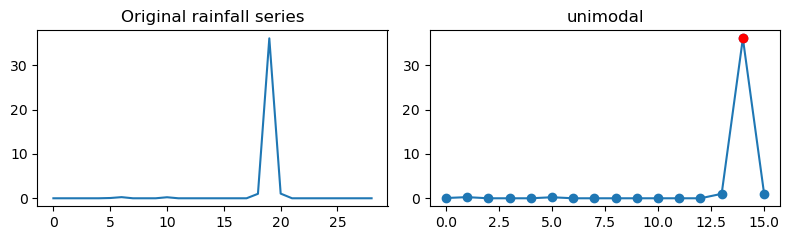

[2.0344605e+00 3.0453306e+01 6.8040886e+00 3.3983951e+00 1.0811105e+00
 1.8246764e-06 2.9848240e-02 6.4068689e-04 2.2250763e-06 2.3003381e-04
 1.6362219e-03 1.2513228e-02 3.4892477e-02 7.7238008e-02 7.5651899e-02
 2.5908238e-01 3.6886972e-01 1.9910868e-01]
Event index: 658, result: unimodal, n_peaks: 1


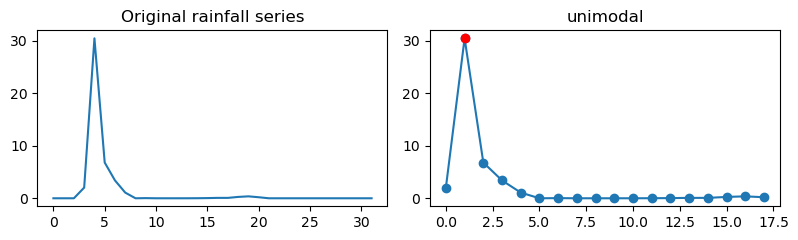

[7.4532766e+00 3.2456593e+01 5.6750064e+00 2.5978625e+00 1.9511518e+00
 3.7665808e-01 5.3789448e-03 3.1691513e+00 1.1939884e+00]
Event index: 669, result: unimodal, n_peaks: 1


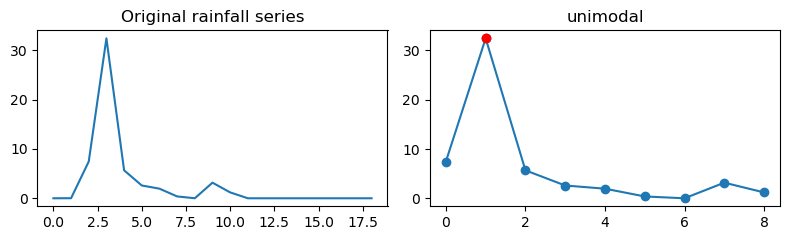

[10.314171 47.066589 11.917005]
Event index: 697, result: unimodal, n_peaks: 1


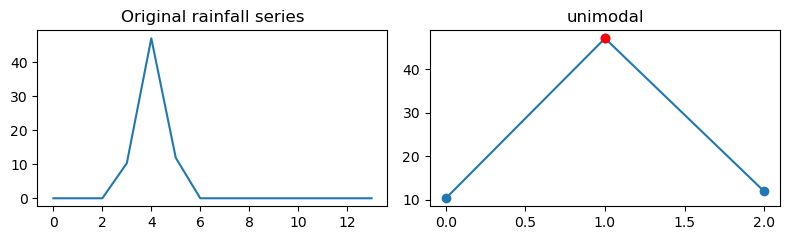

[3.6131107e+01 2.1229229e+01 3.7754259e+00 2.4700065e+00 6.8947816e-01
 5.0702721e-02 2.8178024e-03 8.3473208e-07 4.6705101e-03 1.9378213e-02
 6.1228476e-02 2.5203157e-02 3.0523654e-02 1.7140615e-01]
Event index: 730, result: unimodal, n_peaks: 1


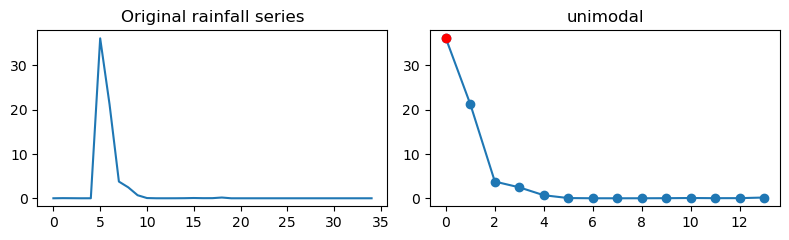

[5.9452767e+00 7.0431224e-07 1.1259363e-06 1.4405128e-05 3.7550528e-06
 1.8042829e-06 1.0362414e-06 1.3583099e-06 2.5712358e-02 1.2236343e+01
 1.1511083e+00 2.7736750e+00 6.9260506e+01 1.7387629e+00 1.5277267e+00
 2.2540649e-03 4.0177426e-01 9.5076191e-01]
Event index: 770, result: bimodal, n_peaks: 2


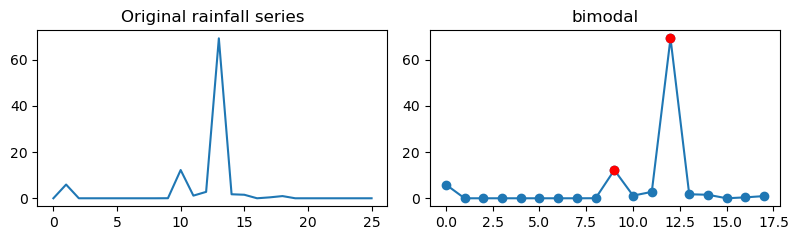

[ 3.9205697  16.497957   11.442755    5.8025589   9.8217592  36.359844
 21.581011    0.07603747]
Event index: 830, result: bimodal, n_peaks: 2


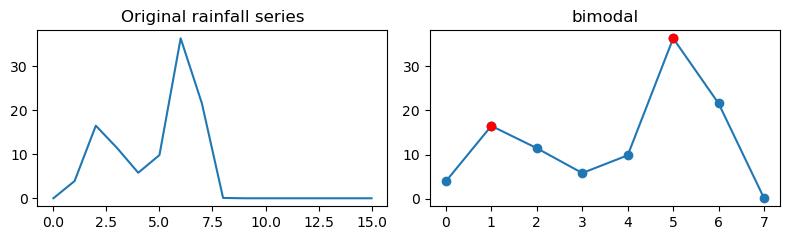

[1.3919123e-01 1.8689876e-06 2.0246198e-06 4.3110420e-05 1.8236440e+00
 4.1142052e+01 1.6401656e+00]
Event index: 838, result: unimodal, n_peaks: 1


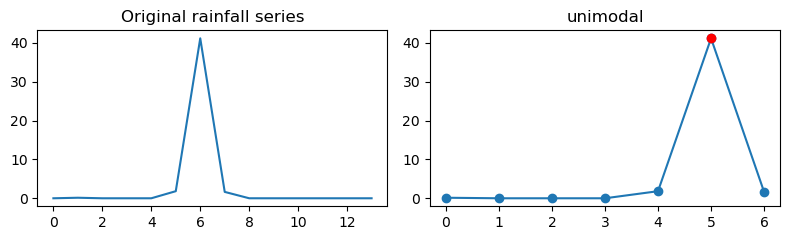

[ 0.47321084 31.659708   27.936745    3.2134364   2.0285971   0.3388359 ]
Event index: 857, result: unimodal, n_peaks: 1


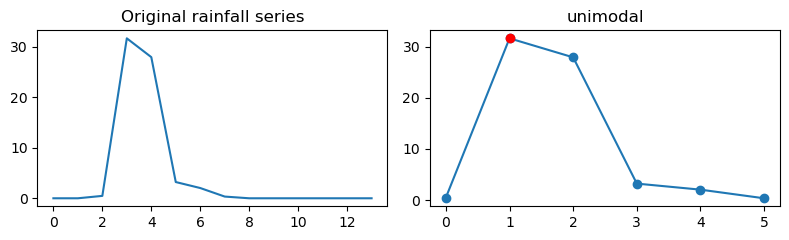

[ 0.40496275  0.34602225  5.4733462  17.95998    13.259408    0.18685099
 45.436954    0.73563927]
Event index: 865, result: bimodal, n_peaks: 2


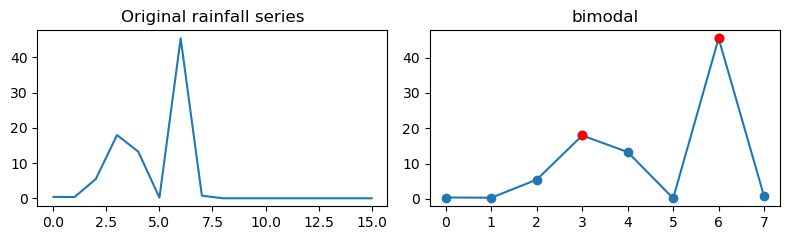

[ 5.9575148 15.354306  34.528248   7.692409   1.0291585]
Event index: 883, result: unimodal, n_peaks: 1


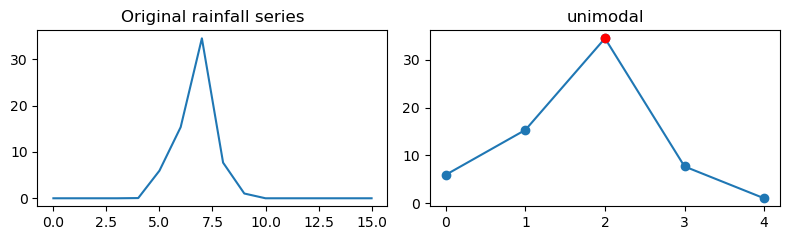

[ 0.1854665   1.6606383  32.475655   23.926931    0.25430709]
Event index: 911, result: unimodal, n_peaks: 1


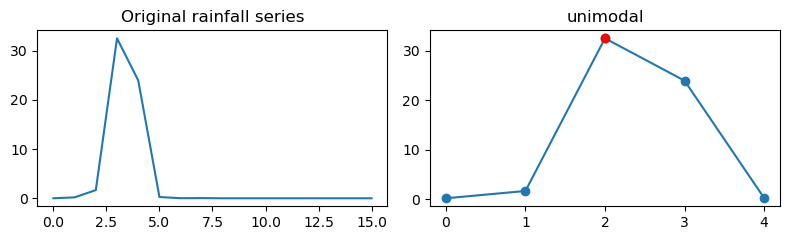

[ 0.17763428  2.5830894  49.660484   12.174661    0.1972218 ]
Event index: 936, result: unimodal, n_peaks: 1


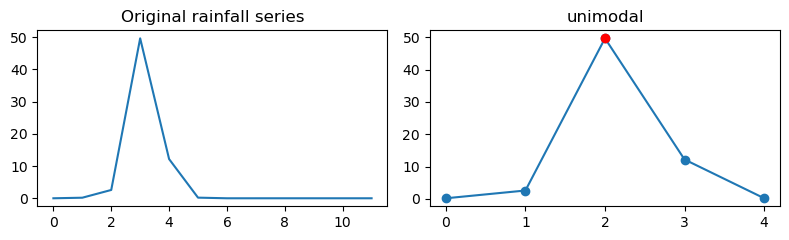

[31.2728939   0.17901078]
Event index: 998, result: unimodal, n_peaks: 1


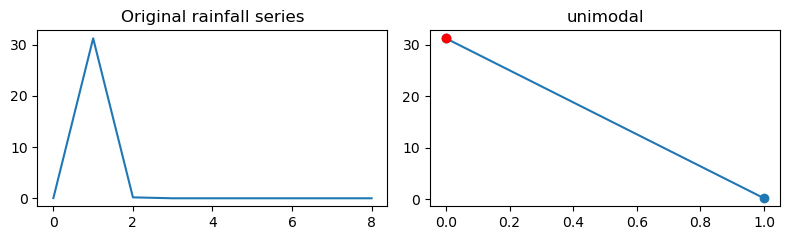

[ 0.32672983 18.448511   30.569078    7.2242889 ]
Event index: 1070, result: unimodal, n_peaks: 1


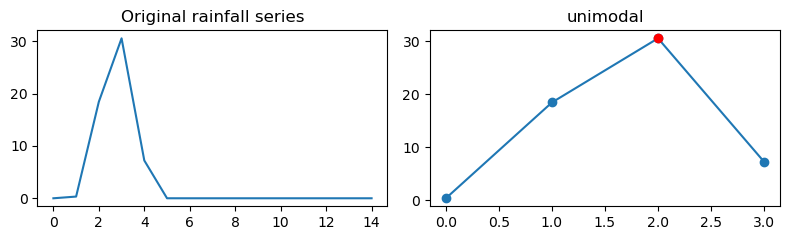

[ 0.38308537  0.24103047  1.81690586  1.82178891  3.98691249 37.4105988
 34.3380699   1.84968936  0.14878114  0.08652096  0.11028767]
Event index: 1072, result: unimodal, n_peaks: 1


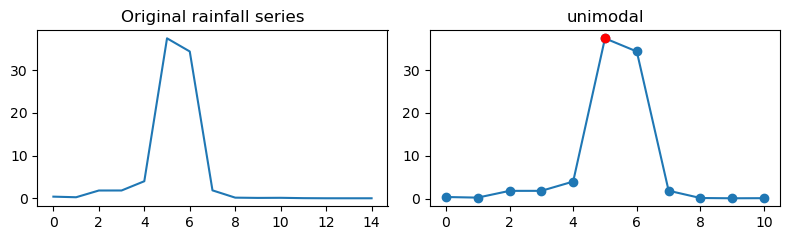

[6.8266934e-01 8.9881513e-03 7.4083731e-04 3.6707267e-02 1.7571021e+00
 3.2935024e+01 5.1213298e+00 3.0213955e-06 9.7233035e-02]
Event index: 1089, result: unimodal, n_peaks: 1


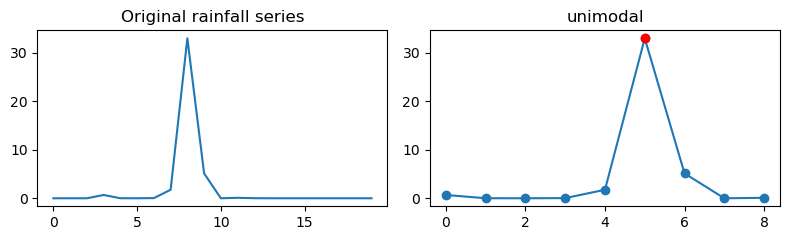

[ 1.9321208  33.110073    0.41433734]
Event index: 1103, result: unimodal, n_peaks: 1


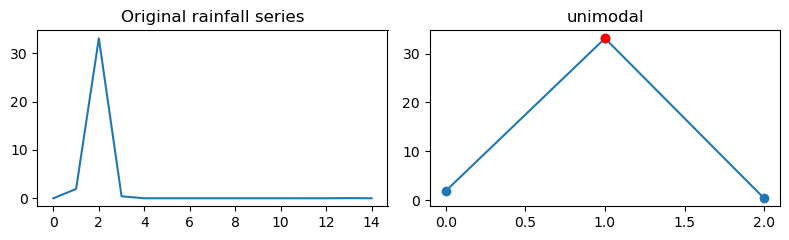

[2.9268894e+00 5.3926743e+01 1.9425543e+01 4.3372297e+00 1.1736270e+00
 5.0131463e-02 5.3027770e-06 1.9273646e-06 9.0949931e-07 1.6831913e-06
 2.8280338e-06 5.0933435e-05 6.8093796e-05 5.8507616e-05 8.6671162e-01
 9.4404393e-05 7.5790122e-05 6.7766836e-05 6.2893989e-05 2.3245584e-05
 1.4984151e-05 5.3723172e-05 7.2923867e-05 1.6185114e+00]
Event index: 1115, result: unimodal, n_peaks: 1


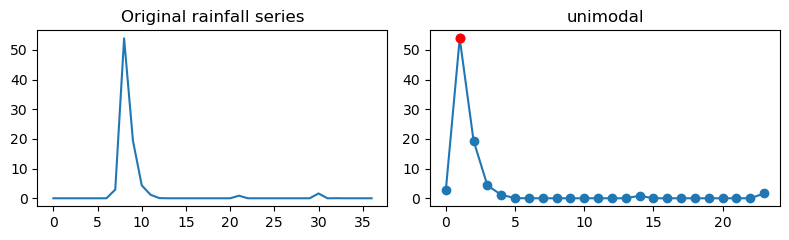

[ 0.33331463  0.13588171 25.554211   50.212276    0.31905133]
Event index: 1118, result: unimodal, n_peaks: 1


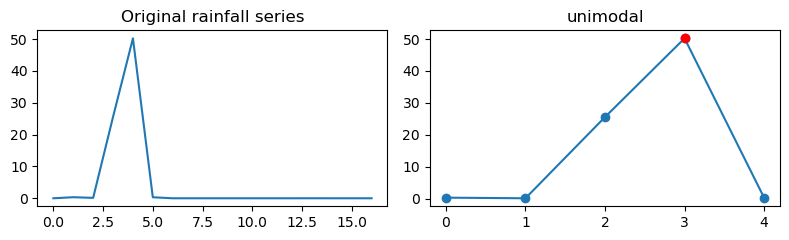

[ 0.33841431  5.38754368  5.26570177 31.8164368  34.7423668 ]
Event index: 1134, result: unimodal, n_peaks: 1


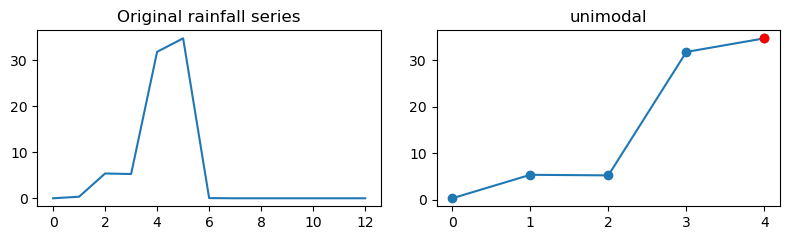

[1.25499284e+00 1.13150716e+00 1.62329227e-01 1.69825897e-01
 3.78700614e-01 1.92460942e+00 2.60355520e+00 1.00115694e-01
 9.01579380e-01 8.62126797e-02 5.60687147e-02 9.31747332e-02
 5.38088799e-01 7.74994612e-01 3.42771178e-03 3.96154137e-05
 7.39157945e-02 4.21823263e+00 3.07357044e+01 5.90626240e+00
 5.09560248e-03 3.24923843e-02 6.68221533e-01 2.67013279e-03
 7.34484092e-06 6.90203535e-07 1.96368819e-06 3.29100840e-05
 4.76075697e+00 3.60209012e+00 3.80171204e+00 6.52948255e-03
 1.89456172e-04 7.35792564e-03 1.02688009e-05 6.70761522e-03
 6.73069358e-02 2.51102948e+00 1.95212972e+00 1.64389040e-03
 2.88190693e-01 1.90641034e+00 4.60626632e-01]
Event index: 1136, result: unimodal, n_peaks: 1


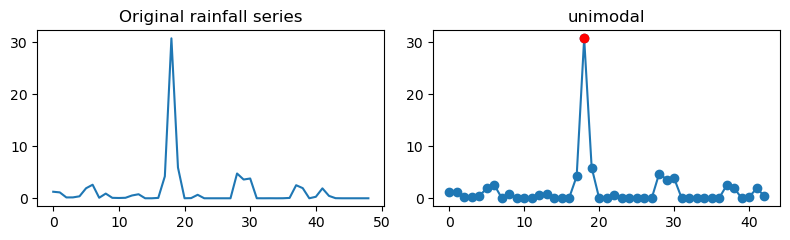

[ 0.19807322 51.770641  ]
Event index: 1159, result: unimodal, n_peaks: 1


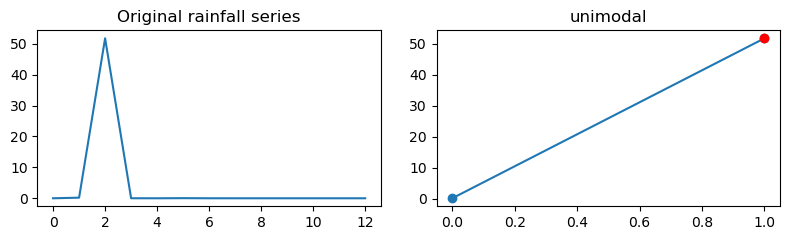

[31.143866   3.2934186]
Event index: 1169, result: unimodal, n_peaks: 1


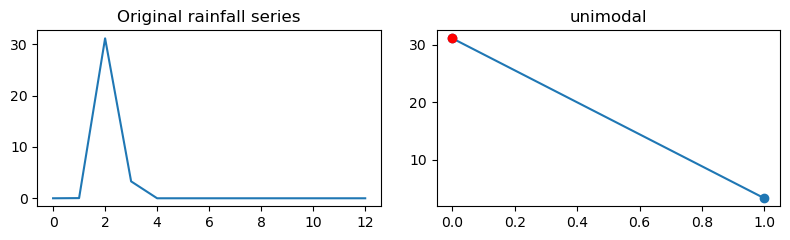

[35.42664   43.812214   2.0329299]
Event index: 1171, result: unimodal, n_peaks: 1


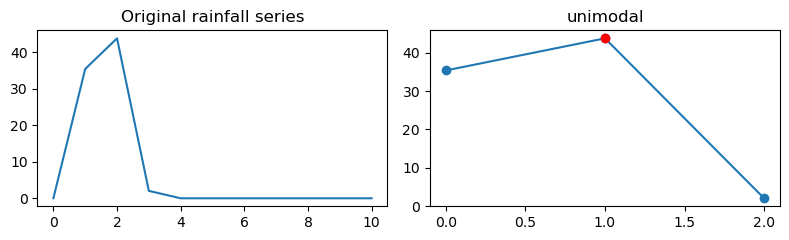

[ 0.2850621  0.2491587 58.916168  26.075253   5.3678665 21.12587
  8.9548502]
Event index: 1211, result: bimodal, n_peaks: 2


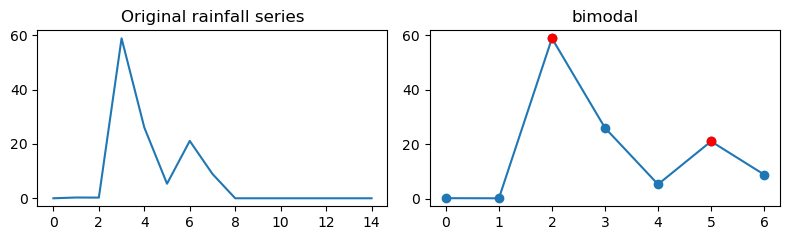

[3.0022552e+01 1.8022139e+01 2.5691347e+00 4.4874843e-02 5.3852159e-01
 2.5218005e-06 1.4441945e-06 1.1114249e-06 3.9249958e-06 9.4420407e-03
 6.0217375e-01 3.6960977e-01 4.0457168e-01 2.7930075e-06 1.7223958e-06
 2.4369388e-06 1.1140977e-03 1.8679388e-01 6.0926837e-01]
Event index: 1214, result: unimodal, n_peaks: 1


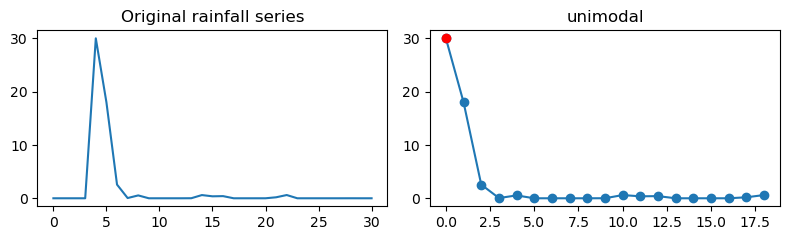

[5.9751835e-02 1.3989899e-06 1.6682800e-06 2.9226742e+00 2.7865603e+00
 4.9642515e+00 3.1204218e+01 1.2151387e+01]
Event index: 1220, result: unimodal, n_peaks: 1


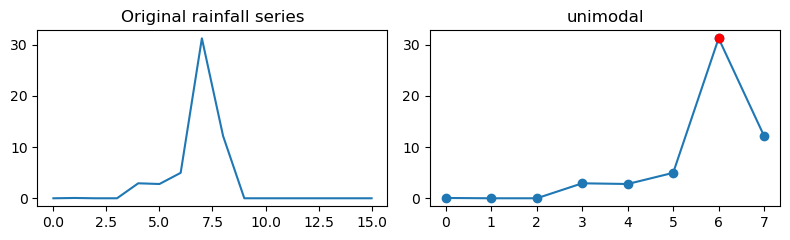

[ 0.09515989  0.13299768  0.0496042   1.3281914  32.420853   17.108849
  4.1541033   1.2016767   1.7473999   1.6480123   1.987185    2.6019878
  0.29156771  0.05495951]
Event index: 1278, result: unimodal, n_peaks: 1


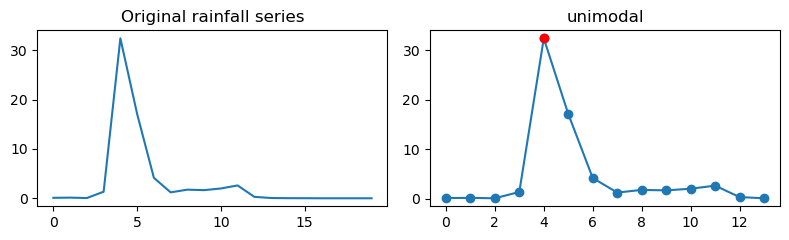

[21.5917721 36.2601128]
Event index: 1283, result: unimodal, n_peaks: 1


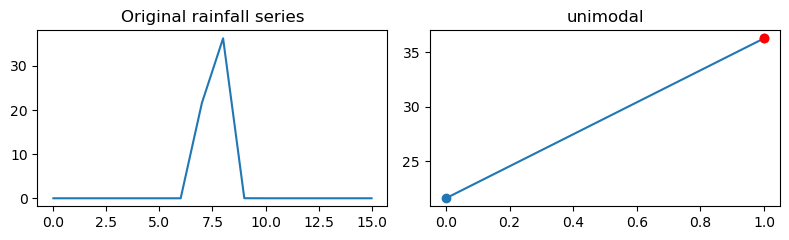

[ 3.7975492  18.075941   31.318361    4.5093732   0.11588471]
Event index: 1302, result: unimodal, n_peaks: 1


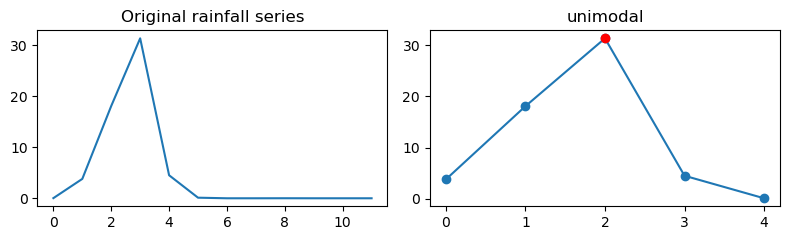

[3.7278588e+00 9.3015775e-02 6.1225529e-07 1.9361864e-06 5.1411139e-06
 2.0098379e-02 3.8284104e+00 1.7509649e+00 1.9745587e-01 6.1466668e-02
 1.4152762e-02 6.2182193e+00 1.3524763e+01 1.0699689e-01 3.2191175e-01
 2.0734954e-01 1.0623272e-01 5.1658690e-01 7.2491598e+00 3.3945614e+01
 6.7007813e+00]
Event index: 1327, result: bimodal, n_peaks: 2


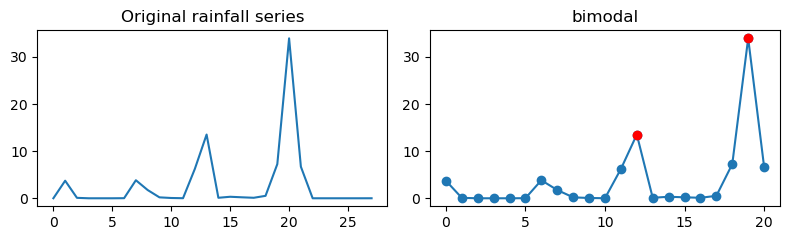

[6.5382290e-01 5.6955829e-05 2.4997027e-01 8.7242639e-01 2.0947211e-06
 3.9538281e-06 5.7028742e-06 5.5776730e+00 3.1307085e+01 1.6884892e+00
 4.1828060e+00 2.0804679e-01]
Event index: 1358, result: unimodal, n_peaks: 1


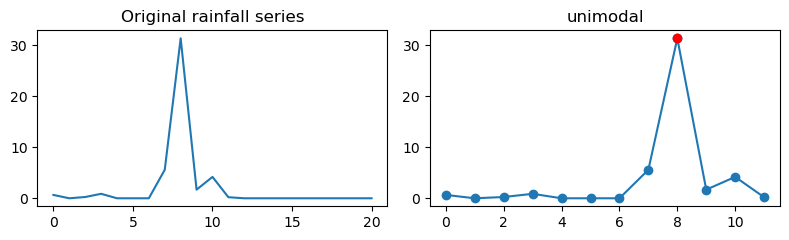

[1.2309994e+00 1.4354013e-03 2.9623213e-06 4.1750937e+00 2.2429304e-02
 7.2422131e-06 2.0909536e+00 4.8321304e+01 3.2533493e+01 1.7656878e+01
 4.6163611e-02 1.5505159e-06 1.1951519e+00]
Event index: 1372, result: unimodal, n_peaks: 1


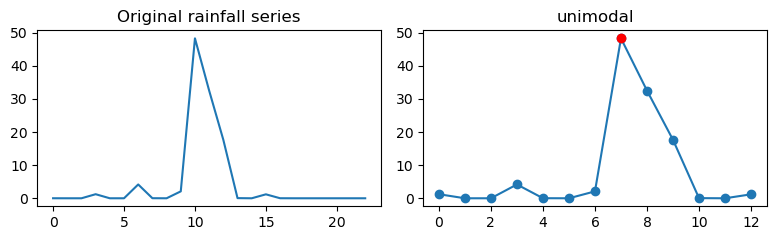

[6.1532226e+00 1.3512350e+01 1.3354344e-05 6.2668216e-05 6.7253841e-06
 7.2663902e-06 1.1667479e+00 1.5858039e+01 8.4151344e+00 9.1393568e-02
 2.1670366e+01 4.9360767e+01 1.7937665e+00 1.6077685e-03 1.2430014e-06
 1.0594722e-06 1.5517464e-06 5.6947876e-02 1.3264950e-06 1.9966055e-06
 7.1702324e-02]
Event index: 1386, result: multimodal, n_peaks: 3


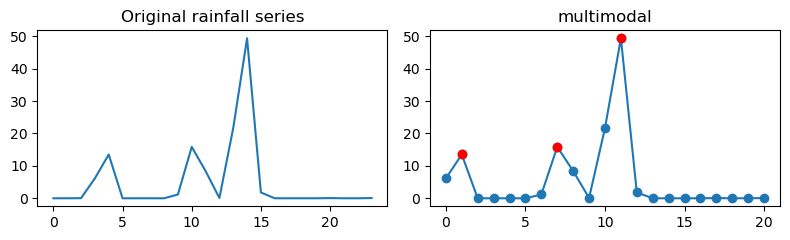

[4.8294010e+00 3.7781417e-02 9.4691716e-02 4.1539305e-01 3.1383353e-01
 1.4521505e-01 8.3132392e-01 2.1646402e+00 3.5003257e+00 1.6050813e-03
 1.7875383e-02 7.1489334e+00 2.9774830e+01 5.7629967e+00 4.7955429e+01
 5.7587647e-01 3.0128115e+01 1.0911250e+00]
Event index: 1390, result: unimodal, n_peaks: 1


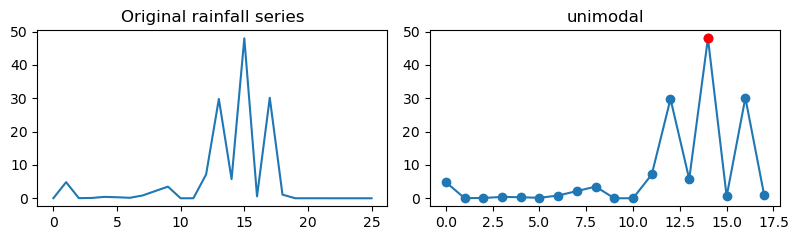

[3.9752848e+00 7.3894012e+01 3.7067390e+01 6.4790577e-02]
Event index: 1398, result: unimodal, n_peaks: 1


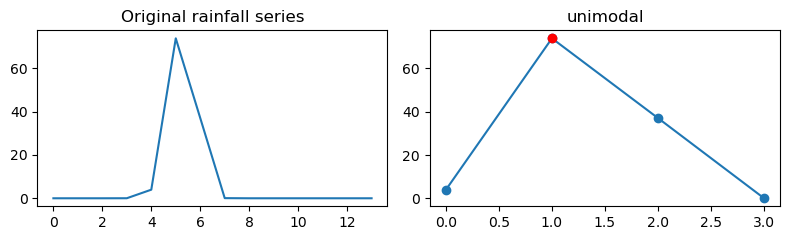

[ 0.31309563  0.2212413   0.14934914 31.5834045   0.7943179   0.11049204]
Event index: 1399, result: unimodal, n_peaks: 1


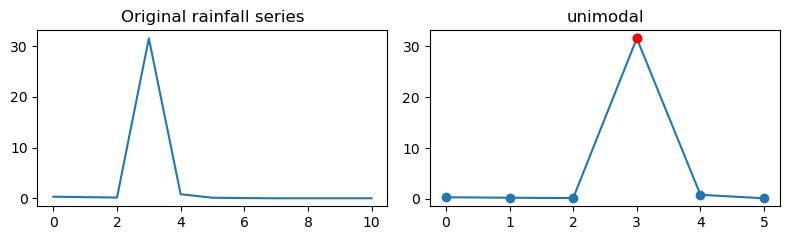

[ 1.5750977  6.6525564  5.4756327 31.856485 ]
Event index: 1409, result: unimodal, n_peaks: 1


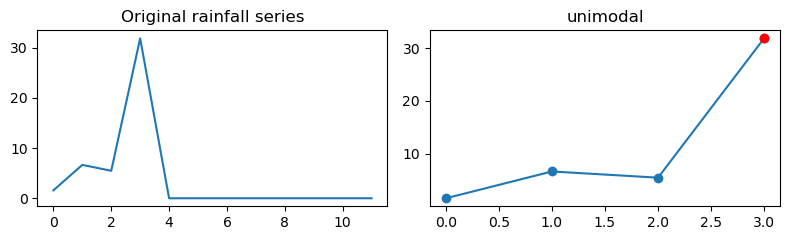

[2.1910613e+00 2.0829644e+00 1.8731586e+00 4.2718919e-03 8.5973637e-03
 1.9692001e-03 4.8744655e-04 2.1506484e-04 1.8155864e-02 4.8619468e-04
 3.9684310e-06 3.7179611e-06 8.8250693e-03 5.6678444e-02 1.1514840e-05
 6.9444809e+00 4.3580196e+01 8.8043575e+00 5.6818333e+00 4.7323730e-02
 1.2271687e+00 1.7268614e+00]
Event index: 1410, result: unimodal, n_peaks: 1


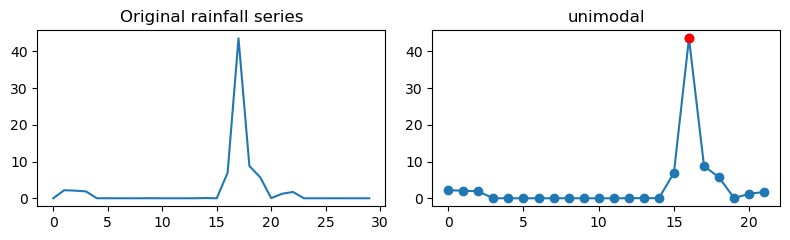

[ 0.9688049 40.396599  18.295126   1.4438106]
Event index: 1425, result: unimodal, n_peaks: 1


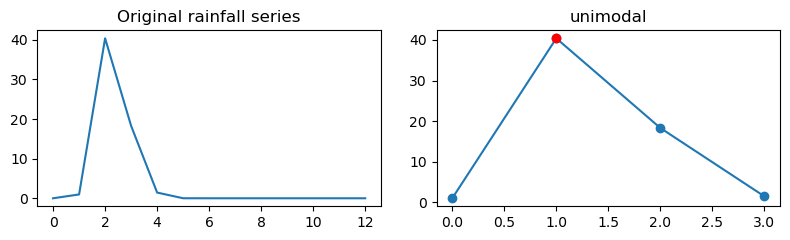

[5.7875304e+00 3.3469961e+00 1.2113969e-03 6.0918197e-02 1.1671938e-03
 9.2264009e-04 1.8335832e-03 2.1080207e-03 3.8463593e-01 5.4715652e-02
 5.4940760e-02 1.4585985e+00 6.1279898e+00 6.4632893e-01 1.2910484e-01
 4.0456629e+00 5.3483267e+00 1.2926078e+01 9.3368311e+00 1.2480941e+00
 1.3279301e-01 1.3284262e-02 7.6344691e-02 5.1885410e-03 3.1905534e-04
 2.0577740e-04 2.0265653e-04 8.9180321e-05 1.2128610e-04 1.3408418e-04
 9.3325548e-04 5.9234439e-03 3.7323865e-03 2.1416091e-03 5.6031893e-04
 2.4402034e-06 2.1973741e-03 1.2328060e-03 1.0479260e-06 1.4595253e-06
 4.6971496e-07 9.9565525e+00 2.8080299e+00 2.5145148e-04 7.2497255e-07
 1.3713204e-02 2.4510976e-03 2.5415827e-06 2.0248550e-05 4.1682462e-05
 2.4382591e-04 1.4131924e-04 1.9288645e-05 3.7584364e-04 3.1669869e-04
 1.6613353e-04 1.3449213e-05 4.4846188e-06 2.9452949e-06 4.5244335e-04
 2.4114413e+00 5.9245389e-02 9.5626488e-03 1.8226700e-02 4.6432815e-06
 1.3104535e-05 1.6139753e-02 2.1201926e-01 7.3209888e-01 5.5673547e+00
 5.061

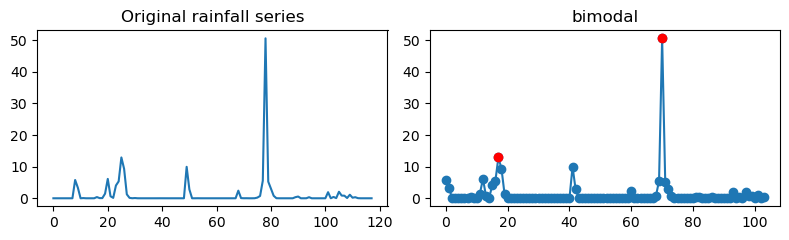

[ 2.8378224  39.714531    0.16967662]
Event index: 1447, result: unimodal, n_peaks: 1


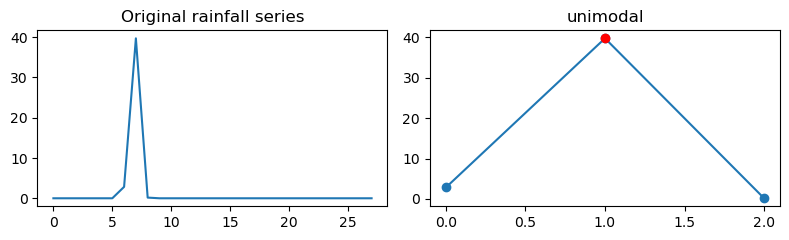

[1.3940563e+00 1.2853390e+00 1.8433086e-06 1.2472547e-06 6.9965409e-07
 3.1905296e-01 4.9027195e+01 7.1646599e+01 3.8429687e+00]
Event index: 1454, result: unimodal, n_peaks: 1


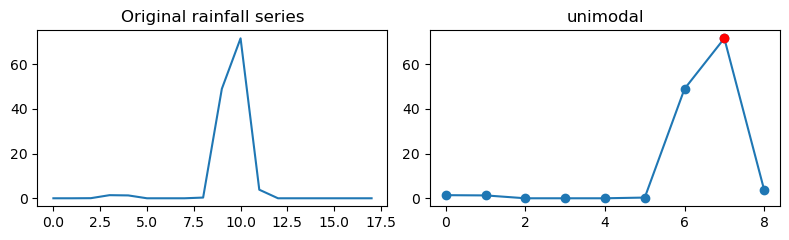

[ 1.7492921  9.0972881 31.832928  14.45748  ]
Event index: 1481, result: unimodal, n_peaks: 1


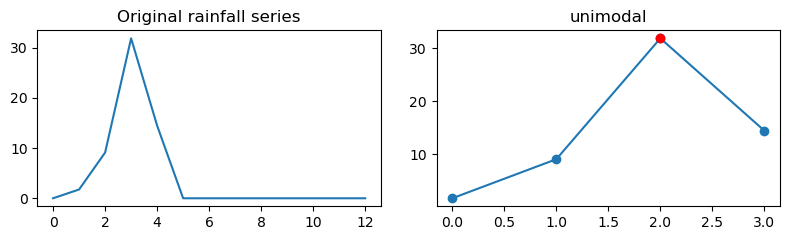

[5.3375304e-01 3.7512489e+01 1.4035904e+01 1.3143074e-06 2.3530146e-01
 3.6273795e-01]
Event index: 1488, result: unimodal, n_peaks: 1


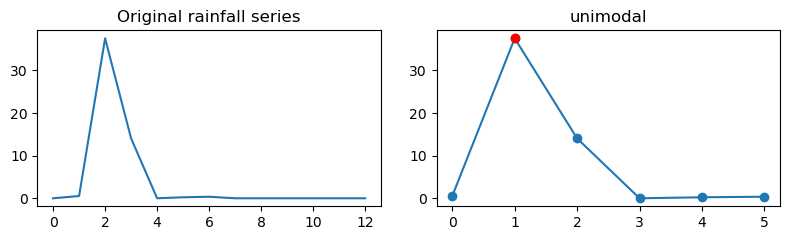

[1.2261217e+00 1.0162661e+01 6.3763771e+00 3.7386623e+01 2.3181565e+00
 9.5897155e-07 2.4570322e+00 1.5983817e-01 4.8047800e+00 1.2974949e-06
 1.1311840e-06 2.9537354e+00 4.8042255e-04 6.0347219e+00 3.2779729e+00
 4.0641623e+00 1.4695645e-06 1.1991065e-06 1.3813768e-06 4.4376740e+00
 2.4862676e+00]
Event index: 1499, result: unimodal, n_peaks: 1


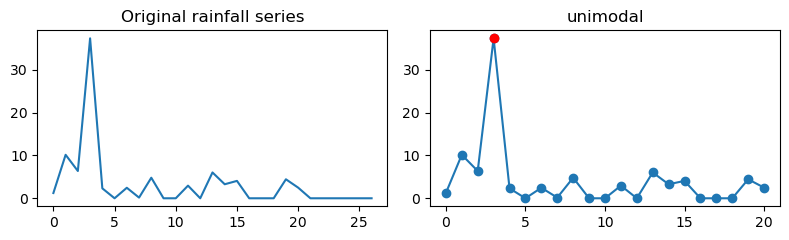

[19.898357  45.128876   0.0578957]
Event index: 1501, result: unimodal, n_peaks: 1


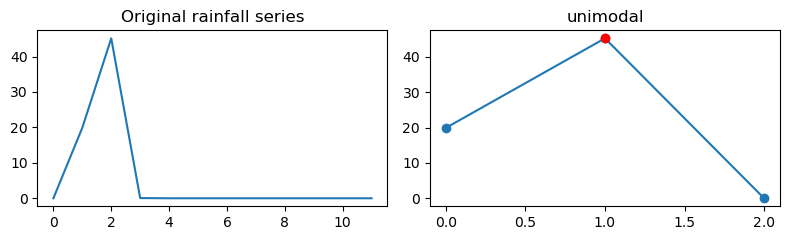

[ 0.44338304 26.3040276  33.53862     0.2283448 ]
Event index: 1525, result: unimodal, n_peaks: 1


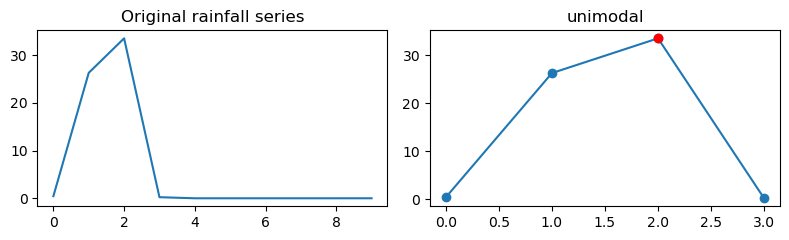

[ 5.02937174 17.0831127  11.0289955  33.2650948   0.16614245]
Event index: 1527, result: unimodal, n_peaks: 1


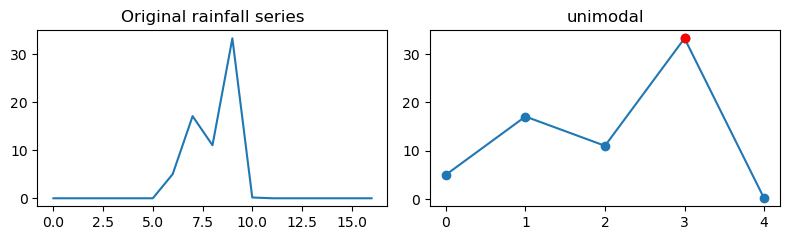

[ 0.55807054 17.716465   38.438881    5.2160759 ]
Event index: 1594, result: unimodal, n_peaks: 1


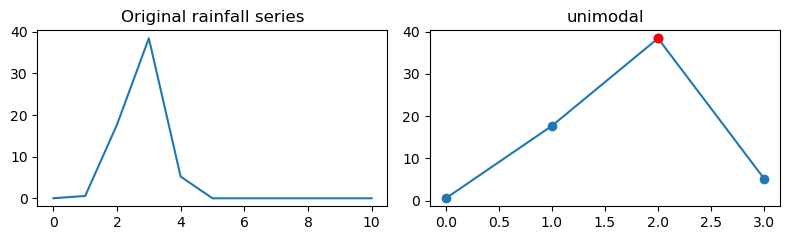

[1.2119719e+01 2.3424993e-01 2.7405987e-02 1.1905493e+00 3.1305044e+01
 1.9894272e+01 2.4514132e+00 3.7900266e-01]
Event index: 1624, result: bimodal, n_peaks: 2


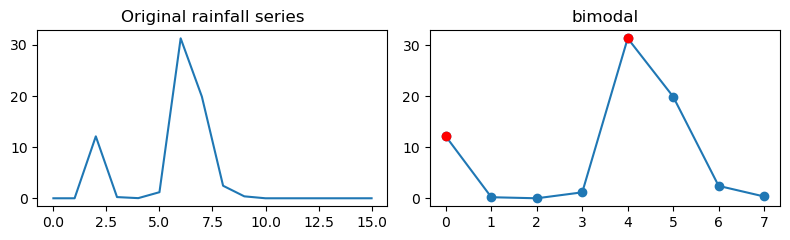

[ 3.08181977 38.3362999  14.2303295 ]
Event index: 1651, result: unimodal, n_peaks: 1


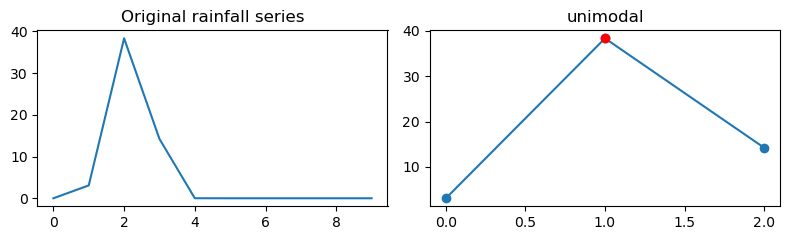

Pixel 485: 135 events
[ 6.8446822 31.49597    1.1909544]
Event index: 7034, result: unimodal, n_peaks: 1


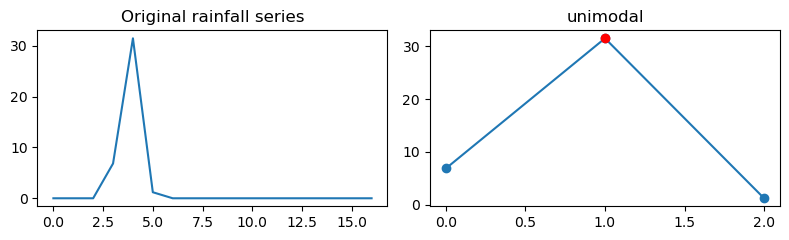

[3.5815585e-01 1.8616946e+00 1.1528513e+00 7.0583583e-03 3.1209221e+01
 1.9459087e+01 3.2541195e-01 4.0484401e-03 1.9515496e-02 2.0590169e-02
 3.3400778e-02 5.3210631e-02]
Event index: 7035, result: unimodal, n_peaks: 1


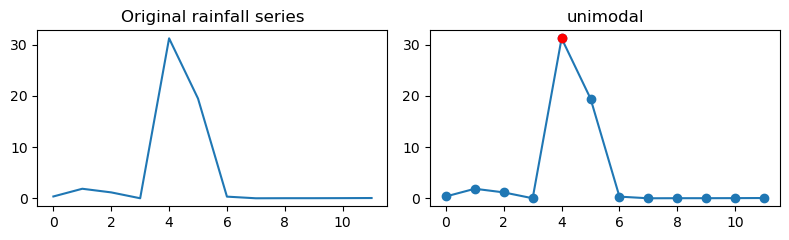

[ 0.31965953  0.89662373  9.184209   30.422941    9.871132    0.10511229
  3.9134803   4.8531947   0.5027101   2.8256874   1.4074864   0.58614093
  1.3171791   0.03059098  0.8443496 ]
Event index: 7104, result: unimodal, n_peaks: 1


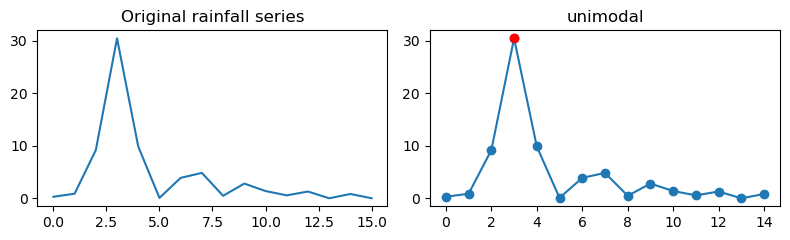

[1.0986849e+00 1.7025779e+00 1.0827805e-01 1.0237619e+01 1.6207396e+00
 2.2530386e+01 4.1321663e+01 1.5734335e+00 1.6429675e-03 1.7007805e+00
 1.6453165e+01 7.3163295e-01 5.9936619e+00 2.0296332e-01 2.6045020e-03
 6.7124151e-05 4.8038852e-03 6.6061953e-06 4.2046416e-01 5.3075762e+00
 2.0024276e+00 2.3445604e+00 3.4673873e-01 2.9511136e-01 1.7139039e+00
 2.8433639e-01 3.0139369e-01 3.1131761e+00 1.5913826e+00 1.7593324e-01
 3.6076598e-02 8.9636721e-02 3.5092422e-01 5.5936152e-01]
Event index: 7113, result: multimodal, n_peaks: 3


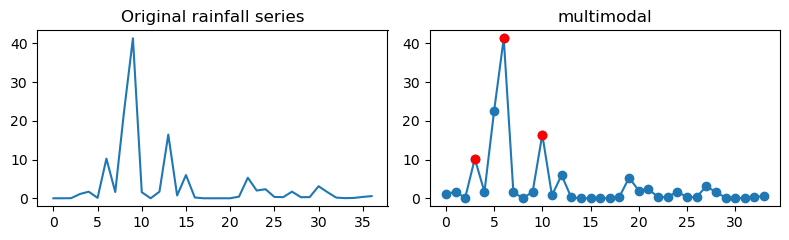

[3.1231973e-01 6.0451740e-01 7.0167340e-02 2.5634475e+00 5.0277645e-06
 4.6746295e-06 1.2699358e-06 1.4919572e+00 1.2879412e+00 1.5576418e-01
 1.4835925e+00 3.0818229e+00 3.5864033e+01 2.4799389e+01 3.3209217e+00
 1.4284936e+00 1.6748290e+00 2.6716149e-01]
Event index: 7116, result: unimodal, n_peaks: 1


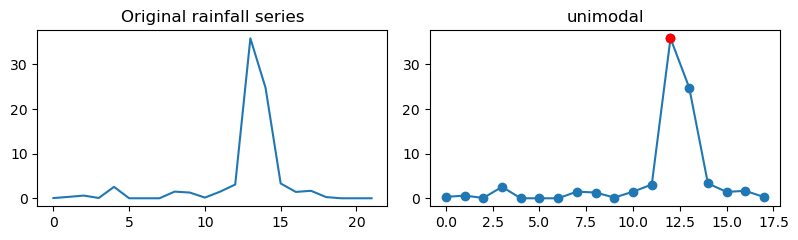

[6.4260393e-02 3.9349851e-01 2.7702131e+00 3.3361936e+00 4.5384769e+00
 1.7466027e-01 1.7754122e+00 2.6997253e-01 3.1448498e-03 6.9910444e-02
 5.7682312e-01 5.3287003e-02 6.2329537e-01 1.2686105e-01 1.7727492e+00
 1.1813084e+00 3.0242881e-01 3.2526741e+00 3.1828370e+00 4.0367336e+00
 2.4523678e+00 3.8604374e+00 3.4412642e+00 3.6532853e+00 2.8628235e+00
 4.7960095e+00 4.1922336e+00 3.8886969e+00 6.8020859e+00 5.7266879e+00
 7.5395880e+00 1.3803905e+00 4.9971830e-02 2.0738664e+00 7.5515885e+00
 3.8972304e+00 1.3813603e-02 3.3481319e+00 6.2783022e+00 5.9619677e-01
 5.6355924e-04 3.9461547e-01 9.4928312e-01 1.0211572e+01 1.1894748e+00
 7.7569097e-01 4.9468966e+00 5.8358369e+00 1.9986082e+00 2.2377717e+00
 5.0242102e-01 6.2891066e-01 1.2560101e-04 8.2468885e-01 1.3199877e+00
 2.1187868e+00 3.5154080e-01 1.4350225e+00 2.4582818e-03 2.9266337e-03
 6.4217672e-04 2.1154370e-02 9.8691566e-04 5.2394252e-02 6.3943405e+00
 5.9373350e+00 1.5272363e+00 6.6880780e-01 2.4571259e+00 4.5128851e+00
 5.555

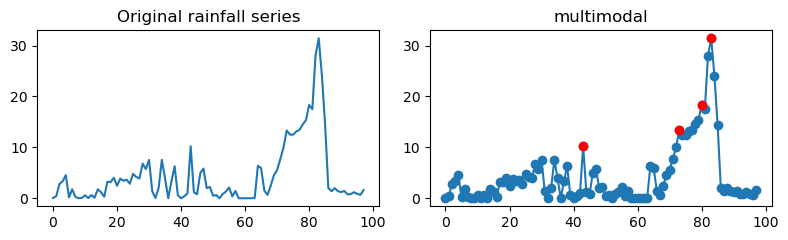

[2.6915459e+01 3.9690697e+01 7.0111938e-03 3.0291276e-05 1.8621260e-02
 2.3933535e+00 5.5860767e+00 3.1588724e-01]
Event index: 7140, result: unimodal, n_peaks: 1


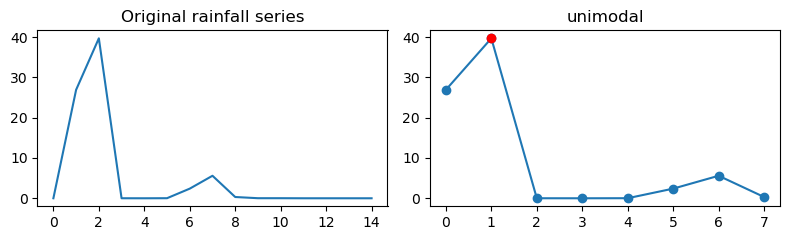

[5.2092767e-01 1.3842711e+00 4.8924928e+00 2.6511884e+00 1.3226402e+00
 3.7627482e-01 1.2233401e+01 1.1921066e+01 2.2004114e+01 2.6609205e+01
 3.1406576e+01 3.6813732e+01 8.5169554e+00 9.5306902e+00 1.2903025e+01
 9.9210567e+00 4.2325344e+00 6.5264549e+00 1.2849124e+01 1.7246862e+01
 1.0328901e+01 1.2172140e+01 7.0403295e+00 1.2469829e+00 7.0346057e-01
 3.6611801e-01 3.4429380e-01 4.0435734e-01 1.2918371e-01 1.5189372e-01
 4.6378195e-01 2.5291877e+00 2.1044874e+00 1.3373812e+00 2.8931239e+00
 1.8876277e+00 3.6390295e+00 3.2064874e+00 3.5296307e+00 3.4821482e+00
 2.1016138e+00 2.0524604e+00 6.8044772e+00 4.8713889e+00 5.4898753e+00
 1.0074185e+01 1.3360631e+01 5.5130324e+00 9.3142300e+00 6.8228531e+00
 4.6717200e+00 9.2777824e+00 1.0484925e+01 8.6406755e+00 8.3750601e+00
 1.0014520e+01 4.3110962e+00 3.2888260e+00 4.1922789e+00 6.8283024e+00
 3.4845891e+00 3.4262578e+00 3.6879017e+00 5.4298215e+00 2.5296683e+00
 1.1596919e+00 1.1239579e+00 1.4031001e+00 1.0759740e+00 1.5724173e+00
 2.648

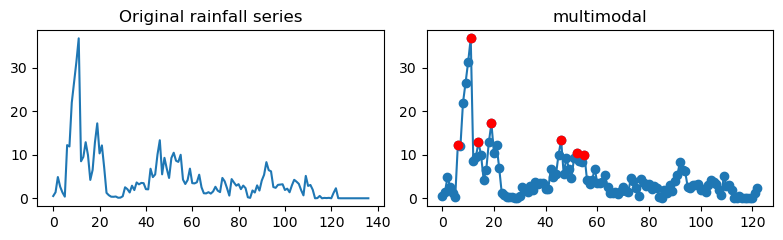

[6.4596581e-01 3.2319824e+01 5.7683587e+00 4.6597320e-01 2.3014960e-03
 8.0858081e-06 3.5155311e-01 5.8763366e+00 9.0534526e-01 3.8881528e-01
 5.9144506e+00 9.9906355e-01]
Event index: 7146, result: unimodal, n_peaks: 1


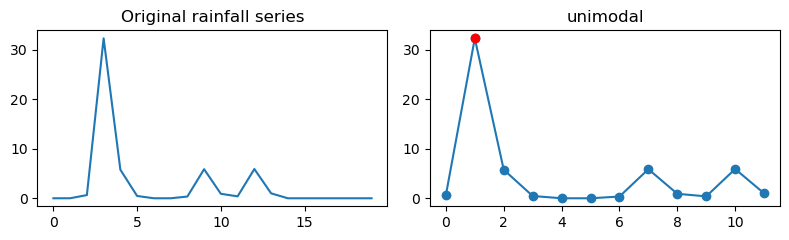

[ 1.5549231   5.2860756   2.0133588   3.2435513   5.7109714   7.1685405
  6.9422183  12.629729   35.488129   58.275574   16.75054    11.474064
  3.3136804   3.6224351   3.5426626   2.1865332   2.3419952   1.9100434
  1.2009121   0.55124813  0.08112031]
Event index: 7177, result: unimodal, n_peaks: 1


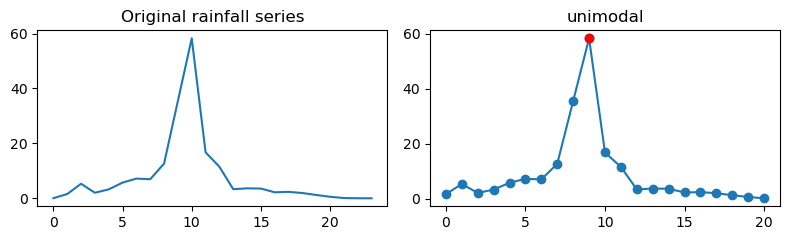

[1.6827353e+01 3.7495529e+01 2.6491417e+01 4.7360706e+00 9.2716468e-03
 4.7249190e-04 2.0362341e+00 1.9873437e-03 8.9414921e-03 2.0765255e-03
 1.3377902e-02 1.2920302e+00]
Event index: 7202, result: unimodal, n_peaks: 1


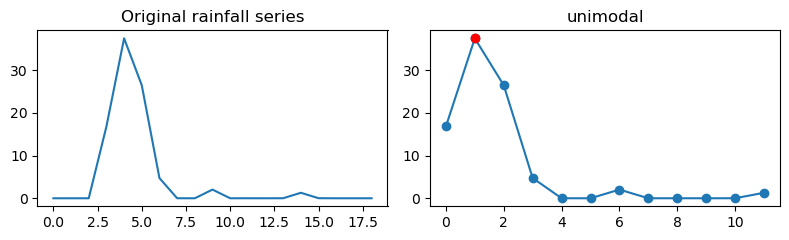

[ 0.6777094   2.5070767   1.3200347   4.2154832   1.108199   35.520134
  9.8357878   0.69806367]
Event index: 7216, result: unimodal, n_peaks: 1


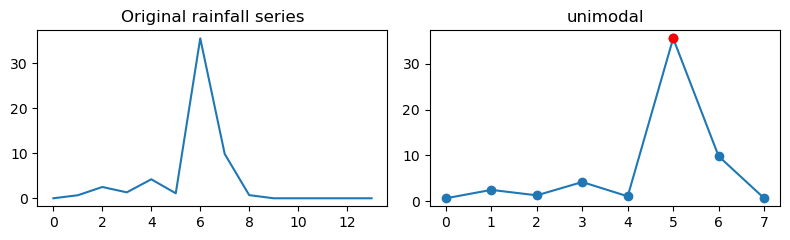

[7.0283484e-01 1.6222608e+00 1.4792545e+00 3.7882392e+00 2.0053403e+00
 3.8114679e+00 5.7349114e+00 1.0743753e+01 1.8892745e+00 1.8790139e+00
 2.4664266e+00 2.7383516e+00 2.0489740e+00 1.8869194e+00 7.6008791e-01
 1.2681610e-02 1.7822123e-03 1.8329389e-03 5.5688453e-01 1.9808861e+00
 1.8130000e+00 7.2710071e+00 6.4867644e+00 5.1924744e+00 1.1922153e+01
 1.8170078e+00 3.2134251e+01 1.7612710e+00 7.9431295e-01 3.6029223e-01
 5.8338338e-01 8.1954932e-01 7.5886579e+00 3.2543786e+00 3.2404301e+00
 8.9236796e-01 5.5715397e-02 1.2810771e-01 4.2743144e+00 4.5518618e+00
 3.7160451e+00 4.7314134e-01 5.7441074e-01 7.0182669e-01 6.6053607e-02
 1.7718509e-03 7.3835023e-02]
Event index: 7279, result: bimodal, n_peaks: 2


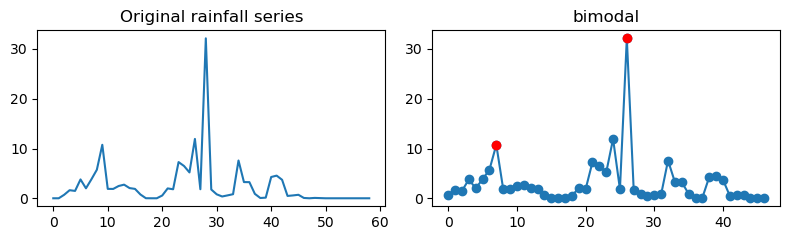

[1.17860049e-01 9.26461399e-01 5.75795829e-01 1.12828958e+00
 1.55698085e+00 3.09904146e+00 2.08922606e-02 3.32482718e-02
 6.17479265e-01 1.87862737e-04 3.38050449e-05 1.03209000e-02
 1.27263856e+00 8.15100223e-03 1.54436290e+00 1.36188179e-01
 3.88442039e+00 6.59463406e-01 4.55609226e+00 7.79827133e-06
 7.68307984e-01 5.08206904e-01 3.53948712e+00 7.59549221e-05
 2.97457092e-02 1.08844864e+00 1.36941969e-01 2.92486131e-01
 1.58028714e-02 7.56746829e-01 9.55553770e-01 3.28930330e+00
 7.52866440e+01 2.29721999e+00 1.07794516e-01 3.30015540e-01
 2.74922550e-02 3.34708095e-01 5.22362113e-01 4.08267021e-01
 2.42270201e-01 5.56549191e-01 8.85502875e-01]
Event index: 7290, result: unimodal, n_peaks: 1


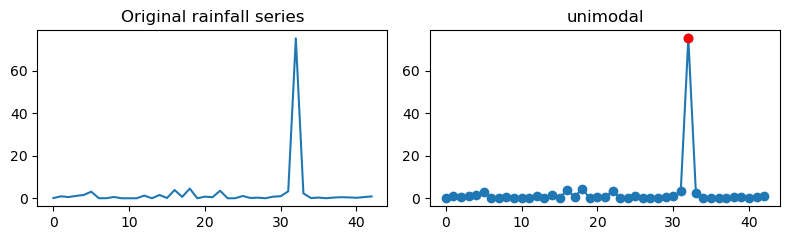

[6.8853384e-01 6.0207099e-01 5.2148861e+01 4.0520248e+01 4.6865144e+00
 1.3050383e+00 4.6397305e-01 6.7130500e-01 1.7821581e+00 2.2736306e-01
 6.0833726e-02 3.0697284e-02 4.7051203e-02 5.2878398e-01 5.5489454e-02
 3.8184128e+00 3.8578495e-02 1.4517042e-01 1.6399291e+00 1.3622221e+00
 7.4130774e-02 2.4624319e-01 3.5590348e+00 7.8859863e+00 5.6712494e+00
 1.0088630e+01 8.6181688e+00 9.3172235e+00 2.4606802e+00 7.6670589e+00
 2.1760333e+00 1.7989858e+00 1.4285129e+00 3.7619846e+00 1.0597834e-01
 4.2052665e-01 1.0909125e-01 1.6761838e-02 3.5376057e-01 4.4714551e-02
 6.9833494e-04 2.2013421e-01 1.9059401e+00 8.2889500e+00 3.2178277e-01
 1.0523320e+00 1.4527252e+00 2.4926357e+00 5.4140145e-01 4.5250964e+00
 1.7242895e-01 1.0890552e-01 3.5394946e-01 2.3514293e-01 2.7436671e-01
 4.6684578e-01 5.6875825e-01 1.7426512e-01 1.5702701e-01]
Event index: 7319, result: bimodal, n_peaks: 2


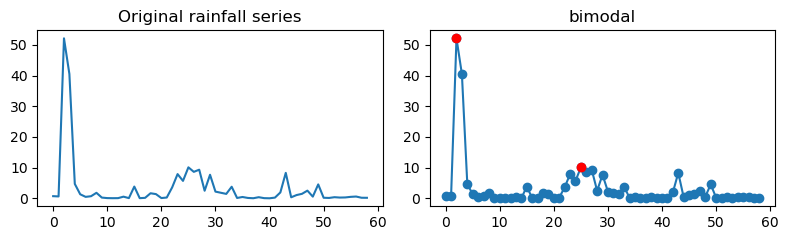

[ 0.52112299  0.86673719  2.5801206   6.5702562   8.9351435   9.4845295
  5.2531605   9.3549795  13.662474   11.902586   19.279419   31.937826
 26.668997   11.128731    1.2602512   0.11846008]
Event index: 7327, result: bimodal, n_peaks: 2


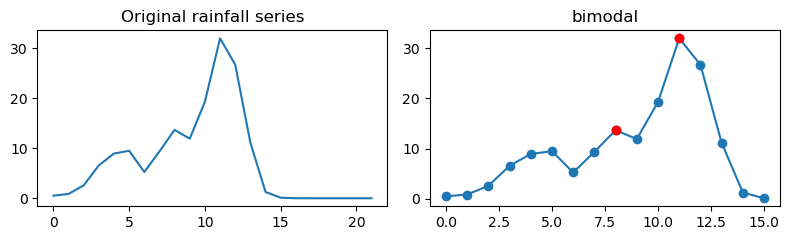

[ 0.54268187  2.0491297   5.4005075   2.9432962  12.184976   38.23164
 11.364369    1.4148787   0.5916701   0.3386493   0.2796241   0.26763302
  0.10454782]
Event index: 7336, result: unimodal, n_peaks: 1


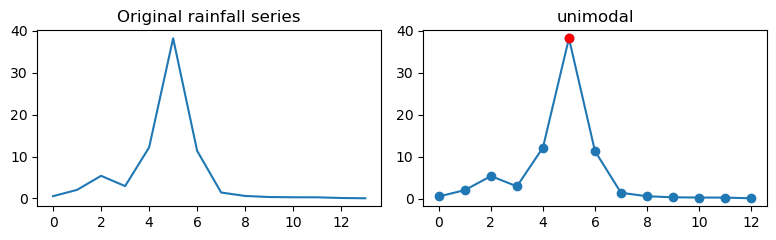

[6.15605488e-02 4.94485950e+00 1.01631441e+01 2.68679738e+00
 1.13267846e-01 2.90960907e-05 1.12297630e+00 1.87199330e+00
 9.62432444e-01 1.62032497e+00 3.99876066e-04 1.41505341e-04
 4.33272791e+00 1.06654167e+00 4.80092615e-02 4.36626514e-03
 4.78365719e-01 5.69812632e+00 6.07908249e+00 1.55040872e+00
 1.91945970e+00 1.09905779e+00 4.68531990e+00 6.45656872e+00
 1.19832220e+01 3.35310483e+00 3.37344227e-06 1.72370949e-06
 3.87218824e-06 1.38897272e-02 1.11029580e-01 3.00471693e-01
 9.57325363e+00 3.45037723e+00 3.40730262e+00 1.55239522e-01
 5.13344824e-01 1.26192003e-01 1.51710653e+00 9.31420771e-04
 7.22611248e-01 3.95994097e-01 2.28920892e-01 4.57316164e-05
 4.49677892e-02 2.23981366e-01 6.45586923e-02 7.10251510e-01
 9.59745347e-01 3.27005816e+00 8.96330261e+00 1.03025599e+01
 1.35869493e+01 1.31408062e+01 1.62146950e+01 2.68171864e+01
 3.11468830e+01 2.96211243e+01 2.83630486e+01 2.30258465e+01
 1.87581997e+01 1.55729084e+01 1.67512763e+00 6.16892695e-01
 6.31443739e-01 7.206388

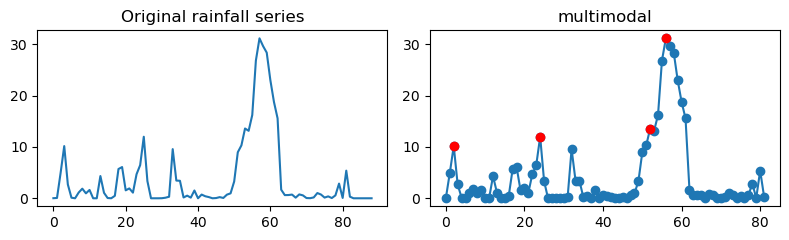

[ 0.25624114  0.16997164 14.269458   15.389191    5.8708501   1.3465546
  0.98449999 25.87816    47.787289   18.113544    0.92996442  0.63521397
  0.4935472   0.25028741  0.11918899]
Event index: 7341, result: bimodal, n_peaks: 2


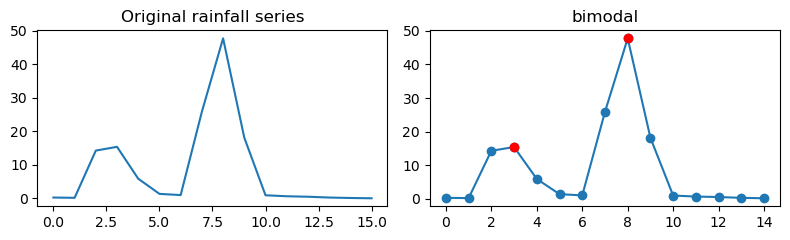

[3.1439470e+01 4.5228782e+00 1.9021923e-02 1.2189561e+00 5.2024674e+00
 6.9168919e-01 2.3145692e-01 9.8928414e-02 3.2229945e-02 1.5669139e-02
 2.7228418e-01 1.1844571e+00 8.4175503e-01 3.7010956e-01]
Event index: 7347, result: unimodal, n_peaks: 1


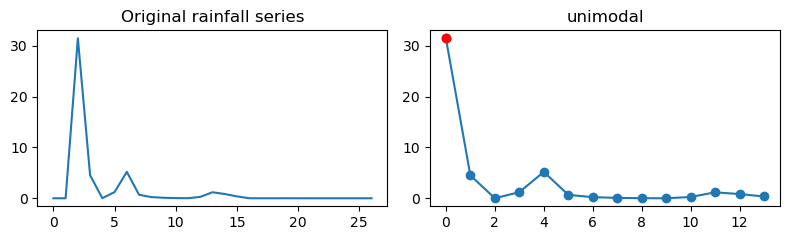

[23.122068   43.851315   13.341432    0.09214786  0.30815119 11.360503
  3.9336667   0.34075737]
Event index: 7364, result: bimodal, n_peaks: 2


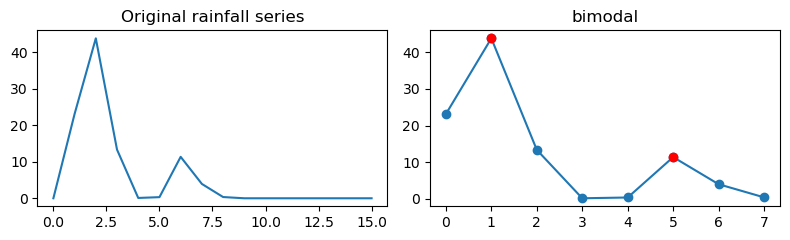

[4.1473660e+00 2.2633335e+01 3.6047810e+01 2.0245539e+01 3.7133882e+00
 2.2332935e+00 1.5306556e+00 9.2270505e-03 1.0429312e-03 1.5773251e-06
 7.3579753e-07 2.3599002e-04 7.2317006e-04 1.5247985e-02 5.8545572e-07
 1.4247944e-02 2.9305862e-03 1.0820976e-03 3.9216623e+00]
Event index: 7396, result: unimodal, n_peaks: 1


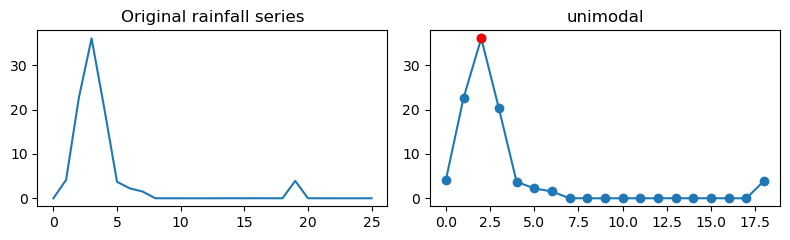

[7.79944733e-02 1.51636332e-01 1.59849182e-01 1.05923094e-01
 2.37067938e+00 2.66825104e+00 9.07031476e-01 1.14072061e+00
 7.10239112e-02 1.56208014e+00 2.30384827e+00 7.06656933e-01
 3.11414680e+01 6.48724461e+00 1.96576566e-01 6.97702989e-02
 5.82316611e-03 8.61389562e-04 4.64222376e-06 3.18238318e-01]
Event index: 7410, result: unimodal, n_peaks: 1


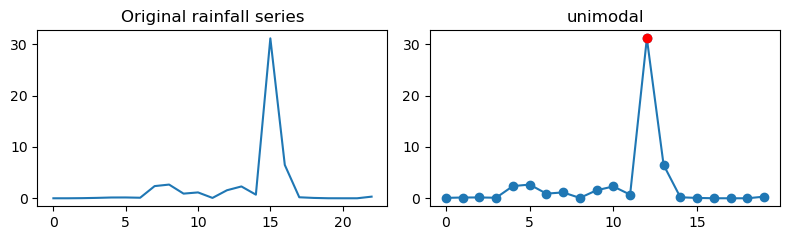

[3.6692628e-01 4.8474979e+00 5.7555187e+01 3.4622471e+01 2.9050148e+01
 9.0623491e-02 4.5585487e-02 2.1072994e-03 5.9206146e-03 9.5784880e-02
 4.7803223e-02 5.3503301e-02]
Event index: 7433, result: unimodal, n_peaks: 1


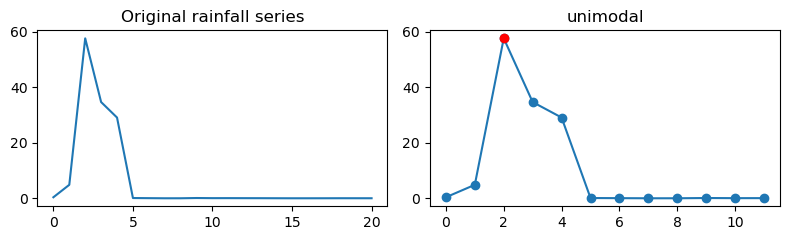

[5.6188500e-01 4.7329497e-02 4.5807764e-07 4.9366527e+00 3.5232925e+01
 2.8813293e+00 3.2703049e+00]
Event index: 7504, result: unimodal, n_peaks: 1


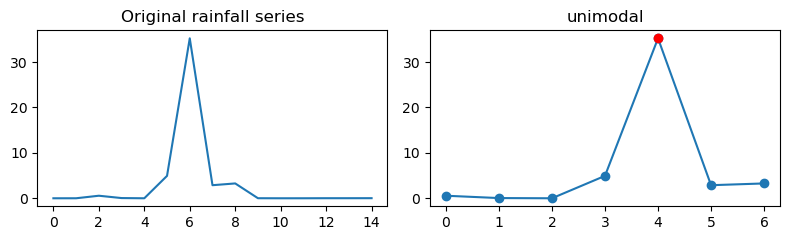

[ 1.5694711   1.8349261   6.7766118   4.3737793   2.6902816   4.4090276
 20.251209   33.326443   43.32671    27.642628   11.636103    9.8792143
  8.9507418  16.348574    7.4939475   5.8176107   0.13240302  0.63987851
  0.57425821  0.08810205]
Event index: 7505, result: bimodal, n_peaks: 2


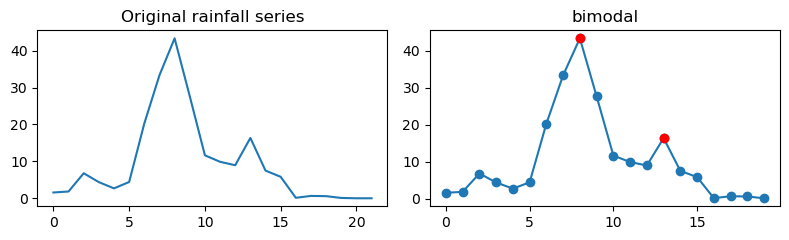

[3.10174999e+01 1.66930466e+01 1.54267822e-04 3.64053226e+00
 3.25389647e+00 1.01263189e+00 5.26575185e-02 6.14543867e+00
 1.57116165e+01 5.01786232e+00]
Event index: 7553, result: bimodal, n_peaks: 2


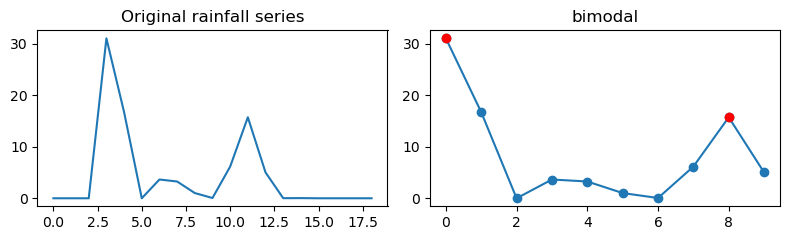

[ 0.06815858  0.33190158  0.4741178  10.2882      4.5500445  30.264877
  2.3842294   1.8315892   2.373621    1.3283306   1.505032    1.242238
  0.48047236  0.24234188]
Event index: 7554, result: unimodal, n_peaks: 1


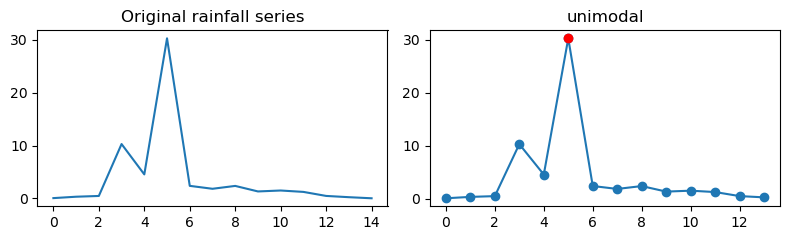

[ 0.87619299  2.0434666   3.4731224   1.8743727   1.6980307   1.6862081
  1.6924155   1.5251125   2.3309443   2.3240805   1.8382062   1.936193
  3.919076   33.679298   19.915844   18.801399    6.8508205   3.4396505
  2.3139217   0.52641898]
Event index: 7564, result: unimodal, n_peaks: 1


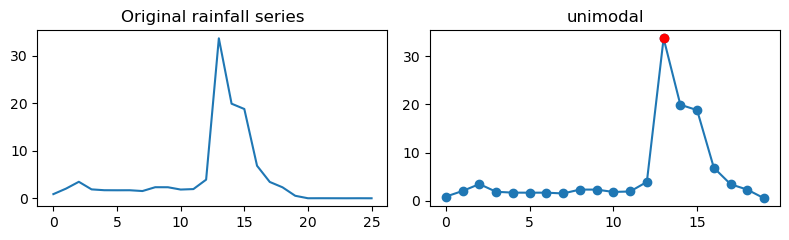

[1.80829778e-01 3.04621649e+00 5.27792597e+00 1.06297245e+01
 9.70595169e+00 9.20899963e+00 1.69069729e+01 2.82176437e+01
 3.76753502e+01 8.83011723e+00 1.02725334e+01 8.64072323e+00
 7.23175192e+00 2.44015675e+01 1.62952881e+01 2.25170822e+01
 1.37900476e+01 5.77264214e+00 8.55832826e-03 3.02417696e-01]
Event index: 7565, result: multimodal, n_peaks: 3


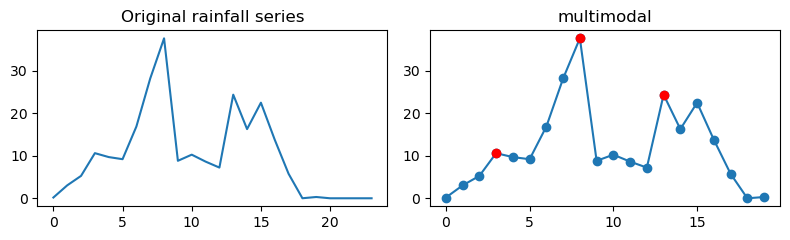

[ 0.58047879 32.8927956  13.3489685 ]
Event index: 7568, result: unimodal, n_peaks: 1


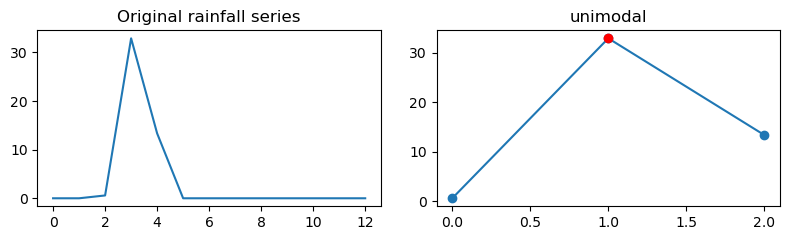

[3.8313380e-01 3.0179537e+01 2.3481777e+01 1.5219586e-01 2.2189176e-06
 1.5995936e-06 1.4555346e-06 3.0713800e-01 1.5931330e+00]
Event index: 7572, result: unimodal, n_peaks: 1


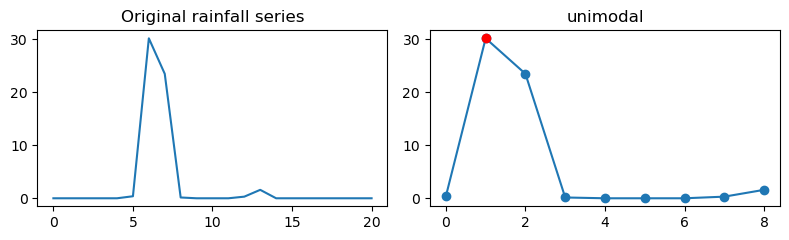

[1.5430565e-01 5.9813399e+00 1.1821697e+01 1.2259555e+01 3.1824333e+01
 1.2935975e+01 1.3995984e+01 8.5809183e-01 1.9149117e-01 1.2738481e-01
 1.9586159e+01 3.6179435e-02 1.5011631e-06 1.8676669e-04 1.7585648e-06
 1.9706910e+00 5.6469846e-01 5.4750204e-01 4.3504933e-01 4.4268594e+00
 2.1044624e+00 3.3938429e-01 6.6034049e-01 5.1364784e+00 2.2691901e+00
 1.5365553e+00 2.1969237e+00 9.8016196e-01 1.9932681e+00 9.0257097e-03
 1.6148782e+00 1.8077602e+00 5.6001835e+00 9.2091605e-02 1.3472624e+00
 1.1668304e+00 6.6561038e-03 2.6818463e-01 2.2207017e-04 2.8992677e-06
 8.1504935e-01 6.6992607e-06 3.1253574e-06 2.1367052e-04 1.1863905e-06
 2.0524104e-01 6.1136447e-03 1.5694939e+00 1.1186927e-03 6.3518435e-01
 1.6469367e+00 2.5806560e-03 2.4597940e-01 4.7061648e-03 7.5910616e-06
 1.1104574e-02 4.2475029e-04 2.1493311e-06 2.5705931e-06 1.1825139e-06
 5.8997098e-06 1.3166621e-06 1.8109492e-06 6.7500406e-07 5.7216644e-01
 7.3660934e-01 1.3902346e-05 3.1853681e-06 6.5639222e-05 7.6732385e-01
 5.171

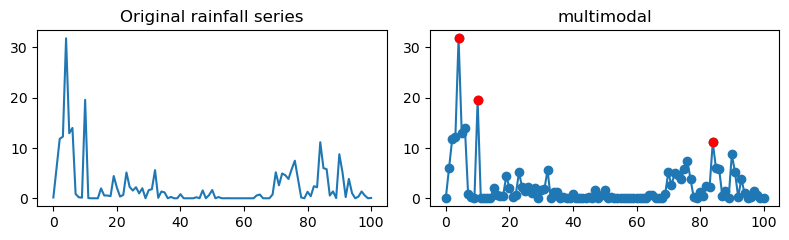

[9.2589152e-01 1.9028023e+00 5.1335120e-01 1.6970508e-02 8.0117024e-03
 1.3973484e+00 3.9976952e-03 3.9755523e-02 6.4671197e+00 2.0988753e+00
 7.0199645e-03 4.1157821e-07 9.7336240e-02 9.2126951e-02 4.7415760e-03
 5.4591599e+00 2.7104094e+01 4.2479130e+01 1.6119366e+01 2.2935078e-01
 2.3736090e-03 2.9867627e-02 3.4076348e-03 2.5426098e-03 5.5232999e-04
 1.0550338e-03 1.4233436e-03 1.4625682e-01]
Event index: 7585, result: unimodal, n_peaks: 1


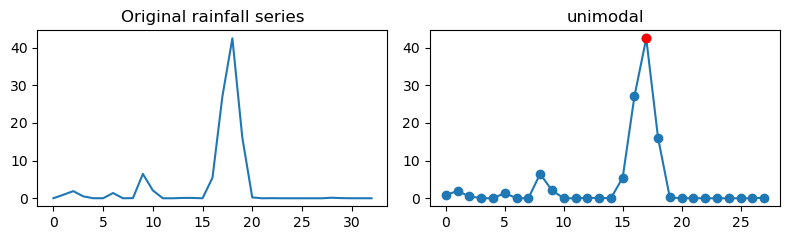

[ 6.0942903 35.086853   9.7804499]
Event index: 7586, result: unimodal, n_peaks: 1


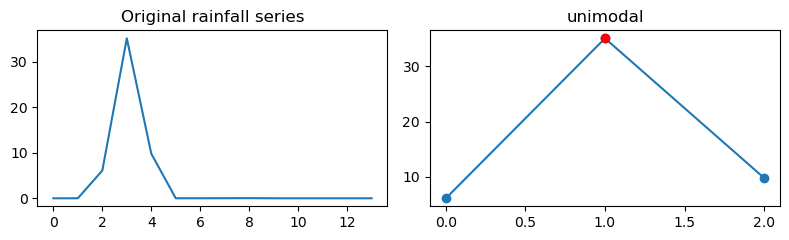

[ 0.41206136  1.1421721   1.6049631   4.9778085  10.615166    7.785084
  9.824064   19.777998   25.910032   34.014694   29.232712   10.9436245
 10.110452   11.110196    8.875184   17.64182    11.362758    2.094798
  2.098453    2.5553977   3.169795    2.7109258   2.7712903   3.243711
  2.5917044   2.584192    1.7300745   0.38682368  1.1366847   0.41540384
  1.8060634   2.0499032   1.2408923   1.4799203   0.8176531   0.4334649
  0.7516123   0.5171776 ]
Event index: 7590, result: multimodal, n_peaks: 3


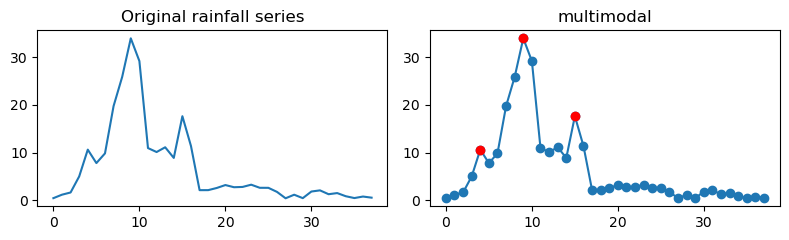

[ 4.3849206  30.3927002   3.31752682]
Event index: 7592, result: unimodal, n_peaks: 1


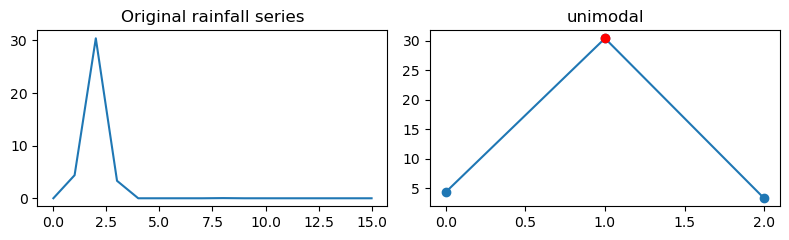

[6.0296035e-01 4.4806200e-01 7.4878693e-02 4.1520535e-03 1.1471409e-06
 8.8922695e-07 2.5363836e-06 1.5483972e-06 1.7349865e+00 3.6997681e+01
 9.2589722e+00 2.3121202e+00 3.9063003e-02 1.5021661e-01 1.2664005e-01
 6.0548431e-01 1.6546357e+00 1.5033761e+00 6.9305432e-01 1.6621500e-01
 1.0767288e-03 8.3261786e-04 5.3395715e-02]
Event index: 7599, result: unimodal, n_peaks: 1


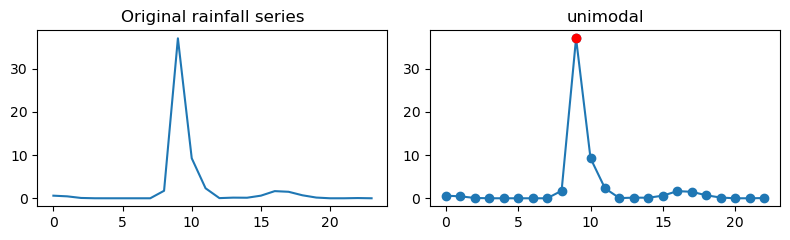

[ 0.5991094   5.3393445  10.703089   19.059383   32.497337    8.850053
  8.985982   19.89557     2.1846476   1.8828115   1.1693602   0.57213956
  0.3589921   0.25151733  0.2644941   0.14999488]
Event index: 7601, result: bimodal, n_peaks: 2


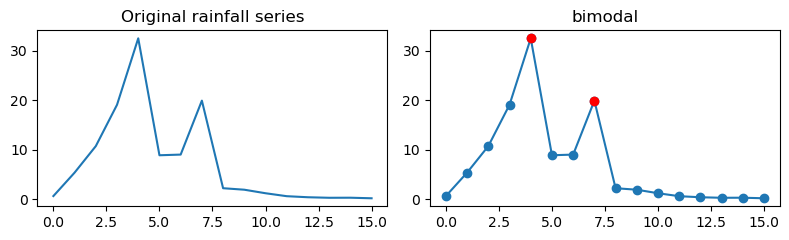

[7.40973473e-01 2.33825779e+00 2.62475896e+00 3.00625396e+00
 3.31401610e+00 4.10098648e+00 5.35209656e+00 3.80328107e+00
 2.17548871e+00 3.23329139e+00 1.90567863e+00 3.87963384e-01
 4.18420494e-01 1.39274538e+00 3.70190787e+00 7.08482170e+00
 8.03663063e+00 9.83963108e+00 1.21414738e+01 1.26725330e+01
 1.24422865e+01 2.34761620e+01 3.04937668e+01 2.47219543e+01
 1.48302021e+01 1.09882851e+01 1.13329306e+01 3.72231174e+00
 1.25139749e+00 3.21271181e+00 2.35250163e+00 8.16437721e-01
 3.42411011e-01 1.40225459e-02 2.55956739e-01]
Event index: 7614, result: multimodal, n_peaks: 3


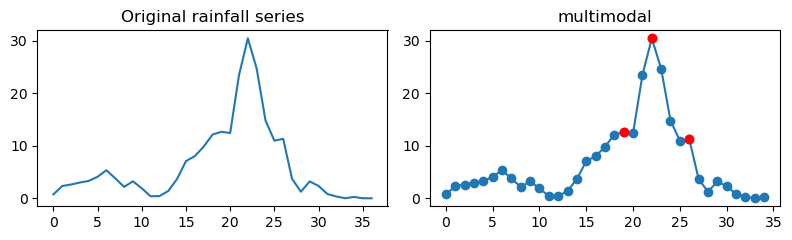

[1.30606920e-01 2.49163099e-06 2.32009552e-02 3.43333445e-02
 5.32468874e-03 7.03059323e-03 2.13855747e-05 2.09318027e+01
 4.69898453e+01 1.45603676e+01 5.46885848e-01 5.10921383e+00
 3.85484862e+00 5.72381914e-01 9.64046180e-01 1.68851626e+00
 1.52434595e-02 2.01742306e-01]
Event index: 7621, result: unimodal, n_peaks: 1


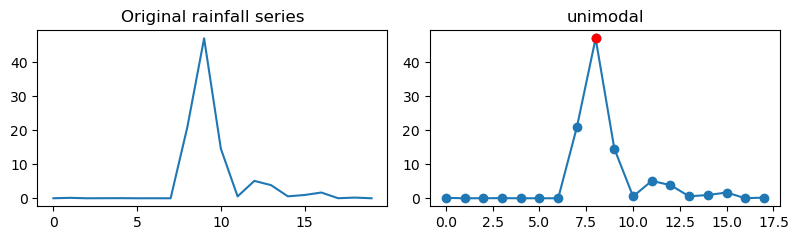

[ 1.3345925 11.272037  23.201063  36.165936  27.547014   4.33297
  1.2776269  1.1036099  1.3616768  1.1486188  1.1184334  0.838098 ]
Event index: 7622, result: unimodal, n_peaks: 1


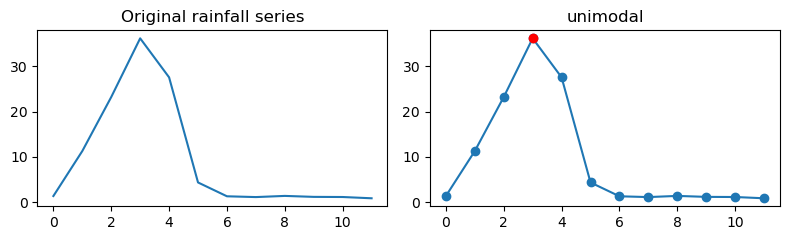

[3.7347445e+00 3.4445904e+01 1.3897335e+01 7.5106376e-01 8.0350319e-06
 1.7254341e-03 2.4832822e-01 4.3829544e-03 4.1306958e-01 1.5616590e-01
 8.4135970e-03 3.2197034e-01]
Event index: 7625, result: unimodal, n_peaks: 1


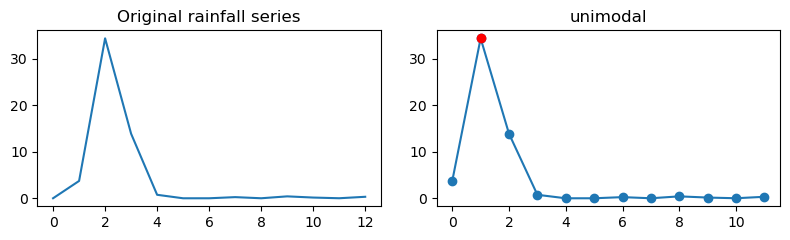

[ 1.4128958   1.2475495  10.182287    3.3039088  30.3827      5.3158364
  1.3672401   1.7998042   0.8256834   0.16062914  0.20104353  0.26994413]
Event index: 7627, result: unimodal, n_peaks: 1


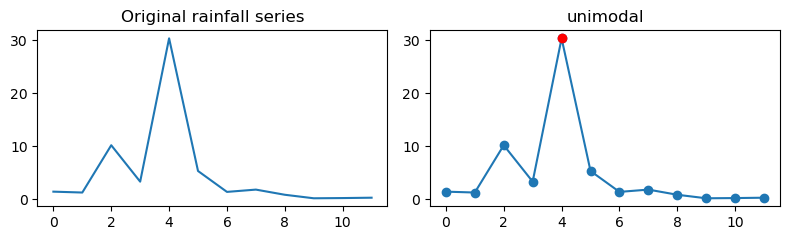

[9.0862113e-01 2.9952745e+00 6.4327472e-01 3.8007215e-01 2.1777928e+00
 4.2312911e-01 6.5356418e-02 2.7970762e+00 5.1176113e-01 1.3865001e+00
 2.2476790e-03 2.2391047e-01 2.2087314e+00 7.0755210e+00 2.3572185e+00
 1.4224205e+00 3.9757929e-06 3.0535762e-03 1.8466321e-01 8.7597668e-01
 5.1966143e-01 3.2368362e+00 6.9093690e+00 1.3875148e+01 8.5535145e+00
 5.1927700e+00 7.6776032e+00 7.2185359e+00 1.5878427e+00 1.4348450e+00
 1.5120951e+01 3.6219173e+01 1.8943386e+01 3.0803295e+01 2.3977703e+01
 7.2721162e+00 6.0585532e+00 1.0575858e+01 5.3406549e+00 3.9401740e-01
 7.6485827e-07 2.8616592e-01 1.5029666e-06 1.1301417e-01 4.7595172e+00
 8.8451170e-06 3.3137676e-06 1.0767661e-01 9.3116140e-04 4.5970332e-06
 1.3015437e-01 1.3499841e-02 1.3023102e+00 1.7300135e-01 7.0863333e+00
 3.4402623e+00 4.4360072e-06 1.8944610e-06 3.9963970e-06 2.0358627e-06
 2.0158950e-06 6.3671964e-01 1.9439498e+00 7.3155522e+00 4.0319523e-01
 2.1630311e+00 3.3291607e+00 2.6373595e-01 1.8627819e-01 3.5318051e-06
 4.399

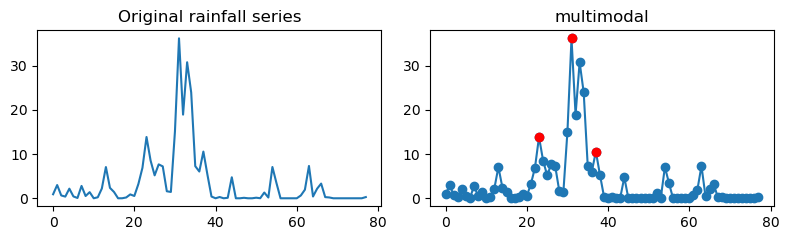

[3.6863909e+00 3.0062988e+01 1.8540764e+01 9.6382685e+00 6.7231017e-01
 7.8229845e-01 4.6354285e-01 1.6003245e-01 3.2432994e-04 1.4500336e-04
 1.3340096e-01 2.8895921e-01 2.7498862e-01 1.5176684e-01]
Event index: 7631, result: unimodal, n_peaks: 1


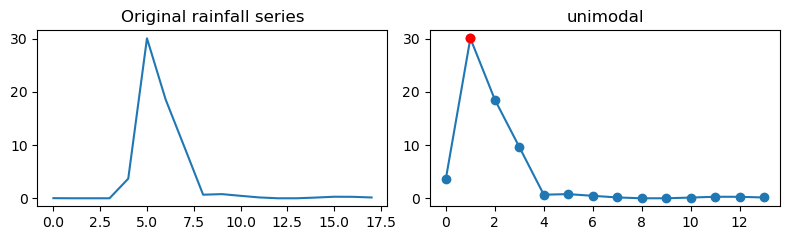

[ 0.08481011  0.6320923   0.89413339 12.051692    5.1047878   2.2267942
  1.5191123   1.5697395   2.2164428   2.0449264   3.3345668   2.5267251
  2.7875381   5.8197594  31.117489   24.160944   29.578445    5.4863682
  1.5420208   0.44241548  1.2244085   1.3394078   9.1621685  17.877737
 17.747372    3.3089607   2.9443278   2.3329337   1.9359275   1.5379008
  1.1787887   2.3705225   1.8695613   1.1781811   1.0834891   0.14436892]
Event index: 7633, result: multimodal, n_peaks: 3


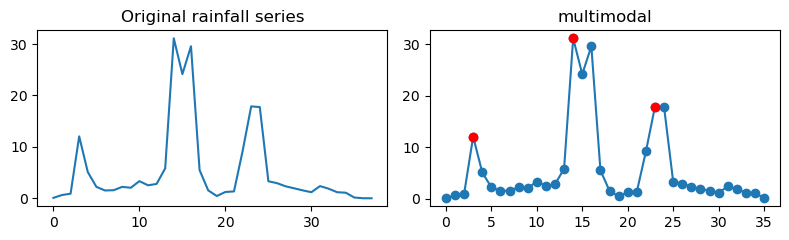

[ 0.99202144  3.292937    2.011261    1.3842258   0.27367252  9.4230385
  2.662926    4.5630231   4.1251364   1.1508993   2.0105803   0.91448939
  0.47459638  1.7117225   0.14740081  1.978469   32.563034   16.515347
 13.308973    9.0164976   1.7161222   0.61212039]
Event index: 7637, result: unimodal, n_peaks: 1


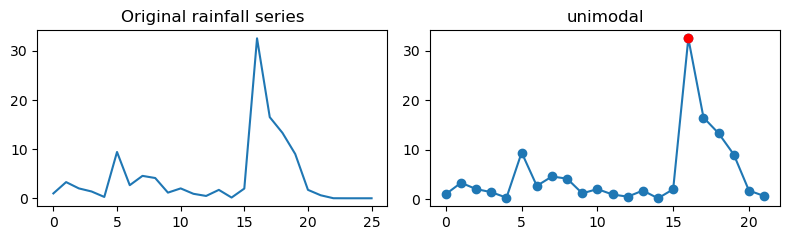

[2.04934025e+00 5.31618023e+00 7.32639122e+00 9.42127323e+00
 1.20585032e+01 9.18205070e+00 1.11545048e+01 2.14916682e+00
 1.90558434e+00 1.90934408e+00 7.35467315e-01 4.88697720e+00
 5.62935495e+00 7.58489513e+00 7.56131220e+00 7.80503941e+00
 1.14616623e+01 8.69686413e+00 4.83518219e+00 5.47498894e+00
 6.64522791e+00 1.99330020e+00 2.78955698e+00 4.75864840e+00
 2.04523716e+01 3.54670410e+01 8.34500408e+00 2.26758444e-03
 4.50405389e-01 3.18537402e+00 8.09977722e+00 1.23720360e+01
 7.71415997e+00 5.28393412e+00 6.66793108e+00 9.54272461e+00
 9.25767803e+00 1.00362644e+01 6.09935474e+00 6.25799227e+00
 5.92909479e+00 6.31187296e+00 9.09957886e+00 1.02902927e+01
 1.14455976e+01 1.09569149e+01 1.07060375e+01 3.97232628e+00
 5.95501363e-01 5.72766066e-01]
Event index: 7640, result: multimodal, n_peaks: 6


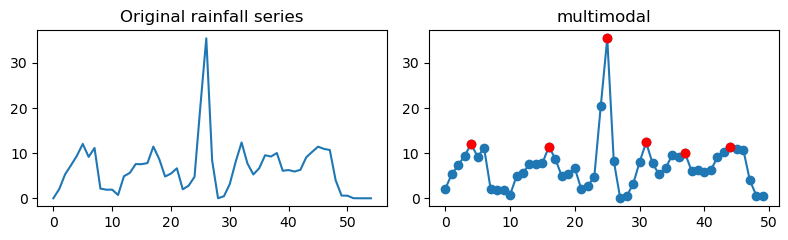

[ 2.7595832   2.2403636   3.6005728   2.6319008   1.1038392   3.3032219
 12.287573   10.975355   16.25165    21.052889   18.884945   18.748058
 31.286606   19.032766    7.1495042   1.3696512   0.84413445  0.8565886
  0.88071328  0.8914094   0.86708117  0.84340638]
Event index: 7647, result: multimodal, n_peaks: 3


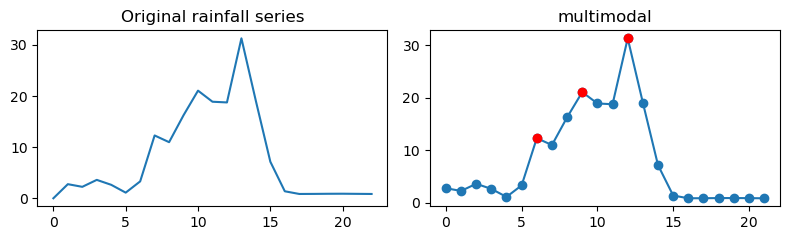

[1.5590862e+00 2.5138593e+00 5.5343388e-03 4.8980990e-04 6.3042552e-04
 1.5611549e-02 3.9990408e+00 1.1260899e+01 1.6519720e+01 4.2704575e+01
 2.8582628e+00 4.1901097e-02 2.3134266e-01 3.3014941e+00 1.2868251e-01
 2.3301132e+00 1.3636591e-01 1.8314447e-01 3.3131685e-02 1.0167288e+01
 1.6584906e-01 2.9184222e+00 1.4866206e-05 1.2562399e-02 3.0193757e-04
 2.8038898e-01 1.8096188e+00 5.6323285e+00 8.8267290e-04 1.5285488e-06
 2.7182949e-07 1.7533748e-01 9.1513179e-02]
Event index: 7652, result: bimodal, n_peaks: 2


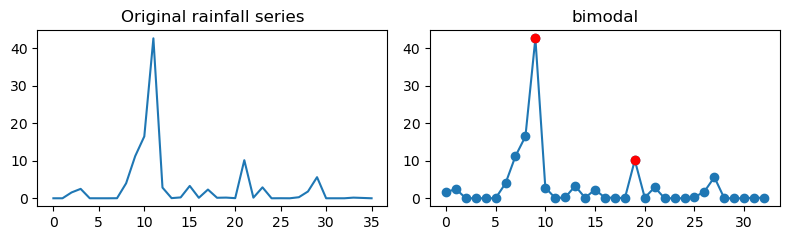

[2.7492791e-01 2.8996204e-04 8.6883578e-05 2.6213867e-04 8.1674581e-05
 1.0690241e-02 3.5599968e+01 4.7313213e-01 2.4419843e-04 1.0824379e-03
 8.2017720e-02 7.1185786e-01 8.1815511e-01 4.5944682e-01 8.7150320e-04
 4.0179821e-05 3.7760200e-04 3.8691975e-02 3.9272584e-02 3.1273231e-02
 1.1624417e-01 2.4878152e-01 4.6965924e-01]
Event index: 7705, result: unimodal, n_peaks: 1


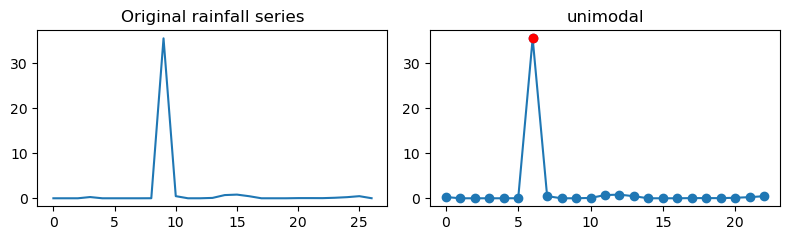

[1.73515868e+00 3.03961372e+00 4.73107386e+00 4.43402004e+00
 5.53747845e+00 2.81145406e+00 4.57949591e+00 8.04056072e+00
 1.12041492e+01 1.26497755e+01 1.59183197e+01 1.47678070e+01
 1.89007969e+01 2.65004978e+01 1.73851662e+01 1.21666441e+01
 9.34200668e+00 1.24546738e+01 1.43914185e+01 1.00639915e+01
 1.02866449e+01 1.83535748e+01 4.57934418e+01 2.16941490e+01
 2.17073326e+01 8.54735661e+00 2.20599532e+00 5.05101681e-01
 6.53673768e-01 1.28412914e+00 2.57904577e+00 1.40161788e+00
 4.57680896e-02 1.36442808e-02 2.79040504e-02 5.04343688e-01
 2.66437948e-01 6.32176170e-06 1.53334153e+00 8.30756664e+00
 7.00740933e-01 4.69136286e+00 2.99597621e+00 3.23075938e+00
 9.69267607e-01 4.61886215e+00 1.07495689e+00 3.51813221e+00
 1.02297745e+01 1.84292412e+00 5.27666807e+00 3.07719278e+00
 2.19855094e+00 9.29503620e-01 1.36274230e+00 1.64965022e+00
 1.03828180e+00 6.07443035e-01 5.34760284e+00 4.08744276e-01
 8.15306455e-02 4.89333153e-01 8.95100951e-01 1.66731536e-01
 3.92109063e-03 1.361221

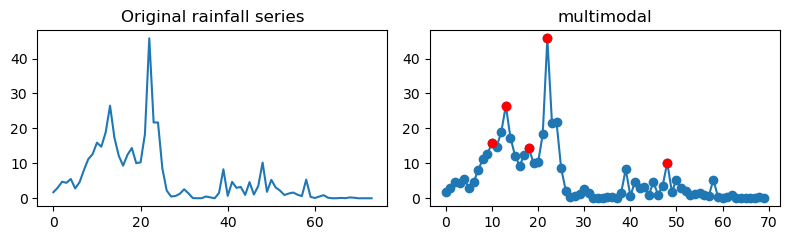

[ 3.3206108 11.697411  38.186737   1.2373147]
Event index: 7713, result: unimodal, n_peaks: 1


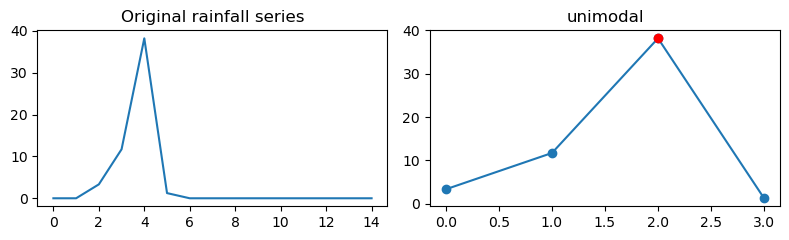

[3.1237786e+00 3.3766687e-01 2.3398604e-07 2.5020469e-07 1.0736699e-06
 2.4557453e-06 7.3912065e-03 2.6271965e+01 3.9229980e+01 7.3757024e+00
 1.2927556e-01 2.1301648e-01 4.2945823e-01 1.9314545e-01 1.4388806e-01
 2.5246465e-01]
Event index: 7716, result: unimodal, n_peaks: 1


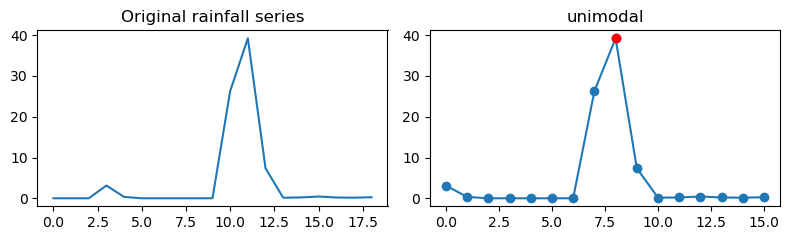

[1.9040600e+00 1.4414199e-01 6.9533594e-02 1.3228683e-01 8.8949055e-06
 4.4405758e-01 2.7273474e-05 1.1761920e-06 1.1686845e-06 8.0488813e-01
 5.3092679e-03 1.0084411e+00 9.9526310e+00 4.7084364e-01 3.7332429e-05
 2.4354993e-03 7.1506804e-07 4.8631203e-01 5.8175125e-03 1.2150008e-06
 4.2782440e-06 1.4467347e-06 4.8631358e-07 6.9237337e-04 7.5918189e-07
 1.0671370e-06 5.3843513e+00 3.5916912e+01 4.4523101e+00 7.5117820e-03
 3.1103984e-05 1.8490472e-06 7.6619685e-01]
Event index: 7717, result: unimodal, n_peaks: 1


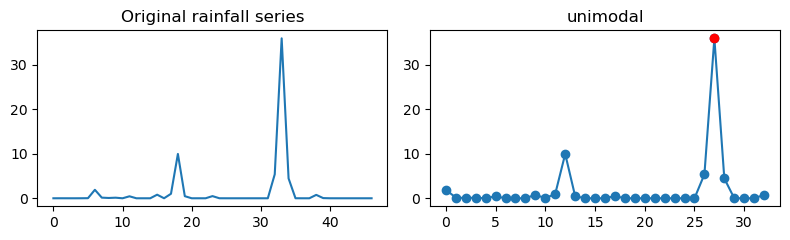

[3.9985054e+00 8.0527534e+01 1.7852221e+01 1.3100839e+01 2.4455145e-01
 8.8139993e-01 1.3999359e-01 1.3496435e-01 1.5832968e-01 8.3300628e-02
 2.7924162e-01 4.6265972e-01 1.9771873e-03 2.4228799e-05 3.5709223e-01
 7.7738827e-01 3.8199956e+00 6.9581776e+00 4.4905448e+00 2.5912391e-03
 4.9654167e-02 1.1831187e-05 4.4818912e-06 5.4448053e-02]
Event index: 7754, result: unimodal, n_peaks: 1


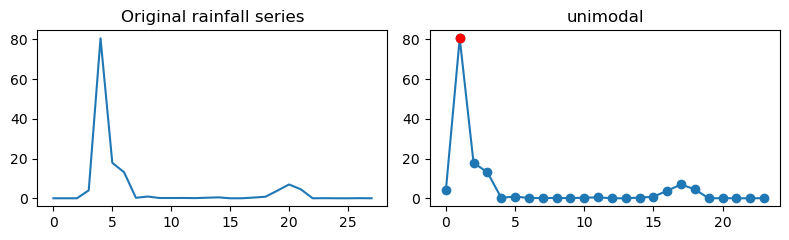

[6.1473101e-01 4.2626959e-01 1.6091758e-01 5.3254433e+00 3.0343756e+01
 3.6845436e+00 5.4559237e-01 2.8420895e-02 1.8344641e-06 8.9875255e-07
 2.6777610e-02 5.4086883e-02]
Event index: 7758, result: unimodal, n_peaks: 1


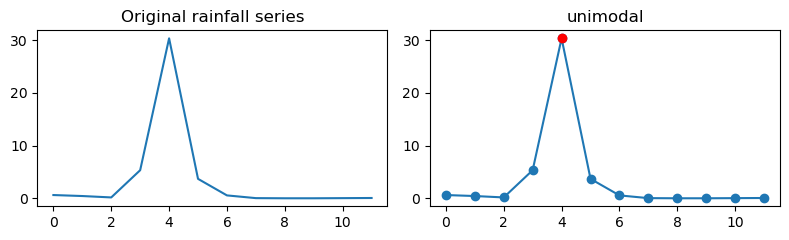

[3.5500614e+01 1.7742470e-01 3.8770039e-02 2.4920635e+00 1.1599707e+01
 2.1736963e-02 6.5862737e+00 4.3722477e+00]
Event index: 7778, result: bimodal, n_peaks: 2


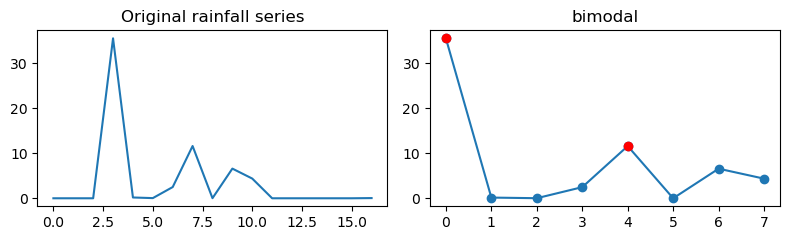

[16.931742   3.1099057  5.5159531 59.562576   9.6200275 18.104147
  1.3135304]
Event index: 7780, result: bimodal, n_peaks: 2


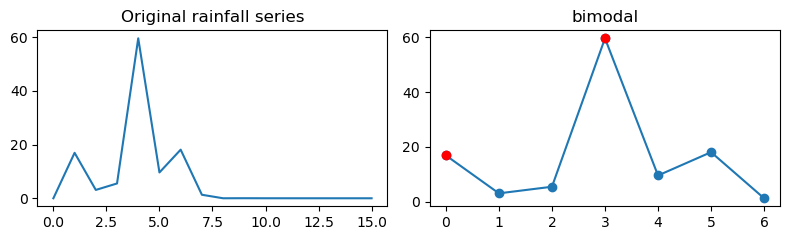

[1.7956901e-01 3.3555960e-04 7.9605030e-04 2.7354321e-02 9.3446434e-01
 2.2087634e-05 9.9296623e-01 6.3777792e-05 3.8397098e-03 2.7215624e-01
 1.1192251e+00 3.6183696e-02 1.3313215e+00 7.2170281e+00 8.0473576e-04
 2.2861716e-06 3.0070669e-06 1.6869036e-03 2.5218446e+00 2.7540460e-02
 5.1038761e-02 3.3398378e-06 2.4082527e-02 8.4785810e-05 5.2397418e-06
 2.3505406e-07 1.0256333e-05 3.6253834e-01 2.3536411e-01 8.6594472e-04
 1.6849469e-06 1.7162416e-06 2.4829728e-06 1.0499479e+00 9.3347952e-02
 9.0308012e-03 1.7523704e-02 1.8244415e+01 4.6830574e+01 7.0874715e-01]
Event index: 7831, result: unimodal, n_peaks: 1


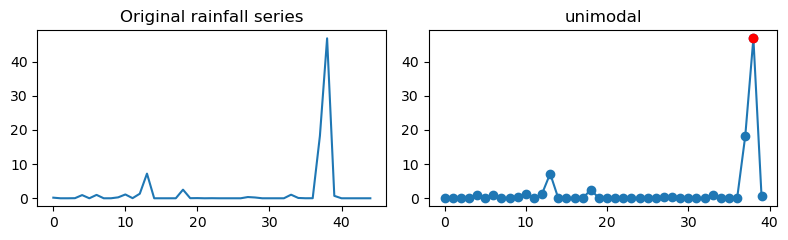

[1.7498235e+00 2.6033845e+00 2.2830155e+00 9.4264154e+00 4.2181484e+01
 1.7564045e+01 7.7225864e-01 1.4605784e+00 8.0119513e-02 2.9581995e-06
 1.4346592e+00]
Event index: 7853, result: unimodal, n_peaks: 1


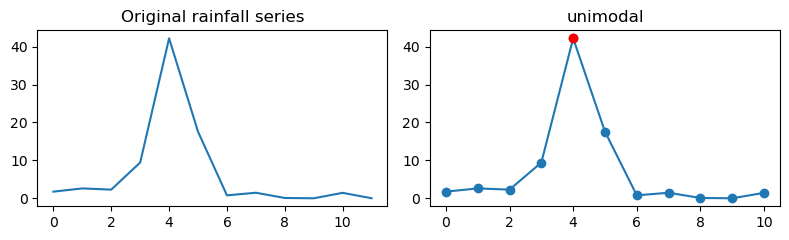

[ 1.2173158  30.98218     0.82967901]
Event index: 7864, result: unimodal, n_peaks: 1


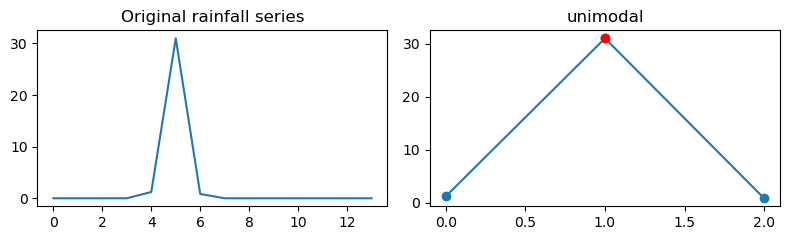

[1.9729480e+00 6.5684419e+00 1.8473333e-01 3.2596659e-02 1.4334174e-01
 8.7730342e-01 2.3456237e+00 3.8853753e-01 1.8066692e+00 3.2965642e-01
 3.8836381e+00 5.5509663e+00 9.4928589e+00 3.4796440e+01 4.9065385e+00
 1.1547216e+00 3.4706295e-01 3.4805214e-01 8.6791672e-02]
Event index: 7872, result: unimodal, n_peaks: 1


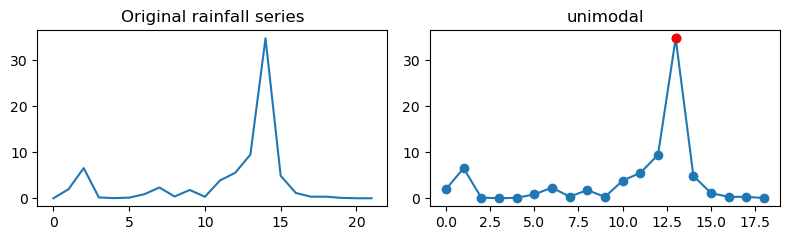

[2.71887946e+00 7.74715602e-01 2.97439837e+00 6.92917013e+00
 2.58247399e+00 7.09234858e+00 5.70456219e+00 1.59372950e+01
 6.69349670e+00 1.34110584e+01 5.96029949e+00 1.33278999e+01
 8.15840626e+00 2.38140082e+00 2.96696358e+01 4.69438286e+01
 2.58691807e+01 1.10310907e+01 1.13842125e+01 7.30631828e+00
 8.92117405e+00 2.14290380e+00 2.18390083e+00 5.82634866e-01
 6.99596703e-02 6.96373824e-03 4.06186678e-04 7.37912059e-02
 9.44410935e-02]
Event index: 7873, result: multimodal, n_peaks: 4


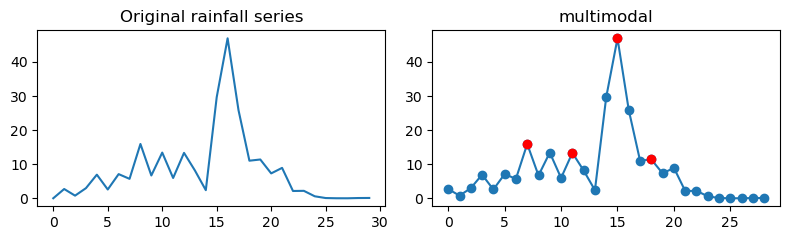

[7.1976565e-02 3.4820092e+00 4.7570891e+00 6.8161373e+00 4.2199740e+00
 4.2455020e+00 8.1742378e-03 1.0287555e-04 1.5115639e-05 3.2500099e-02
 5.9420151e-01 7.5434321e-01 3.9955521e-01 2.7838659e+00 4.4574852e+00
 4.7463322e+00 2.6022096e+00 3.9811990e+00 5.7972932e+00 7.6132321e+00
 4.9123492e+00 4.8715600e-01 1.7378925e-01 6.0496864e+00 5.9448302e-01
 5.0470520e+01 1.3855609e+01 8.8705797e+00 5.7229728e-01 1.1578424e+00
 4.8871560e+00 1.3516016e+00 2.8952194e-02 5.4893351e-01 1.0458016e+01
 1.0470876e+01 7.6443329e+00 1.6568396e+01 4.7557087e+00 1.2707047e+01
 5.4200830e+00 2.5927344e-01 2.6083701e+00 9.3068294e-02 4.6107739e-02
 1.0620152e+00 6.7073691e-01 6.2837440e-01 8.2086687e+00 1.9312455e-01
 2.1753581e+00 2.4825530e-01 9.5227027e-01 1.3883528e-02 1.8711874e-03
 3.0198524e+00 9.6640691e-02 6.8194973e-01 7.2129488e-01 3.1114501e-01
 5.5067115e+00 7.9492673e-02 1.5584458e-01 4.3029222e-06 4.6408677e-06
 2.9062600e+00 1.4786737e+00 2.0060627e-01 1.5741601e-06 2.2957802e-06
 2.982

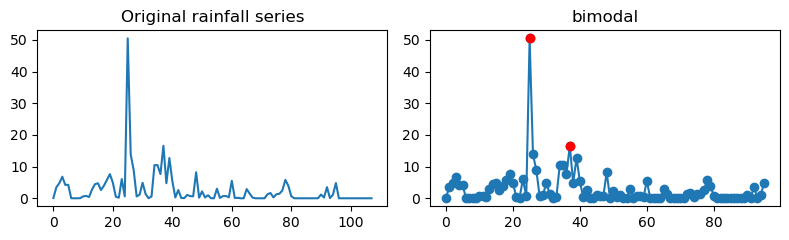

[ 0.58965313  2.6396027   4.1727247  35.220345   12.799121    9.713273
  5.6420269   2.3041325   1.6377575   0.64512378  0.62607235  0.22129978]
Event index: 7904, result: unimodal, n_peaks: 1


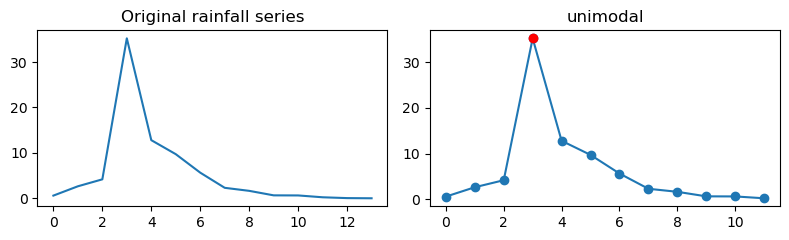

[ 0.19059247  4.7974524  27.323988   37.268925  ]
Event index: 7915, result: unimodal, n_peaks: 1


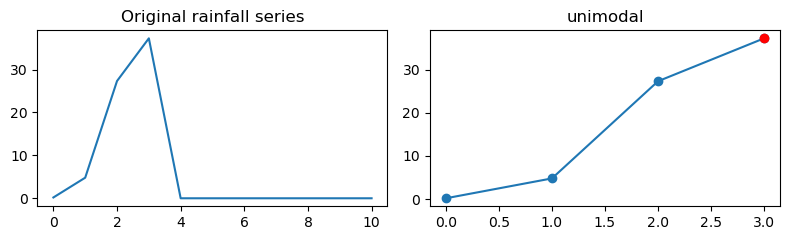

[ 0.71557039 31.591616    0.39484206]
Event index: 7945, result: unimodal, n_peaks: 1


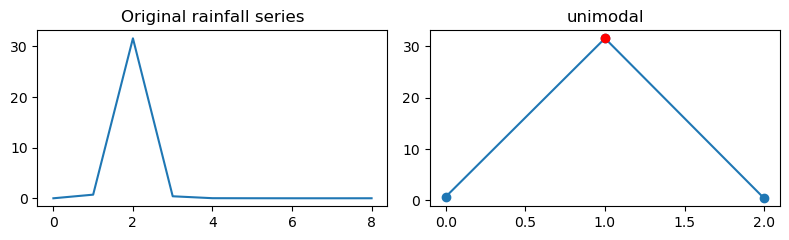

[ 0.3920213 16.556688  34.601692  11.683967 ]
Event index: 7948, result: unimodal, n_peaks: 1


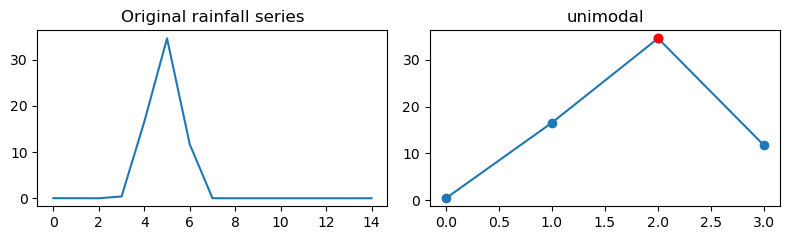

[2.00606251e+01 5.52449465e-01 3.25817941e-03 1.37893414e+00
 4.41034012e+01 2.38895378e+01 1.12063570e+01 1.15074241e+00
 6.11378241e+00 4.24281627e-01 1.30276218e-01 4.56082635e-03
 9.38709054e-05 2.70819637e-05 1.16621250e-05 3.46468255e-06
 4.36805522e-06 4.49082581e-03 6.93387352e-03 3.09034795e-01
 2.05484700e+00 1.78211376e-01 8.37299079e-02 6.73471205e-03
 2.15988718e-02 9.06226709e-02]
Event index: 7956, result: bimodal, n_peaks: 2


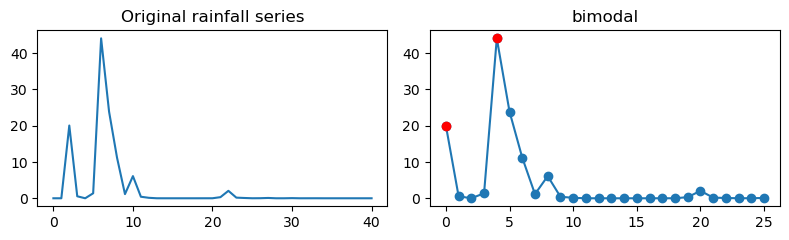

[1.0808147e+00 3.7057224e+01 7.0337014e+00 1.9385738e-02 5.7628765e+00
 8.7878522e-07 1.9095134e-05 9.5721400e-01 3.2028916e-01]
Event index: 7957, result: unimodal, n_peaks: 1


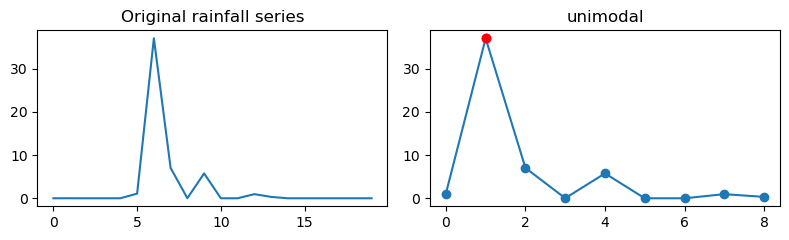

[ 0.22417693 25.013451   66.584045    5.3485308 ]
Event index: 7958, result: unimodal, n_peaks: 1


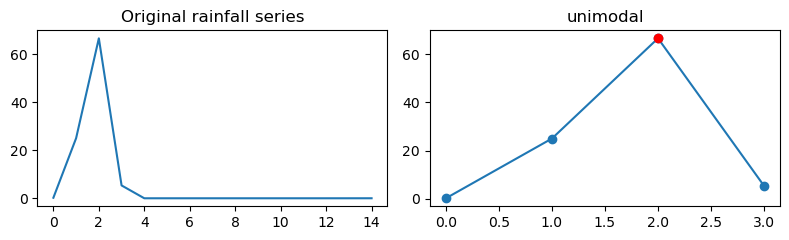

[1.2004822e+00 5.6018895e-01 4.5992903e-02 2.8865309e-03 1.2569355e+00
 1.3893084e-01 4.4817257e+00 3.1056528e+01 3.4149632e-01]
Event index: 7965, result: unimodal, n_peaks: 1


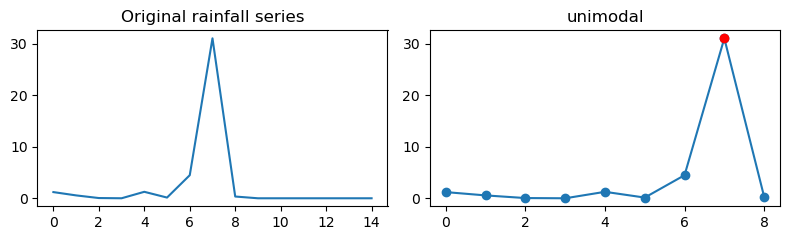

[ 0.62769175  0.89371151  1.3746003   3.4886465   3.3589194   2.1474745
  1.3425572   4.239337   33.18663     8.0107269   0.51748222  0.70797008
  1.0186512   1.2478565   0.98711812  0.17213704]
Event index: 7970, result: unimodal, n_peaks: 1


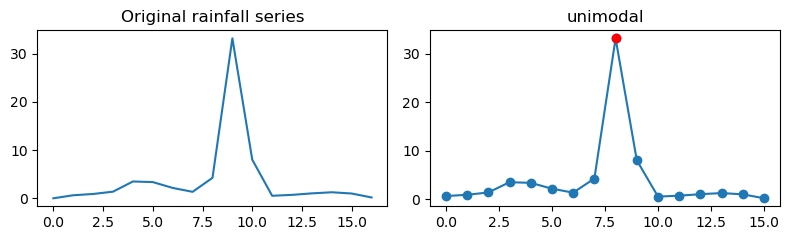

[1.6229729e-01 8.1535983e-01 7.0440049e+00 8.7388697e+00 4.6881776e+00
 4.1256309e+00 4.3597708e+00 3.4692249e+00 2.9351456e+00 2.6203647e+00
 2.6465092e+00 1.9149454e+01 3.2435837e+01 2.0306694e+01 1.8585953e+01
 1.5665004e+01 8.8591728e+00 5.5789037e+00 5.6550007e+00 1.1096273e+01
 1.8324774e+01 1.4342162e+01 1.2254879e+01 4.8060241e+00 3.2931087e+00
 7.7268469e-01 2.8691355e-03 1.6669956e-01 3.7951626e-02 7.4111104e-02]
Event index: 7972, result: bimodal, n_peaks: 2


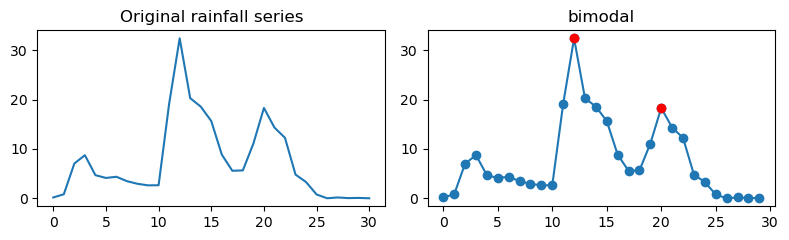

[ 0.68659294  2.6212373  15.952265   31.002026   21.114803   15.190621
  0.63741261  0.05255167]
Event index: 7987, result: unimodal, n_peaks: 1


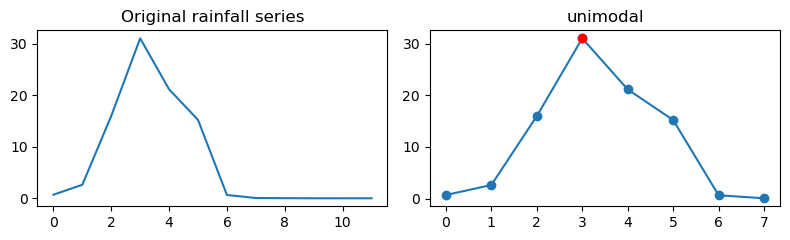

[5.02224267e-02 2.95156407e+00 4.50029194e-01 1.63709804e-01
 5.18558025e+00 3.52477074e+00 2.42396736e+01 3.82853432e+01
 5.70522976e+00 4.03351158e-01 2.35916954e-02 1.29567385e-02
 2.28310164e-05 3.18834046e-03 5.88372409e-01 1.24901116e+00
 3.49766397e+00 6.70753860e+00 3.64225596e-01 2.50933945e-01
 2.15010688e-01 4.90380794e-01 3.46909054e-02 6.53865561e-02]
Event index: 7992, result: unimodal, n_peaks: 1


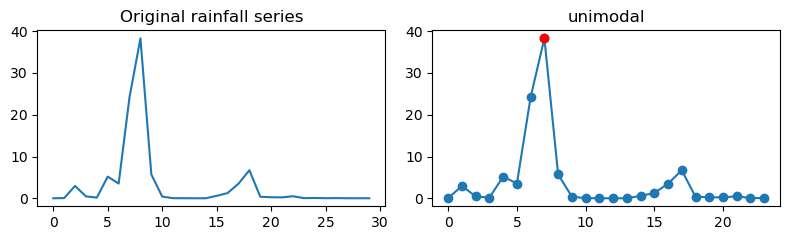

[ 1.7634192  13.089968    6.7437968   7.0727487   5.762814   31.420315
 19.941042   12.226136    8.4498291   5.1972551   3.8824201   3.4790752
  1.4035807   0.40756238]
Event index: 7994, result: bimodal, n_peaks: 2


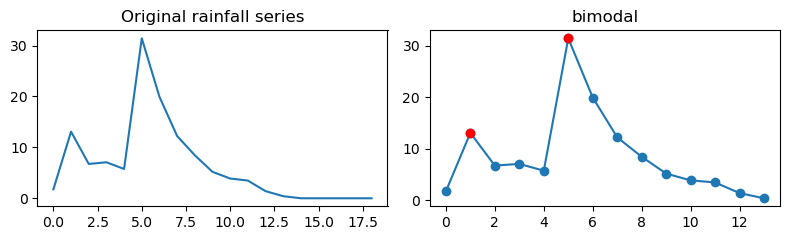

[6.48074090e-01 1.77393925e+00 3.18742728e+00 1.42424593e+01
 2.63338876e+00 3.94897056e+00 5.53683090e+00 3.56428242e+00
 3.51429224e+00 3.78889108e+00 4.65606403e+00 2.16665077e+00
 1.52788913e+00 1.88799727e+00 5.99764490e+00 5.68303967e+00
 7.68077421e+00 8.80264568e+00 5.10137939e+00 1.54116929e+00
 1.37695992e+00 1.46348596e+00 5.42882462e+01 6.32693596e+01
 4.47911491e+01 8.42827916e-01 1.35579967e+00 1.24425507e+01
 1.59866705e+01 8.02196121e+00 1.74175608e+00 1.82397985e+00
 5.60909748e-01 1.73108983e+00 4.00973034e+00 1.41875887e+01
 3.65453172e+00 6.65263987e+00 2.10888100e+01 5.11827374e+00
 9.03824449e-01 3.29682231e-02 7.11381028e-04 2.83601950e-03
 5.56558847e-01 4.77981418e-01]
Event index: 7997, result: multimodal, n_peaks: 5


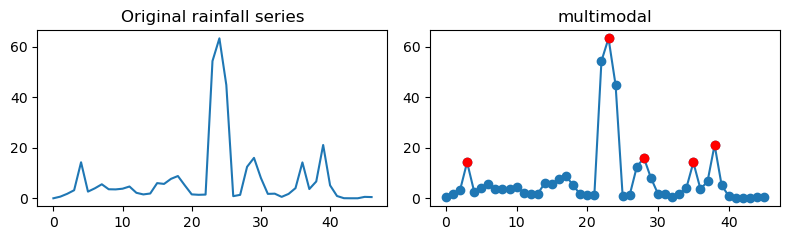

[ 2.6939826  13.121192   22.009193   41.658699    7.3243413   2.5831168
  2.6013842   0.86743438  0.10473999]
Event index: 8002, result: unimodal, n_peaks: 1


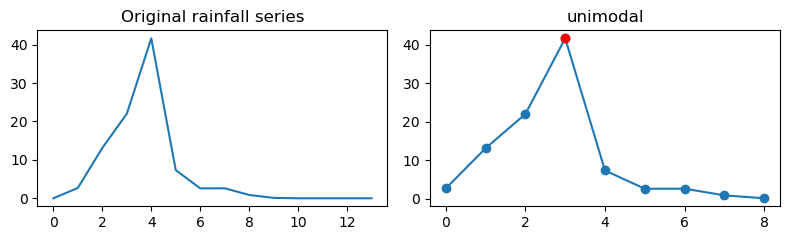

[8.50392699e-01 1.20513272e+00 1.10539043e+00 3.08861709e+00
 3.28746080e+00 3.37334871e-01 2.77374506e-01 2.28348494e-01
 4.33622122e-01 8.13752777e-05 2.83532679e-01 7.67079258e+00
 2.12177372e+00 5.74952923e-02 3.54432716e+01]
Event index: 8029, result: unimodal, n_peaks: 1


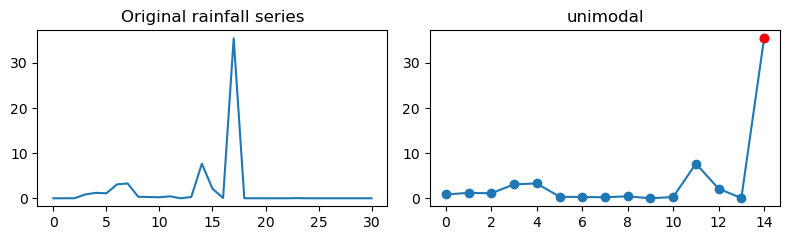

[ 8.0223417 31.387285   7.9878225]
Event index: 8098, result: unimodal, n_peaks: 1


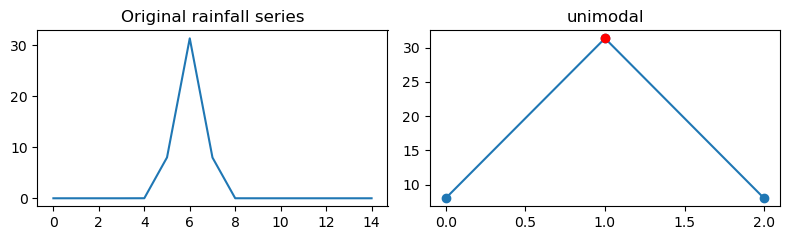

[15.041047  29.588425  33.98365    1.0316044]
Event index: 8127, result: unimodal, n_peaks: 1


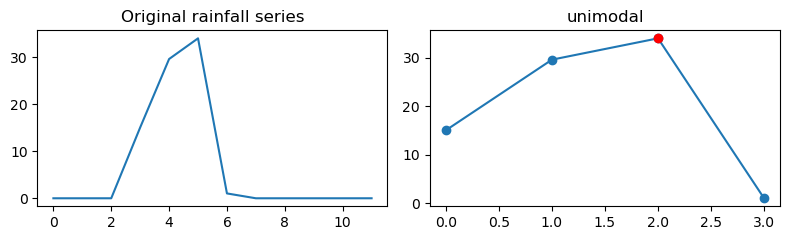

[ 0.2065042   0.46711901  0.66253906 36.23819     4.3879819   0.62138075
 12.105186   10.463385    1.7069839 ]
Event index: 8142, result: bimodal, n_peaks: 2


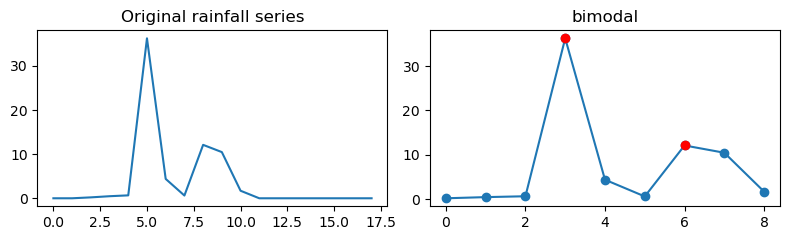

[3.2732605e+01 2.4116442e+01 2.3520878e+01 4.6297135e+00 8.6923074e-03
 4.7100807e-06 4.2900292e-06 9.1940428e-06 7.3972928e-06 5.9065782e-02]
Event index: 8143, result: unimodal, n_peaks: 1


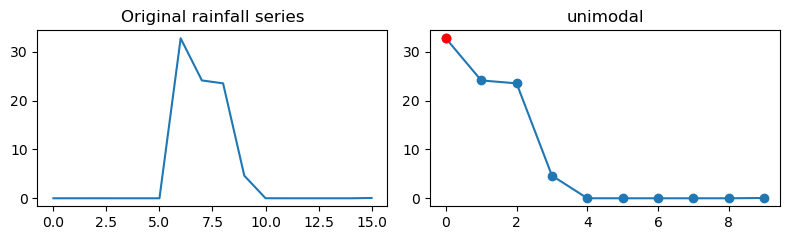

[2.2602171e-01 5.8576455e+00 6.0437105e-06 2.0018697e+00 3.1228075e+01
 4.3028536e+00 5.7420464e+00]
Event index: 8161, result: unimodal, n_peaks: 1


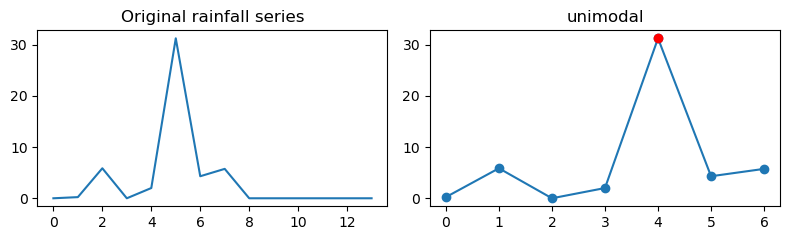

[8.34558159e-02 1.11518574e+00 1.27776170e+00 8.55628178e-02
 1.28595471e+00 1.20740676e+00 3.10264564e+00 2.88565445e+00
 2.39531800e-01 6.51120782e-01 9.19257198e-03 1.84864223e+00
 9.03665274e-02 2.70075429e-06 3.06447782e-06 1.82695862e-06
 1.16723881e+01 2.05247894e-01 7.02685937e-02 1.27085659e-05
 1.52946916e-06 2.65485615e-01 1.22011025e-02 4.45321211e-06
 1.42010868e-01 6.89538836e-01 5.75813428e-02 2.12225363e-01
 6.67833424e+00 6.24888277e+00 1.02859385e-01 5.61233843e-03
 6.39519189e-03 8.01064726e-03 9.60575603e-03 2.35305075e-03
 1.20088842e-03 7.57481158e-01 3.76457100e+01 1.64901829e+01
 4.38346910e+00 5.02058840e+00 4.26990867e-01 2.69081420e-03
 3.27214715e-04 5.61929820e-03 1.96250781e-01 5.38045824e-01
 2.37897232e-01 3.24117243e-01 5.82670808e-01 1.04752290e+00
 1.82370603e-01 3.66807550e-01 1.11067247e+00 2.60115620e-02
 9.56208169e-05 1.02505740e-03 2.11580586e+00 1.55305497e-06
 2.65217930e-01 6.30204320e-01 4.93662842e-02 2.75543958e-01
 1.07657826e+00 2.266855

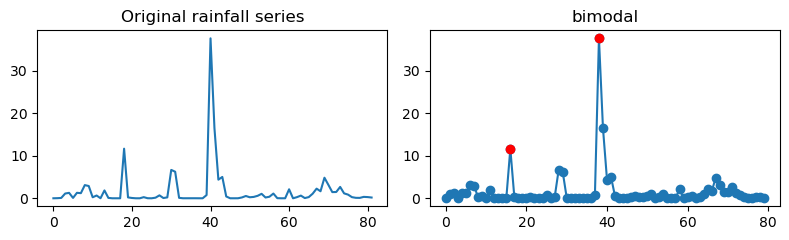

[45.671543   30.619768    0.81978494]
Event index: 8182, result: unimodal, n_peaks: 1


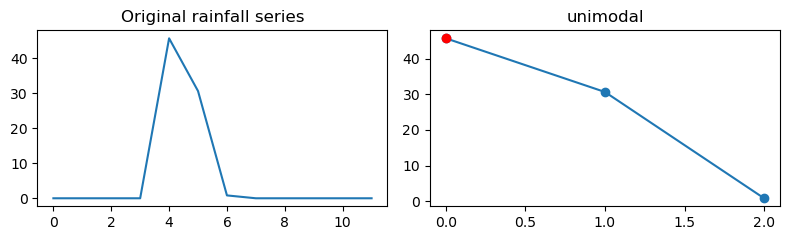

[ 1.1267393  30.113178    6.6807804   0.06087957  0.46023604  0.51328707
  0.05948382]
Event index: 8192, result: unimodal, n_peaks: 1


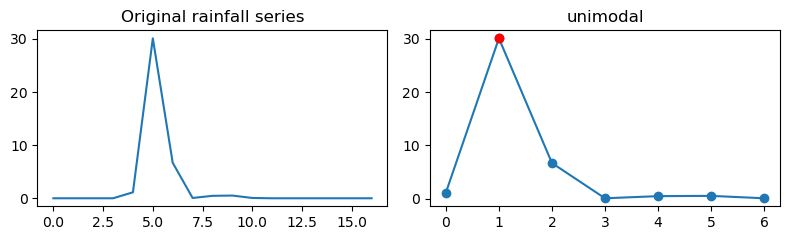

[3.71553123e-01 5.80166874e-04 1.67759492e-06 5.11030930e-06
 8.74247849e-01 3.21657270e-01 2.37741973e-03 5.28716519e-02
 9.15676169e-03 2.30137800e-07 1.14646411e-06 1.94498921e-06
 4.80510171e-05 1.12398516e-06 4.59297007e-05 3.83800289e-05
 7.92365172e-05 2.41897051e-05 2.15671098e-05 4.50163018e-09
 1.87599198e-05 5.28403098e-06 2.21333848e-05 4.11581677e-05
 4.75843408e-05 5.86101705e-05 3.07416210e+01 1.04809915e-04
 6.67920685e-05 9.01829262e-05 6.95828259e-01]
Event index: 8203, result: unimodal, n_peaks: 1


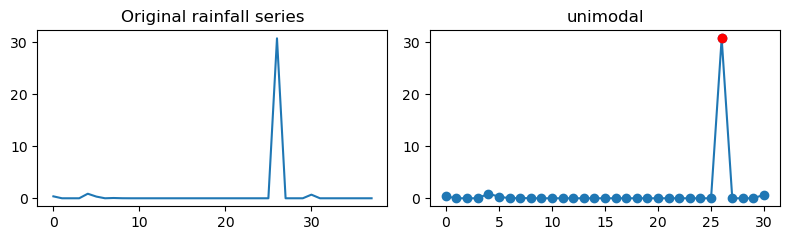

[ 0.06300442  1.6171498  30.419025    0.43336719]
Event index: 8230, result: unimodal, n_peaks: 1


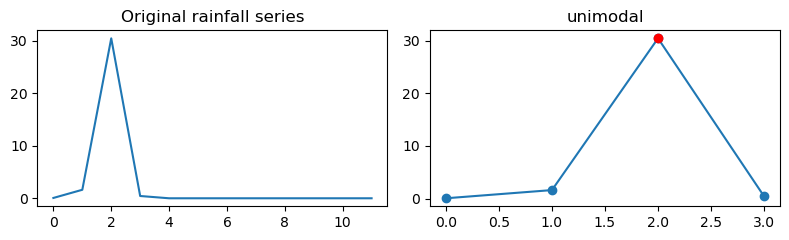

[6.0314810e-01 1.6593142e+01 2.8211622e+00 1.5219896e-01 2.3677630e-02
 2.0960637e-04 2.8089281e-02 1.6345859e+00 1.8528043e+00 6.1366572e+00
 6.7412457e+00 3.5421947e+01 1.2996548e+01 5.0659442e+00 3.2625964e+00
 6.2490368e+00 3.7663045e+00]
Event index: 8237, result: bimodal, n_peaks: 2


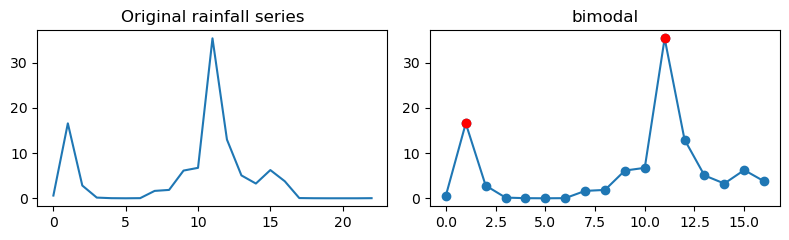

[ 6.9053149 45.226654   3.8293657  1.2207211]
Event index: 8239, result: unimodal, n_peaks: 1


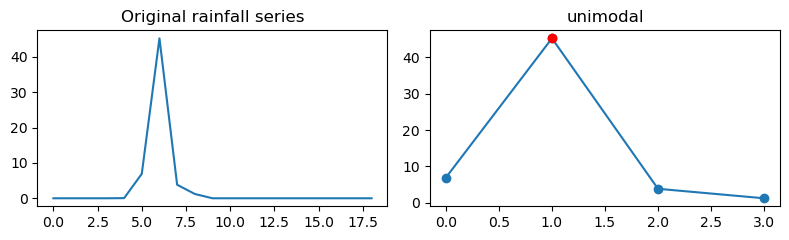

[2.20289183e+00 7.00579309e+00 2.97337365e+00 3.40659332e+01
 1.54238218e-03 2.61168298e-05 6.55908252e-06 1.09747753e-05
 5.31823171e-05 1.41102976e-06 1.64293851e-06 2.03469108e-06
 4.69992161e-01 1.05925845e-02 3.33677826e-06 3.95605348e-05
 3.01780879e-01 3.22910346e-05 2.18450214e-06 1.46223954e-06
 4.50252369e-02 3.72663110e-01 1.12043247e-01 1.33506656e-01
 3.97279263e-02 9.80380630e+00 2.42149687e+00 7.50198245e-01
 1.71159297e-01 5.55828214e-03 2.91760349e+00 2.87857866e+00
 1.62324309e-01 1.53209239e-01 2.28669410e-06 8.15055973e-05
 2.13954782e+00 1.25002407e-06 3.56620401e-01 4.67304182e+00
 4.43068123e+00]
Event index: 8268, result: unimodal, n_peaks: 1


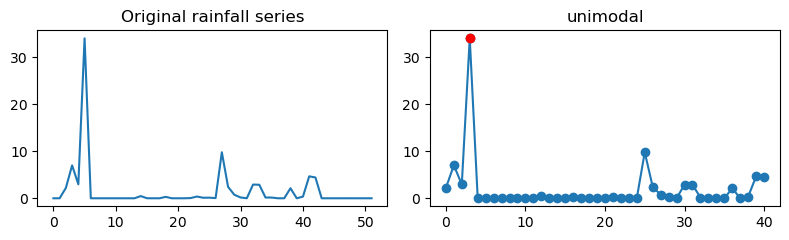

[14.346864  30.588043  13.050246   1.1691085]
Event index: 8269, result: unimodal, n_peaks: 1


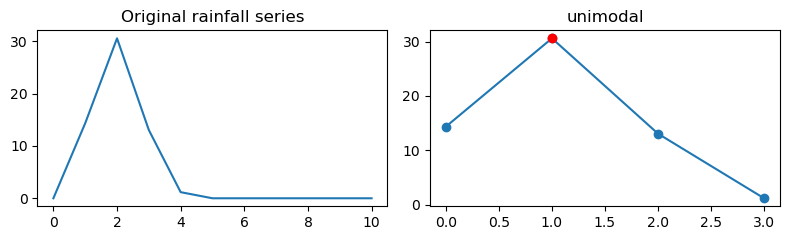

[8.9011496e-01 3.0777618e+01 1.9228520e+00 3.4259979e-02 9.1067704e-07
 3.4314030e-06 8.8968181e-06 3.6892596e-01]
Event index: 8276, result: unimodal, n_peaks: 1


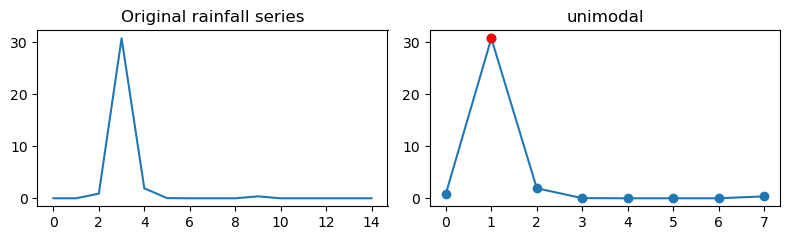

[1.9163736e+00 8.0838958e-03 1.1962481e-02 1.7223948e+01 1.5981954e-01
 3.2377198e+00 6.5106102e+01 1.9035645e+01]
Event index: 8281, result: bimodal, n_peaks: 2


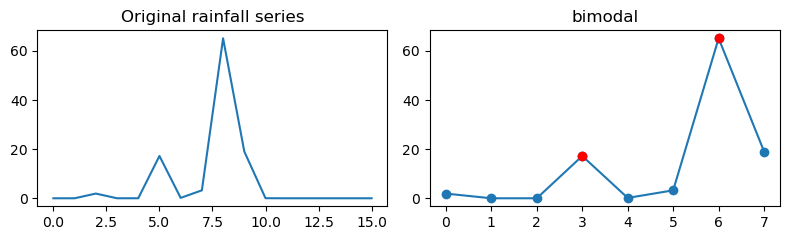

[ 0.74916786  3.962014   10.639118   30.287672   22.762341   21.070343
 14.346207    6.7924042   3.7559872   2.0725148   1.0793645   0.85138535
  0.35404325  0.09602497]
Event index: 8308, result: unimodal, n_peaks: 1


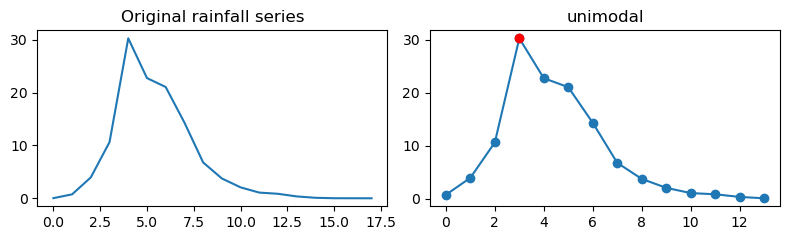

[ 0.24748456 22.214182   30.924049    6.1668496   1.6826202   0.2563563 ]
Event index: 8316, result: unimodal, n_peaks: 1


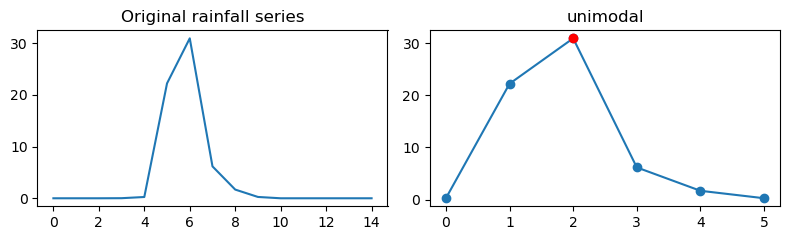

[ 0.99251252 25.316156   38.451389   18.253292   12.066957    4.7028952
  3.0059166   0.58608544  0.0802517 ]
Event index: 8353, result: unimodal, n_peaks: 1


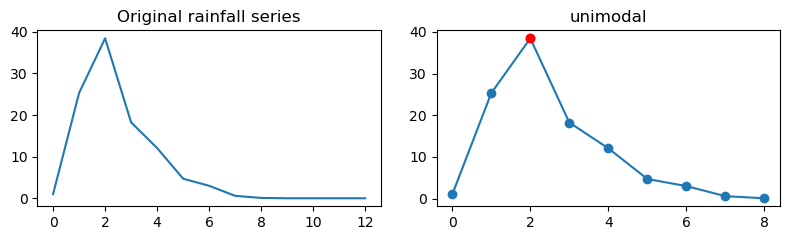

[6.0472804e-01 1.2156465e+00 4.2235252e-01 6.2328076e-04 1.3964246e-01
 7.1573362e-05 2.7736887e-01 1.6689229e+00 4.8384268e-02 1.4741542e-05
 2.5254247e-05 3.6227229e-05 1.4030667e-04 7.1366155e-04 1.3421482e-05
 2.1162724e-01 6.7229038e-01 1.5038770e+00 2.7427738e-04 1.9829889e-01
 2.9026182e+00 5.8105378e+00 5.9427514e+00 5.3771586e+00 6.5900655e+00
 8.0601721e+00 1.2085047e+01 3.1582870e+01 1.6169682e+01 1.0338647e+01
 8.3571625e+00 3.6819415e+00 7.1561736e-01 9.9533987e-01 6.0112250e-01
 1.6616268e-01 1.0667392e-03 5.1812336e-02]
Event index: 8366, result: unimodal, n_peaks: 1


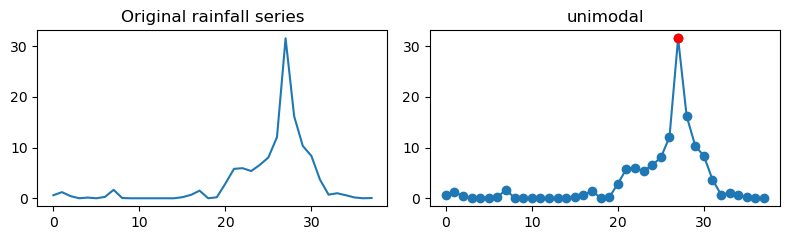

[ 0.26632333  0.6966898   3.566359    3.5295432   2.3427434   7.105056
  4.468021    2.8309078   1.9309545   0.74811405  0.12460746  0.40738362
  3.32945     2.3752398   5.1399508   7.0185633  20.324718   33.897633
 17.192871    5.163213    4.3756113   1.1093216   0.3394281   0.3987436
  0.6035697   0.17901058  0.10349175]
Event index: 8392, result: unimodal, n_peaks: 1


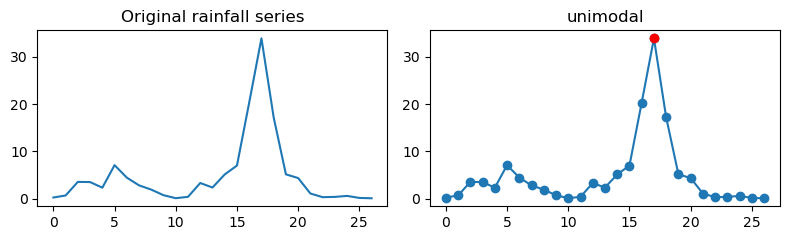

[1.2887564e+00 1.4766963e+00 1.8605623e-01 3.3856526e-01 1.7970731e+00
 2.8084517e+00 3.6164448e-01 1.2246815e-01 8.2364446e-01 1.7343130e+01
 1.8521904e+00 7.1248633e-01 6.4514834e-03 3.3145199e+01 6.6993451e+00
 2.0868883e+00 4.2597467e-01 2.3129241e-01 1.2384474e-05 2.8410056e+00
 1.6795164e-01 6.4475155e-01 1.1430926e+00 4.2278318e+00 5.9146600e+00
 1.2961575e-01 6.8238728e-06 1.6805954e-01 1.2005901e-05 4.1020375e-02
 6.0635289e-06 1.2060839e+00]
Event index: 8406, result: bimodal, n_peaks: 2


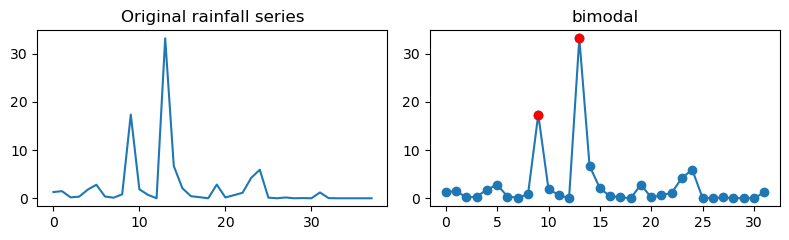

[3.16187477e+01 4.44834173e-01 2.48369732e+01 8.51130486e+00
 5.47122490e-03 4.58157599e-01 7.40830243e-01 1.80530047e+00
 8.11484680e-02 5.38480526e-04 3.34327370e-01 1.07202601e+00
 1.23999416e-04 1.51211780e-05 1.76977107e-06 2.19840693e+00
 3.60477041e-03 1.17048021e-05 1.09404270e-02 1.88828085e-06
 2.66656230e-06 4.13582288e-03 9.40903008e-01 1.17638626e-03
 2.90460046e-03 4.53382700e-06 5.79320155e-02 5.81715867e-05
 1.40283155e+00 3.47159529e+00 3.65662837e+00 6.16589308e+00
 2.88026571e+00 1.40981114e+00 8.21911275e-01 3.42871875e-01
 8.39703679e-01 2.36636662e+00 3.41181993e+00 4.95474958e+00
 8.90449238e+00 1.66500263e+01 6.53820324e+00 7.01653481e+00
 4.04281664e+00 5.42450809e+00 1.18752159e-01 2.35693660e-05
 1.95303015e-04 4.27606493e-01]
Event index: 8421, result: multimodal, n_peaks: 3


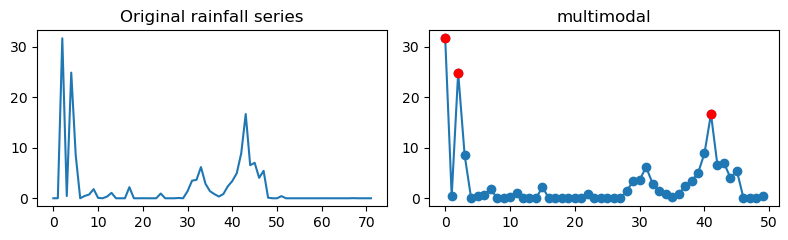

[ 1.0699074   0.50945288  1.1510165   0.44202134  0.1539824   0.22035635
  0.13895302  0.33243722  0.723185    8.0090427  17.108446   31.331915
 15.141869    3.811563    1.9752995   0.95714557  0.83493048  1.9376433
  2.8081009   7.6976643   8.5065899   5.046299    2.326055    1.0929433
  0.74898678  1.0530456   0.69117749  2.1881151  11.447197    1.101999
  0.20595634]
Event index: 8430, result: bimodal, n_peaks: 2


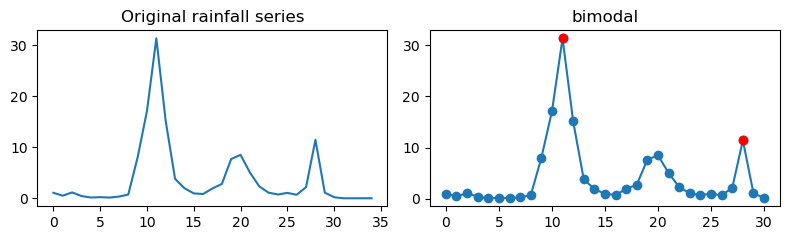

[ 1.0317166   5.1437478   0.50679374  4.3826604  32.592667   12.186289
  4.5236831   5.850544    4.7816219   1.4371666 ]
Event index: 8462, result: unimodal, n_peaks: 1


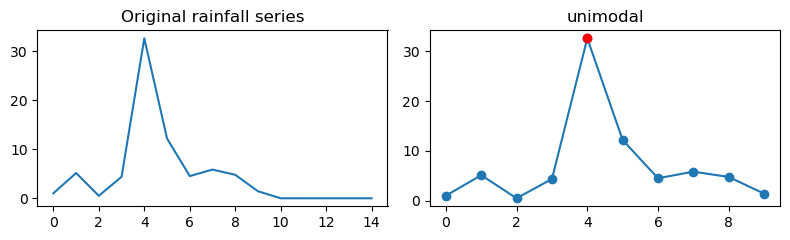

[ 0.90663689  1.5128558   0.9624539   0.60538554  0.33732891  0.4027867
  1.116239    2.0516019   2.9225099   4.3000035  14.426467    5.5550666
 15.599835   33.17379    28.133841   16.46307    12.148197    5.394609
  5.5824327   3.9277363   1.7960217   0.89132893  0.1109797 ]
Event index: 8478, result: bimodal, n_peaks: 2


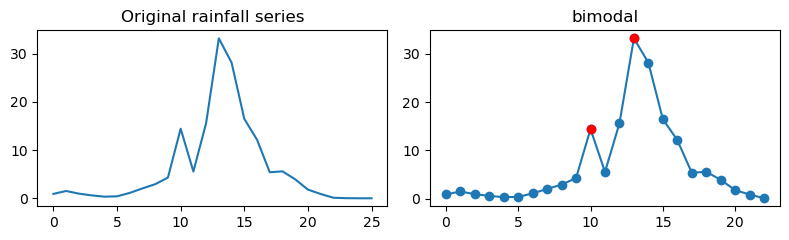

[4.16889114e+01 2.19237995e+01 7.69666687e-04 1.29873715e-05
 1.41301496e-06 3.81552488e-01 5.35478973e+00 5.89649737e-01]
Event index: 8480, result: unimodal, n_peaks: 1


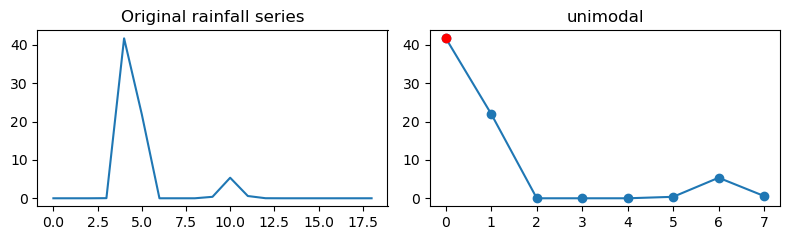

[2.6293844e-01 1.0262875e+01 2.4875321e+00 4.8187361e+00 4.1168803e-01
 2.7237753e-03 6.3213645e-03 1.3157205e-01 2.0546732e+00 1.0073541e+01
 4.5348144e+00 4.9546368e-02 4.0877426e-06 1.1903343e-05 2.7903804e-01
 7.8553662e-02 1.8451400e+00 9.0320797e+00 6.0580745e+00 1.4327627e+00
 1.2422559e+00 6.1092421e-02 8.0601919e-01 2.5906399e-01 2.2508293e-01
 5.8715399e-02 6.4427326e-07 1.8882501e+00 8.9356012e+00 3.0492729e-01
 1.1571976e-04 1.9634631e-01 4.7026000e+00 3.1556902e+01 6.2449903e+00
 5.3565267e-02 8.6022562e-01 4.5062656e+00 6.8672311e-01]
Event index: 8481, result: multimodal, n_peaks: 3


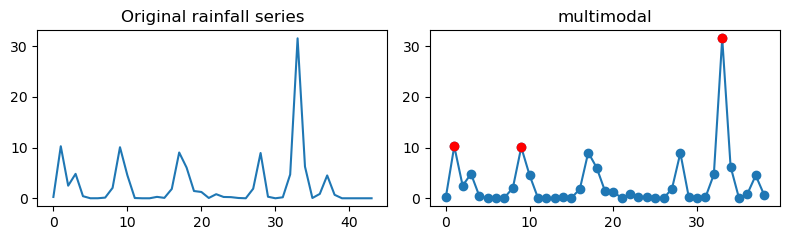

[1.07686532e+00 1.19331999e+01 3.39479256e+01 2.13386607e+00
 7.45990276e-02 9.53548413e-04 2.38385510e+00 1.41457975e-01
 2.14363390e-04 3.15549135e-01 1.68484841e-02 6.80106804e-02
 8.70359719e-01 5.88808653e-05 3.33158205e-05 2.81840016e-06
 3.70131493e-01 1.11563281e-06 1.89203195e-06 4.31498289e-01
 9.67030942e-01 2.63391644e-01 1.09482996e-01]
Event index: 8544, result: unimodal, n_peaks: 1


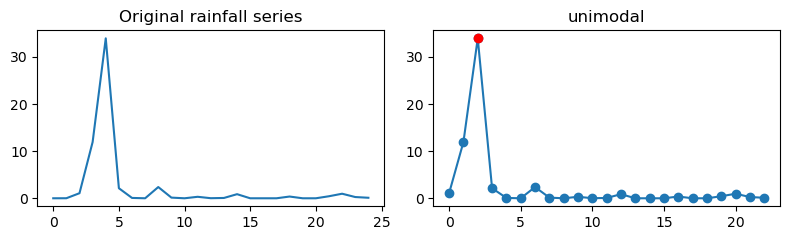

[9.0281725e+00 4.7067627e+01 1.0215897e+01 1.8932049e+00 2.8088756e+00
 1.7017117e-01 3.8730651e-01 2.6796833e-02 1.0061874e+00]
Event index: 8550, result: unimodal, n_peaks: 1


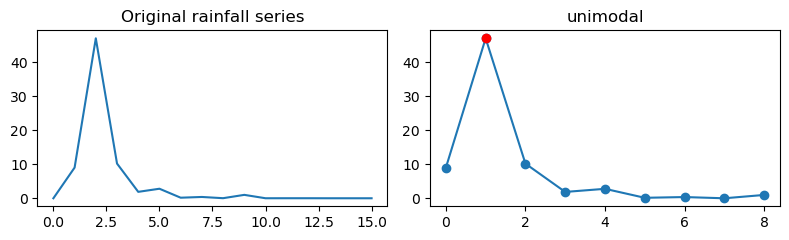

[6.4347541e-01 1.9936750e+00 9.0395460e+00 8.2051516e+00 9.1899986e+00
 2.2641747e+01 1.7629734e+01 4.3061245e+01 2.9834505e+01 9.4553738e+00
 5.1367879e+00 1.9226730e+00 5.4932660e-01 5.0100327e-01 1.9268176e-02
 4.4565368e-04 6.4033560e-02]
Event index: 8552, result: unimodal, n_peaks: 1


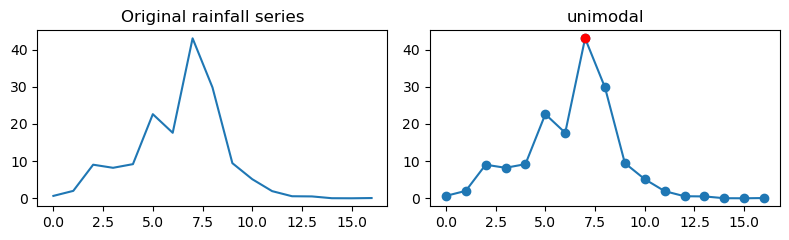

[4.0612121e+00 1.2670672e+01 6.4726562e+00 1.2425234e+00 2.4032950e+00
 1.6895094e+00 1.3840955e+00 8.7617511e-01 8.6188525e-01 8.5230196e-01
 2.7280908e+00 4.7568924e+01 8.8469782e+00 1.2623297e+00 9.6381140e+00
 8.0912983e-01 1.3718968e+01 2.6433159e+01 3.1775787e+01 1.6225798e+01
 1.9701834e+01 2.5440395e+01 3.5071697e+01 1.6899855e+01 5.4403815e+00
 3.5766780e+00 4.0556216e+00 4.3114047e+00 1.6644737e+00 7.4593721e-05
 6.0980386e-05 3.2635957e-01 4.8177586e+00 4.5588058e-01 1.0486895e+00
 7.2435451e-01 4.5453575e-02 4.4938397e-01 5.2973169e-01 9.1195921e-04
 8.9561552e-02 4.8064229e-01]
Event index: 8553, result: multimodal, n_peaks: 4


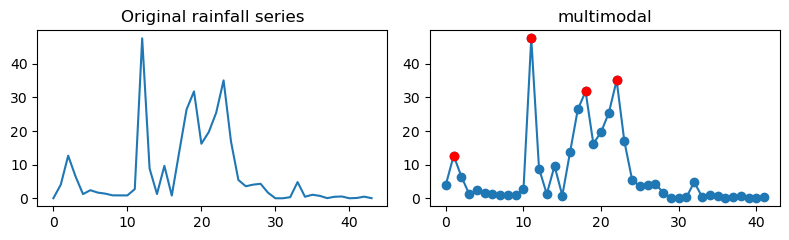

[3.9858556e-01 2.5766385e+00 1.2417463e-06 3.2688808e-06 1.8759526e-06
 1.7319041e-01 1.5318595e+00 1.6672827e-01 3.4356120e-01 2.5140755e-06
 2.7389030e-06 3.2483531e-06 2.8636532e-06 3.1984489e-06 1.7249110e-01
 2.1721346e+00 2.8805153e+00 4.7757001e+00 8.9955111e+00 5.5012827e+00
 1.7252056e+01 2.1559488e+01 3.5283707e+01 4.2107643e+01 2.3398605e+01
 6.1074810e+00 8.9687386e+00 1.5906311e+01 1.6512995e+00 1.3544205e+00
 8.7452400e-01 1.4244306e-02 8.3475952e-06 5.3971691e+00 1.7485985e+00
 2.2901161e-01 2.0988928e-06 6.1002934e-01 5.7129340e+00 6.5978122e+00
 1.3939781e+00 2.0177118e-02 2.8514588e+00 2.9578631e+00 6.5911207e-03
 9.4253302e-01 1.0230911e+00 1.2789612e+00 5.9985554e-01 2.0167348e-05
 2.0057626e-06 4.7748119e-01]
Event index: 8554, result: bimodal, n_peaks: 2


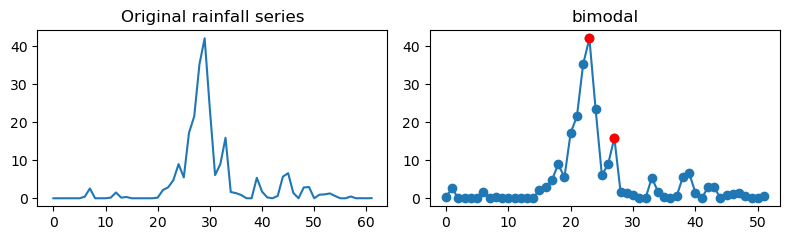

[5.24845064e-01 3.16063023e+00 1.02854338e+01 1.89424820e+01
 3.23774490e+01 2.28965435e+01 1.45324020e+01 7.81902456e+00
 5.66233635e+00 4.98538828e+00 3.27466822e+00 2.66947246e+00
 2.24931097e+00 2.18748188e+00 2.18650937e+00 1.14213924e+01
 1.02586145e+01 6.51072359e+00 8.03262138e+00 1.00087185e+01
 9.28762150e+00 8.10854912e+00 6.28731728e+00 5.05176210e+00
 1.16338134e+00 5.02666771e-01 1.18019307e-05 2.27046462e-06
 1.17306911e-06 1.37299980e-06 3.38117301e-01]
Event index: 8555, result: multimodal, n_peaks: 3


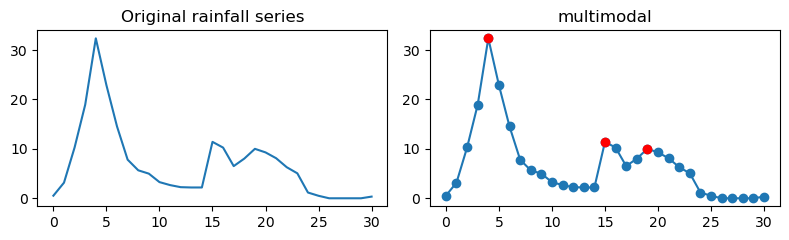

[ 0.5823682  17.870575   30.41535     0.37015221]
Event index: 8570, result: unimodal, n_peaks: 1


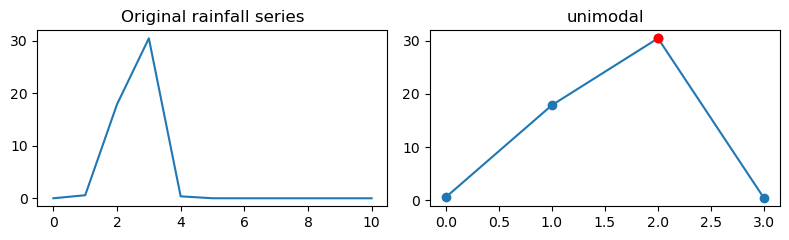

[4.0917727e-01 3.5873611e+00 8.3605361e-01 2.9516183e-03 2.9402287e+00
 4.0965009e-02 1.3706461e+00 7.6663546e-02 1.7333815e-02 7.7226377e-01
 6.6971472e-03 3.3310157e-01 2.0034349e+00 4.6970820e+00 3.8182974e+00
 1.5841477e+00 3.6397907e-01 3.7190791e-02 4.7818866e+00 3.0787766e+00
 5.7072625e-02 6.2659578e-06 1.3259118e+00 6.7280636e+00 4.0441769e-01
 3.1467905e+00 2.0718749e-01 1.2719624e+00 4.1311393e+00 7.1328754e+00
 1.2110455e+01 1.5761136e+01 1.3106313e+01 1.5555405e+01 2.6168146e+01
 3.1445808e+01 2.1058165e+01 1.5043734e+01 1.9996305e+01 2.0406557e+01
 2.2018557e+01 2.0836037e+01 1.4409764e+01 7.1471200e+00 8.9476948e+00
 1.1088576e+01 1.0172551e+01 9.7207556e+00 7.6522980e+00 4.3918829e+00
 7.3815002e+00 2.8610301e+00 2.7090685e+00 2.2223158e+00 3.0745494e+00
 4.7318497e+00 6.4684758e+00 4.5365176e+00 1.5471960e+00 2.6677277e+00
 4.9847081e-01]
Event index: 8572, result: multimodal, n_peaks: 4


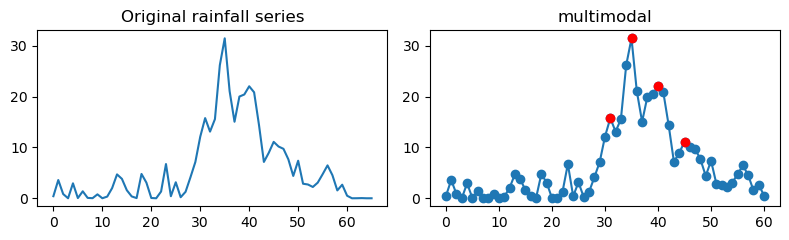

[1.7071950e+00 9.2462873e+00 8.7539454e+00 4.7667069e+00 1.9164705e-01
 3.5964581e+01 5.6342268e+00 2.0361839e-02 6.0059154e-01]
Event index: 8580, result: unimodal, n_peaks: 1


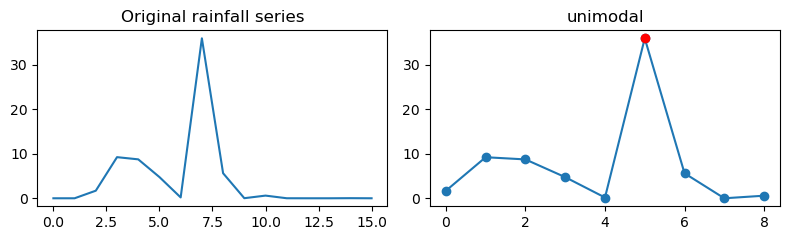

[ 0.87118053  2.068922    2.0123436   0.37501073  0.64062864  0.74350899
  1.2173562   1.9975855   5.9314232   6.1144271   8.204648   25.334782
 11.880492   10.043797    3.8677275   3.7756131   2.7263386   3.4760315
  1.4566987   1.0885299   1.6475542   5.4119196  34.265133   38.642899
 11.995586    7.963273   10.138736   27.712505   21.119692   22.056047
  7.5579071  32.802326   13.119597    3.2909002   4.405838    3.7544084
  1.5503006   0.7956022   0.07665564  0.15526101]
Event index: 8582, result: multimodal, n_peaks: 4


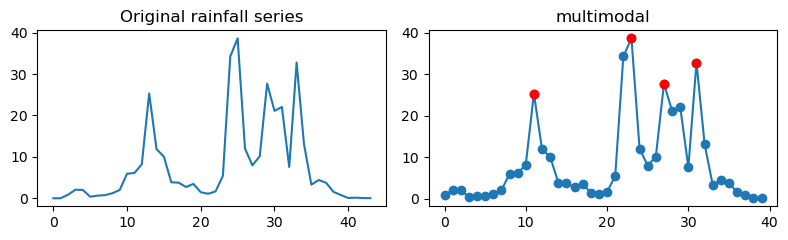

[13.949632  33.416264   4.5967588]
Event index: 8591, result: unimodal, n_peaks: 1


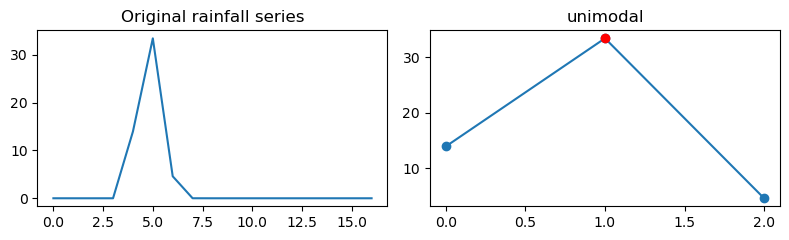

[ 4.7326889 40.352108  26.740801   3.5158741]
Event index: 8593, result: unimodal, n_peaks: 1


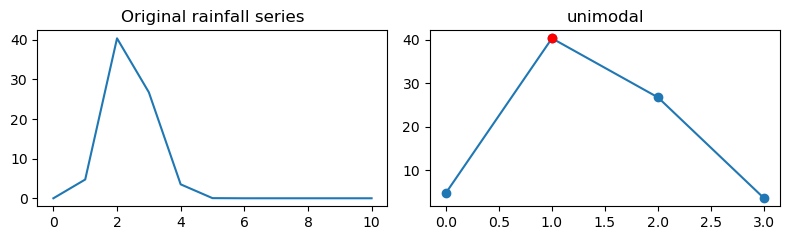

[ 0.32408682  8.0059452  75.455727    5.956646    2.993597  ]
Event index: 8595, result: unimodal, n_peaks: 1


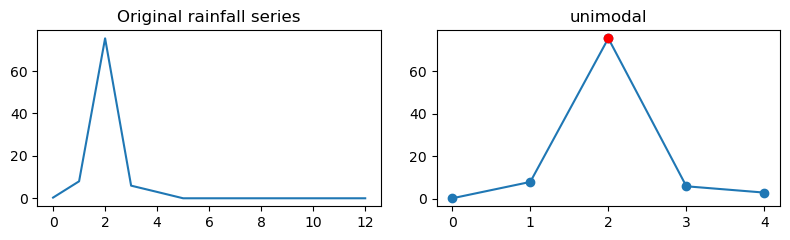

[1.6564062e-01 4.4238815e+01 7.7068138e-01 2.9115295e-03 3.3573024e-02
 5.2913982e-01]
Event index: 8596, result: unimodal, n_peaks: 1


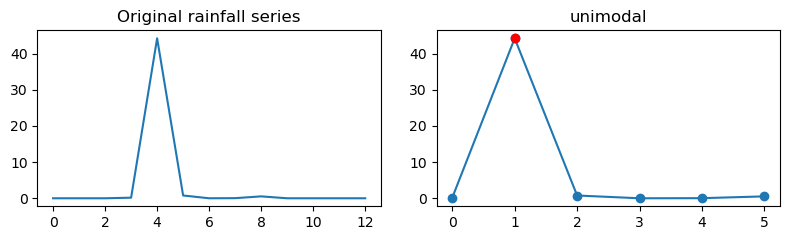

[5.48504412e-01 1.28102601e+00 3.27651525e+00 4.76539040e+00
 1.13546133e+00 8.01990151e-01 7.69425631e-01 1.40615070e+00
 1.20196569e+00 9.17353034e-01 9.22710121e-01 2.56756639e+00
 1.59364438e+00 1.64710653e+00 1.26503563e+00 8.58152747e-01
 7.49321222e-01 1.05708230e+00 2.35074863e-01 3.97628874e-01
 1.21078339e+01 5.86610317e+00 3.95123138e+01 7.17974424e+00
 3.42929065e-01 1.65178478e-01 6.73351996e-03 2.89660394e-01
 1.85333788e-01 2.44585890e-02 2.28875615e-02 2.68819073e-04
 2.03659192e-06 3.67070015e-06 7.68967748e-01 1.94127541e-02
 8.33505112e-07 9.46172236e-07 2.19816637e+00 4.87896986e-03
 1.00363925e-01 8.50982417e-07 1.02267586e-01 1.27714488e-03
 2.87907524e-03 5.11843972e-02 1.07444274e+00 3.57188642e-01
 2.57654581e-03 1.69578478e-01 1.34355563e-03 2.31476020e-06
 8.89209449e-01 1.06025040e+00 3.45387184e-06 6.56025850e-06
 2.01617111e-03 8.49940625e-06 3.48522335e-01 3.62182260e-01]
Event index: 8599, result: unimodal, n_peaks: 1


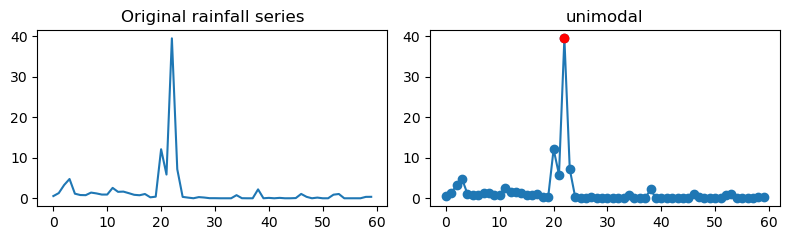

[6.2734157e-01 8.8263102e+00 1.3386939e-01 3.3235698e-04 3.4729652e-05
 1.8556763e+00 3.0311322e-01 3.1071302e+01 1.0489754e+01]
Event index: 8605, result: unimodal, n_peaks: 1


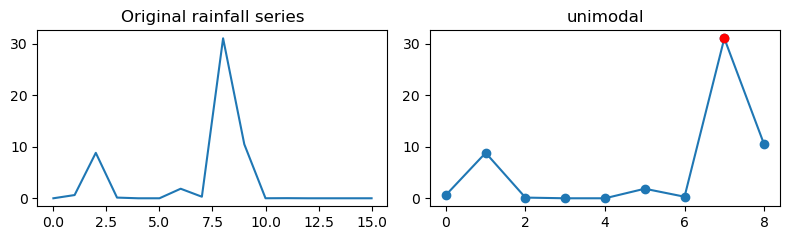

[3.51233387e+00 5.11976585e+01 3.60292969e+01 1.09229708e+01
 3.67464721e-01 2.25289000e-06 3.50153914e-06 2.05130830e-01
 2.73134653e-02 8.37428146e-04 7.26410690e-06 8.11278880e-01
 6.93943858e-01 1.20044075e-01]
Event index: 8609, result: unimodal, n_peaks: 1


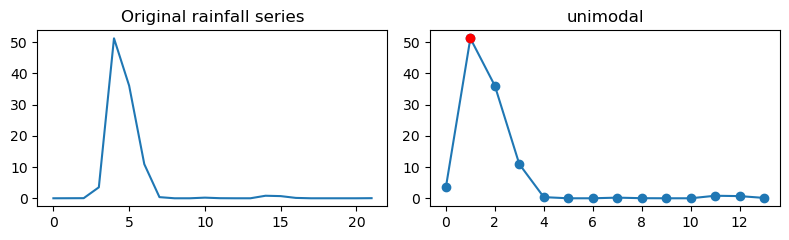

[ 3.0786116  40.91608    22.041447    3.8066492   0.16088255]
Event index: 8631, result: unimodal, n_peaks: 1


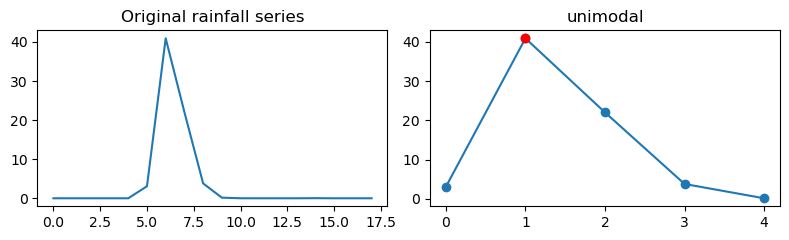

[6.9835156e-01 7.2011971e-03 1.0981955e+01 2.2117958e+01 4.6979366e+01
 2.1204596e+01 1.8822031e-01]
Event index: 8710, result: unimodal, n_peaks: 1


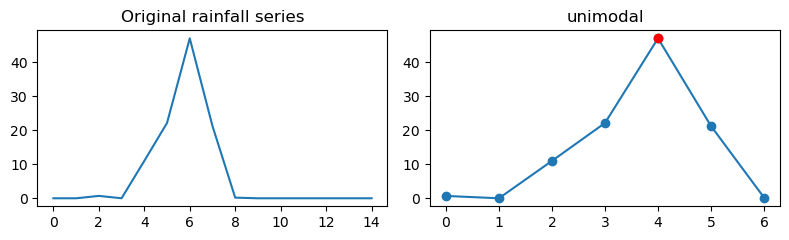

[5.4777995e-02 3.9155287e-01 8.1662846e+00 1.3714973e+00 3.0376341e-02
 6.7539364e-02 1.1327853e-01 1.7444132e+01 3.5452332e+01 9.5760784e+00
 3.7233572e+00 3.8525999e-01]
Event index: 8718, result: unimodal, n_peaks: 1


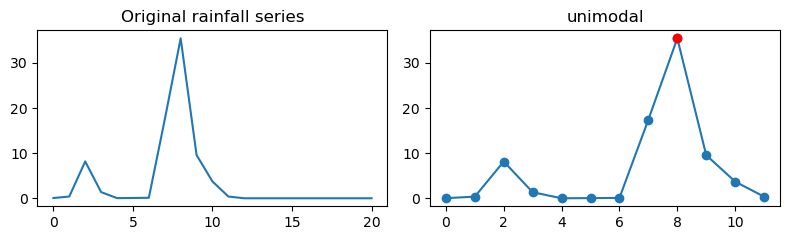

[1.0765609e+00 2.3646560e+00 6.5759494e-08 5.8939241e-07 1.2854607e-06
 3.0415715e-06 1.1810625e+00 7.9302588e+00 3.4960800e+01 1.7218544e+01
 3.5825698e+00 1.3731207e-01 9.1942513e-01 4.8694110e-01]
Event index: 8752, result: unimodal, n_peaks: 1


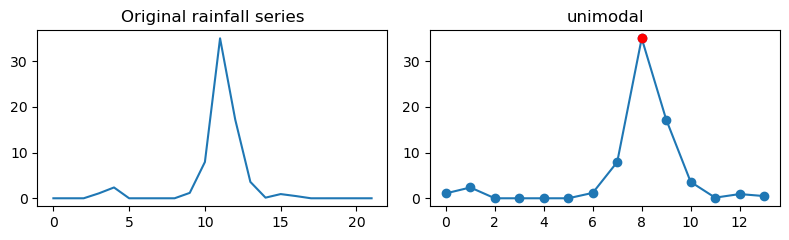

[6.1620790e-01 1.8999004e+01 3.8151024e+01 8.8995953e+00 3.0201942e-01
 4.1543364e-05 2.7505663e-01 8.2006812e-02]
Event index: 8764, result: unimodal, n_peaks: 1


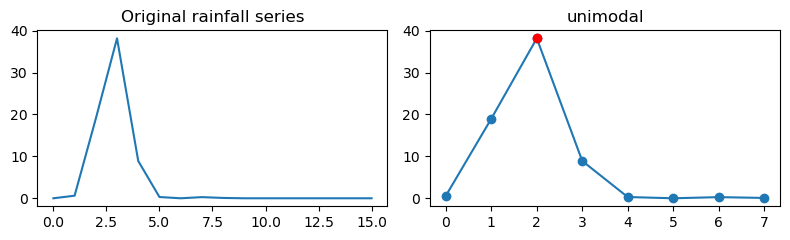

[6.9769895e-01 1.9133176e+00 7.2554121e+00 3.0544979e+01 3.2972410e+00
 2.5854814e+00 1.9827409e+00 4.3798145e-03 5.5900615e-01 4.9454743e-01
 5.5780835e-02 2.7157399e-01 3.2993236e-03 1.5890354e-06 2.7859482e-01
 2.0245330e-01]
Event index: 8814, result: unimodal, n_peaks: 1


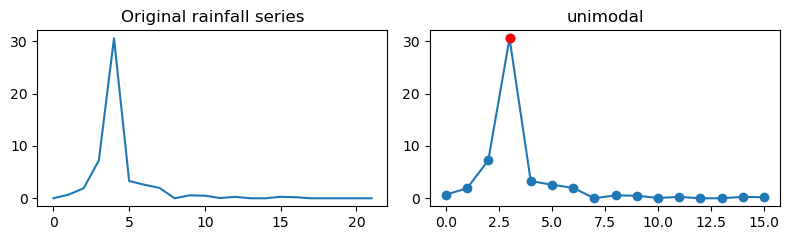

[ 0.35686967  3.3884106   2.1222863   2.4142387   0.9573229   0.46792048
  1.897776    1.2785296   0.4781363   1.0320686   1.8696604  34.160801
 31.173676    5.0611453   0.9736858   0.32663801]
Event index: 8825, result: unimodal, n_peaks: 1


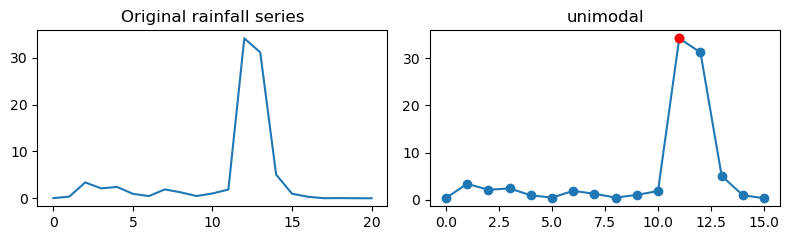

[ 1.2130728  17.391443    4.2314205  31.200581    0.69263077]
Event index: 8839, result: unimodal, n_peaks: 1


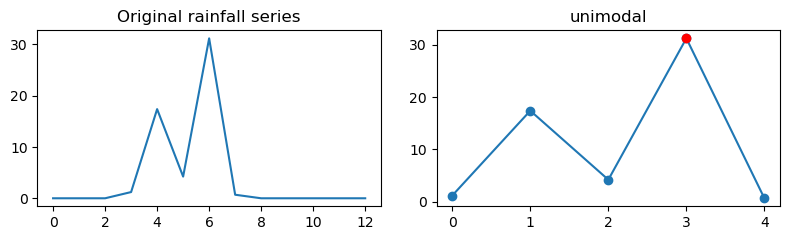

Pixel 486: 112 events
[1.8815815e-01 2.2842073e-01 1.5155125e+00 1.3112038e-02 6.7308050e-01
 3.1924187e-03 3.7628895e-06 6.8398662e+00 3.1437689e+01 1.0524419e+01
 5.4566926e-01]
Event index: 7037, result: unimodal, n_peaks: 1


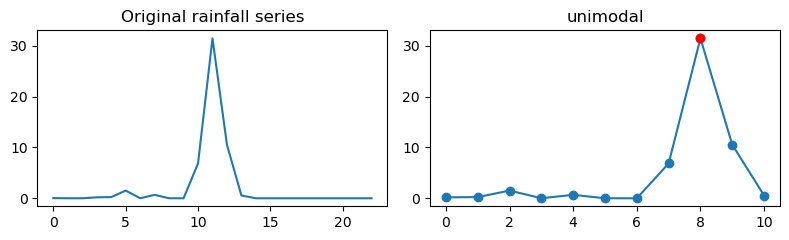

[42.889435]
Event index: 7048, result: unimodal, n_peaks: 1


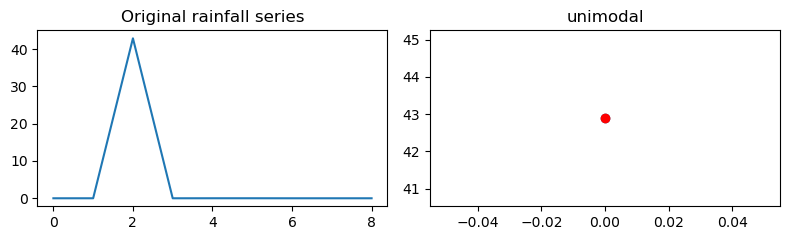

[1.06804185e-01 5.00001869e+01 5.07721619e-04 1.86758537e+01
 5.29907227e+00]
Event index: 7052, result: unimodal, n_peaks: 1


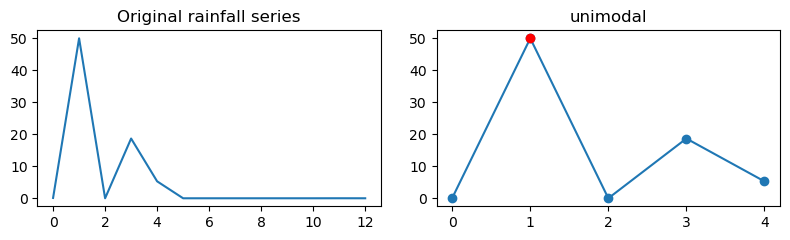

[1.2750183e+01 1.4963845e-03 4.0263397e-04 1.4117174e-03 8.2342775e-04
 4.3226376e+01 2.8269722e+01]
Event index: 7058, result: bimodal, n_peaks: 2


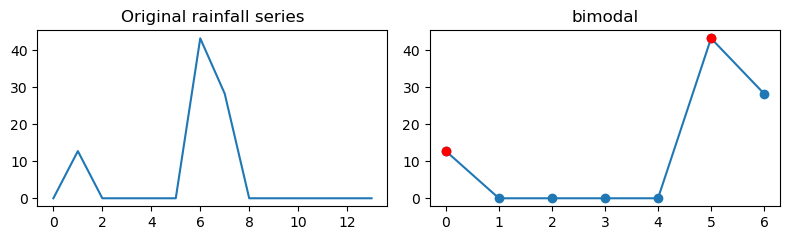

[1.3899498e-01 7.5448914e-03 1.2964739e+01 1.1579073e+01 4.8224367e-05
 6.4580390e-06 6.3840316e-06 3.8615978e-04 6.2658382e-03 1.0281962e+00
 3.8779590e-01 8.8110673e-06 6.2955955e-06 8.0507821e-01 6.0249430e-01
 7.9762040e-06 2.6424709e-01 1.1434855e-05 1.2260463e-05 1.5308415e-05
 1.3358745e-05 1.4950414e-05 3.5705885e-01 7.8167150e-06 1.5192825e-05
 6.2813626e-05 1.1827767e-05 1.0314659e-01 6.3712220e-03 3.7367723e-03
 2.5362822e-03 6.6534197e-03 5.1775500e-03 4.6102828e-03 5.2065928e-03
 1.5327741e-02 3.0153930e-02 4.1875215e-03 2.8519316e-03 2.4800964e-03
 1.7598197e-03 1.1305085e-03 1.8358805e-03 8.7558232e-02 4.1208321e+01
 2.5555870e-02 1.6493248e+00 4.0186420e-03 2.3973987e-03 2.0020935e-03
 2.6616169e+01 8.3721416e-06 4.8198310e-01 1.4791868e+00 1.3401433e+00
 9.9793887e-01 1.1368392e+00 1.0354446e+00 1.5193378e+00 1.5385582e+00
 1.6607945e+00 1.3732909e+00 2.0772066e+00 9.2233819e-01 9.7027481e-01
 7.3999453e-01 6.5105540e-01 2.8760302e-01 1.0352105e-01 4.4233277e-01]
Event

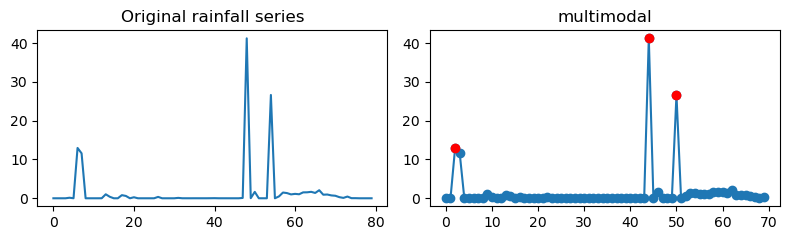

[ 0.36756158  0.25178227  0.55332792  2.9336514  62.927685    0.73288989
  1.5934043   0.28705466]
Event index: 7062, result: unimodal, n_peaks: 1


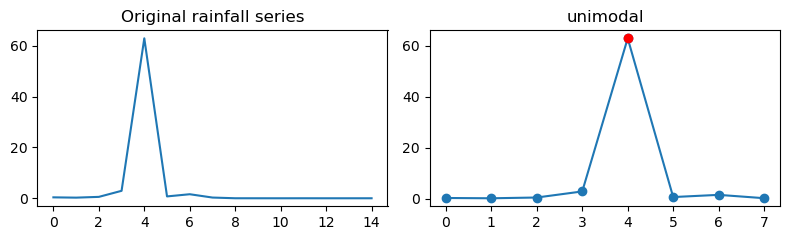

[4.4619381e+01 4.8666936e-04 2.7872850e-03 1.0297920e+01 2.8956225e-03
 3.0013238e-04 2.5292378e-04 4.1486928e-04 2.3594666e-04 5.4005913e-02
 1.0062983e+00 4.8329136e-01 2.5829133e-01 1.2693572e+00 1.6429464e+00
 1.3996651e+00 5.7892096e-01 5.4290611e-02 1.2574420e-05 3.5526138e-03
 4.4950408e-01 3.1946853e-01 3.1435211e+00 7.6055354e-01 4.0129468e-01
 1.0387863e-01 9.9157915e-06 5.4766433e-06 1.9246754e-06 4.2423039e-06
 6.0813088e-02 1.2115487e+00 3.3323437e-02 1.5059506e+00 8.7219447e-02
 1.8685274e-03 2.1883305e-03 1.6507924e-05 4.9148916e-06 7.8179000e-04
 8.7243491e-01]
Event index: 7063, result: bimodal, n_peaks: 2


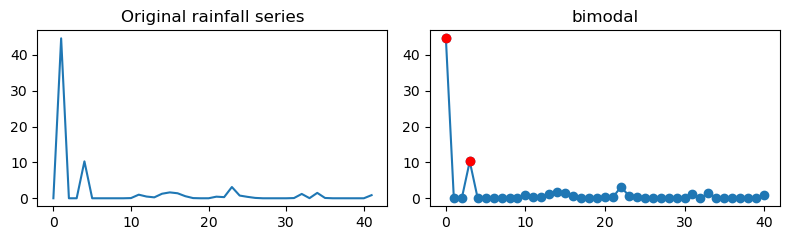

[3.2471785e-01 4.2085659e+01 9.5576096e-01 8.5453129e+00 3.9083537e-02
 1.0629541e-05 2.1083568e-05 1.7819133e-01 1.5983379e-01 2.9507306e-05
 1.7106548e-05 7.7626064e-02 2.4946022e+00 9.7253032e-06 1.2294246e-05
 1.1837741e-05 1.1481531e-05 1.8015126e-05 5.8183271e-01]
Event index: 7066, result: unimodal, n_peaks: 1


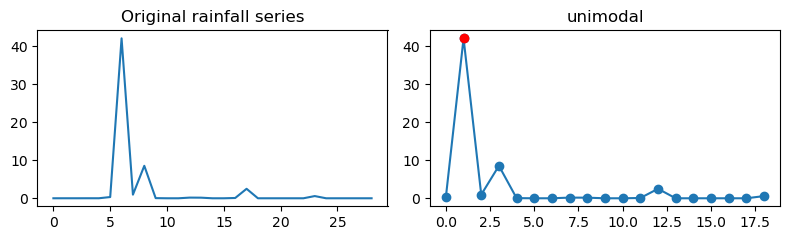

[2.7478343e-01 4.5451093e-01 9.6839710e-07 1.3497109e+00 1.0529184e+00
 3.3300084e-01 9.1744547e+00 5.5862552e-06 3.3786938e-01 8.2526016e-01
 3.1489365e+00 6.3844091e-01 1.0612131e-01 9.0090889e-01 2.9881341e+00
 7.8128767e-01 8.0897999e-01 8.4684962e-01 3.0349890e-06 1.6838059e-01
 3.3290550e-01 1.2235972e+00 3.2929378e+00 3.7048860e+00 3.1612413e+00
 2.1032622e-01 4.3022028e-01 1.4161020e-04 5.1408327e-01 7.6877773e-03
 1.5796098e-03 1.9851197e-01 2.8178378e-03 7.9390764e-01 1.2803490e-01
 4.2228744e-06 1.4967041e-01 1.4711241e-01 5.9991395e-03 2.1065554e-05
 1.7782665e-04 4.7203797e-04 3.0968124e-01 1.3457531e+00 2.2480990e-01
 3.0510986e+00 2.2425153e+00 1.9326810e+00 1.4981921e+00 4.4935462e-03
 1.3636991e-05 2.4347904e-05 6.3555476e-06 1.0721063e-04 3.9926696e+00
 6.6564106e-05 8.4143393e-02 2.1505459e-01 2.6592169e+00 8.6955406e-02
 3.7941375e-01 4.7411844e-01 3.1338534e-01 9.6778983e-01 1.2387394e-03
 2.9766472e-02 8.5181557e-02 2.5235627e-02 6.9045122e-03 1.3138691e-01
 2.838

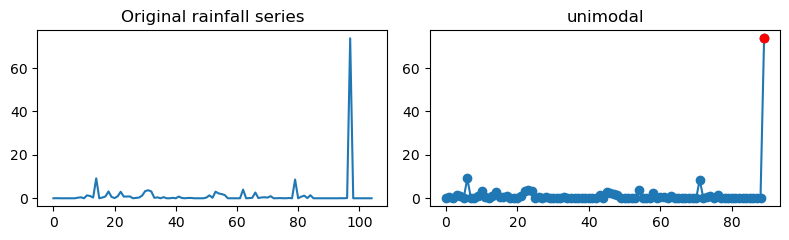

[6.7552537e-01 2.6858766e+00 1.3086733e+00 4.2349706e+00 5.9241810e+00
 1.6202874e+00 2.7481744e+00 1.7780223e+00 1.9364701e-01 4.9017243e-02
 5.8134210e-06 9.0679669e-06 5.0958449e-01 1.6544326e-04 2.9189581e-02
 4.6769509e+00 8.4347203e-06 5.2172632e-06 8.2955012e-07 3.7621387e-06
 1.9220933e-01 5.2438092e+00 3.0500335e-06 7.5592638e-06 2.0905416e-06
 6.2024879e-04 6.7984990e-07 2.2683956e-04 4.6286667e-03 4.1728497e-02
 2.8812091e+00 6.7277168e+01]
Event index: 7074, result: unimodal, n_peaks: 1


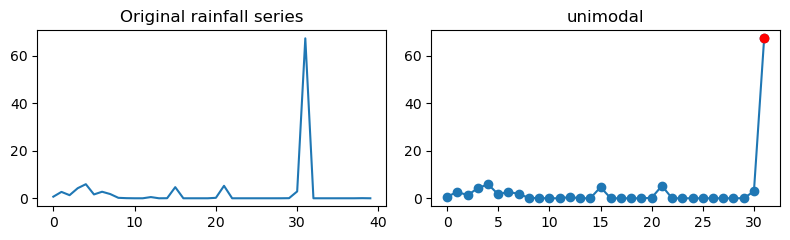

[1.08501947e+00 6.79081142e-01 3.49257886e-01 1.90135455e+00
 8.74868274e-01 2.02022767e+00 8.62002955e-04 2.36859196e-04
 2.81821698e-01 5.06507683e+00 2.53697217e-01 2.32792299e-05
 5.81031144e-02 9.13793623e-01 1.92971397e-02 3.59906442e-02
 2.22825650e-02 2.58742308e-04 6.83810636e-02 1.02845179e-02
 6.33150060e-03 9.43227671e-03 2.90086064e-02 5.46834469e-02
 1.28005818e-01 3.10110748e-02 2.34680080e+00 3.56008759e+01
 1.56637125e+01]
Event index: 7076, result: unimodal, n_peaks: 1


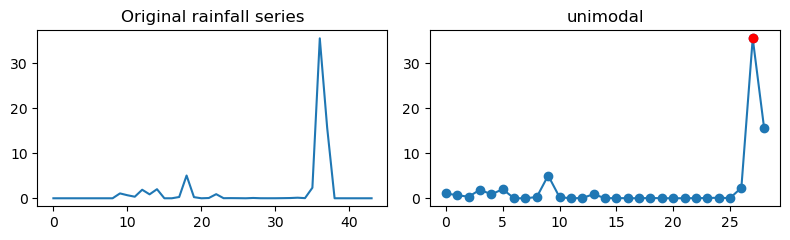

[8.7708294e-02 8.6785030e-01 4.7422251e-01 2.4909705e-03 8.1715167e-01
 1.3402742e+00 1.0486363e+02 2.2345304e+00 2.8970215e+00 2.5736628e+00
 2.7169514e+00 4.7627530e-01 5.4829202e+00 5.4301214e+00 8.1616783e+00
 2.4793980e+00 1.3078825e-02 9.4111973e-01]
Event index: 7085, result: unimodal, n_peaks: 1


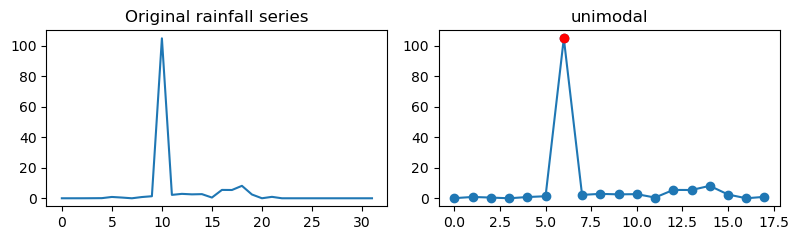

[1.0973652e+01 4.7495022e+01 2.1330736e+01 1.3093743e+01 3.1435859e+00
 7.1766055e-03 5.2803811e-03 6.7703011e-03 6.6566016e-03 3.5985254e-03
 3.7700825e-03 1.0389815e-03 1.1327903e-03 3.2077191e-04 7.0680474e-04
 3.0092185e-03 2.5108778e-03 3.0060404e-03 4.8972690e-03 3.3723663e-05
 5.1569015e-02 5.1509775e-02 2.3176082e-05 1.4705394e-04 5.1253494e-02]
Event index: 7089, result: unimodal, n_peaks: 1


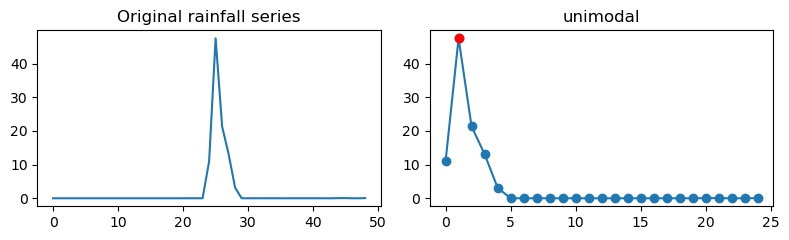

[1.09307137e+02 6.40400127e-02]
Event index: 7090, result: unimodal, n_peaks: 1


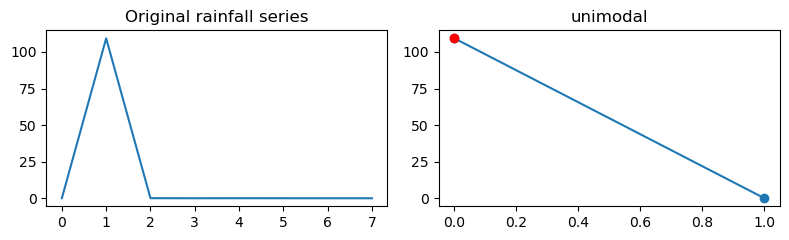

[3.0623338e+00 1.4054623e+00 2.7567783e-01 1.9494125e+00 4.3303368e+01
 2.6850810e+00 9.0701979e-01 2.6240516e-01 3.6379325e-01 1.0634605e-01
 8.3336258e-01 7.0009394e+00 5.0433607e+00 1.7296720e-01 1.1230431e-04
 2.2899542e-06 3.2447952e-06 1.0172379e-06 1.2023268e-06 1.2109297e-06
 2.9500407e-05 1.0299248e-01]
Event index: 7092, result: unimodal, n_peaks: 1


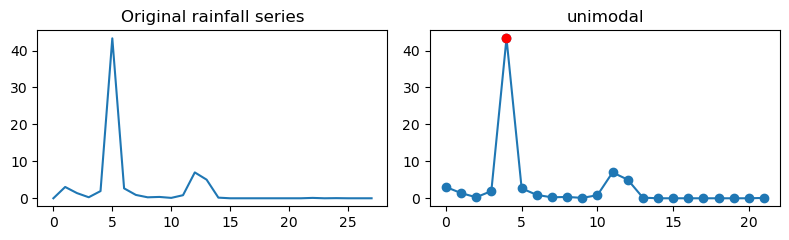

[117.73802     38.991318     8.5572577    0.54737347]
Event index: 7099, result: unimodal, n_peaks: 1


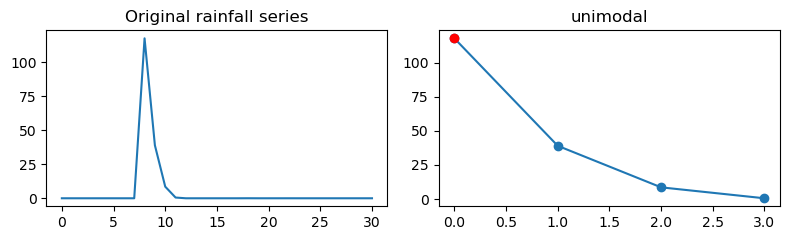

[60.910797   1.0330552  1.1860362]
Event index: 7100, result: unimodal, n_peaks: 1


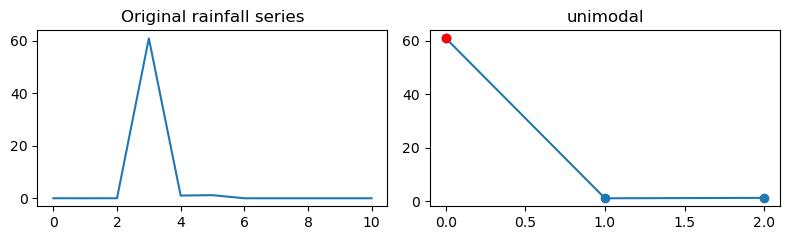

[2.0758849e-01 2.2524488e+00 2.7935886e+00 5.7342970e-01 7.0151687e-01
 1.1400647e+00 2.2688534e+00 6.4375007e-01 1.9573595e-01 9.1559136e-01
 2.5897348e+00 1.6895139e-04 5.4908392e-04 1.4998113e-04 5.3007902e-06
 7.8026096e-06 4.2816737e-05 1.7984408e-05 2.4848130e+00 1.0441005e-01
 2.1718717e+00 4.1615787e+00 1.2823528e-05 8.3189707e-06 4.2979208e-01
 1.0438579e-01 1.9771156e-05 1.3256898e-04 3.1164636e-05 2.1128017e-03
 3.4489662e-05 1.3978504e+00 1.2752397e-01 1.1327830e-02 4.2137737e+01
 3.8297761e-03 5.6240275e-03 1.9652721e+01 2.0478335e-03 1.8343815e+01
 9.7284460e+00 2.8723057e-03 1.5390670e-01]
Event index: 7102, result: bimodal, n_peaks: 2


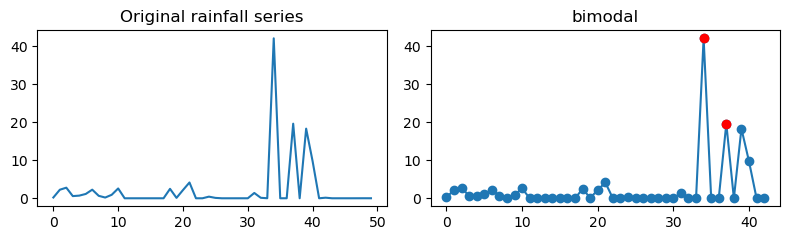

[1.08867416e+01 2.44364049e-03 5.83458710e+01 2.51945760e-03
 6.62842751e-01 2.16309377e-03 2.63942748e-05 8.46556122e-06
 1.05279996e-05 2.20056102e-02 2.65016270e+00 2.90405703e+00
 2.21280766e+00 2.98814178e+00 6.29934645e+00 1.40923709e-01
 3.55986936e-04 6.07604422e-02 1.55086249e-01 7.93478608e-01
 4.28607464e-01 5.27413309e-01 8.95766556e-01 8.64722300e-03
 3.84183526e-02 2.29304123e+00 3.55430156e-01 2.30501872e-03
 9.22859237e-02 1.14002815e-02 1.23048276e-01 4.49615717e+00
 1.22718334e+00 4.08708043e-02 1.22450881e-01 6.34486437e-01
 7.32861280e-01 4.65508504e-03 5.72761834e-01 1.28184229e-01
 2.52507953e-03 4.34141948e-05 6.43050997e-04 1.30032331e-01
 1.32483686e-03 9.50678587e-01 6.93783939e-01 2.64362454e+00
 1.24500453e+00 9.97461472e-03 2.96134967e-02 2.70091295e-01
 1.72302818e+00 2.17895174e+00 1.72139764e+00 1.01083827e+00
 3.29846168e+00 2.88745165e+00 1.50980651e+00 3.38358991e-02
 5.69370575e-03 1.07263379e-01 1.71096772e-01 4.22790825e-01
 8.18285942e-02 5.567309

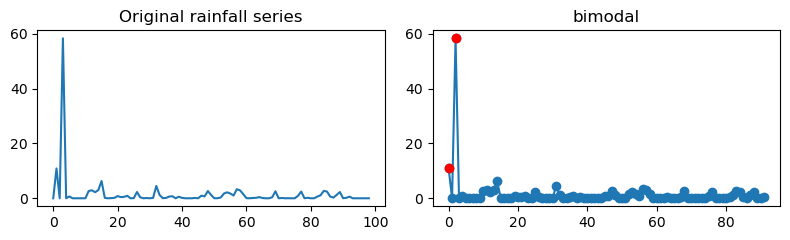

[6.00056529e-01 9.93362546e-01 1.09997427e+00 4.01081890e-02
 2.30958915e+00 5.99399900e+00 6.59044459e-02 1.42593499e-05
 6.21549998e-06 7.56607369e-06 2.24931809e-05 1.36328890e-05
 3.29545073e-05 5.77527499e-06 2.12683654e+00 2.30632268e-05
 7.28380764e-05 1.07987187e-04 3.14426521e-04 9.68534587e-05
 3.75623495e-04 4.26682018e-05 9.87463209e-05 7.79876354e-05
 1.01068006e-04 1.08935133e-01 5.04171290e-03 2.65214931e-05
 5.08510880e-03 9.45664501e+00 3.50026567e-05 3.32435302e-05
 1.96574479e-01 6.72955990e-01 1.45040884e+01 9.36063952e-06
 8.33653007e-03 2.18506044e-04 2.08327056e-05 9.47598019e-05
 2.39038110e-01 1.11721944e-04 1.15815387e-03 2.52088066e-04
 6.48567230e-02 4.34382930e-02 3.64701860e-02 3.58175375e-02
 5.89240972e-06 2.57409781e-01 1.05266636e-05 4.32507973e-03
 3.12187951e-02 7.50334084e-01 6.77570561e-03 6.28798056e+00
 2.17761081e-02 5.08829908e-06 3.85709584e-01 1.22534406e+00
 3.01950526e+00 9.73719358e-03 6.79246306e-01 1.63329037e-06
 5.00596761e-05 2.415298

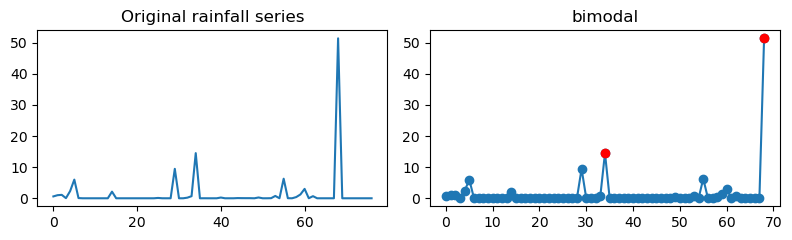

[1.42110434e+01 3.24962807e+01 1.99066579e+00 2.50000216e-04
 3.41877836e-04 1.40455306e-01 1.78264773e+00 2.79707164e-01]
Event index: 7182, result: unimodal, n_peaks: 1


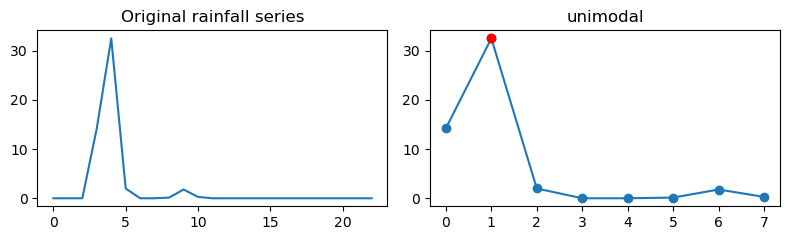

[ 3.6720786   0.20561489  4.8218369  36.169777    3.6845312 ]
Event index: 7208, result: unimodal, n_peaks: 1


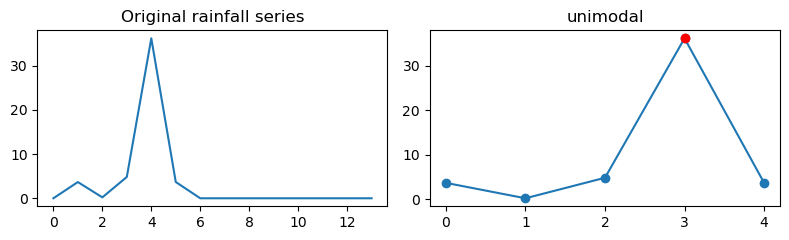

[4.6138500e+01 1.6327193e+00 1.0605465e-01 4.2655153e+00 1.0524303e-01
 1.7539888e-04 1.4035059e-04 7.5087853e-05 1.0645826e-04 3.1621894e-05
 1.3509816e-02 3.0744374e-01 7.1605896e-06 3.7643287e+00 3.4301028e+00
 6.2705782e-05 4.0604972e-04 2.2601830e-02 1.3119208e+00 4.5659159e-05
 1.7564317e-04 4.2881944e-05 2.5123254e-05 1.6549783e-04 1.5199622e-04
 9.1076836e-05 1.0571122e-04 1.5908169e+00 3.3903911e+00 4.4568205e+00
 6.5789523e+00 2.4326275e-01 4.1918734e-06 5.5152186e-06 5.9774434e-06
 5.8619529e-01 1.3839625e+00 3.1099984e-01 1.3514808e-02 2.1665578e-01
 6.4639723e-01 8.4458625e-01 6.2572160e-03 3.3296371e+00 2.6601267e+00
 5.1724010e+00 4.5117154e+00 1.5693423e+00 2.1494238e+00 2.1034189e-02
 6.6884314e-03 8.6949586e-07 9.4911456e-04 6.4416876e-04 3.1904128e+00
 5.0291505e+00 4.4094268e-06 4.0362835e-01 2.9639838e+00 2.0133166e-05
 4.5672464e+00 8.6668425e+00 1.4540439e-02 6.7173868e-01 2.0476973e+00
 4.2223385e-01 1.8770404e-06 1.1628894e-01 1.7825050e+00 6.9615455e+00
 1.024

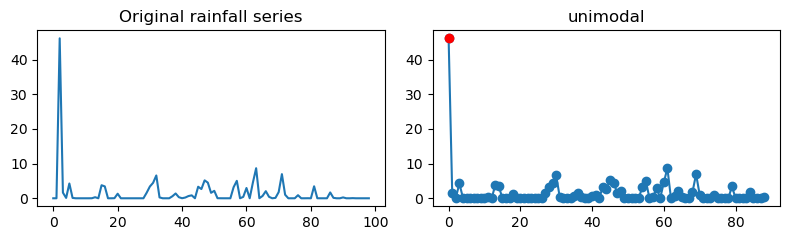

[1.39427400e+00 5.30697441e+00 4.59068966e+00 1.43642068e-01
 8.72090161e-01 1.28504229e+00 2.01375222e+00 2.95143652e+00
 3.80349660e+00 1.33894265e-01 9.26964458e-06 3.43064357e-06
 3.48480285e-06 2.20748620e-06 1.18079484e-01 1.05553936e-05
 4.54030819e-02 1.13391197e+00 6.35458082e-02 3.28530587e-05
 6.23447049e-05 1.30736706e-04 4.45262909e+00 5.30137622e-04
 3.14530509e-04 4.21673292e-03 2.40462279e+00 1.01275771e-04
 3.54813601e-05 1.44741847e-04 6.22245934e-05 2.10258617e+01
 7.01937824e-02 7.27532339e+00 2.02553565e-04 7.44635582e-01
 1.14671064e-04 2.16493172e-05 1.03483035e-04 9.47273948e-05
 2.10426238e-04 3.45790468e-05 9.92263231e-05 7.76991656e-04
 6.35238724e+01]
Event index: 7218, result: bimodal, n_peaks: 2


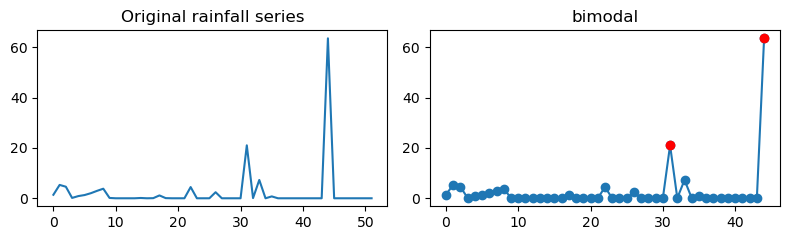

[ 0.11219876 46.928162   42.885677    2.4786947 ]
Event index: 7243, result: unimodal, n_peaks: 1


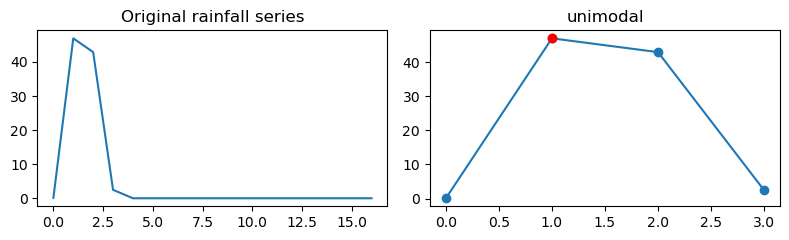

[3.8028768e-01 9.8218240e-02 3.5317886e+01 2.1302780e-02 4.2720017e+00]
Event index: 7249, result: unimodal, n_peaks: 1


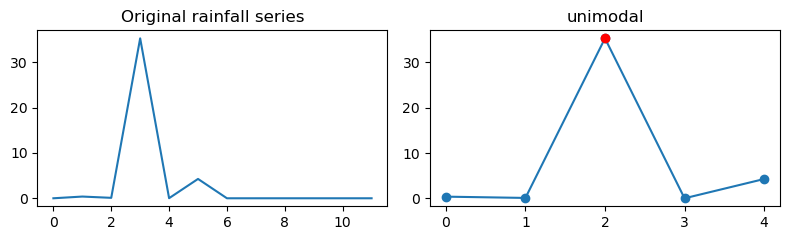

[1.1044547e-01 2.3660927e+00 5.1506529e+00 2.6074487e-01 3.4340695e-01
 5.2737999e-01 1.2206938e+00 9.4378632e-01 7.0937473e-01 3.0768051e+00
 4.3200836e+00 4.3818634e+01 3.7400308e-04 7.1802902e+00 8.1083821e-03
 2.2108415e-04 1.8791495e-04 1.6435925e-04 9.1208800e-05 7.0254552e-01]
Event index: 7269, result: unimodal, n_peaks: 1


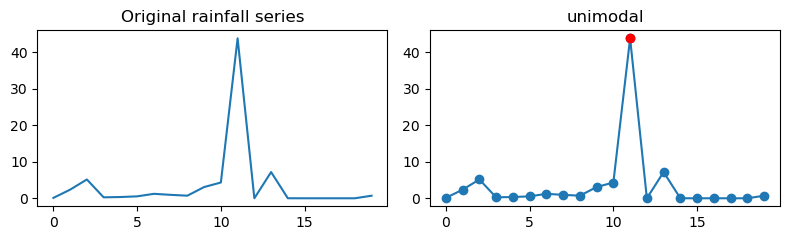

[ 0.71831375  0.81711537  0.45852801  0.59236223  0.4204753   0.44324082
  0.28475621  0.30504549  0.60723466  1.1790946  33.600018    8.3349562
  4.4911098   0.25091332]
Event index: 7277, result: unimodal, n_peaks: 1


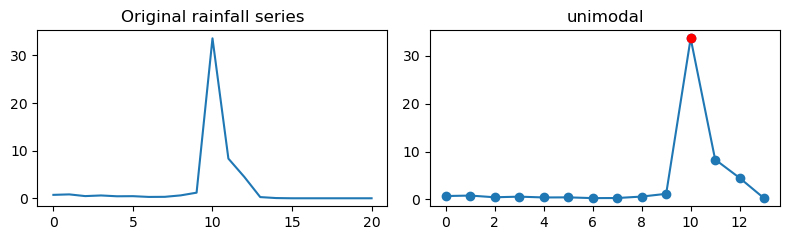

[43.679802 32.462166]
Event index: 7284, result: unimodal, n_peaks: 1


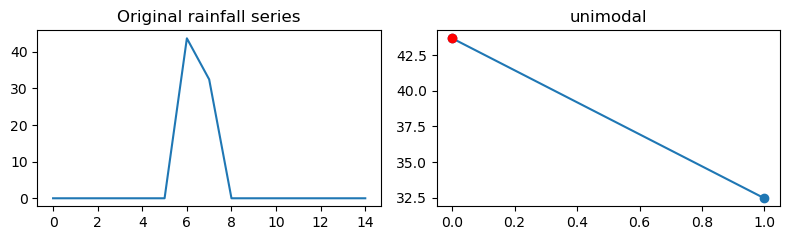

[5.4238927e-02 3.6007732e-01 2.2023777e-02 1.9590035e-03 1.4455237e+00
 1.1558923e+01 1.5147164e+01 1.3877231e+01 1.2340079e+01 1.3640236e+00
 7.3725433e+00 4.0975048e+01 6.5128036e+00 4.3774261e+00 2.6985815e-01]
Event index: 7332, result: bimodal, n_peaks: 2


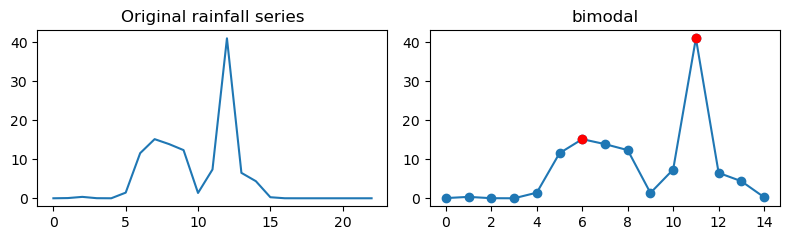

[2.4462987e-01 1.9166402e+00 2.7796093e-04 3.3871849e+01 3.6582072e+00
 7.7420562e-03 1.2647572e+01 3.2148439e-01]
Event index: 7382, result: bimodal, n_peaks: 2


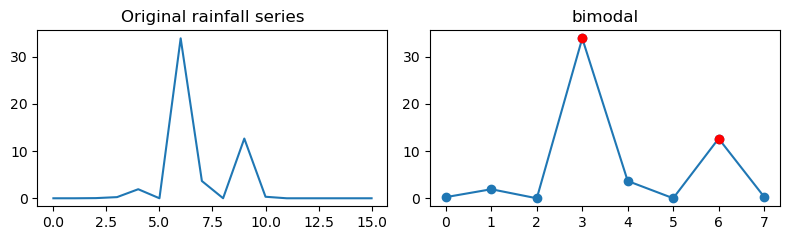

[ 0.21855766 71.728165    3.4402862 ]
Event index: 7390, result: unimodal, n_peaks: 1


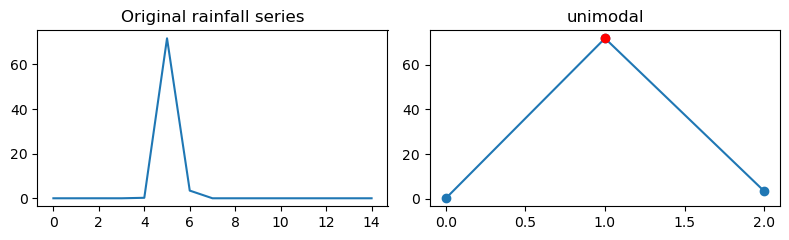

[5.6571460e-01 2.2974907e-01 2.4708543e+00 1.8660765e+00 2.9367435e-01
 7.4224636e-02 5.6109065e-01 6.1348444e-01 3.2170958e-06 5.6506587e-06
 4.7224949e-06 1.6068809e-05 1.8389312e+00 5.7882625e-01 3.6319630e-06
 5.6893881e-05 5.7603890e-04 1.6211089e+00 2.3603314e-03 6.8195514e-02
 7.6607094e+01 4.4930239e+00]
Event index: 7406, result: unimodal, n_peaks: 1


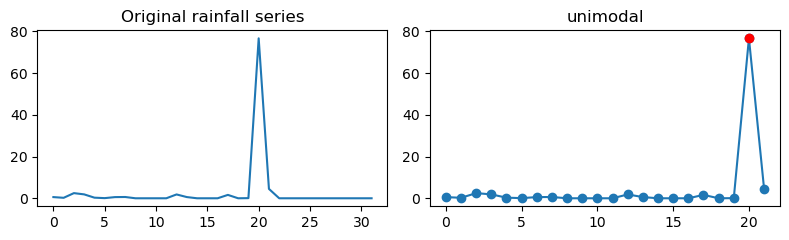

[5.21471083e-01 7.18926907e-01 1.45711148e+00 3.46723986e+00
 5.91449451e+00 3.06382036e+00 2.75646925e+00 1.02139211e+00
 8.22749078e-01 9.45494026e-02 1.65050924e-02 6.01873126e-06
 1.13781061e-05 7.40951737e-06 1.46649791e-05 2.53669992e-02
 4.58675313e-05 2.78000771e-05 3.74679250e-04 1.44921581e-03
 1.26166615e-05 1.68276746e-02 1.05412801e-05 1.11455575e-01
 3.79266024e-01 5.59590171e-06 1.82864275e-02 4.56542778e+00
 1.05969727e-01 5.01355482e-03 6.18602857e-02 5.68252467e-02
 1.41509590e-04 1.25048295e-01 6.61587000e-01 4.24472503e-02
 5.96473515e-01 1.01782227e+00 1.16548896e+00 2.30676010e-01
 3.93924761e+00 3.90488049e-06 1.20035872e-01 2.35607338e+00
 4.31226373e-01 2.86556259e-02 1.50803965e-06 2.63648573e-02
 8.14861655e-01 2.08176184e+00 1.92687953e+00 1.92302382e+00
 2.56167316e+00 4.69656515e+00 3.11688876e+00 7.62358427e+00
 6.42395401e+00 4.11349106e+00 6.12070024e-01 1.58922523e-02
 8.54842365e-02 7.49198720e-03 2.42131531e-01 2.55166218e-02
 1.53405404e-06 5.961982

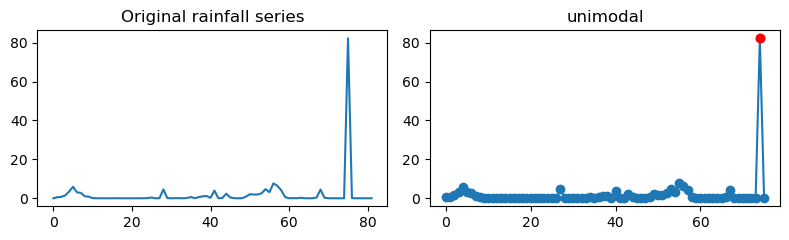

[5.8019370e-02 1.8527660e+01 8.2353966e+01 1.2841350e+00 2.1966789e+00
 3.2707839e+00 2.4574040e-01 5.1835036e-01 8.7978894e-01]
Event index: 7427, result: unimodal, n_peaks: 1


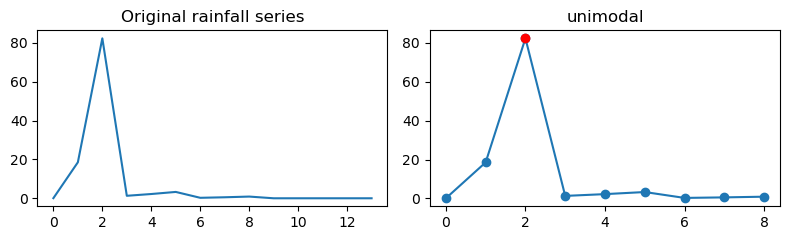

[ 5.68698597 17.8889847  39.6374435  13.125144  ]
Event index: 7428, result: unimodal, n_peaks: 1


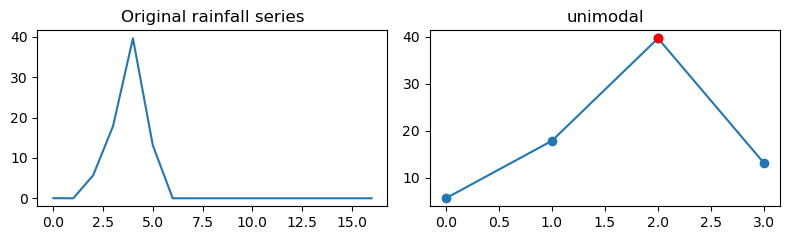

[3.8337821e-01 1.6277790e-01 1.4858312e-04 2.8691888e-05 2.7529540e+00
 2.0986888e-01 3.9884725e-01 1.4302887e-01 1.6697856e-02 9.8361053e+00
 3.6043741e-04 1.3109665e-04 5.4396057e+00 8.7098009e-04 5.3097523e-04
 3.7472284e-01 1.1868125e+00 8.8292561e+00 5.2731892e-05 2.3349019e-05
 3.6760721e-05 1.2694026e-04 2.1471310e-04 7.3388451e-01 5.2822585e-04
 4.3799539e-04 1.6066286e-04 3.7147358e-04 1.0141754e+00 2.8142694e-03
 2.5123509e-04 1.2272029e+01 3.3196839e-04 6.9218094e-04 6.3472957e-04
 6.9581688e+01 6.3234568e+00 1.3670280e-03 3.7478539e-04 9.2360591e-05
 9.1898933e-02]
Event index: 7435, result: bimodal, n_peaks: 2


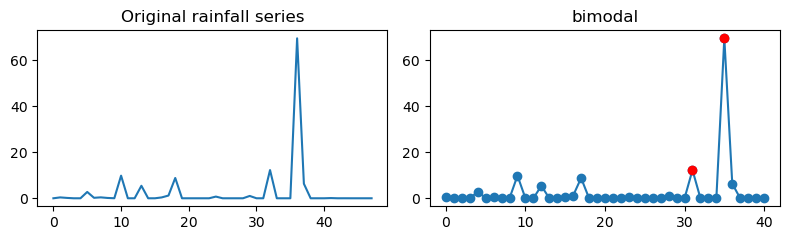

[1.57794571e+01 3.66921959e+01 4.77719354e-04 2.16849542e+00
 5.47258242e-04 3.80049236e-02 1.92937317e+01]
Event index: 7441, result: bimodal, n_peaks: 2


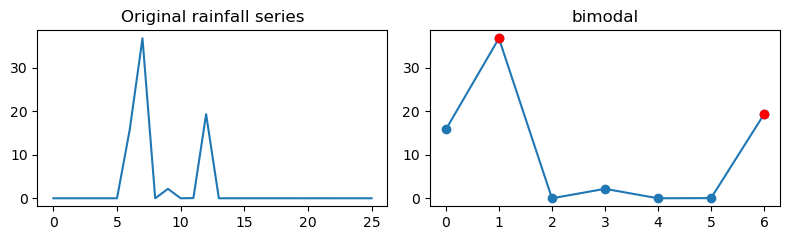

[2.9287105e+00 1.3446842e+00 1.8084843e+00 5.4794554e-02 1.6913784e-01
 1.6848654e-01 5.6663720e-04 4.0125982e-03 1.2886439e-01 2.3169790e-01
 3.9489552e-02 3.0562997e-02 2.4738016e-02 5.9050094e-02 4.1088972e-02
 2.1668687e+00 1.0436262e+00 1.7077786e+00 3.0194478e+00 2.8079762e+00
 1.7927277e+00 6.7241650e+00 7.9889855e+00 1.5223206e+00 4.6880642e-01
 1.1688227e-01 1.5808169e-02 1.7451528e-04 2.4590743e-04 3.1453680e-04
 2.4551328e-04 9.9897815e-04 2.9441604e-04 3.4042608e-04 3.9412713e-04
 4.8762531e-04 1.1290895e+00 4.9934810e-04 1.6023529e-04 1.5598966e-04
 1.5671619e-03 2.5791859e-03 9.6159568e-04 1.7966932e-02 7.1128953e-01
 4.8072387e-02 2.2376692e+00 5.4017971e+01 1.2613160e-02 7.6141201e-05
 3.3320710e-05 7.8107216e-05 4.4218376e-03 1.0143014e-01 1.2052314e-01
 1.0561200e-01 1.0931844e-02 3.6063539e-05 3.1765227e-05 5.4309228e-05
 2.0132186e-04 5.8083089e-05 6.9481009e-03 6.2078457e+00 2.5792446e+01
 1.3979470e+00]
Event index: 7445, result: bimodal, n_peaks: 2


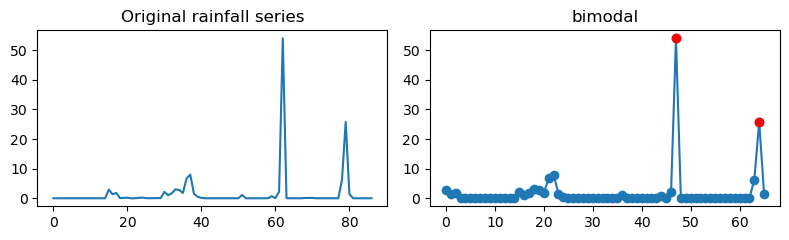

[9.10440445e-01 2.26005062e-01 6.66235865e-05 1.14708967e+01
 3.41576597e-05 1.64889172e-01 1.59634394e-04 9.14630532e-01
 7.08048610e-05 8.18631458e+00 9.66714174e-02 6.68563128e+00
 2.85043170e-05 3.67150060e-04 5.76992035e-02 6.17176847e-05
 2.75465893e-04 1.78562317e-04 2.79398082e-04 5.08156955e-01
 5.33465233e+01 2.07015306e-01 5.88134804e-04 1.50177889e+01
 1.30589485e+01 1.19903602e-03 5.01643944e+00 4.31960791e-01
 7.87256956e-02 1.20907454e-02 1.10182285e-01]
Event index: 7452, result: multimodal, n_peaks: 3


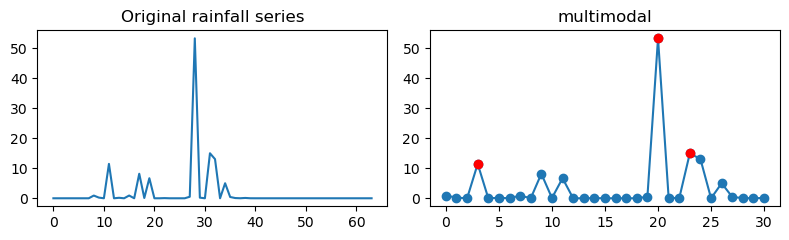

[  0.3718363    6.7064328   10.161626     0.79259408 100.48082
  24.264017     0.60019237]
Event index: 7463, result: unimodal, n_peaks: 1


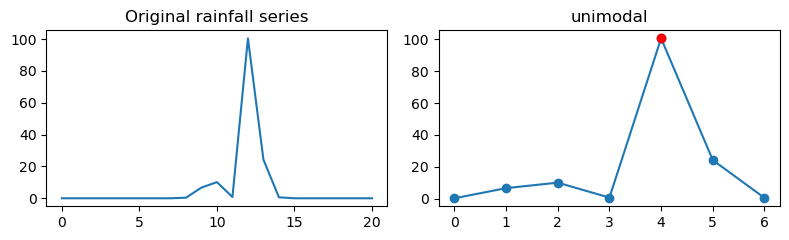

[8.38538933e+00 6.56199799e+01 1.02145037e-04 2.39156449e-04
 4.37430859e+00 1.32560308e-04 8.48287717e-03 9.59578101e-05
 3.75023192e-05 2.84266745e-04 5.04911470e-04 1.43702555e+00
 2.71726531e-05 5.47981072e-05 3.14817677e-04 4.72907268e-04
 2.66301483e-01 4.00046706e-01 2.19729700e-04 3.27097572e-04
 9.66407776e-01 2.41209579e+00 5.22149801e+00 2.05293849e-01
 4.52743769e+00 3.25770452e-05 3.14408255e+00 5.64858723e+00]
Event index: 7477, result: unimodal, n_peaks: 1


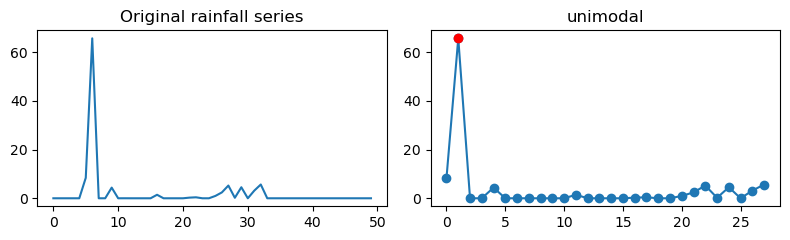

[103.19604     2.7908781  13.381097    1.2371206]
Event index: 7485, result: bimodal, n_peaks: 2


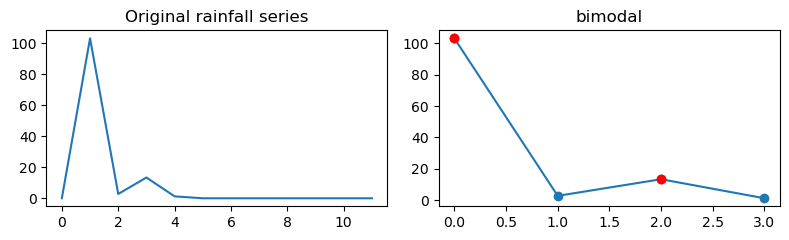

[ 6.13386059 93.7815018   9.11277103  8.00095367]
Event index: 7493, result: unimodal, n_peaks: 1


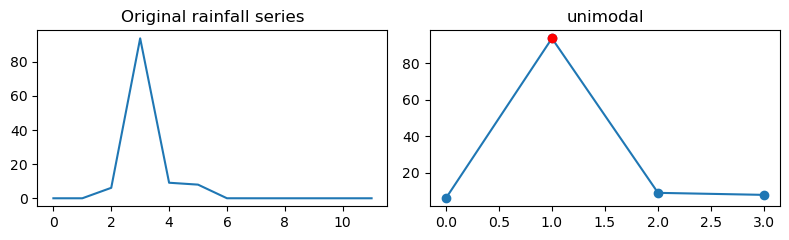

[39.855541   8.6102409 19.041214  16.385416   3.0213349]
Event index: 7497, result: bimodal, n_peaks: 2


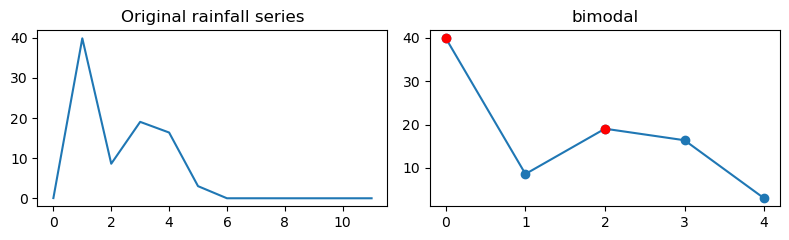

[9.4799004e+00 8.1992884e+00 1.9981583e+01 5.8583313e+01 7.6095972e+00
 3.1973233e+00 5.6154840e-04 1.3170373e-05 3.0739982e-06 3.3460090e-06
 6.8005538e-01 5.2174125e+00 1.8692206e+00 8.1599779e+00 2.7560275e+00
 5.0599608e+00 4.2373323e+00 2.6134191e+00 3.7724202e+00 1.3616934e+00
 1.5716081e+00 1.9393414e-02 4.9856153e-06 3.6832776e-06 2.7050812e-06
 8.2730934e-02 4.3582023e-04 2.4872882e+00 7.0688147e-05 6.7652646e-03
 6.3442760e+00 3.7664002e-05 3.3605538e-05 1.7728211e+00 7.8949197e-05
 1.3028042e-04 4.2848587e-01 1.9336109e-04 1.4621693e-04 1.8349634e-05
 5.8287268e+00 6.7084641e-03 3.4799361e+00 3.2072272e+00 1.6575323e-05
 5.5728650e+00 3.9088707e-02 2.5263440e-05 1.7023997e+00]
Event index: 7512, result: unimodal, n_peaks: 1


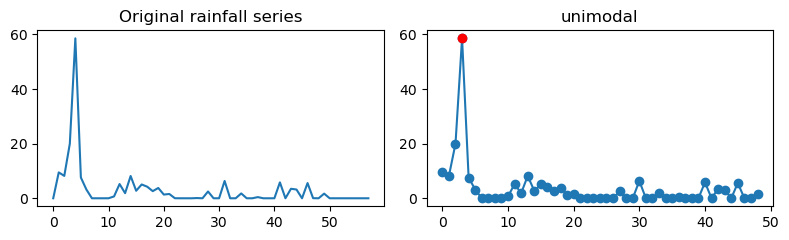

[2.7986789e-01 2.6967745e+00 3.7233396e+00 6.8651075e+00 9.9776478e+00
 1.0482969e+01 4.7111785e-01 8.3802413e-04 4.5806146e-04 4.0920600e-04
 5.1432858e+01 8.9501587e+01 8.0787682e+01 2.1357641e-01 2.8364590e-01
 8.2301307e-01 1.3175005e+00 1.2479327e+00 1.8212143e+00 1.5816530e+00
 1.4898064e+00 8.7935275e-01 2.6822090e-01 2.2586846e-01]
Event index: 7516, result: bimodal, n_peaks: 2


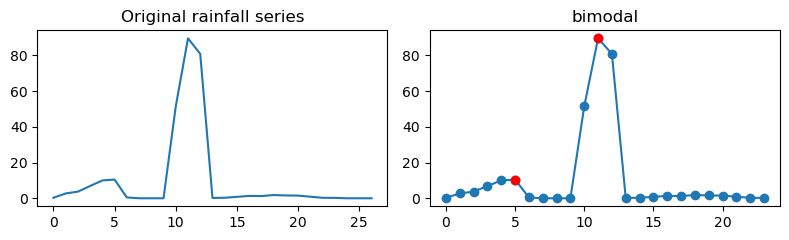

[6.0093498e-01 3.5752647e+00 2.4748445e-04 1.3022363e-04 6.9826172e+01]
Event index: 7525, result: unimodal, n_peaks: 1


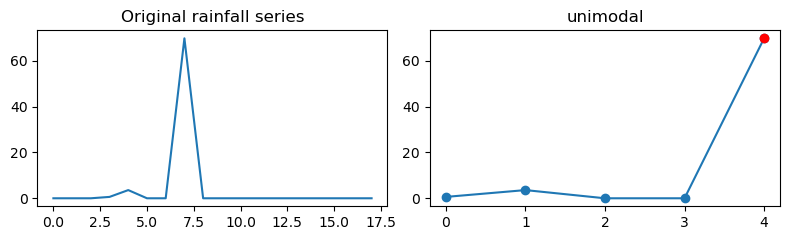

[5.6039798e-01 3.8203777e+01 1.3786109e+01 7.4378791e+00 3.5302300e-02
 1.7462677e-01]
Event index: 7526, result: unimodal, n_peaks: 1


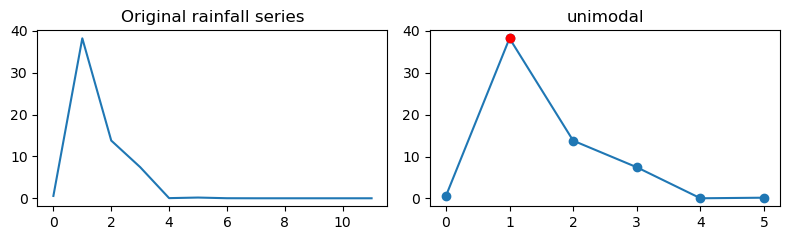

[ 0.53865963  0.67297763  1.5058253   1.0932893   0.9122231   0.8659845
 33.766342   23.433697    0.36678967]
Event index: 7530, result: unimodal, n_peaks: 1


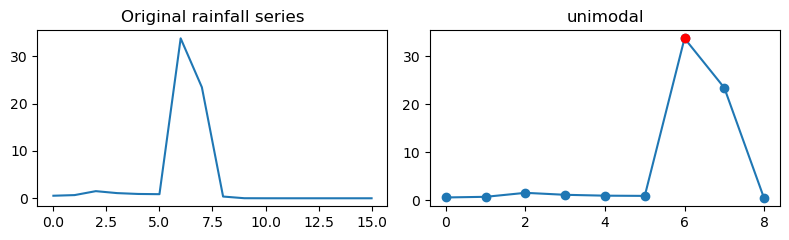

[8.65705371e-01 2.43297458e+00 9.01878579e-04 1.20679334e-01
 3.01980406e-01 1.41681403e-01 4.86062288e-01 1.11875296e-01
 7.13218302e-02 1.13592446e-01 1.07335663e+00 2.46209535e-03
 9.49234545e-01 4.48487610e-01 5.56796193e-01 7.98217058e-01
 8.97602260e-01 5.28609562e+00 6.47518635e-01 1.61158359e+00
 4.32143133e-06 1.80338216e+00 4.46474360e-06 2.29222830e-02
 1.01069178e-04 3.83114815e-01 8.71808827e-02 1.10524476e+00
 3.15795183e+00 1.73411367e-03 3.63793761e-01 2.45658285e-03
 1.56809290e-06 4.74381864e-01 1.89850199e+00 1.90583146e+00
 4.91241306e-01 1.48883238e-01 2.10585085e-06 1.42918164e-02
 1.16909519e-01 4.24579054e-01 4.85575944e-02 1.25346817e-02
 2.78541064e+00 5.42451429e+00 3.74590850e+00 8.09724617e+00
 9.84305443e-05 5.06989670e+01 6.33194530e-03 2.45815206e+00
 2.71799538e-04 2.53594277e-04 3.59619013e-03 2.51941878e-04
 2.48684373e-04 2.23544354e-04 2.59320484e-04 1.09858163e-04
 1.84967401e-04 4.12561902e-04 1.74479486e-04 2.50416715e-03
 3.36404145e-02 1.969939

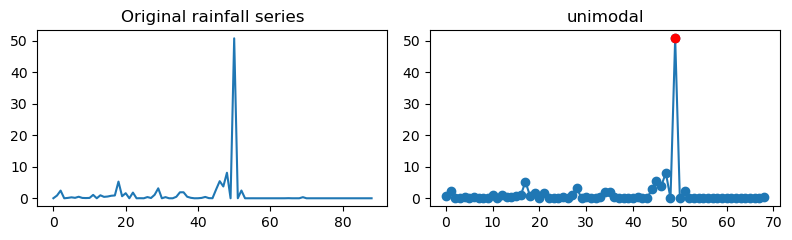

[1.7640547e+00 7.7354973e+01 3.7269262e-04 3.2095200e-01 2.1501420e+00]
Event index: 7534, result: unimodal, n_peaks: 1


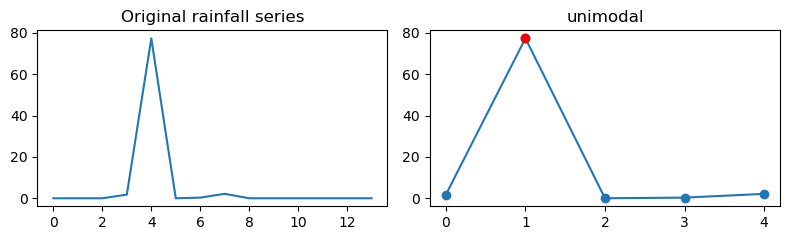

[72.4480438   2.74403286]
Event index: 7536, result: unimodal, n_peaks: 1


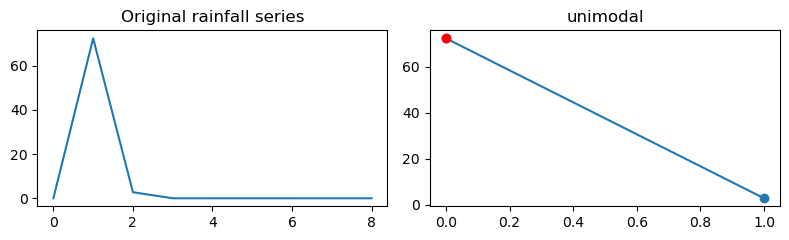

[7.86861181e-01 2.92297387e+00 6.62024927e+00 2.68552423e+00
 4.17873207e-06 5.80458654e-05 2.34600101e-02 1.48880819e-04
 1.03220570e+00 5.66963613e-01 4.65767868e-02 3.29424233e-06
 3.47075729e-05 1.92675066e-06 2.90840444e-06 3.43078636e-06
 6.96873758e-03 4.34727772e-05 4.41760603e-05 2.11042631e-03
 1.67429876e+00 1.18374932e+00 1.48591387e+00 6.57402456e-01
 1.83555039e-06 4.00683939e-01 4.51982123e-05 1.09202956e-04
 1.20938607e-02 2.02142405e-06 1.51851833e-01 4.48818588e+00
 6.99215174e+00 8.10905075e+00 6.96105003e+00 4.59768080e-06
 1.42931986e+00 1.25476503e+00 3.77672313e-06 6.01094496e-03
 1.17205727e+00 1.81428295e-05 1.01614278e-05 2.23804655e-05
 7.02386160e-06 4.57961460e-06 6.99583961e-06 3.11727968e-06
 3.82982580e-05 6.62751745e-07 1.05452351e-03 7.58253736e-04
 1.95393131e-05 3.86057172e-06 3.82618091e-05 2.36558124e-01
 1.72425914e+00 2.31050110e+00 1.06748021e+00 3.32711414e-02
 2.42752099e+00 5.63542223e+00 7.59586915e-02 1.73351908e+00
 1.64295900e+00 3.376350

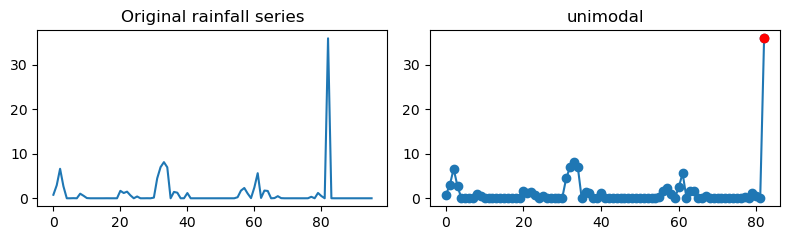

[ 0.47692969 59.250698    9.9706116   0.24949899  2.3404725   2.2553442 ]
Event index: 7541, result: unimodal, n_peaks: 1


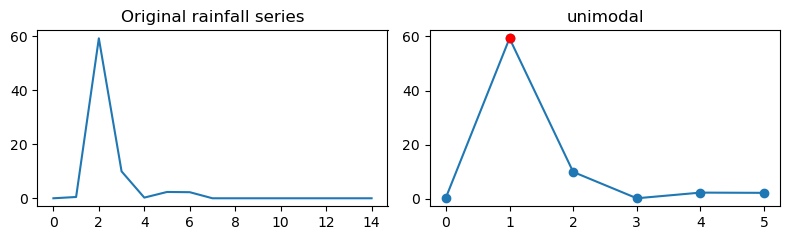

[5.2117783e-01 5.8290226e+01 6.8427013e-05 1.5286241e-01 1.5614419e+00
 2.1819614e-02 9.4380751e-03 1.8734322e-04 7.3533022e-04 3.2124687e-02
 7.4232608e-02 1.0296086e-01 2.4790218e-01 6.7640090e-01 4.9599594e-01
 2.4747272e+00 4.5151634e+00 9.9023092e-01 1.5162665e+00 1.6675196e+00
 6.8352145e-01 2.5128001e-01 1.9214290e-01 1.9608480e-01 1.4809503e-01
 4.7978061e-01 6.2177759e-01 4.3200011e+00]
Event index: 7544, result: unimodal, n_peaks: 1


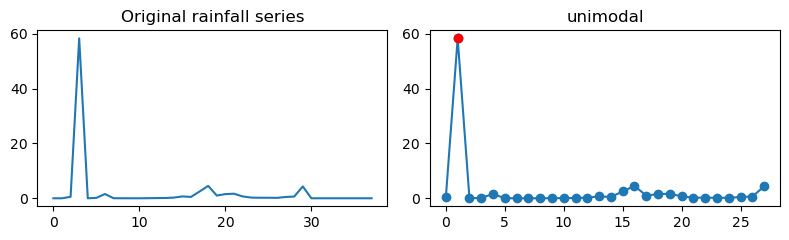

[6.2051111e-01 1.3410027e+00 3.4158127e-06 1.0265356e+00 1.0690424e-05
 5.8645776e-07 1.1642130e-04 1.0990671e+00 3.2375599e-04 9.0177217e-04
 1.2816893e-04 8.6309243e-05 3.5741329e+01 2.5068438e+00]
Event index: 7547, result: unimodal, n_peaks: 1


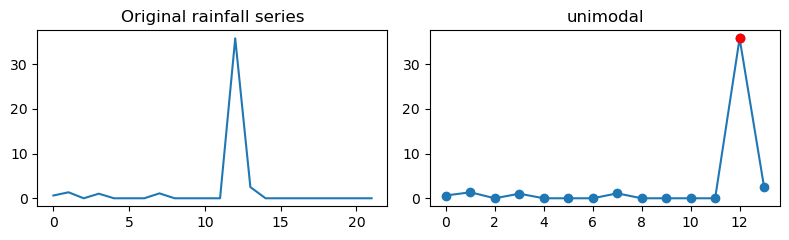

[ 0.44384056  0.93585342  1.5735456   0.25997451  1.4037457   0.62615407
  0.6735757   0.87836713  0.61898798  0.90228468 35.300953   20.356615
  4.4160028   3.5072501   1.8863997 ]
Event index: 7548, result: unimodal, n_peaks: 1


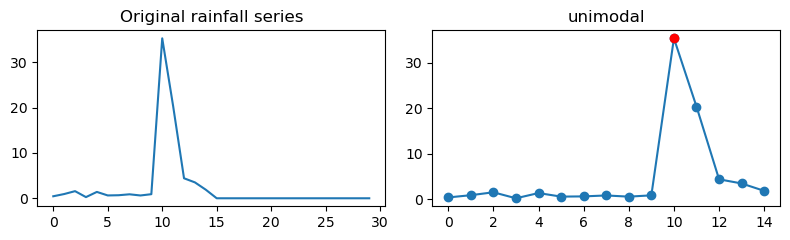

[5.7940495e-01 8.4914491e-02 5.1598811e-01 6.2133861e-01 8.7072921e-01
 3.9412453e+00 2.8437626e+00 9.2334431e-01 8.2169712e-01 4.4860911e+00
 9.3470025e-01 2.7883896e-01 2.0845960e-01 9.9858776e-02 5.9255618e-01
 1.4030018e-01 5.0608210e-06 4.3589339e-06 1.3261506e-02 4.7146802e+00
 1.9434521e-02 1.3835487e+00 2.0993602e-06 9.2069622e-06 7.2197028e-05
 6.6779368e-03 4.4824280e-02 7.0627433e-01 1.2813832e-01 1.3565030e+00
 3.8929346e+00 8.4437795e-02 1.4808407e-01 2.5146360e-02 4.6174705e-06
 1.3527790e-05 2.7340700e-06 1.8543867e-06 1.3310477e-06 5.6489703e-06
 1.4194541e-05 1.1280675e+00 1.8189906e-01 1.0421433e-02 8.9795212e-05
 2.0040218e-02 4.8448011e-01 3.9411202e-02 2.3954482e-05 1.3496896e+00
 3.2874295e-03 1.2309930e+00 2.6681478e+00 3.8832699e-05 2.9293640e+00
 8.5319436e-01 1.0149102e-02 1.6422082e+00 1.4976337e+00 7.7685036e-02
 3.9925808e+01 1.0258940e+00 4.6030670e-01 1.4959589e+00 4.8435018e-03
 2.8368723e+00]
Event index: 7549, result: unimodal, n_peaks: 1


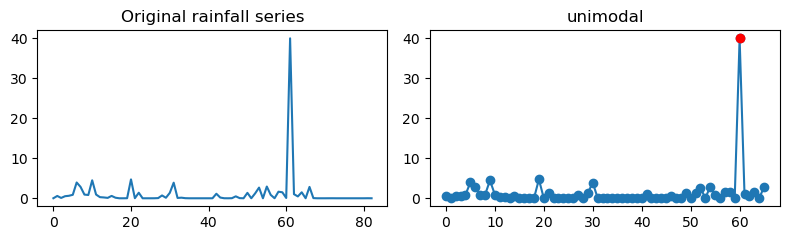

[ 0.34114608 31.023993    0.04229375  0.06353576]
Event index: 7575, result: unimodal, n_peaks: 1


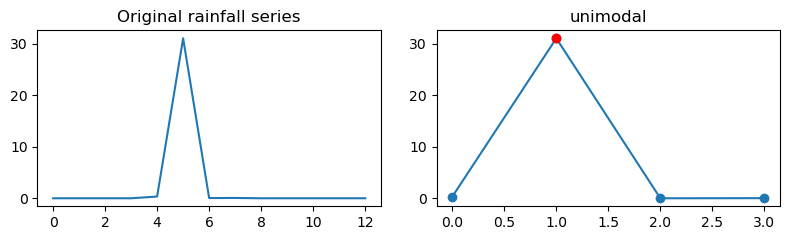

[4.60108662e+00 4.76698065e+00 6.91983700e+00 1.18134748e-02
 1.22502621e-04 1.71226871e-04 5.47508659e+01 8.50452423e+00
 2.46561974e-01 2.07664561e+00 7.39468524e-05 8.41629371e-05
 2.09577658e-04 2.17007031e-03 1.94897389e+00 1.31181470e-04
 1.74709386e-03 1.21730418e-05 1.15089162e-04 1.31717126e-04
 2.94025874e+00 7.90707874e+00 1.34360150e-01 2.31765485e+00
 4.66926432e+00 3.74560326e-01 3.40901732e+00 2.43296698e-01
 4.54334496e-03 1.05246613e-02 1.60859209e-02 9.29980259e-03
 6.64695253e-05 2.49754898e-02 1.86766088e-02 7.55020836e-03
 1.12137996e-01]
Event index: 7744, result: unimodal, n_peaks: 1


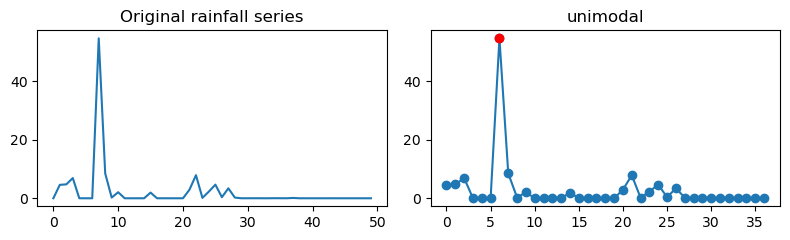

[4.4130400e-01 4.5210784e-03 1.1269146e-01 6.2356824e-01 1.0941809e+00
 4.8348483e-01 9.0128387e-06 3.1341240e-02 6.9037139e-02 1.2452816e+00
 2.0946865e-01 3.2792639e-02 5.3176582e-02 2.0237928e-02 3.6850357e-01
 2.4637389e+00 9.0198624e-01 6.2481302e-01 1.1697972e-01 1.6435283e-01
 3.8919456e-02 5.2047223e-01 2.9647164e-02 1.1143815e-01 9.4030851e-01
 4.6489418e-01 1.1096007e+01 3.5587549e-01 5.6552849e+01 7.9613999e-02
 6.9272026e-02]
Event index: 7805, result: unimodal, n_peaks: 1


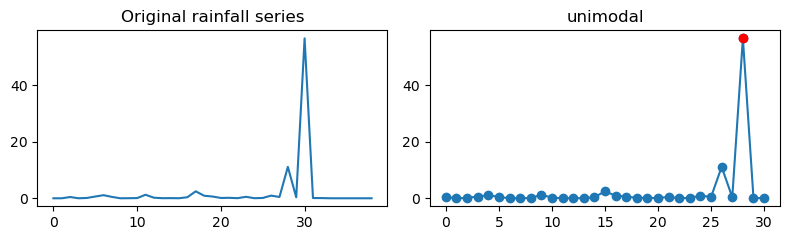

[ 2.5082932 33.392719 ]
Event index: 7811, result: unimodal, n_peaks: 1


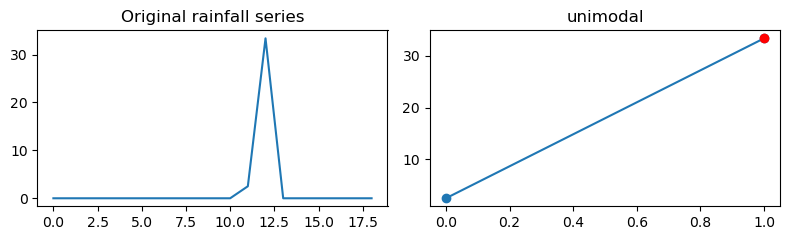

[8.8304289e-02 4.0916213e-01 1.7337188e-02 3.3386948e-04 9.0805734e-05
 7.0415452e-05 8.3844672e-05 6.2810650e-05 6.2917134e-05 1.1986907e-02
 1.1495599e+00 3.4023222e-01 3.0516504e+01]
Event index: 7832, result: unimodal, n_peaks: 1


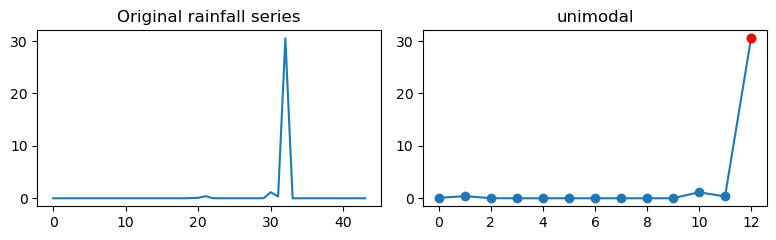

[1.23130739e+00 2.83724675e-03 3.71533394e+01]
Event index: 7836, result: unimodal, n_peaks: 1


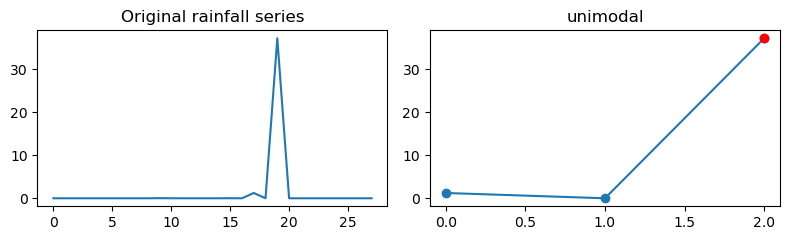

[4.7141895e-01 2.2851877e+00 4.4012842e-01 2.5247450e+00 1.0452118e+00
 1.8931959e+00 1.6471040e-01 3.3227271e-01 4.6134615e+00 3.3185766e+00
 9.0559165e-04 1.7237606e-06 3.1726610e-02 3.1934505e+01 7.1591783e-01
 1.2718855e-03 3.0602997e-02 4.9534220e-02 1.2348250e-06 7.9185081e-01]
Event index: 7895, result: unimodal, n_peaks: 1


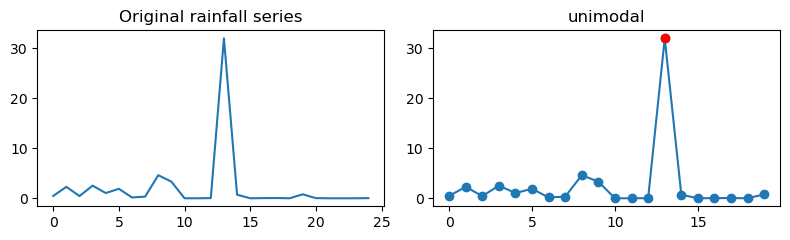

[7.20297928e+01 3.90318964e-05 7.41691038e-05 4.11530753e-04
 1.03615464e-04 1.69350023e-04 2.77164974e-04 3.77167395e-04
 1.79542985e-04 5.34768842e-05 2.96868220e-05 2.22774779e-05
 1.55724178e-04 3.55868629e-04 3.45888664e-04 2.58469200e+01
 4.76061628e-04 3.04625893e-04 2.90809316e-04 3.99977493e-04
 4.33187030e-04 6.14288088e-04 2.27859449e-02 5.49287237e-02]
Event index: 8046, result: bimodal, n_peaks: 2


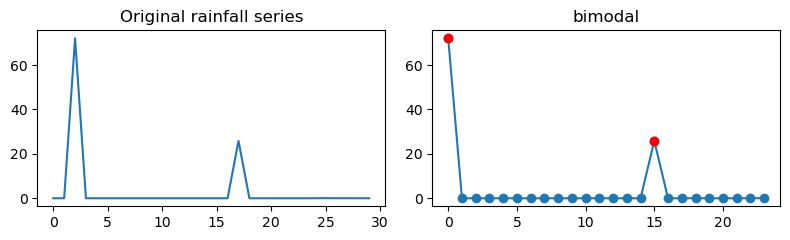

[2.5903575e+00 2.7815285e+00 1.3408374e+00 8.9829299e-04 5.2350742e-06
 3.4773777e-05 1.3889648e-05 5.6647088e-05 2.6303938e-02 2.5286185e-04
 1.1901219e-04 2.0209816e-03 1.7587077e-02 1.6129447e-05 7.5100392e-01
 1.0780163e-04 6.8642636e-05 3.5697514e-05 3.5003159e-05 6.0015867e-05
 8.0669117e-05 7.2841038e-05 1.6520556e+00 3.4370513e+00 1.0597652e-01
 1.0790682e+00 3.1555500e-03 1.0792877e-04 2.8428666e-03 9.2393678e-01
 1.0015051e+00 1.6395918e-01 9.9929676e+00 1.2706255e+01 1.6913831e+00
 1.3151173e-04 2.3097064e+00 2.0610921e+00 4.3137060e-03 2.8105304e-04
 8.4235750e-02 3.0864243e-04 4.6402936e+00 1.3573412e+01 2.3881836e-01
 3.2656036e-02 1.6297970e-04 5.0755910e-04 2.9211395e+00 1.8791319e-04
 1.0617812e-04 5.0572742e+01 9.1971245e+00 3.3767080e-01]
Event index: 8050, result: multimodal, n_peaks: 3


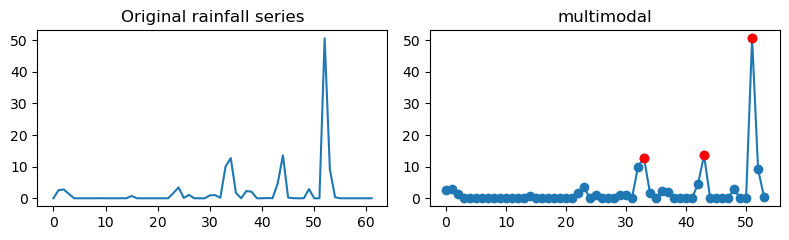

[7.20918655e-01 1.31387353e+00 5.21872902e+00 3.26838600e-03
 8.97365034e-01 8.30791593e-02 8.98557715e-03 9.46387708e-01
 2.10494208e+00 1.92337954e+00 9.11731768e-05 5.27701286e-06
 1.14994436e-05 6.28156249e-06 5.58704399e-02 9.02191937e-01
 5.01256371e+00 6.96521784e-06 1.20483376e-01 1.12250066e+00
 6.29817168e-06 7.88332636e-06 7.36286347e-06 8.38550841e-06
 6.80446101e-04 3.90867935e-05 3.47805694e-02 5.10533690e-01
 9.23870355e-02 8.80681910e-05 6.04185835e-03 1.15114711e-01
 6.03111494e-06 3.00949633e-01 1.22085619e+00 3.53366524e-01
 7.56571949e-01 2.41444111e-02 4.48417768e-06 3.27223779e-06
 5.59323053e-06 2.55325881e-06 2.90548724e-05 9.34661148e-06
 7.91685034e-06 1.02405738e-05 5.42432554e-06 3.61112976e+00
 1.17721522e+00 3.60958475e-05 6.57671126e-06 4.53107711e-03
 5.25210190e+00 1.61510992e+00 8.01529598e+00 8.52506256e+00
 8.24477615e+01 3.67225826e-01]
Event index: 8064, result: unimodal, n_peaks: 1


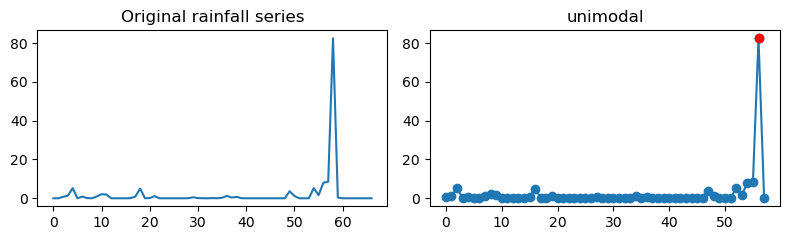

[1.4508887e-01 8.6876579e-02 3.1336224e-01 1.2653142e-01 1.1775789e-02
 6.8514380e-03 3.0576363e+00 3.2448313e+00 1.7407281e+00 4.1116753e-01
 7.2332859e-06 1.5592504e+00 3.5960455e+00 1.8014656e+00 4.0044141e-01
 3.0373105e-01 4.7056830e-01 4.3034062e-01 5.2841197e-06 2.9024115e+00
 3.0938966e-06 1.9238870e+00 4.6293057e-06 4.1877579e-06 3.4242400e-06
 2.2437432e-01 2.5090405e-01 5.0582588e-02 2.0930583e+00 3.4509128e-01
 1.0954426e-01 9.6101376e-06 2.8957609e-06 1.8546508e-03 2.6799005e-06
 5.4196312e-06 4.3702405e-02 2.5659383e-04 2.7201748e-02 8.2419336e-02
 1.1386738e-05 1.5558062e+00 2.3888313e-06 4.3800837e-06 5.8639869e-03
 5.5241894e-06 3.4056623e-06 6.1902892e-06 6.6011621e-06 1.9612064e-06
 2.0486659e-06 1.7753720e-05 4.1277826e-02 1.8460825e-02 4.2692809e+00
 1.9242847e-01 2.7521772e-03 6.8588495e+00 2.3584313e+00 3.9407808e-01
 3.7447609e-02 1.4546661e+00 3.3083984e-01 2.6912552e-01 2.5787632e+00
 5.9788804e+00 7.7765212e+00 8.7204762e+00 5.4716029e+00 7.8873616e-01
 2.223

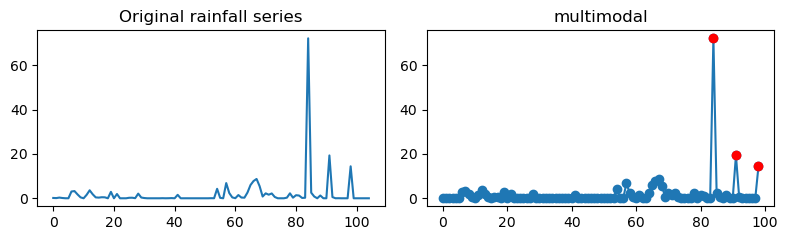

[7.5414735e-01 8.6126071e-01 5.0056772e-03 3.8546682e-06 5.1086449e-06
 2.4562564e-06 8.6519560e-03 3.1457458e+00 4.0570140e+00 4.0438533e-02
 1.0063363e-06 2.8343329e-06 2.4458457e-06 2.2903670e-02 6.2398225e-01
 3.7809203e+00 1.2661903e+00 3.3764911e+00 1.6979916e+00 1.3506680e+00
 1.2084163e+02]
Event index: 8080, result: unimodal, n_peaks: 1


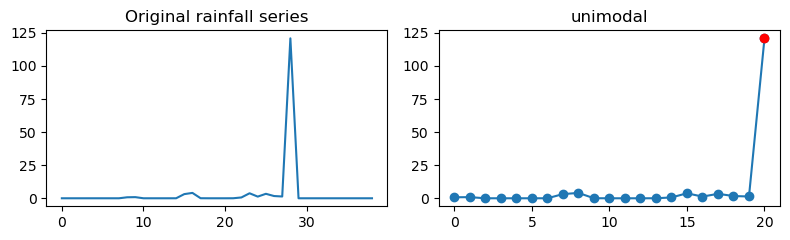

[8.8875229e+01 1.9364073e+01 4.7436878e-04 2.5036812e-04 2.9589614e-04
 1.8553660e-04 5.5621363e-02 1.3528417e-01]
Event index: 8118, result: unimodal, n_peaks: 1


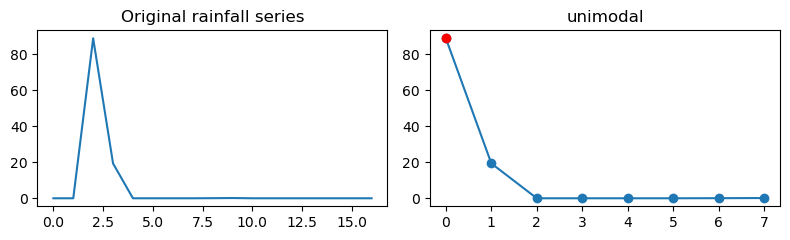

[9.1716070e+00 3.9029930e-04 7.0262837e+00 1.6946483e-03 1.0045521e-04
 2.5376385e-01 1.3504955e+00 8.1198752e-01 5.9134116e+00 8.6951377e-03
 3.7001121e+00 2.6877593e-05 2.7253081e-03 2.3430201e-05 2.3979856e-05
 5.6261610e-04 1.5971276e-04 1.2913407e+00 6.5068983e-02 7.4473906e-01
 1.3931869e+01 1.2356967e-04 2.5165486e+00 1.8201066e-05 3.7907754e-05
 4.1591360e-05 3.0149114e+00 6.4593494e-02 4.8601938e-05 7.4346358e-06
 6.5114760e+00 1.2818184e-03 1.9061765e-05 1.2823730e+00 2.7178953e+00
 1.2431080e-04 4.6127248e-06 1.4791086e-03 5.6542648e-04 7.7155407e-04
 9.4892707e-04 2.8850944e-03 1.1639220e-03 1.7556351e+01 1.2854877e+01
 3.8980163e-04 6.4109004e-04 9.3833369e-04 1.4475308e-03 1.6967073e-03
 7.6896546e-04 8.1707809e+01 3.2385268e+00]
Event index: 8119, result: multimodal, n_peaks: 3


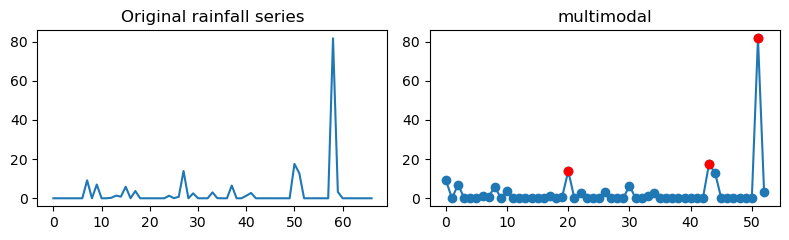

[1.3245182e-01 7.4405366e-01 7.0214081e-01 2.8990955e+00 8.9756876e-01
 5.2539432e-01 6.8375729e-02 1.3984109e-03 6.8306579e-04 2.7435194e-04
 2.0909721e-04 1.6917074e-01 1.0546249e+02]
Event index: 8120, result: unimodal, n_peaks: 1


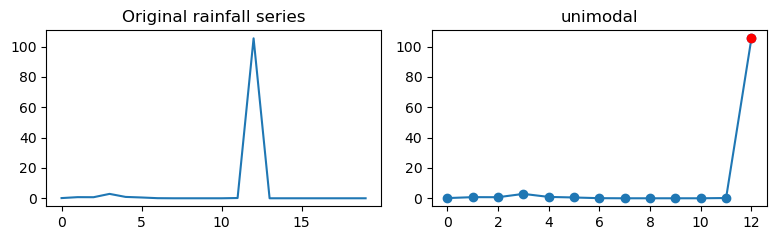

[1.45899579e-01 7.76902139e-01 9.49606228e+00 3.11272621e+00
 4.53764260e-01 4.52850236e-06 2.88568407e-01 2.15631151e+00
 1.46648479e+00 6.56564236e-02 2.58367800e-04 8.07919443e-01
 1.01738115e-04 1.06126266e-02 3.55921831e-04 1.62114418e-04
 7.81818867e-01 3.25507601e-04 1.26121784e-04 1.73879191e-04
 1.60938203e-01 6.44725189e+01 5.84809226e-04 3.08098213e-04
 2.76431820e-05 3.36766750e-01]
Event index: 8138, result: unimodal, n_peaks: 1


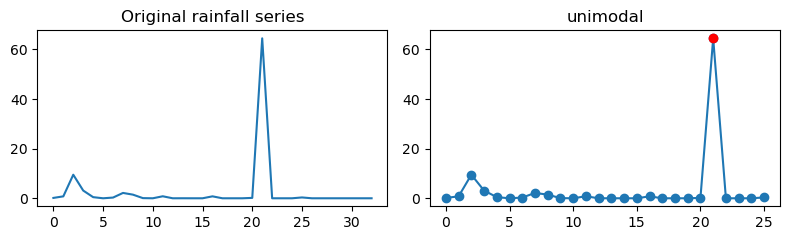

[4.0993530e-01 1.3027276e-03 1.3756749e-04 1.9233800e-04 4.5404415e+01
 1.8865716e-03 1.3692617e-04 7.9542466e-02 4.1892963e-05 7.9347177e-05
 3.8430940e-02 1.9674723e+00 3.1587020e-01 1.2564848e-03 3.8579065e-02
 1.0829756e+00 9.8167397e-02 1.8035524e+00 7.2003698e-01 2.6436472e-01
 6.0148382e-01 1.8441133e+00 5.8455753e+00 5.8103673e-02 9.3011418e-05
 1.6597461e-06 3.7712055e-01 1.4158157e+00 3.3714271e+00 5.9986359e-01
 6.8530428e-01 2.6175263e+00 4.8297656e-01 2.8761806e-06 2.0204908e-01
 2.2639878e+00 1.5330541e+00 1.9031416e+00 1.1731026e+00 2.4803204e-02
 9.1557920e-02 5.9912270e-01 5.5040246e-01 2.3373110e-05 3.0522427e-01
 1.1288475e+00 1.2469558e-05 1.8283904e-02 1.1656016e+00 1.3249788e-01
 5.2723728e-02 3.9523061e-06 3.7918307e-02 4.7914505e-01 3.4761488e+00
 2.1214612e-01 1.9014069e-06 3.8645822e-01]
Event index: 8255, result: unimodal, n_peaks: 1


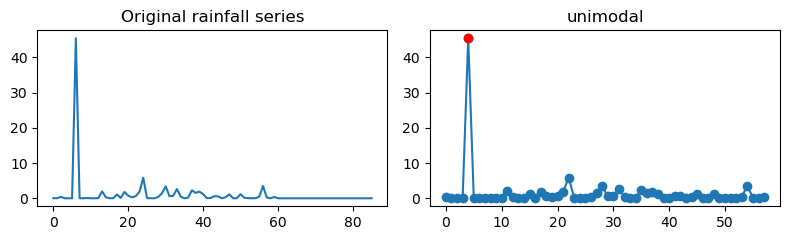

[2.2243778e-01 3.9543936e+00 1.5429561e-02 2.5356758e-01 1.6976414e+00
 2.2742060e-01 2.2197637e-01 8.0058374e-02 3.4635239e-03 1.1648141e+00
 4.0928368e+01 2.0977731e+00 8.5889387e-01]
Event index: 8266, result: unimodal, n_peaks: 1


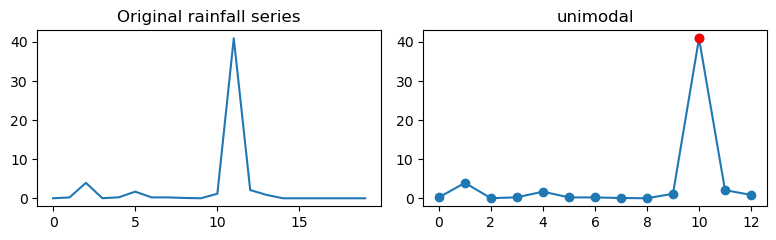

[8.4303655e-02 2.9937816e-03 2.0364419e-01 1.7422520e-01 9.6785802e-01
 2.2454994e+00 1.4599197e+00 1.5056124e+00 5.2035162e-03 9.3857643e-06
 2.9742039e-06 9.9164379e-07 2.8145145e-05 3.6605953e+01 6.5070319e+00
 6.3710553e-07 2.0178299e+00 2.3993719e+00 1.0508403e-05 5.5037577e-05
 3.9818179e-04 8.9599930e-02 6.1265612e-01 4.8247438e-02 1.1027489e+00
 5.3077784e+00 8.2132295e-02]
Event index: 8285, result: unimodal, n_peaks: 1


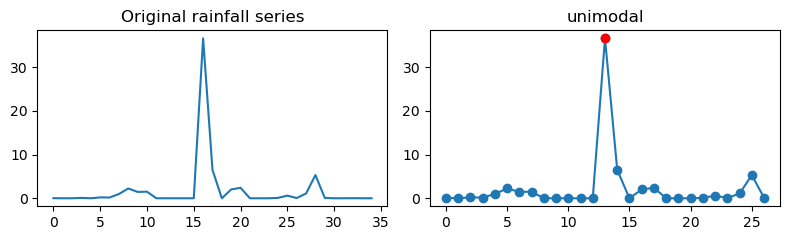

[1.2587628e-01 8.0922004e-03 1.0231801e+00 7.2057810e+00 7.5165206e-01
 2.2654451e-04 1.1694290e-06 5.3710471e-07 4.9598918e-07 1.3497877e-06
 3.4291093e-06 7.2257376e-01 2.2245440e-01 4.8378310e-01 2.2668502e+00
 3.3445284e-03 3.9306898e-02 5.4320928e-02 1.0792227e-02 1.3995381e-02
 8.7048039e-02 1.2180914e+00 4.8321121e+01]
Event index: 8314, result: unimodal, n_peaks: 1


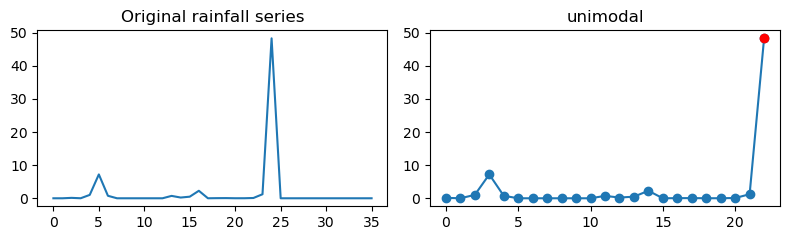

[1.3089392e+00 2.3136549e+00 2.0387593e-04 4.6660693e-04 9.0606773e-04
 1.4279153e+00 3.7932472e+01 1.7195180e-05 7.1761706e-06 6.6038997e-06
 2.1343296e+00 1.1497125e-01]
Event index: 8318, result: unimodal, n_peaks: 1


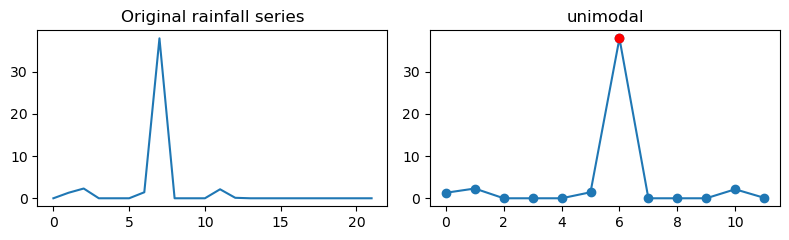

[4.20913811e+01 1.94550708e-01 3.49966605e-04 3.14146471e+00
 1.47525314e-03 4.14135837e-04 3.79973877e-04 5.01296425e-04
 4.92911320e-04 2.87108356e-04 2.81734887e-04 5.40390518e-03
 1.06527284e-02 1.93269094e-04 1.05164208e-01]
Event index: 8355, result: unimodal, n_peaks: 1


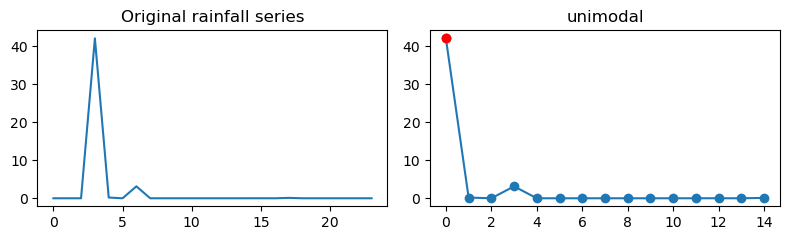

[1.22333944e+00 1.51772728e+01 1.00965989e+00 1.09934688e+00
 4.34430552e+00 3.12812161e+00 1.29752469e+00 4.08748835e-01
 7.48532563e-02 1.53976697e-02 2.33857017e-02 5.56868649e+00
 4.36193581e+01 4.81835032e+00 1.69144117e-03 6.22404292e-02
 3.74931514e-01]
Event index: 8395, result: bimodal, n_peaks: 2


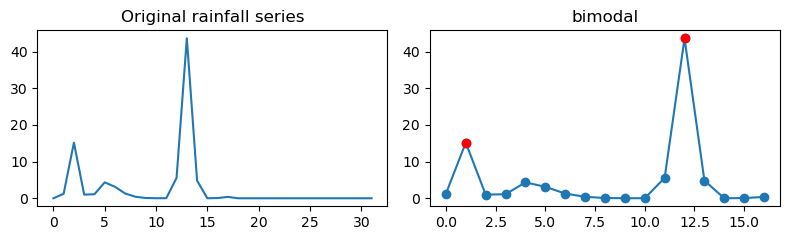

[1.9745030e+00 3.3738518e+01 1.9656462e+01 6.7794505e-03 4.0113187e-04
 2.3765571e-04 2.0564168e-03 7.1502808e-03 6.2460531e-02]
Event index: 8396, result: unimodal, n_peaks: 1


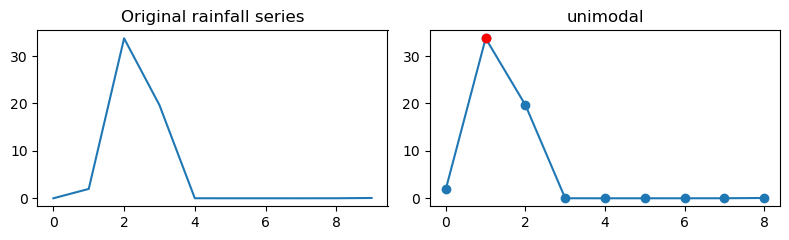

[8.3323586e-01 2.4319622e-01 1.1566180e-01 1.8675573e-02 4.0486971e-01
 4.9966411e-06 1.5033828e-06 1.4465041e-06 1.1263044e-05 2.3446021e+00
 1.5221934e+00 5.6948792e-03 1.1413927e-06 5.1624107e-07 3.6769475e-06
 2.1827080e-05 6.7015797e-01 2.9946194e+00 4.4973388e-01 6.3494952e-07
 4.1557199e-04 3.8700062e-04 1.1901614e-02 5.6435609e-01 4.9164579e-03
 1.3712053e+00 4.1443696e+00 4.6680546e+00 1.6629511e+00 3.2391044e-01
 3.3103684e-01 1.0283996e+00 2.3088785e-01 3.0990219e-01 2.4928705e-01
 3.5293725e-01 8.8994849e-01 4.1434070e-01 7.9563427e-01 4.6709411e-02
 1.2953403e+00 1.4915806e+00 2.7673694e-04 1.6519208e+00 3.8403749e-01
 1.6934914e-04 9.6801331e-04 7.5477473e-03 6.6979080e-01 3.3874908e-01
 2.1512729e-01 3.8243055e-01 7.0677161e-02 9.3474146e-03 5.7492614e-01
 5.7101402e+00 4.0927163e-01 1.1486223e-02 4.8295635e-01 1.0054929e+00
 4.3119374e-01 2.6014632e-01 4.0978096e-02 1.3448945e+00 4.2065592e-03
 1.3654011e-02 5.5433483e+00 3.5089555e+00 2.5368053e-02 1.7009251e-04
 3.855

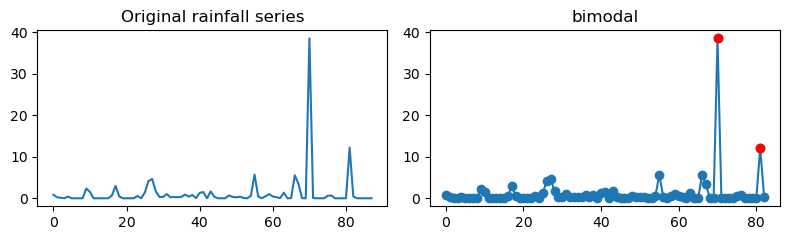

[2.1887919e-01 1.8632499e+00 1.1830682e-01 1.0361006e-05 7.0517763e-06
 3.5052724e-06 2.0247165e-02 9.8579585e-06 9.1681108e-03 1.0040383e-05
 8.8671535e-01 1.5845608e-06 2.4769151e-06 6.6269264e+00 9.2196478e-06
 1.2673109e+00 1.2393702e-06 5.8476579e-01 1.6417050e+00 2.9725626e-01
 1.7075402e+00 7.6990706e-01 5.0510908e-03 3.9840471e-02 1.4562026e-03
 1.9845396e-05 3.1886092e-01 7.3737201e-06 2.1931357e-04 3.9286911e-06
 3.5499275e-01 8.3177215e-01 1.7525981e-01 7.6518412e+00 3.3920469e+00
 1.9109937e-06 1.7140439e-06 1.2114591e-06 2.3237133e-06 1.9552472e-06
 4.3412604e-04 6.6432483e-02 2.7893102e+00 6.2445342e-04 5.7062734e-04
 3.9601837e+01]
Event index: 8636, result: unimodal, n_peaks: 1


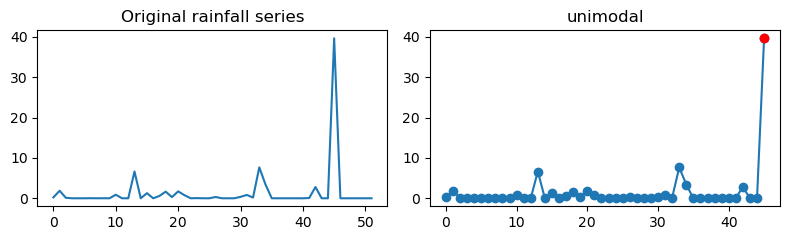

[42.733299    0.74987012]
Event index: 8638, result: unimodal, n_peaks: 1


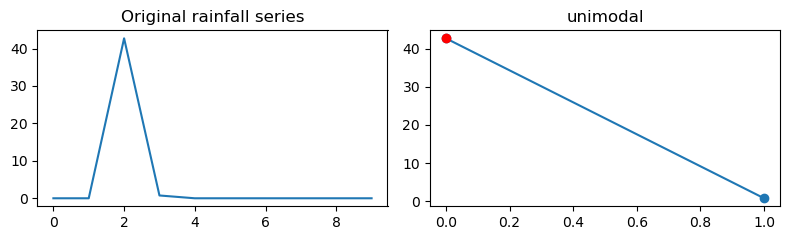

[39.399708   2.8534977]
Event index: 8645, result: unimodal, n_peaks: 1


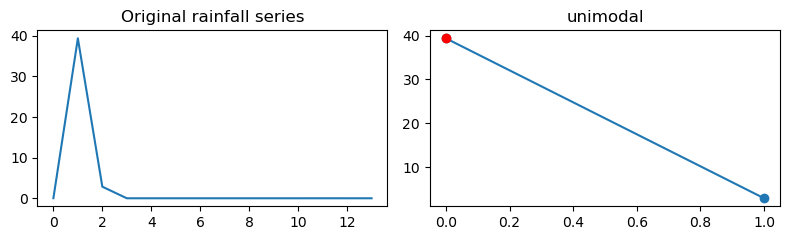

[39.349606]
Event index: 8656, result: unimodal, n_peaks: 1


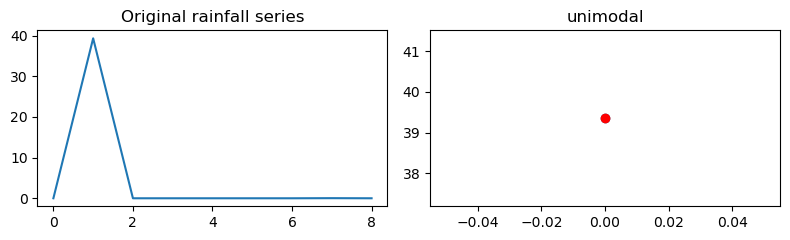

[4.5810447e+00 6.3678259e-03 3.5345228e-04 3.2931755e-04 6.0913118e-04
 1.9260171e-03 2.8963073e-04 2.4911462e-04 3.7366955e-04 4.0540029e-03
 3.1713210e-04 5.1773024e-01 3.6925834e-04 1.9684932e-04 4.6486402e-01
 3.4296440e+01 8.3404340e-02]
Event index: 8666, result: unimodal, n_peaks: 1


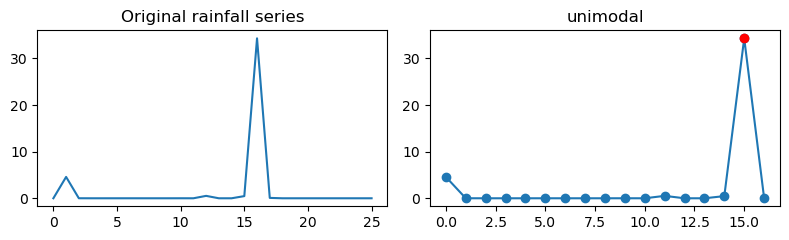

[1.58590450e+01 3.12729448e-04 4.78657399e-04 3.64821986e-04
 3.19155846e+01 3.52927628e+01 1.03161037e-01]
Event index: 8676, result: bimodal, n_peaks: 2


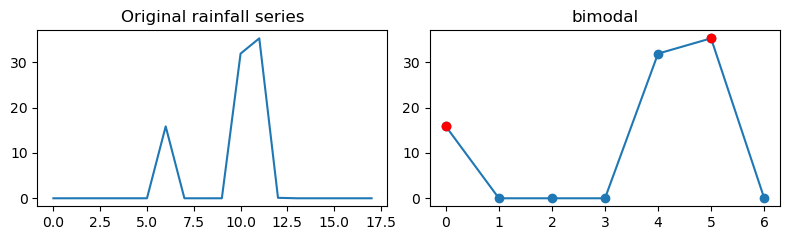

[5.7557356e-02 3.9713463e+01 2.3999004e+00 5.3471792e-02 2.3536672e-04
 5.1362562e-04 7.3192395e-02 2.8992603e-03 5.1362475e-04 4.2900961e-04
 8.7484807e-02 3.4290599e-05 1.2605100e-05 2.4322022e-03 1.7942674e-02
 4.9603677e-01 8.7155300e-01 7.3037453e+00 1.0696477e+00]
Event index: 8680, result: unimodal, n_peaks: 1


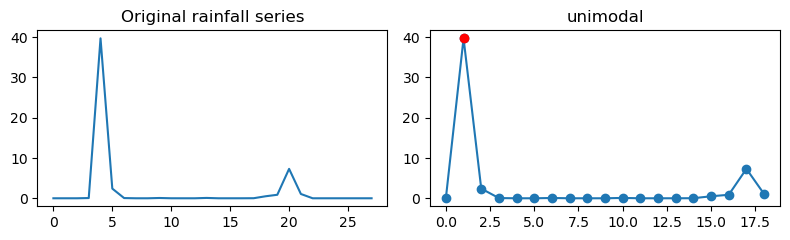

[3.2389238e+00 3.7753128e+01 1.4920656e-01 3.1747763e+00 9.4057829e-04
 1.0860230e+00 3.3886365e-06 2.4233574e-01 1.0907716e-01 3.6598843e-01
 4.4585272e-06 2.6988735e-06 7.7332406e-06 5.9864510e-06 2.7129933e-02
 2.3104655e-02 4.6458509e-04 1.9509070e-02 2.7807980e+00 3.0454836e+00
 4.5350012e-06 5.0755709e-01 2.4780838e+00 1.3801417e-01 3.9187016e-06
 9.4044626e-06 3.1495765e-05 3.9947795e-06 2.4271349e-06 1.5085416e-06
 4.3318078e-06 2.7200231e-02 2.2591722e-01 7.7936542e-01]
Event index: 8682, result: unimodal, n_peaks: 1


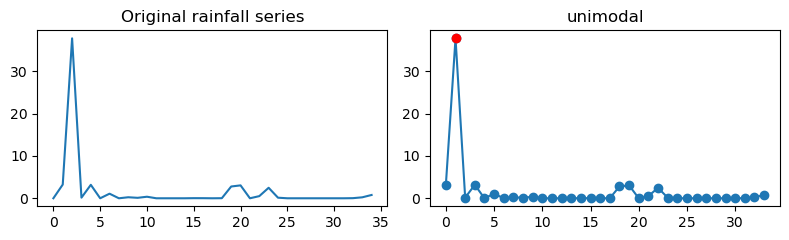

[3.3419720e+01 3.7542553e+00 3.9610917e-05 7.7790908e-05 1.7501596e-04
 1.5952035e-04 4.3705273e-01 1.7628719e+00 4.1878915e-01]
Event index: 8692, result: unimodal, n_peaks: 1


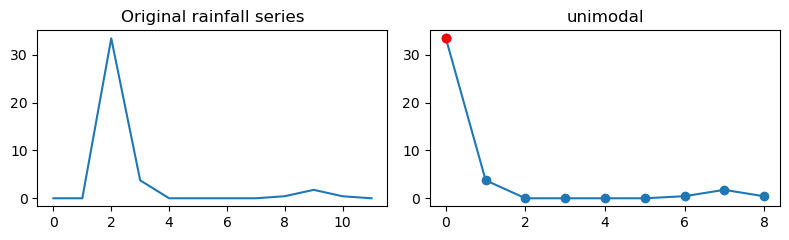

[1.2041492e+00 1.7788084e-01 2.5278408e-04 3.5674427e+01 1.1602322e-03
 2.1253121e+00]
Event index: 8697, result: unimodal, n_peaks: 1


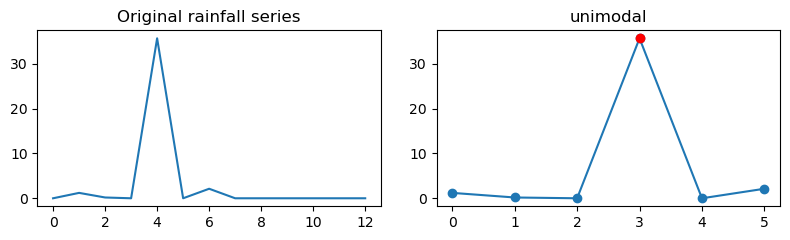

[ 1.0674506 33.343807 ]
Event index: 8711, result: unimodal, n_peaks: 1


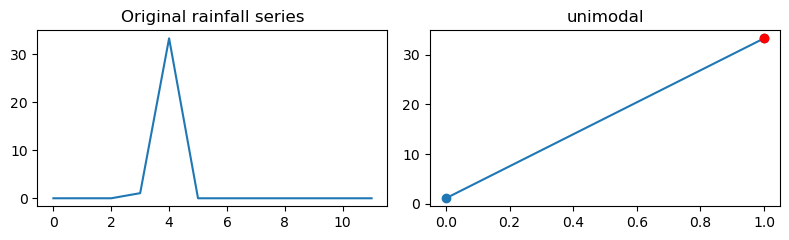

[7.7727750e-02 9.2914867e-01 5.2207673e-01 8.0568343e-02 3.2027451e+01
 4.0566382e+00 1.8007993e-03 1.3983162e-03 2.2077358e-03 2.1396847e-01
 2.6457903e+00 2.9157853e+00 3.3758886e+00 4.1515417e+00 2.5624528e+00
 8.3258903e-01 4.5850253e-01 7.7301371e-01 4.8727939e-01 2.1365860e-01]
Event index: 8719, result: unimodal, n_peaks: 1


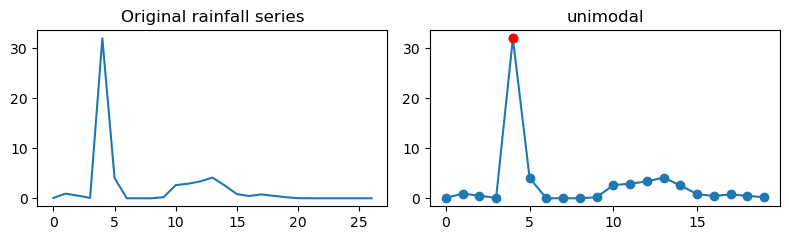

[8.5696304e-01 1.9152963e-01 1.3136519e+00 1.6977216e-06 1.4434257e-06
 3.0203162e-06 3.0147964e-03 3.9313245e+00 8.8977308e+00 7.2372642e+00
 4.5571938e+00 3.5679810e+00 1.9413669e+00 6.6382998e-01 1.3837434e-01
 6.6918475e-03 5.6271353e+00 3.1827330e+01 1.0638859e+00]
Event index: 8723, result: unimodal, n_peaks: 1


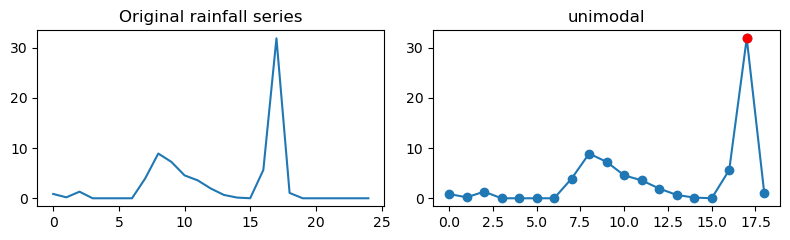

[2.0675322e-01 1.0131916e-01 4.7480166e-03 6.0332718e+00 1.7125551e+01
 1.3674103e-04 1.6172016e-04 2.0854945e-04 2.4246646e-04 2.3762354e-04
 1.5917100e-04 3.7505984e+00 6.7808423e+00 5.2751601e-02 4.3584334e-04
 3.1030521e-04 2.9048765e+00 1.2318270e-05 2.0412167e-03 1.5391649e-01
 4.6715331e-06 1.3297366e-01 8.6998669e-03 4.7192102e-06 2.6482332e-05
 5.3985238e-02 3.8519394e-01 3.5000293e+00 7.8840787e-03 1.5102932e-01
 6.9615944e-06 6.9489138e-06 1.5821713e-01 1.8507822e+00 2.1998141e+00
 2.5207639e-02 3.1032839e-01 3.5987740e+00 4.3810454e-01 5.1841757e-06
 7.1885152e-05 4.8641341e-05 1.3323925e-05 4.9078866e-05 1.8455836e-04
 1.1491989e-04 1.5836609e-04 1.0263912e-04 3.3538513e+01 2.9449539e+00
 1.2028622e-04 1.4213525e-04 1.2802283e-01 3.4822533e-01]
Event index: 8727, result: bimodal, n_peaks: 2


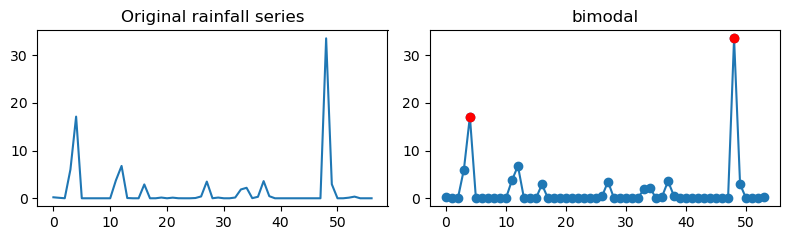

[ 0.08105113 33.276836    0.10147803  6.2040071   0.51888335]
Event index: 8728, result: unimodal, n_peaks: 1


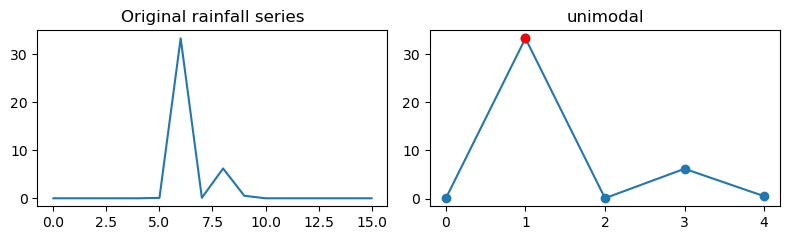

[ 0.09501205 43.939709  ]
Event index: 8730, result: unimodal, n_peaks: 1


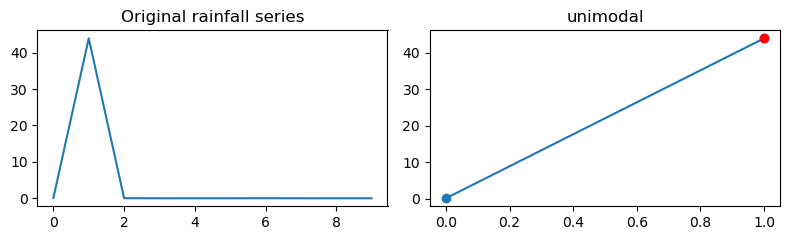

[2.2081320e-01 3.1945682e-01 1.5864533e-05 1.5140956e-04 2.0354585e-04
 1.6063094e-04 2.3208048e-04 4.6683307e-04 4.1731173e-04 2.1164484e-04
 5.7151407e-01 2.4254200e-04 2.8763540e-04 3.7535996e+00 9.7750880e-02
 1.0002971e-04 4.6318112e-04 1.2030315e-03 3.9196446e-05 3.3747105e-04
 1.6215206e-04 2.1123198e-01 3.0257439e+01]
Event index: 8731, result: unimodal, n_peaks: 1


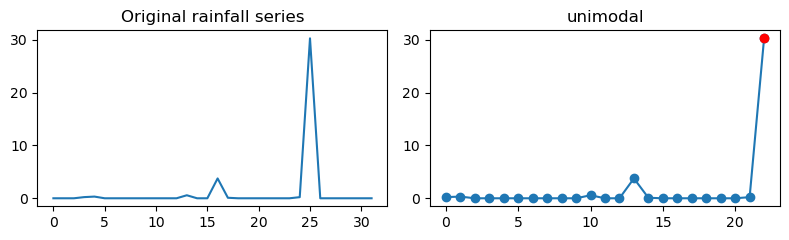

[3.9906830e-01 7.8686064e-01 3.9857894e-01 4.3519148e-01 4.5370710e-01
 1.1353534e+00 3.2495949e+00 4.9239687e-05 1.6171764e+00 3.5976281e+00
 3.2270517e+00 4.2778616e+00 1.8393060e+00 1.4700094e+00 1.4290243e-02
 6.8985671e-04 5.4892909e-04 6.6419417e-04 2.5394140e-04 9.7085163e-04
 5.0414051e-04 9.5265196e-04 5.0038699e-04 9.3538960e-04 3.1346848e+01]
Event index: 8733, result: unimodal, n_peaks: 1


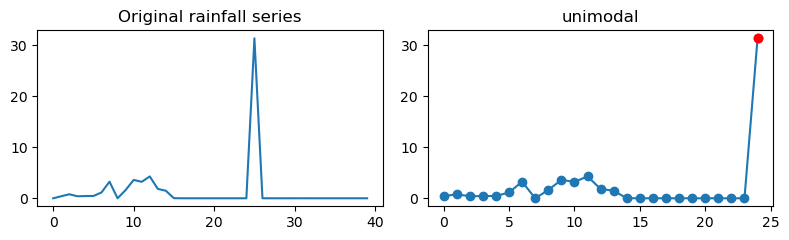

[2.5538191e-01 2.1230674e+00 4.1956669e-03 4.4278088e+00 7.0694581e-02
 9.7373417e-03 1.0544963e+00 1.4765613e-02 5.5977341e-02 5.8297406e-05
 3.0488552e+01 2.5940020e+00]
Event index: 8737, result: unimodal, n_peaks: 1


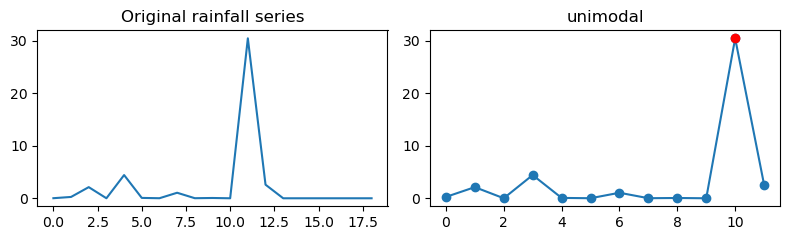

[4.94046068e+00 4.11806889e-02 2.90415483e-05 4.36324008e-05
 7.15711736e-04 2.11334584e-04 6.30982697e-01 3.75506554e+01
 3.12030673e+00 4.31709865e-04 1.35483533e-01 6.34373555e-06
 7.49956489e-01 1.64679426e-04 1.45258355e-05 8.50828644e-03
 2.23042909e-04 3.72093797e-01 3.33386630e-01 5.04963696e-01
 5.30043304e-01 1.03041381e-01 7.23667396e-03 1.30408660e-01
 3.49126117e-06 1.13861084e-01 1.16475336e-01 1.31179718e-06
 1.63113582e-03 1.78660378e-02 2.34987165e-05 2.88693857e+00
 4.87813330e+00 2.26683307e+00 7.10417225e-05 1.27933991e+00
 1.04699814e+00 9.79849473e-02]
Event index: 8744, result: unimodal, n_peaks: 1


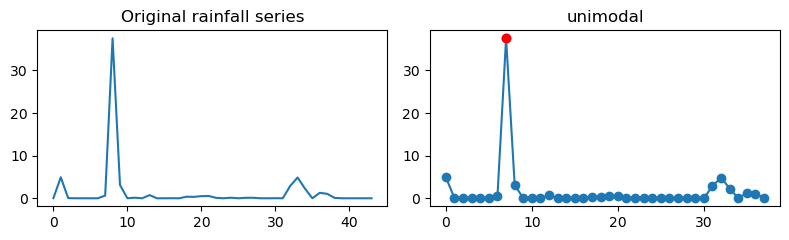

[5.3721600e+01 7.4843678e-04 3.9166826e-04 5.7548622e-04 3.7862570e-04
 3.5397618e-04 2.4170137e-03 1.0580797e+00]
Event index: 8771, result: unimodal, n_peaks: 1


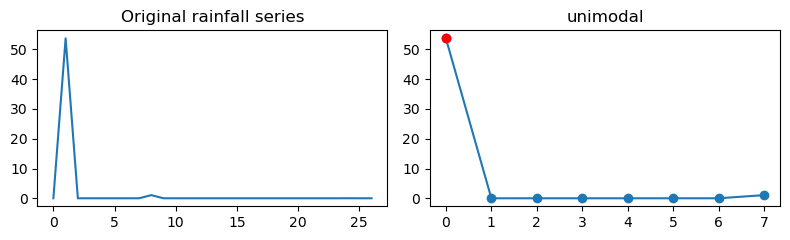

[39.228222   9.5938921]
Event index: 8777, result: unimodal, n_peaks: 1


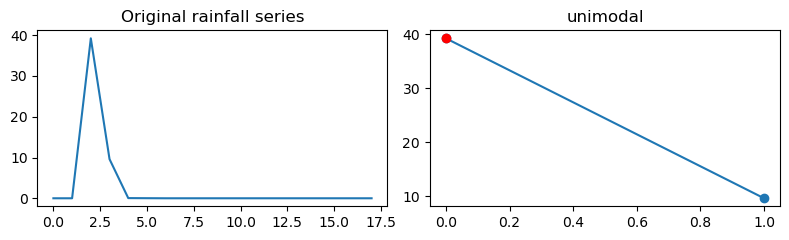

[3.51721334e+00 4.68121185e+01 2.84441223e-04 2.62952672e-04
 1.47402374e-04 2.47372751e-04 6.65578118e-05 1.17313996e-01
 5.20882569e-02]
Event index: 8782, result: unimodal, n_peaks: 1


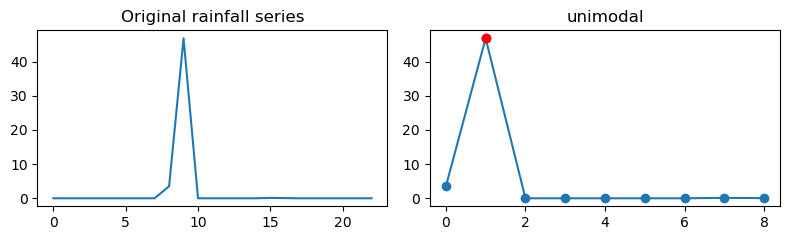

[3.22133179e+01 9.07202158e-03 2.41733942e-04 2.00785522e-04
 2.30079383e-01 6.82536793e+00 5.01779199e-01 4.12973604e-04
 6.10747302e-05 1.87948917e-05 5.89146075e-05 1.17355965e-04
 4.39006326e-05 2.23690319e+00 5.45822513e-05 3.37534759e-04
 1.42622142e-04 7.32136393e+00 1.91387701e+00 3.28729928e-01
 4.32342085e-06 7.66219044e+00 4.41834301e-01 2.08339770e-06
 2.62049050e-03 2.66487518e-06 2.13621926e+00 3.88957262e-01
 5.15759774e-02 2.57202327e-01 8.98285866e-01 1.87032003e-06
 1.47703568e-05 7.23924895e-04 2.84067583e+00 1.48359982e-06
 9.98807081e-07 4.75416076e-04 3.64153922e-01 1.48400079e-06
 2.54823733e-03 2.48434535e-05 1.09049715e-05 2.05206143e-05
 1.22319479e-05 1.95763722e-01 6.13299683e-02]
Event index: 8817, result: unimodal, n_peaks: 1


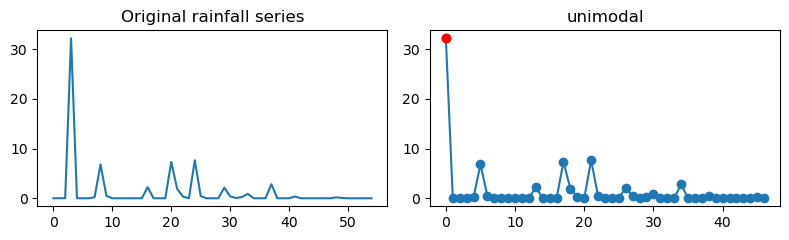

[9.6217056e+01 9.0800860e-04 7.5868797e-06 1.0454178e-05 1.6498571e+01
 1.7172033e-02 1.0710481e-05 8.0374324e-05 3.8063324e-06 4.8195025e-06
 3.4328165e+00]
Event index: 8821, result: bimodal, n_peaks: 2


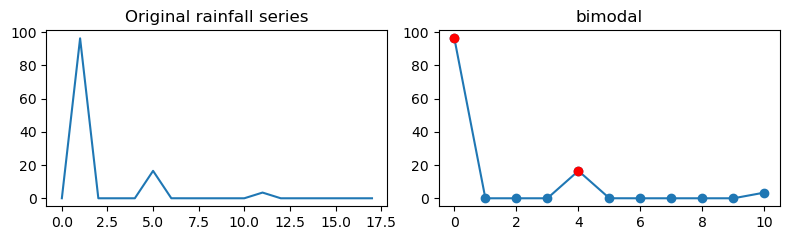

[7.2528070e-01 3.4625745e-01 3.7707870e+01 1.8273374e+00 1.7189544e+00
 2.5195930e+00 2.6825480e+00 1.3233505e+00 1.7210779e+00 1.4088801e+00
 7.9777265e-01 3.0617213e-01 4.5662907e-01 2.3432376e+00 5.9223133e-01
 5.6874835e-01 8.3653510e-01 4.5492148e+00 4.5477515e-01 4.5676759e-01
 1.2769257e-01 7.2339110e-02 4.3870095e-06 5.4528932e-06 1.0966074e-05
 9.2290659e-03 1.5949006e+00 1.3900795e+00 7.9445062e+00 2.5274138e+00
 6.0568082e-01]
Event index: 8827, result: unimodal, n_peaks: 1


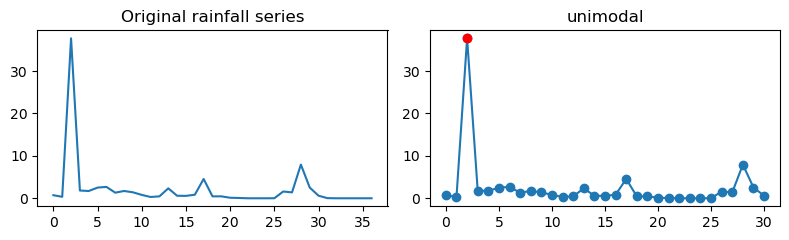

[105.09225      7.7997246   77.627388     0.30324116]
Event index: 8829, result: bimodal, n_peaks: 2


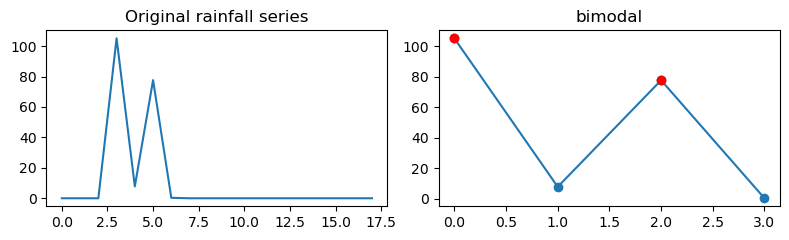

[5.05685546e-02 4.51554823e+00 3.84552666e-04 6.02382682e-02
 1.02931214e-02 5.73504585e-05 3.14512968e+00 4.92196113e-01
 2.07582951e+00 7.04948689e-05 3.21856804e+01]
Event index: 8840, result: unimodal, n_peaks: 1


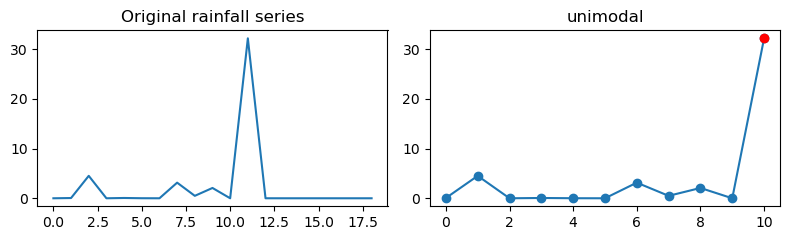

Pixel 522: 84 events
[33.567287]
Event index: 7215, result: unimodal, n_peaks: 1


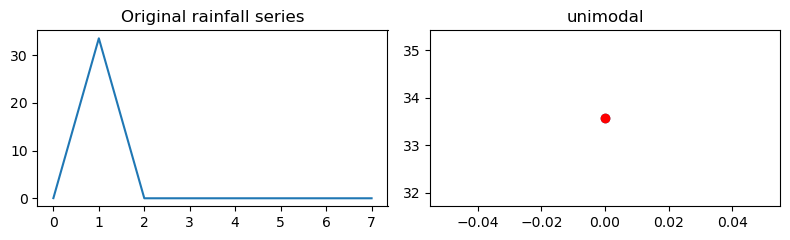

[3.3166063e-01 3.3420944e-05 5.8839047e-05 3.2114756e-05 2.4556916e-02
 3.3237297e+01 9.2661248e-05 9.0464782e-03 1.8086978e+00 2.2982719e+00
 1.8993988e+00 5.4435175e-02]
Event index: 7350, result: unimodal, n_peaks: 1


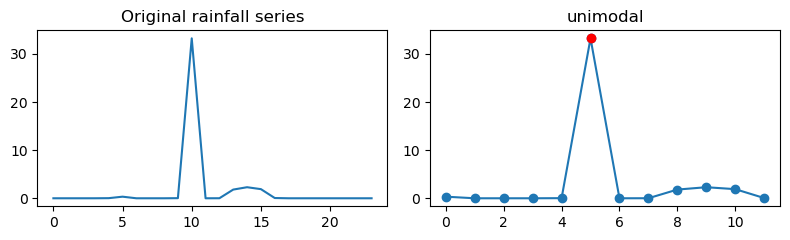

[2.8249044e+00 2.7169522e-02 1.2994829e-03 5.6402368e-04 1.3346802e-03
 9.3007274e-04 5.8292435e-04 3.9531165e-04 7.8334923e+01 3.2554808e+00
 1.7542288e-01]
Event index: 7376, result: unimodal, n_peaks: 1


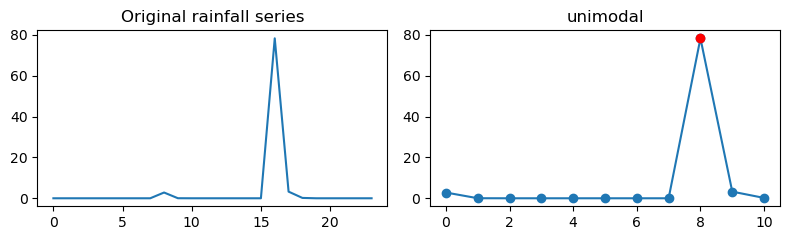

[57.234425]
Event index: 7385, result: unimodal, n_peaks: 1


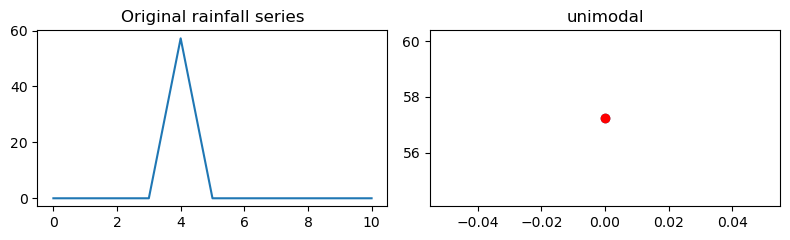

[2.1445928e+00 9.2300123e-01 8.4348655e-01 5.3976303e-01 7.2259587e-01
 3.0885479e+00 7.5251199e-02 1.7299511e+00 1.2804390e+00 3.1548936e-06
 7.7928570e-07 1.5718486e-02 3.0671576e-06 1.5376372e+00 1.8034346e-01
 3.6206127e-06 8.8912034e-03 5.2428355e+00 2.4651672e+01 5.6250896e+00
 3.9498053e-05 5.6989116e-05 6.4075699e-05 1.0115480e-04 5.4725057e-05
 4.4844095e-05 4.7343445e-05 1.9092327e-05 1.4855097e-04 1.9503987e-04
 1.3253269e+00 7.3875847e+00 2.0911583e-01 1.4574386e-02 3.2804091e-03
 3.0791525e-05 3.6604291e-05 8.0768768e-05 3.4602141e-05 1.3415494e-04
 9.4158378e-05 6.8657595e-05 1.6410310e-04 4.1166606e-04 1.9334079e-04
 6.9792026e-05 1.4783739e-04 2.0299901e-04 6.6908562e+01]
Event index: 7388, result: bimodal, n_peaks: 2


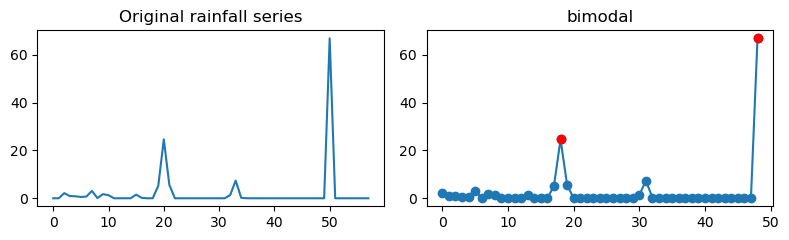

[8.00194815e-02 1.77486124e-03 4.33842577e-02 2.59287071e-06
 2.52404623e-02 3.66463223e-06 6.92104186e-06 3.86576517e-04
 2.86270224e-04 2.57139350e-03 3.15724988e-04 1.73574756e-03
 3.72133791e-01 3.69132652e+01 2.91219978e+01]
Event index: 7399, result: unimodal, n_peaks: 1


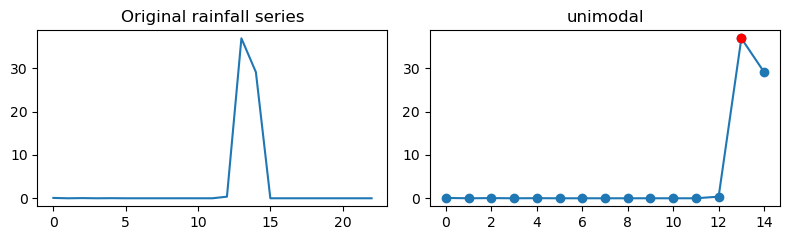

[3.5486212e+00 1.1482386e+01 2.8707741e+01 2.2361422e+00 4.4259118e-06
 9.8835444e-05 4.3458241e-01 7.3545459e-07 3.3272845e-06 1.0254441e-06
 3.9855081e-06 1.6244863e-01 5.6841171e-01 1.4109368e+00 6.0227215e-02
 3.2601547e+00 3.1853873e-01 1.1553402e-06 9.9884628e-06 1.5699714e-04
 7.1355221e-06 1.2338169e-04 3.1600031e-01 2.7877753e+00 2.9696691e+00
 2.3633843e-06 4.8191209e-06 2.4918372e-06 1.7598388e-04 4.2796085e-04
 4.1997811e-04 6.0938358e-01 7.7345400e+00 5.5483571e-05 8.0207676e-05
 4.4507851e+01 9.7619772e-01 1.4400812e+01]
Event index: 7407, result: multimodal, n_peaks: 3


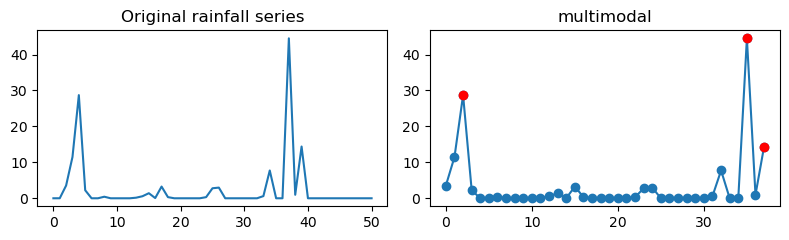

[4.4318062e+01 8.3059769e+00 1.6323479e-01 6.3614622e-02 5.3318071e+00
 1.0832870e-01 9.4858189e-07 2.1936244e-06 3.7496577e-07 7.5459160e-02
 1.3797249e-01 1.9990659e+00]
Event index: 7412, result: unimodal, n_peaks: 1


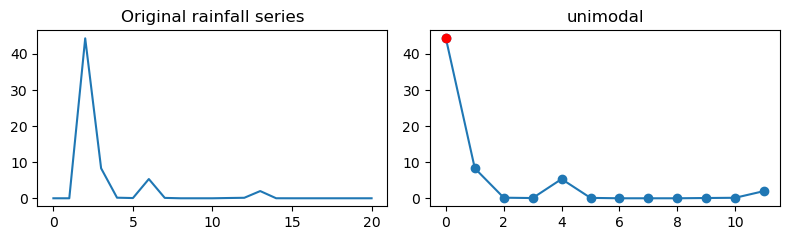

[2.5130475e-01 6.4717781e+01 2.6548037e-02 3.7086365e-04 3.2897643e-04
 4.5229486e-04 5.1666189e-05 1.7124077e-04 5.5971008e-02]
Event index: 7413, result: unimodal, n_peaks: 1


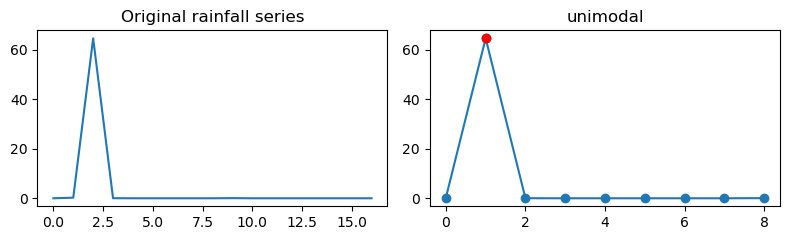

[7.1106464e-02 8.7396929e-06 1.4418079e-06 4.0258437e-02 2.1960952e-06
 1.4299768e+00 4.1614994e-06 3.4220895e-01 5.0895329e+00 4.2241472e-06
 5.2127833e+00 2.3363677e-05 4.8607352e-04 1.7996547e+00 5.0922852e+01
 1.9635153e-03 2.2583657e-04 2.0625532e+01 5.6315780e-01 5.6360255e-04
 5.2572885e+00 6.0849350e-02]
Event index: 7415, result: bimodal, n_peaks: 2


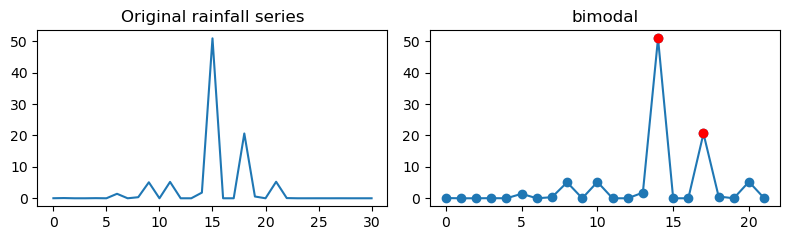

[48.272221    0.14338064]
Event index: 7439, result: unimodal, n_peaks: 1


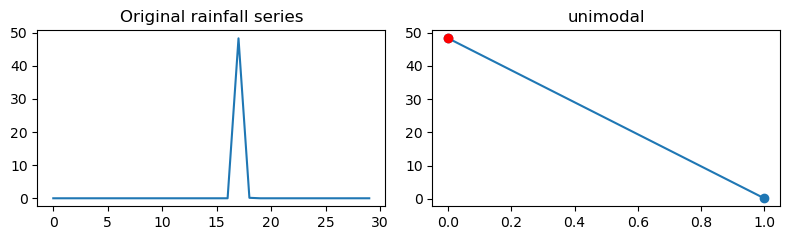

[ 4.73270178 64.1767273   1.79816842 12.3536453 ]
Event index: 7449, result: bimodal, n_peaks: 2


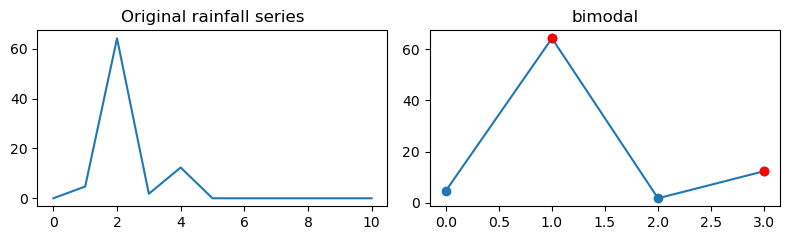

[7.26872301e+00 4.21231031e+00 1.45668328e-01 1.65691063e-01
 6.45279139e-02 2.05773897e-02 2.46261224e-01 5.22673547e-01
 1.14158630e+00 1.30484331e+00 1.80411065e+00 1.69279838e+00
 3.32141852e+00 5.51804081e-02 9.47313674e-06 1.74285958e-06
 6.25738263e-01 6.80320784e-02 3.70635848e-06 7.59141669e-02
 5.64213097e-01 1.44213289e-02 1.68745646e-05 1.67082965e-01
 1.10927749e+00 5.53522632e-02 6.51334047e-01 3.92751427e+01
 5.88256195e-02 5.47447383e-01]
Event index: 7457, result: unimodal, n_peaks: 1


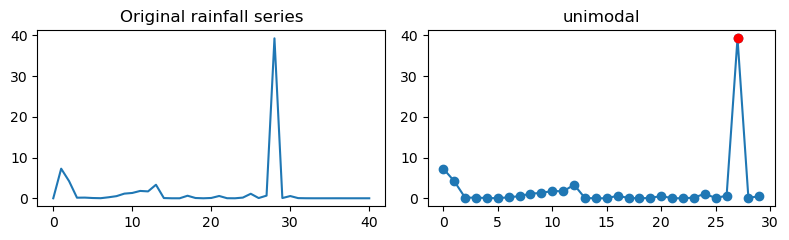

[6.4966049e+01 1.5149026e+01 3.2638886e-04 2.7673602e+00 1.4008169e+01
 5.1152147e-04 6.6841059e+00 5.7369356e+00 6.8314041e+01 1.3069526e+01]
Event index: 7464, result: multimodal, n_peaks: 3


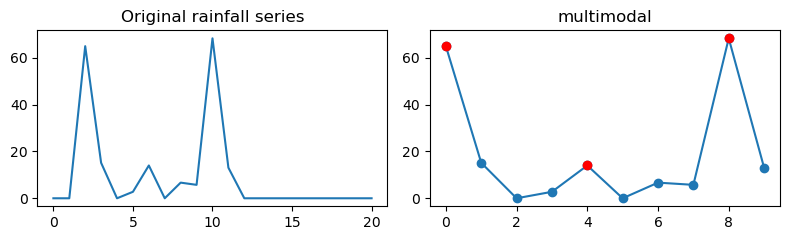

[4.88747418e-01 2.16061139e+00 2.35893941e+00 2.49524474e+00
 2.67390800e+00 1.61424208e+00 1.74497157e-01 1.63718127e-02
 2.71328259e-03 1.10556730e-05 1.30198693e+00 6.07031822e-01
 3.92102629e-06 1.01677061e-03 4.71236330e-04 3.12396312e+00
 7.50647116e+00 9.53679180e+00 1.78160146e-04 7.83691998e-04
 7.55417673e-03 2.67357407e+01 1.09075516e+02 5.26021584e-04
 2.68760690e-04 8.52246885e-04 1.03793154e-03 1.40101492e-01]
Event index: 7470, result: unimodal, n_peaks: 1


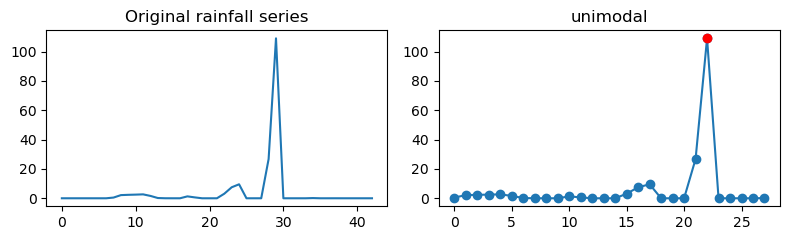

[96.392036   41.397282   20.134329    0.97775245  5.785428   34.379196
  2.841712    0.13335916  0.65649891]
Event index: 7476, result: bimodal, n_peaks: 2


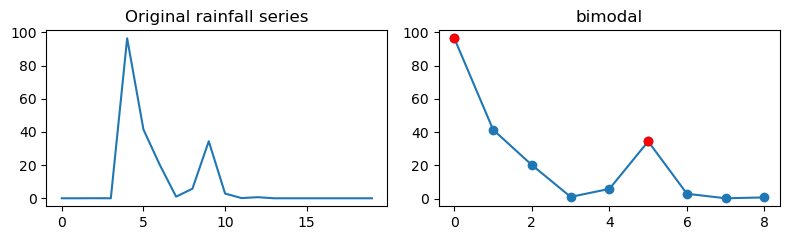

[8.28841400e+01 1.64736259e+00 2.91638637e+00 2.83035564e+00
 2.84792924e+00 1.35413671e+00 5.77282012e-01 2.55155349e+00
 2.61183405e+00 2.03290868e+00 3.07819009e+00 3.75232100e+00
 1.67866385e+00 4.84518185e-02 2.36533061e-02 2.13584471e+00
 3.28388989e-01 3.63243133e-01 7.05922348e-03 4.39562544e-04
 1.54890768e-05 8.40957455e-06 7.38936724e-05 2.87156086e-04
 2.91818196e-06 4.08130945e-05 2.63114795e-02 2.34374049e-04
 6.86261628e-05 1.85256433e-02 2.04170108e+00 5.50435036e-02
 9.25987542e-01 3.01092076e+00 6.46347587e-04 7.16761017e+00
 1.40119445e+00 1.50940645e+00 2.70321488e+00 1.73593871e-05
 1.55567850e-05 3.20596737e-05 1.43003953e+00 2.45553184e+00
 2.71271110e-01 9.33632145e-06 3.80347046e-06 2.00921331e-05
 3.26196514e-02 5.68090439e-01 5.52166641e-01 1.24497557e+00
 1.70360088e+00 9.71691430e-01 1.69386423e+00 3.25750899e+00
 2.51435041e+00 2.97272992e+00 2.98834801e-01 1.50073379e-01
 2.00052929e+00 5.20512629e+00 5.45378949e-04 1.39719432e-05
 5.59029922e-06 3.772058

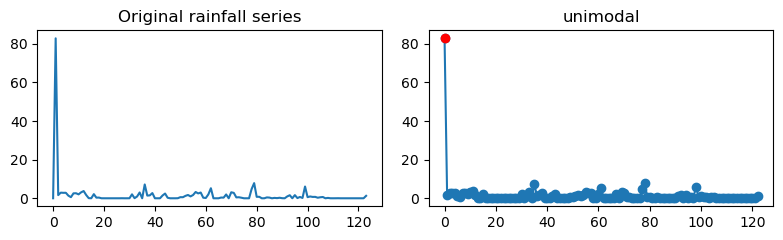

[4.5021752e-01 2.3899052e+01 2.0981215e-05 3.0236955e+00 1.0649343e+01
 2.1839705e-03 1.3597663e-03 6.4580300e-04 2.9334508e-02 1.2774502e+01
 1.1740937e+01 2.3212845e+00 5.5936718e-01 2.2909977e-01 4.4639641e-03
 2.9349707e-03 1.0726522e+01 2.6717045e+01 9.1855508e-01 7.7787086e+01
 1.0966614e+01 2.4363275e+00 2.0534822e-01]
Event index: 7511, result: multimodal, n_peaks: 4


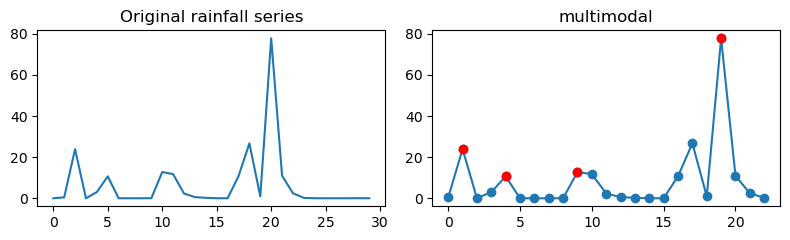

[3.5601962e-01 7.9495300e+01 1.1757246e+00 7.8897327e-05 4.5034409e-05
 1.3615865e-04 1.1617209e-02 8.2514278e-05 7.3452509e-05 7.0200411e-05
 1.4189667e-05 3.6210167e-05 5.4342105e-05 3.9252666e-01 1.4304155e-01
 4.5970379e-04 9.3113948e-03 8.1652851e-04 3.2203048e-02 1.7333503e-01
 3.9821899e-01 1.8179280e-01 8.3556241e-01 5.0025135e-02 1.7882572e+00
 3.5047493e+00 3.8017237e+00 3.7828662e+00 2.6177981e+00 1.6312685e+00
 4.8887843e-01 6.9212270e-01 2.6438627e-01 6.4467114e-01 9.1299808e-01
 2.1986096e-01 1.1561565e-01]
Event index: 7513, result: unimodal, n_peaks: 1


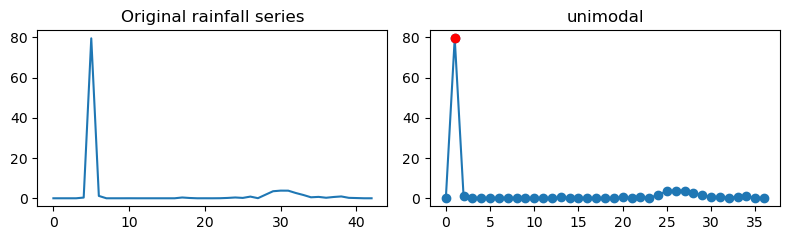

[2.4630411e-01 6.0845252e-02 4.4801901e-04 2.7046317e-02 2.2737567e+00
 1.4131047e-02 2.6008871e+00 5.5913657e-01 8.1521368e-01 1.0120262e-03
 4.8191610e-04 1.1230348e+00 1.0116654e+01 4.6515198e+01 6.1331581e+01]
Event index: 7514, result: unimodal, n_peaks: 1


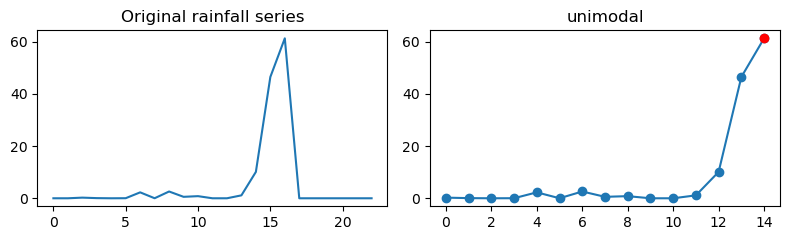

[1.3038255e+01 2.3470044e-02 4.6324081e+00 1.5826675e-03 3.0808526e-04
 9.0374151e-04 3.6662685e+01 9.2245731e+00]
Event index: 7517, result: bimodal, n_peaks: 2


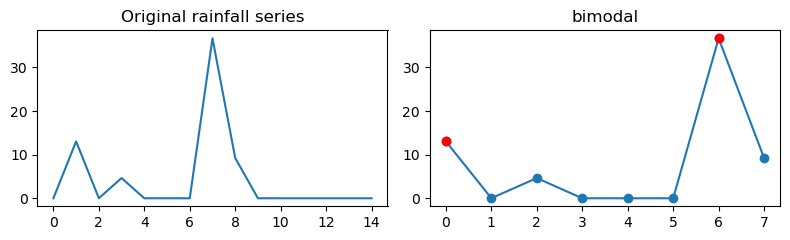

[1.24978268e+00 5.75971961e-01 6.06793794e-04 1.22964907e+00
 1.67725599e+00 3.30740714e+00 6.32525110e+00 6.60352278e+00
 5.71037960e+00 5.64392948e+00 1.64966404e+00 1.41213843e-06
 4.63570982e-01 3.70968199e+00 3.53086853e+00 2.83914304e+00
 3.20955482e-03 2.33925581e-01 1.30784836e+01 9.55940783e-03
 1.11553004e-06 1.42633576e-06 3.57318868e-07 1.00684122e-06
 7.64885158e-07 1.06702372e-03 1.54048681e+00 1.26557291e+00
 8.09980631e-02 8.68593156e-02 2.20357794e-02 8.47687900e-01
 2.73536849e+00 4.27548528e-01 1.14161949e-05 2.63766646e-01
 3.73358536e+00 3.33784781e-02 7.41395401e-04 2.29320861e-03
 1.05213013e+01 4.10323296e+01 8.81150341e+00]
Event index: 7518, result: bimodal, n_peaks: 2


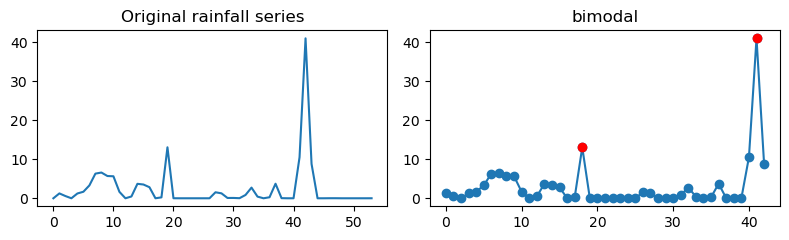

[1.1646663e+00 2.1282108e+00 1.1721351e+00 5.3382468e-01 1.3508335e-01
 4.2938683e-03 3.4951361e-05 3.9201393e-03 1.2357851e-06 5.2859338e-07
 5.0099862e-07 5.1255665e-05 2.4136953e+00 2.6735125e+00 9.6357177e-04
 5.4272114e-06 2.2639331e-06 1.4274335e-01 3.0707481e+00 5.3573358e-06
 1.5170143e-06 1.1375865e-02 2.0106213e-01 2.2552757e-02 1.4865575e-03
 1.1540091e-04 7.6192504e-01 8.1457719e-02 5.4298457e-02 8.7603551e-01
 3.1461024e-01 2.3311384e+00 2.7119615e+00 1.8655082e-02 9.3247980e-01
 3.7537763e-01 6.9873095e-01 1.9916811e+00 4.5091775e-01 1.0748084e+00
 3.9065330e-06 1.1316717e+00 4.0398011e-01 1.3909785e-06 1.5161643e-06
 2.1606138e-06 9.2083917e-07 7.5759669e-07 1.4165793e-06 3.0358377e-01
 5.7759714e-01 2.5834618e+00 2.0565021e+00 1.0909107e+00 8.1676185e-01
 5.7160970e-02 3.5502608e-06 2.0985028e-01 1.8161346e+00 1.3435457e+00
 7.1067053e-01 1.8462796e-02 1.6803734e-01 1.5401730e-02 1.2970176e-01
 9.2273802e-03 3.1542617e-03 3.6725239e+01]
Event index: 7532, result: unimod

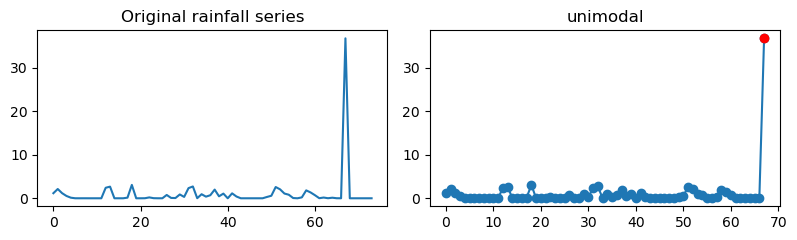

[3.4374107e+01 1.6215869e-04 5.3585303e-04 4.1349436e-04 4.4559559e-04
 6.4911984e-04 3.8179508e+01]
Event index: 7538, result: bimodal, n_peaks: 2


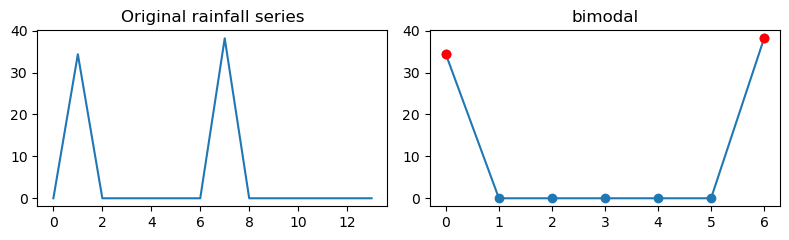

[ 1.3882037   1.7186172   0.53194195  1.092392    3.1520665   2.8047853
  1.9851968   2.6910112  57.959423  ]
Event index: 7543, result: unimodal, n_peaks: 1


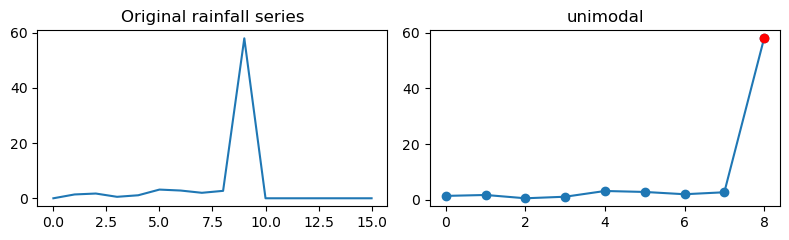

[1.4459760e-01 1.9788171e+00 2.4651514e-01 5.5408553e-04 9.7874683e-05
 7.3936681e-04 2.3112977e-03 4.1733417e-04 9.2237984e-04 2.9383547e-04
 4.8670394e-04 2.2765334e-01 2.9809089e-04 1.3073660e-04 7.5852068e-04
 3.1983122e-04 1.3951169e-04 3.1389612e+01 1.2423052e-04 1.3390145e+01]
Event index: 7550, result: bimodal, n_peaks: 2


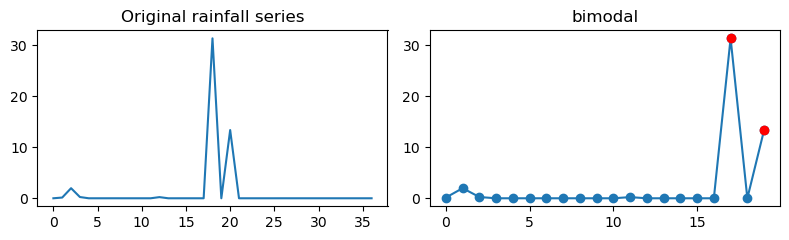

[1.9139071e-01 4.0633063e+00 1.5264412e-04 7.6819182e-05 2.3518958e-04
 2.7534092e-04 2.1602898e+00 4.3701397e+01 1.1242272e+00 5.2203333e-01
 3.0416992e-01 2.7336669e-01 4.4219270e-02 4.8637863e-02 5.0602704e-02
 6.2465239e-07 1.8566055e-07 3.1815600e-06 3.5247326e-02 1.1749689e-01
 4.4963244e-01 2.4349449e+00 2.3511659e-01 1.5899225e-04 3.3992724e-03
 6.7818830e-05 1.1056446e-06 1.3765887e-06 1.4899082e-01 2.7083914e+00
 2.6293907e+00 2.7079866e+00 1.0112150e+01]
Event index: 7551, result: bimodal, n_peaks: 2


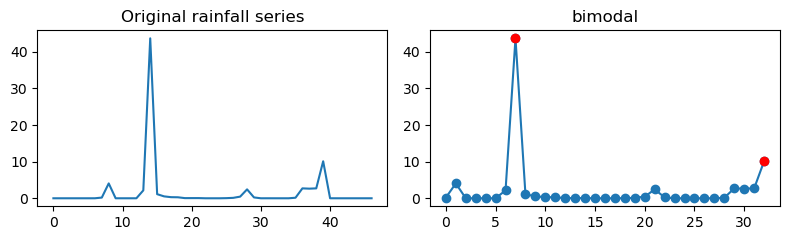

[12.571542  33.113064   3.0844564]
Event index: 7552, result: unimodal, n_peaks: 1


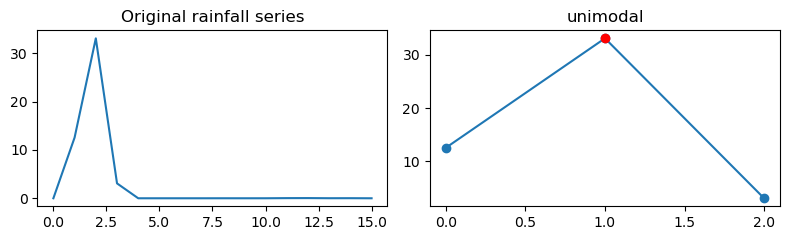

[2.0767815e+00 3.0530455e+01 1.1081792e-02 2.7056248e-03 1.4247504e-04
 1.8625225e-04 1.4722589e+00]
Event index: 7555, result: unimodal, n_peaks: 1


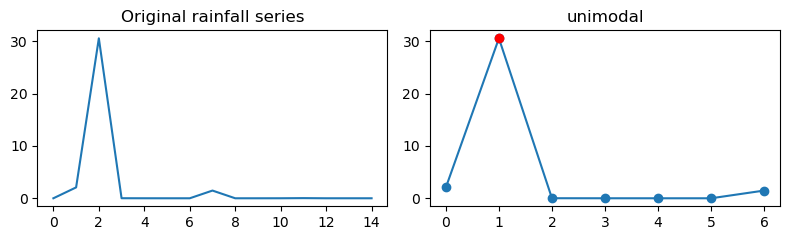

[2.31253290e+00 3.22999763e+01 9.61152136e-01 8.30862118e-05
 1.18420087e-01 8.56828243e-02 1.27617791e-01]
Event index: 7559, result: unimodal, n_peaks: 1


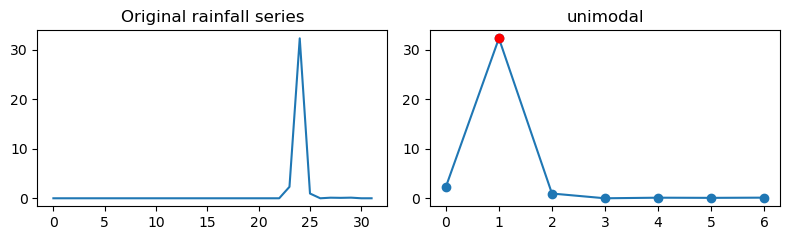

[41.004879]
Event index: 7560, result: unimodal, n_peaks: 1


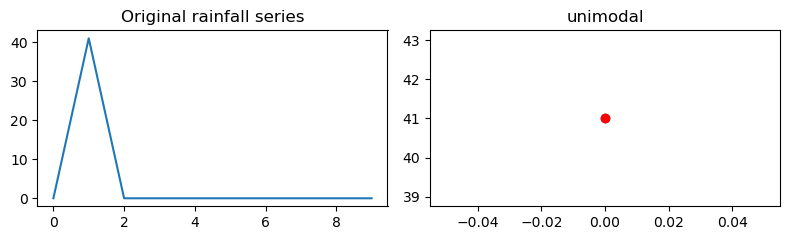

[5.2199787e+01 1.2033297e+00 8.9185202e-01 8.4567163e-04 5.0750369e-04
 5.1471987e-04 1.4579575e-01 2.6279963e-03 6.9024332e-04 2.1103679e-04
 6.6489971e-05 5.2531395e-05 1.8705039e-05 1.4688022e-05 2.4707592e-04
 1.1422278e-03 5.3823675e-05 7.3520343e-05 1.3943922e-05 1.2819620e+01
 2.7681101e-05 1.1373398e+00 8.7123444e-05 6.3241512e-01 6.6014071e+00]
Event index: 7561, result: bimodal, n_peaks: 2


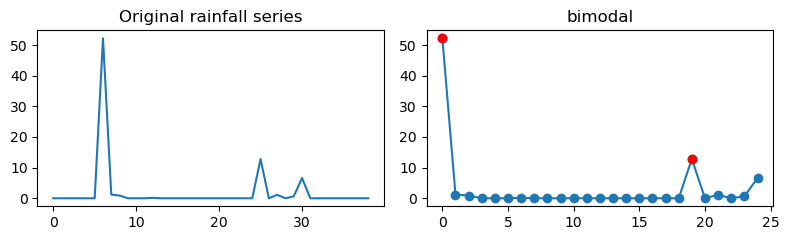

[7.3686916e-01 1.2732098e+00 4.6229435e+01 6.7452696e-04 6.6292239e-04
 7.0581085e-04 5.8443088e-04 6.3878251e-04 1.1225964e+00 2.1607182e+00
 3.3798214e-04 3.9003312e-04 7.0871523e-04 5.9900852e-04 9.0672611e-04
 4.2117844e-04 4.1962645e-04 3.6261094e-04 2.5275609e-04 3.4123159e-04
 8.5626976e-05 3.7212361e-04 2.1932130e+00 3.1475531e-04 3.3889076e-04
 8.2978973e+00 3.1716040e-01 1.4388082e-04 1.1791582e-03 1.4979751e-03
 3.9440321e-05 9.7240627e-05 3.5489707e-06 4.8235247e-06 5.8559822e-06
 5.6646980e-02 3.2334870e-01 3.6941210e-06 3.3921322e-06 7.0505866e-06
 3.1651921e-06 1.2889063e-06 9.5872633e-07 2.9359519e+00 3.3018860e-01
 1.0787230e-02 2.0527713e-01 3.6584444e-03 3.4756002e-01 6.1464216e-06
 3.1064503e-06 1.1546724e-05 5.5221144e-02 3.5016674e-01 6.9418349e+00
 2.7283611e-02 1.0440259e-05 2.0102731e-05 8.9319197e-05 1.2836543e+00
 2.6345288e-03 5.5558852e-05 2.5631402e+00 2.8314743e+01 9.9397711e-02
 5.4111093e-05 6.6195120e-05 8.0452010e-05 7.6082790e-05 3.3435668e-04
 5.396

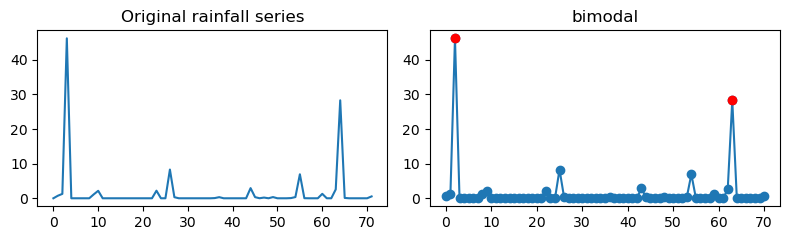

[1.5133520e+00 4.3854852e+00 2.9707372e+00 1.6955445e+00 1.8330829e+00
 5.3802973e-01 3.9534953e-01 3.7210935e-01 1.7485812e-03 1.4385873e-06
 1.7350219e-01 3.9898357e-01 1.2443410e-06 7.4992118e-07 1.0271795e-02
 3.3611264e-02 2.1731286e+00 1.2776245e-06 8.4047556e-01 2.3717065e-01
 7.6299483e-01 3.8634257e+00 2.0376922e-04 1.0617281e+00 2.2842798e-06
 1.3434875e+00 1.0140059e+00 5.6324539e+01 6.4007807e+00 3.2868037e-01
 3.5585122e+00 1.9945052e-01 1.3996243e-01 4.6332929e-01 8.2667884e-07
 2.4718290e-06 2.6536659e-06 1.7625189e-06 2.6517987e-06 9.2847988e-02]
Event index: 7661, result: unimodal, n_peaks: 1


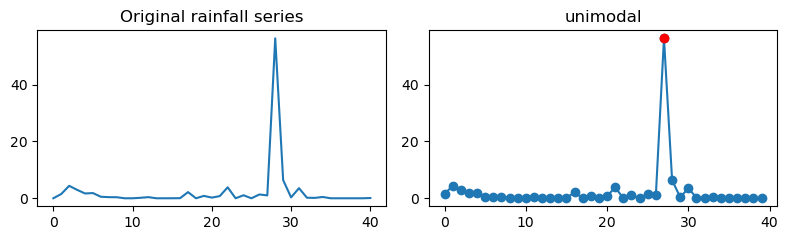

[ 1.3948824   0.85194081 31.900364    0.4533672 ]
Event index: 7709, result: unimodal, n_peaks: 1


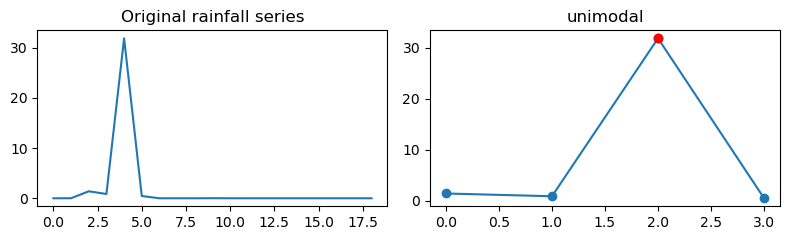

[ 0.29942471  1.1022502  32.729904  ]
Event index: 7769, result: unimodal, n_peaks: 1


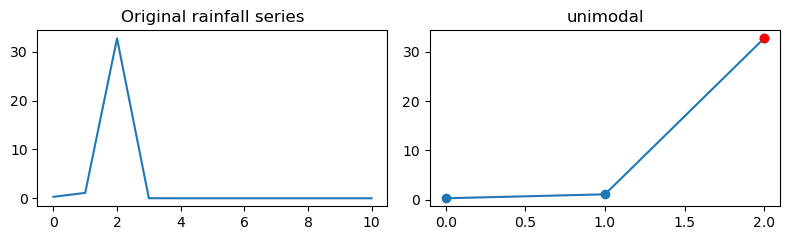

[2.9338732e-01 9.6559840e-01 4.1696054e-01 7.3587388e-02 8.9719135e-01
 5.3614087e+00 2.6598826e-01 1.5299186e+00 2.6402774e-01 3.6593869e-01
 1.2244284e-06 2.2097574e-01 3.2390319e-02 6.0727662e-01 2.0520762e-01
 6.7402160e-01 5.6639861e-02 2.3500681e-01 2.0923727e+00 8.9243352e-02
 6.3886088e-01 1.3627598e+00 5.6863759e-02 1.4137934e-05 4.7773909e-05
 2.3668783e-05 1.7859989e-05 2.1825528e-05 2.1582666e-05 3.1212065e-05
 2.4520134e-05 4.0933740e-04 2.3820308e-05 4.6035515e-05 1.5673378e+00
 8.9774631e-02 2.0446572e+00 1.0160680e+00 2.6625141e-05 8.0360900e-05
 2.4598214e-05 1.3176075e-01 2.1816072e+00 1.4385571e+00 4.7057362e+00
 4.3333840e-04 3.7599690e-04 5.1417144e-04 3.0606138e-04 1.7324775e-04
 2.4934535e-04 2.2419316e-03 5.1848462e-04 8.3013503e-05 3.7785436e-04
 1.7953853e-04 2.0026370e-04 2.2128268e-04 3.3555497e-04 4.9225829e-04
 2.3903507e-03 6.1921118e-04 4.3905989e-04 2.9196215e-04 2.1389141e-04
 1.6893391e-04 8.4866268e-05 9.4098687e-05 4.1328331e+01 6.6372831e-06
 4.161

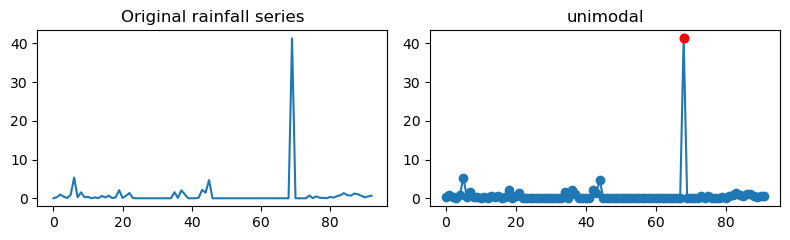

[8.8564165e-02 3.0665804e-02 6.3899714e-03 2.5057769e+00 3.0981943e+01
 6.3213817e-04 5.7973485e-03 3.6457142e-01 2.8231444e+00 7.0904069e-02
 1.9511129e-04 5.2662572e-04 4.6910896e-05 4.2392069e-04 5.0500705e-04
 1.1687805e-03 5.3340063e-04 2.1158670e-04 3.2623921e-04 4.7469983e-04
 4.5384787e-04 9.2836410e-05 3.8669747e-04 2.1315643e-01 2.0025645e-03
 1.3776397e-03 1.3269355e-03 9.6898322e-04 5.1621598e-04 9.1282191e-04
 2.6553267e-04 6.9645457e-02 8.6972110e-02]
Event index: 7893, result: unimodal, n_peaks: 1


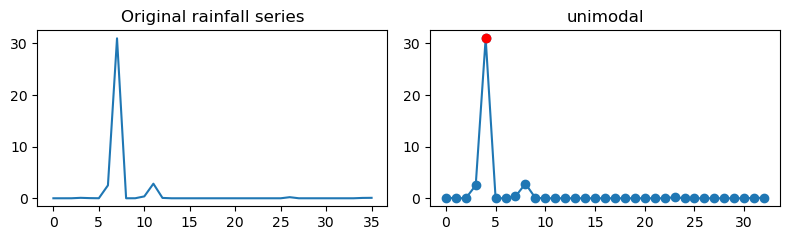

[4.16930342e+00 7.57467365e+00 3.09995890e+00 1.89523578e+00
 4.34390163e+00 4.65704397e-05 2.05484263e-04 1.26683854e-05
 1.65518199e-03 2.60451406e-01 9.15158033e-01 1.10284194e-01
 2.22273755e+00 4.37694132e-01 7.18638301e-01 9.50723886e-01
 1.52607501e-01 2.42418662e-01 5.21772563e-01 2.70426679e+00
 1.22948134e+00 3.08984685e+00 3.75252306e-01 1.30096054e+00
 1.69244587e+00 2.66589433e-01 1.28989279e+00 7.58780539e-03
 1.64732730e+00 2.01602027e-01 4.68559665e-06 9.73586248e-06
 5.62124178e-02 2.24832278e-02 1.24651599e+00 1.44355163e-01
 1.27911270e+00 3.21168423e-04 3.03474031e-02 3.15132350e-01
 3.76585007e-01 1.81216276e+00 2.03651488e-01 1.94766699e-06
 1.29622752e-02 1.74785808e-01 3.02554917e+00 8.01606476e-01
 1.34048894e-01 4.39601868e-01 1.39285810e-02 1.03861779e-01
 1.80828393e+00 3.55021912e-04 1.67073560e+00 1.91216993e+00
 6.59956038e-02 3.15972827e-02 7.53611021e-05 4.02515650e+00
 1.92145025e-03 3.44101503e-03 9.92394984e-02 2.62008118e-03
 5.69008946e-01 2.644364

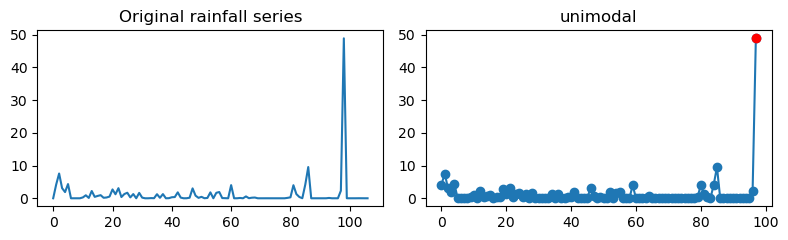

[72.087624]
Event index: 7927, result: unimodal, n_peaks: 1


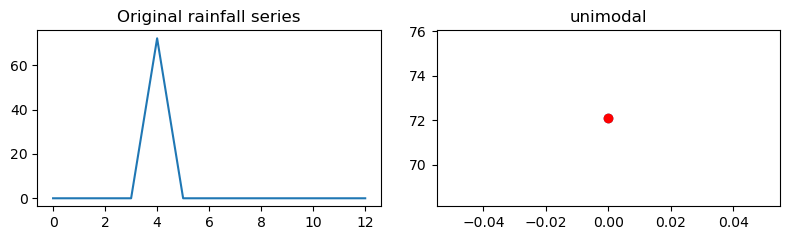

[3.4810896e+00 6.6693893e+01 4.5795259e+00 1.1785249e-05 2.0790093e+00
 4.0631328e+00 1.0802959e-05 1.4551717e-05 1.3256622e-06 4.8443634e-02
 1.3005261e-01 3.6924539e-05 1.0793525e-05 1.1427508e-05 6.8133081e-06
 4.4744570e-02 7.2800312e-06 4.2116517e-06 1.8589400e-05 1.2350723e-05
 1.9052626e-05 2.4020677e-05 6.5874290e+00 4.6062927e+00]
Event index: 7932, result: unimodal, n_peaks: 1


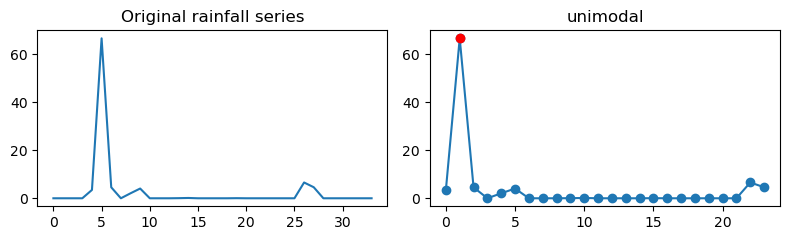

[1.2398159e-01 4.9560766e+00 1.9453445e+01 3.0104332e+01 1.3955556e+00
 1.4741821e+00 1.1170163e+00 1.1090127e+00 1.4344835e+00 1.6527613e+00
 1.4475906e+00 1.0207248e+00 9.3281385e-04 6.4108849e-01 8.8455093e-01
 1.3550116e+00 1.6612787e+00 1.8659253e+00 1.0200839e+00 2.1046385e-01
 2.7018130e-01]
Event index: 7981, result: unimodal, n_peaks: 1


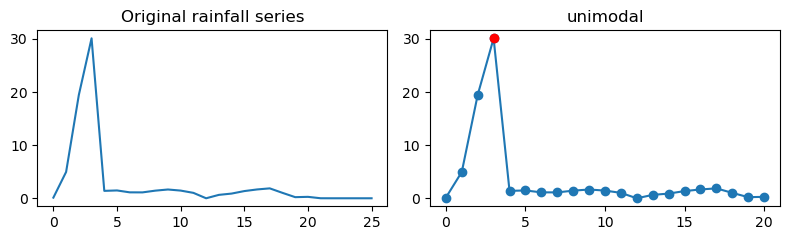

[8.8627033e-02 2.9194266e-01 3.9165916e-06 4.4496237e-06 2.1943018e+01
 1.1000272e-04 4.5351006e+01 7.6452219e-01]
Event index: 7982, result: unimodal, n_peaks: 1


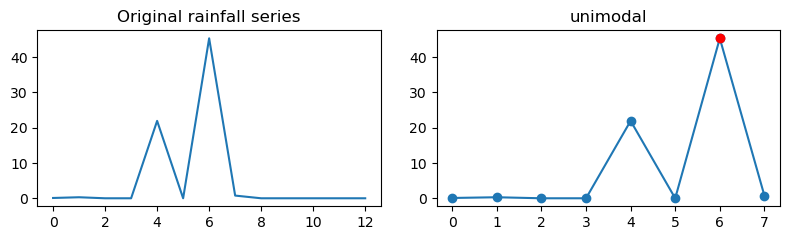

[56.110435]
Event index: 8015, result: unimodal, n_peaks: 1


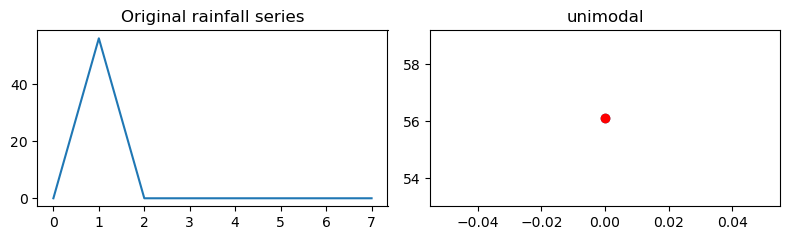

[4.0081152e-01 6.8808745e-06 6.8364034e-07 5.8028537e-01 3.2668278e+01
 1.2557809e+00 3.5520326e-05 1.8234158e-06 6.7992323e-07 4.6176863e-01]
Event index: 8030, result: unimodal, n_peaks: 1


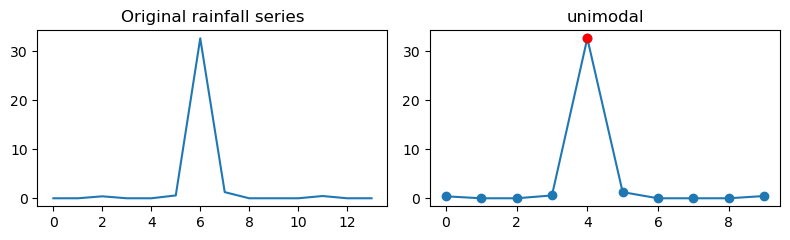

[6.8158173e+01 9.3097036e-04 1.4150081e-03 4.8436594e-01 5.1194515e-02
 2.8299221e-01 7.7790119e-06 8.0335849e-06 2.4144232e-02 1.9433937e-03
 1.8015202e-05 1.1978102e-01 2.1044010e-01 1.4663687e-05 8.5621350e-06
 2.6713800e-01 8.6230822e-02 8.6266900e-06 5.6984350e-06 1.0253881e+01]
Event index: 8076, result: bimodal, n_peaks: 2


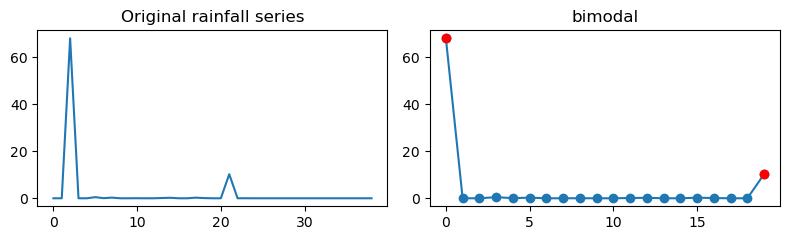

[7.74043274e+00 5.61384125e+01 3.48289108e+00 1.36215296e-02
 3.08691997e-05 3.18268917e-06 9.59597766e-01 2.40778780e+00
 5.08239794e+00]
Event index: 8081, result: unimodal, n_peaks: 1


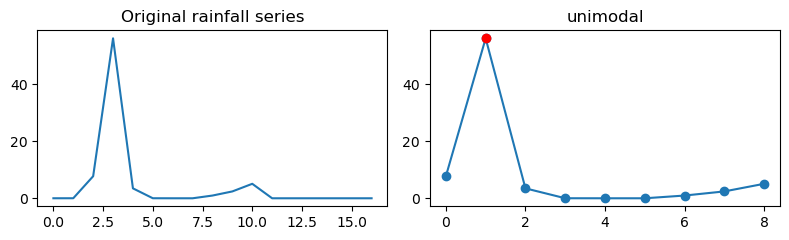

[ 0.10449486 56.847546  ]
Event index: 8094, result: unimodal, n_peaks: 1


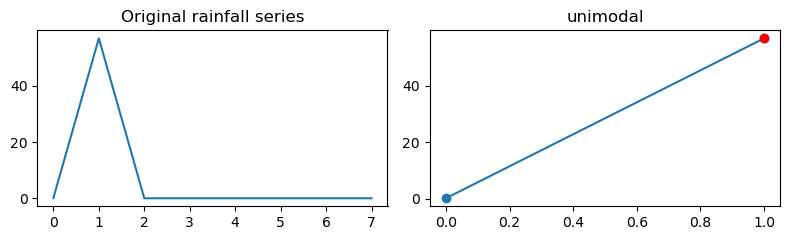

[6.4161148e+00 1.1604489e+00 9.8080151e-02 8.4657870e-02 5.2276149e-04
 4.2844191e-01 4.5894630e+01]
Event index: 8097, result: unimodal, n_peaks: 1


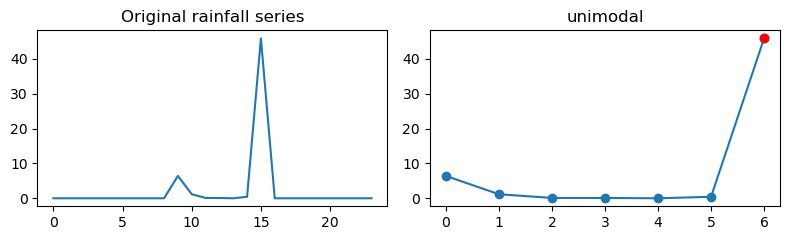

[ 8.4378605 50.165939   2.1465902]
Event index: 8117, result: unimodal, n_peaks: 1


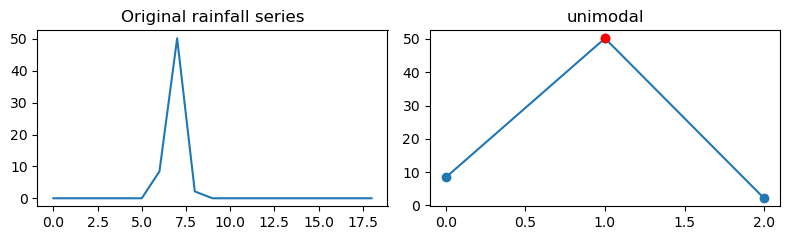

[3.6576423e-01 1.7154723e-06 4.4183831e-05 2.2470300e-05 9.1946475e-07
 1.6153200e-07 5.0126522e-07 3.1379994e-05 2.3664053e-07 1.1178586e+00
 4.3543926e+01 1.6503914e-01 1.1047480e-06 4.4849980e-07 4.0468003e-05
 5.0329804e+00 2.6145647e+00 9.4138175e-02]
Event index: 8173, result: unimodal, n_peaks: 1


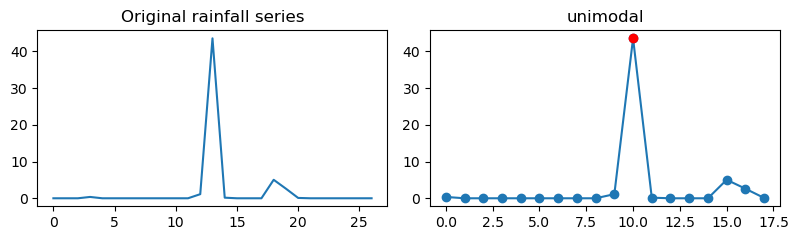

[4.3984365e-01 1.5289565e+00 5.2645401e-04 3.5907820e-01 7.7104855e-01
 5.4937946e-06 1.7112758e-06 2.9971311e-06 3.0254236e-07 1.6723635e-06
 1.1636848e-06 1.0629615e-06 1.3976883e-06 2.5818217e-06 3.6878321e-01
 1.1986817e-06 8.0062258e-01 4.5313347e+01 2.0434134e+01 2.6859775e-01]
Event index: 8204, result: unimodal, n_peaks: 1


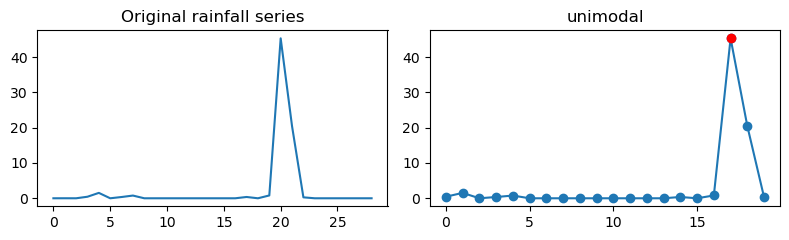

[3.8866474e+01 3.8823578e-01 4.5539595e-02 7.9730487e-01 6.2413460e-01
 2.4917878e-03 1.9973477e-05 2.2909052e+00 2.4422252e-01]
Event index: 8329, result: unimodal, n_peaks: 1


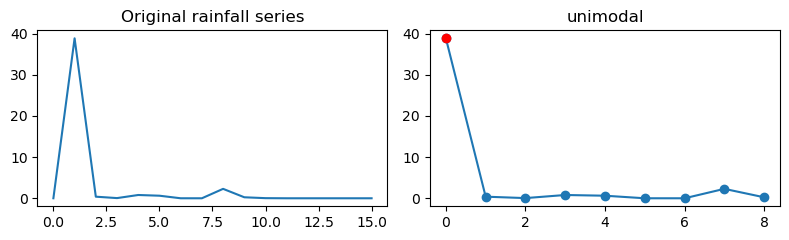

[ 2.9631259  1.9022985 21.318022  46.960953   2.1614671]
Event index: 8336, result: unimodal, n_peaks: 1


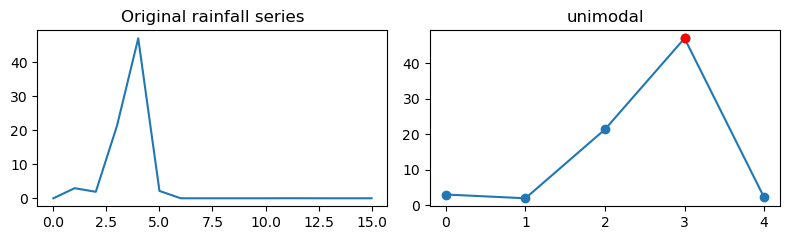

[1.1387638e+01 5.9291708e-01 1.7001372e-04 3.3749976e+00 5.0805545e-01
 4.8008407e-04 9.7853423e-04 7.4685431e-01 1.1566081e-03 1.5228249e-04
 1.0125900e-03 4.2064629e+00 1.6954880e+01 7.6687202e-04 1.1656377e-03
 9.8256080e-04 2.6982576e-03 3.0922319e+01 4.3466945e+00 8.6090080e-02]
Event index: 8341, result: multimodal, n_peaks: 3


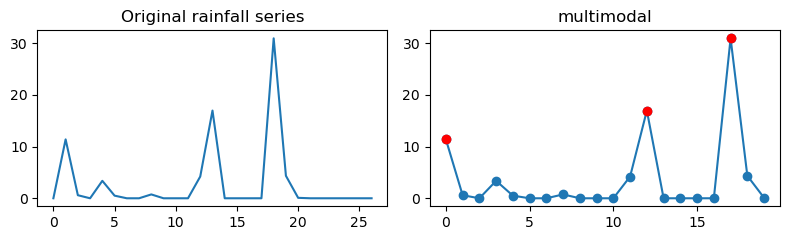

[1.23906147e+00 3.48245125e+01 8.60019326e-01 1.48530602e-02
 6.69719651e-03 1.30293760e-02 7.97215700e-02 4.13948834e-01
 2.32062602e+00 1.81624994e-01 3.77537936e-01 6.23975039e-01
 6.09377742e-01 6.73501194e-01 6.91649735e-01]
Event index: 8349, result: unimodal, n_peaks: 1


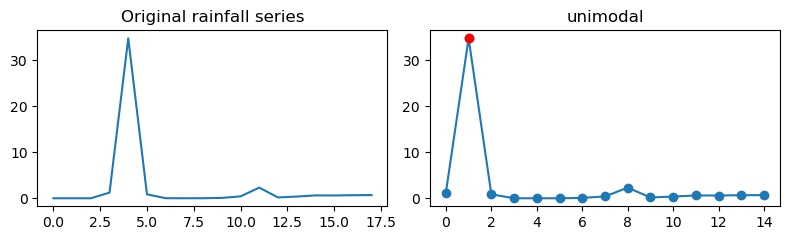

[1.7047220e+01 1.8612501e-04 3.1805910e-05 2.0249090e-05 6.0770493e-05
 2.9214176e-05 8.6145890e-05 2.9681249e-05 6.3358551e-05 2.6472728e-04
 1.4204005e-04 3.2775645e-04 5.5861834e-04 6.0514413e-04 2.7020887e-04
 4.9105819e-02 3.1150476e-04 2.1913952e-04 2.8903928e-04 6.7402783e-04
 1.1923092e-03 5.3243188e-04 5.9901719e-04 1.2269956e-03 3.3336071e+01]
Event index: 8412, result: bimodal, n_peaks: 2


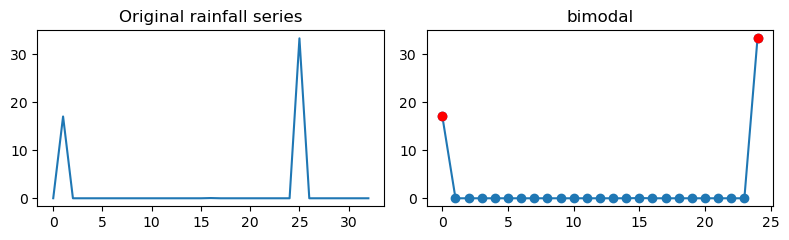

[5.0803953e-01 1.7708384e+01 3.2529434e+01 1.5978017e-07 3.6315721e-06
 3.0477779e-06 4.4860439e-03 5.1712251e-01 2.5537983e-01]
Event index: 8487, result: unimodal, n_peaks: 1


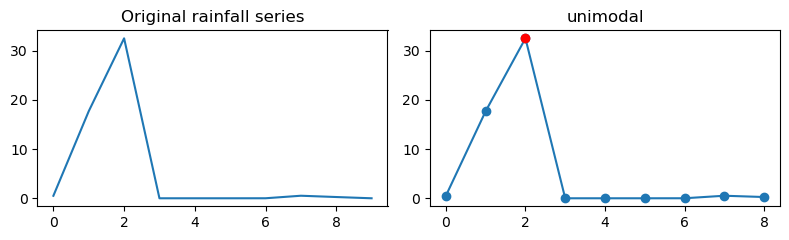

[1.1769951e-01 1.7687113e-03 6.4807036e-06 5.8679957e-06 9.3462322e-06
 9.8003626e-01 3.7511063e-01 2.9627099e-05 5.9561253e-01 8.2259786e-01
 2.7711469e-01 3.2278502e-01 4.3387645e-01 6.8785554e-01 1.1524570e-01
 3.0295035e-02 1.4520968e+00 2.1393912e+00 2.2857827e-03 6.0048187e-06
 6.4102359e+00 4.3875084e+00 4.5806774e+01 5.9241128e-01 1.9480361e-01]
Event index: 8489, result: unimodal, n_peaks: 1


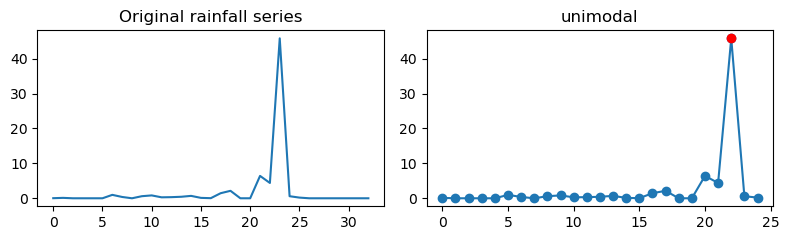

[ 0.05789337 48.94828     9.8509645 ]
Event index: 8493, result: unimodal, n_peaks: 1


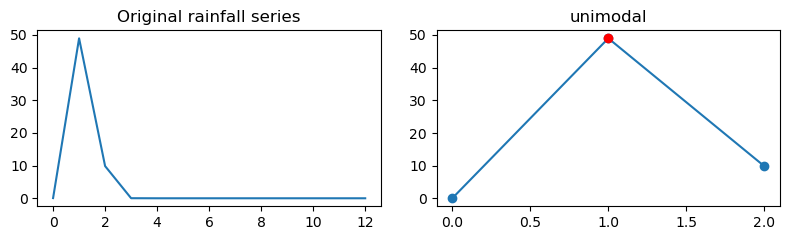

[8.9589640e-02 2.5725451e-06 1.4414672e-05 2.5685579e-02 1.1229799e-01
 4.0613036e+00 2.4915469e+00 3.6659759e-01 1.1416541e+00 1.3978116e-01
 1.8852311e-06 2.4070644e-06 2.9106622e-04 8.8936304e-06 3.3438680e-04
 1.5610623e+00 5.5147372e-02 5.3157610e-01 4.5599421e-03 2.2419721e-01
 5.8430374e-02 8.4922620e-05 3.4154483e-04 1.3112491e-01 1.4052317e+00
 7.5097928e+00 7.9237200e-02 1.6279285e+00 2.1870539e+00 2.3330419e+00
 2.0873632e+00 1.0060368e-01 1.7286619e+00 2.3447473e-01 9.9303104e-02
 2.3932901e-01 1.7160338e-01 7.9240268e-01 6.7570130e-04 1.9681577e-06
 7.9346675e-04 1.9936399e-01 3.7036132e-02 7.0024719e-03 1.1174392e-04
 4.2713064e-01 1.1925004e+00 9.5444053e-01 1.9438267e-02 2.5882876e-02
 1.2262934e+00 1.0158117e+00 7.9861302e-03 3.2391760e-02 8.3027101e-01
 1.9297436e-02 2.8795975e-01 2.4312618e-01 7.9829888e-03 5.9746418e+00
 6.7871169e-04 7.3714446e-06 2.0295806e+00 3.7622106e-06 5.1759857e-06
 5.0131325e-06 1.4232669e-06 6.1202213e-06 1.7204914e-04 1.8427054e-03
 4.330

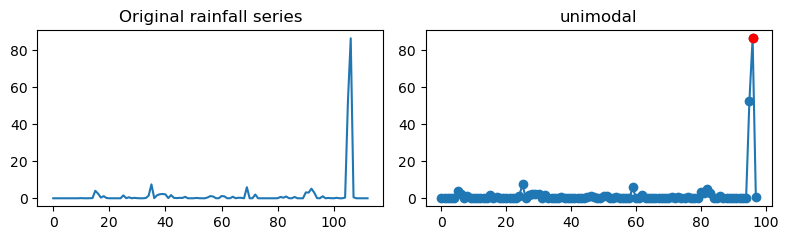

[7.4081044e+00 7.6390892e+01 3.6387627e+01 3.7702403e+00 3.1288607e+00
 3.2128018e-01 2.1137935e-01 1.2349261e-01 7.8709379e-02 2.7697304e-02
 7.8393675e-02 6.0974546e-02]
Event index: 8506, result: unimodal, n_peaks: 1


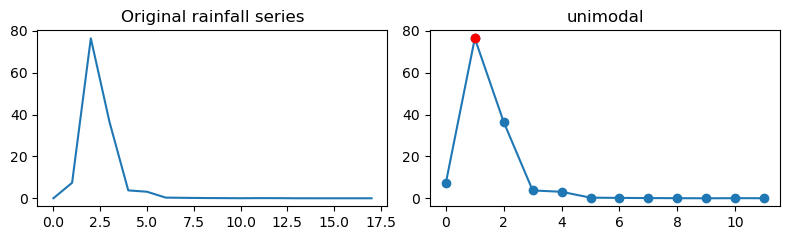

[79.212532   2.5290492 12.102235  27.15097    1.1562012]
Event index: 8511, result: bimodal, n_peaks: 2


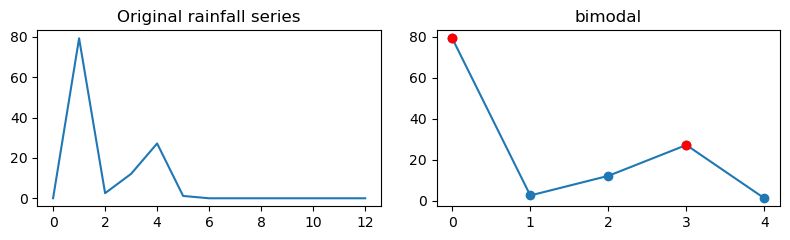

[37.248875    0.44802168]
Event index: 8545, result: unimodal, n_peaks: 1


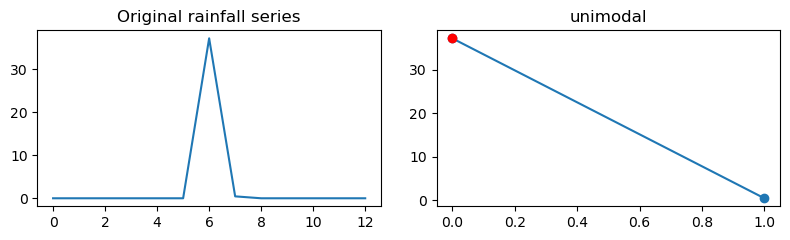

[2.55721241e-01 1.93071632e+01 3.89866829e+01 5.12169571e+01
 1.63030968e+01 8.06629467e+00 1.56558549e+00 5.61748224e-04
 5.49230909e+00 1.90642830e-02 4.95473176e-01 6.05432081e+00
 1.88296661e+01 6.67724562e+00 6.44674450e-02 1.08888745e+00
 1.03248982e-02 5.53439185e-03 5.59573650e+00 2.89833724e-01
 7.77082324e-01 1.20293844e+00 9.38807607e-01 3.68736953e-01
 2.12723896e-01 1.87418267e-01 1.85556978e-01 1.96205348e-01
 1.07980579e-01 9.76373181e-02 1.23839624e-01 1.41272143e-01
 1.11255474e-01 6.10815138e-02 6.55777529e-02 1.70634210e-01
 1.67433650e-03 3.89836244e-02 4.56388414e-01 3.29059869e-01
 1.39815438e+00 2.77301145e+00 5.50469875e+00 2.15689397e+00
 1.61442256e+00 6.43233061e-02 1.23007021e-06 2.99065596e-06
 2.09480837e-01]
Event index: 8646, result: bimodal, n_peaks: 2


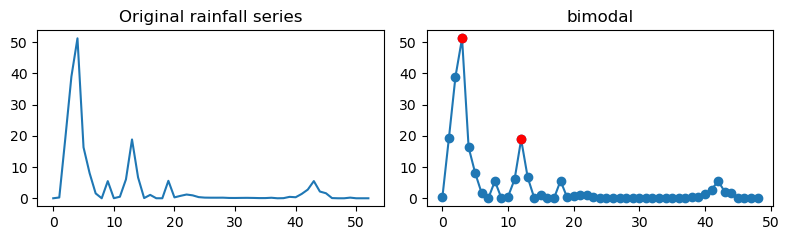

[ 7.5917854 74.623482 ]
Event index: 8652, result: unimodal, n_peaks: 1


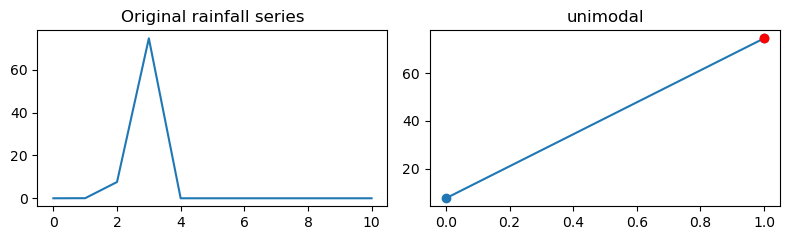

[ 0.26618865  0.75518966 58.26931     1.8372978   2.0216901   1.2767518
  0.25011119  0.82813734  0.56823713  0.61780208  1.4221083   1.8745171
  1.1963719   0.97152007  0.93862295  0.85336703  0.65862304  0.65436691
  1.8884137   1.1465234   1.7773473   0.70533645  2.1722701   2.8010385
  1.4410459   1.1897094   0.26168996]
Event index: 8660, result: unimodal, n_peaks: 1


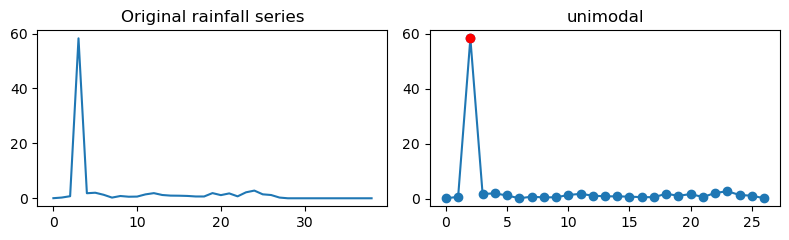

[1.69760823e-01 4.65441674e-01 1.15663275e-01 3.51278186e-01
 6.82017207e-01 5.75126171e-01 2.28776979e+00 2.46727467e+00
 2.95043206e+00 1.18643641e+00 4.83373739e-02 3.45353925e-07
 5.69521887e-07 2.35363696e-05 1.80031964e-06 1.71113192e-04
 2.11968303e+00 8.03782349e+01 4.50099831e+01 5.71919605e-04
 2.67271232e-02 1.51449823e+01 8.58870149e-02 1.01564178e+01]
Event index: 8664, result: multimodal, n_peaks: 3


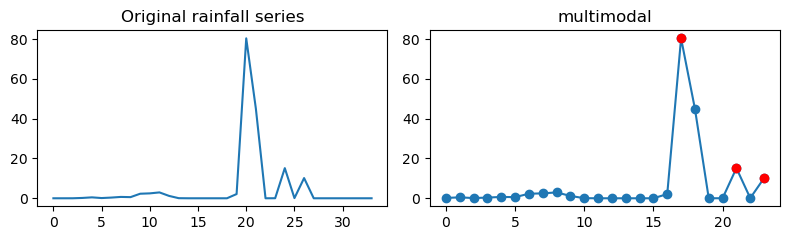

[9.43335571e+01 1.81557198e+01 2.03861542e+01 1.79043884e+01
 3.63594742e+01 9.59896393e+01 2.05647349e-01 9.79714543e-02
 1.12938434e-01 1.25331029e-01 7.70361349e-02 1.25163212e-01]
Event index: 8665, result: multimodal, n_peaks: 3


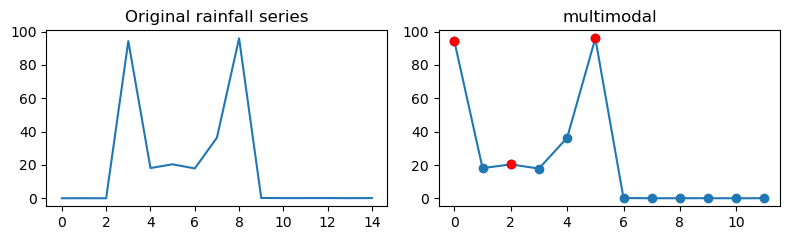

[3.1092839e+00 2.8432143e+00 2.3318036e+00 2.6626317e-04 2.4665653e-05
 3.8517658e+01 5.3258929e-02 6.2497115e+00 2.2405391e-05 1.3304322e-05
 1.8188550e-05 2.1964512e-05 2.2662669e-05 8.2986581e-04 2.5696217e-03
 1.4999525e-01 4.5744431e-01 9.7807534e-02 1.6781896e+00 4.3916612e+00
 6.2027293e-01 2.7448440e-01 4.6239872e-02 1.1640818e-02 7.9440333e-02]
Event index: 8670, result: unimodal, n_peaks: 1


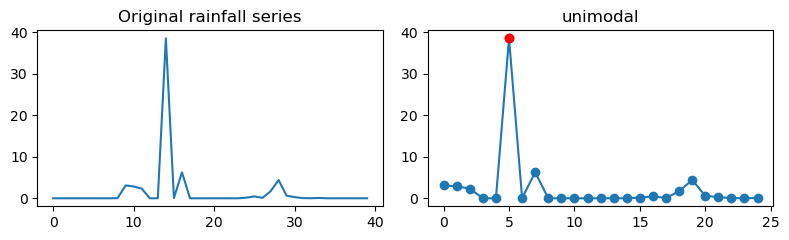

[2.14835823e-01 1.95118293e-01 1.04188949e-01 4.05094726e-03
 9.89910041e-06 7.01987222e-02 4.73423362e-01 7.98584461e-01
 3.13382792e+00 3.13624084e-01 7.01856911e-01 1.66203603e-01
 2.85435840e-02 1.33766264e-01 7.20878877e-03 2.82003522e-01
 4.09691811e-01 7.61604111e-04 2.51659621e-02 7.57964401e+01
 1.58357382e+00 4.81641740e-02 1.62662566e+00 4.12231159e+00]
Event index: 8683, result: unimodal, n_peaks: 1


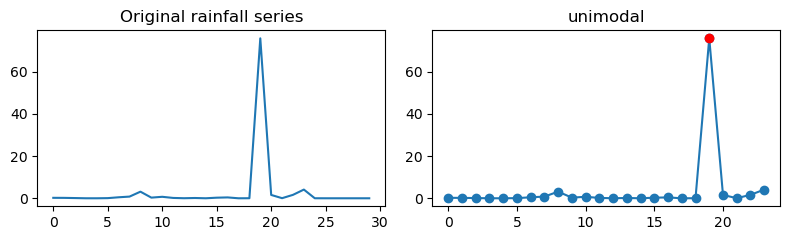

[3.5792065e+00 5.2708834e-02 6.7124696e-04 8.8127510e+01 2.1630115e-04
 1.7385147e-04 4.2435603e-04 1.5121237e+01]
Event index: 8687, result: bimodal, n_peaks: 2


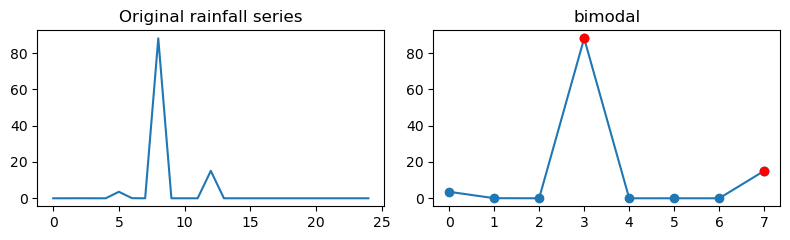

[45.826019]
Event index: 8699, result: unimodal, n_peaks: 1


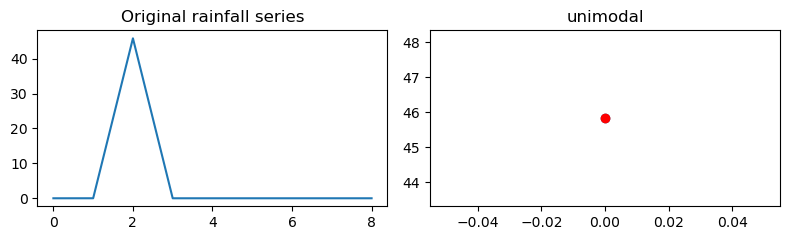

[4.35852915e-01 7.64145106e-02 1.59352669e-04 1.14260819e-02
 1.86969701e-03 1.64121166e-02 9.28651192e-04 2.12658633e-04
 7.11738586e+01 4.00819480e-01 1.18539199e-01 1.90594379e-04
 1.35731816e+00 3.56712997e-01 4.71853316e-01 7.58352503e-02]
Event index: 8704, result: unimodal, n_peaks: 1


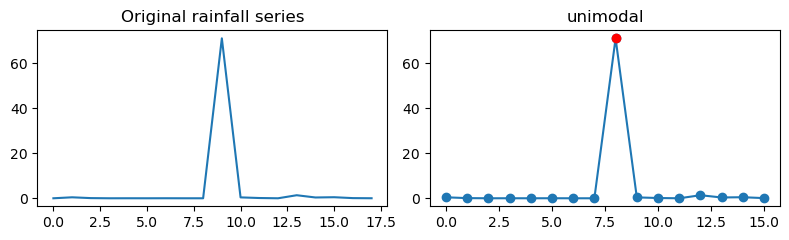

[5.1022820e+00 5.7532657e-06 6.8703239e+01 3.3176920e+00 4.1218365e+01]
Event index: 8705, result: bimodal, n_peaks: 2


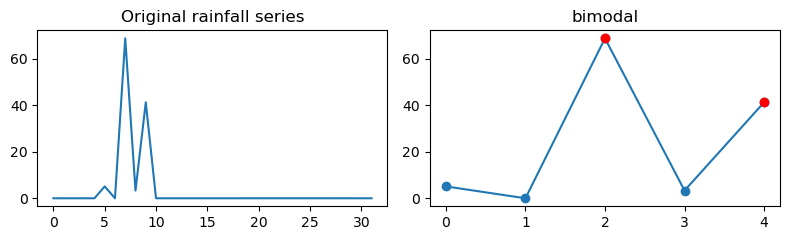

[ 0.11013036 32.926472  ]
Event index: 8708, result: unimodal, n_peaks: 1


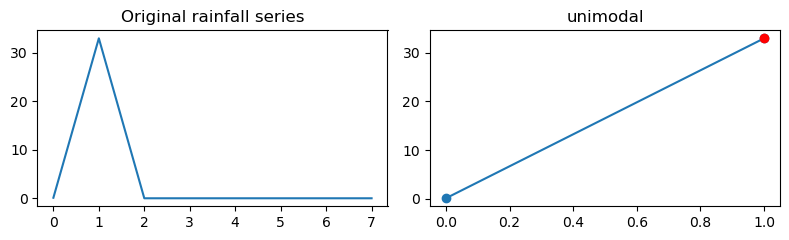

[ 0.58714592  1.0984808   0.72866297  1.9298915   0.57011396  0.13977143
  0.11639576  0.19835138  0.88422441  1.9753021   1.8305289  87.321861
 11.332748    4.128356  ]
Event index: 8716, result: unimodal, n_peaks: 1


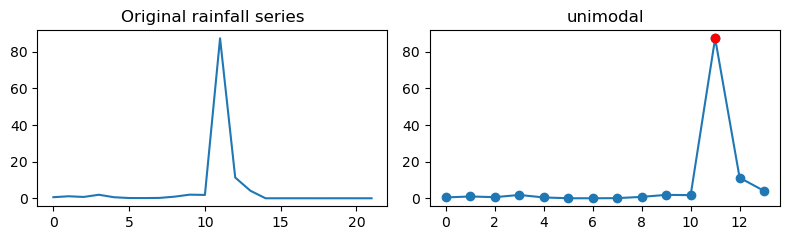

[9.6711098e+01 2.2870435e-04 8.5493046e-01 7.3678660e-01 2.0581787e-04
 4.3273185e-04 1.2346286e-04 6.5929041e-04 8.6195447e-04 1.0347480e+01]
Event index: 8721, result: bimodal, n_peaks: 2


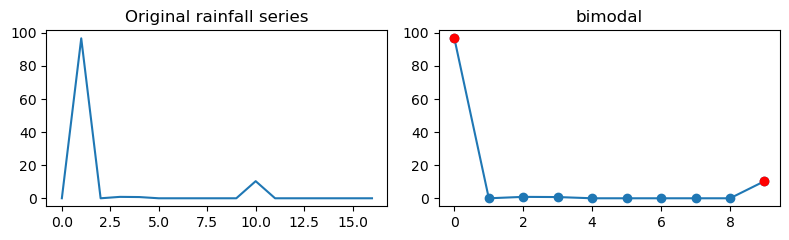

[1.0861166e+00 5.1579208e+00 2.9962437e-02 3.2413856e-05 2.9528227e+00
 1.4527306e-04 3.5040054e-04 1.6434482e-01 1.9847424e-01 1.4439544e-04
 2.1023347e+00 6.5131746e-02 3.7357405e-01 2.4983813e-06 3.9549800e-06
 3.4939230e-06 5.5937767e-06 6.3184515e-09 7.8873591e+00 3.4587570e+01]
Event index: 8743, result: unimodal, n_peaks: 1


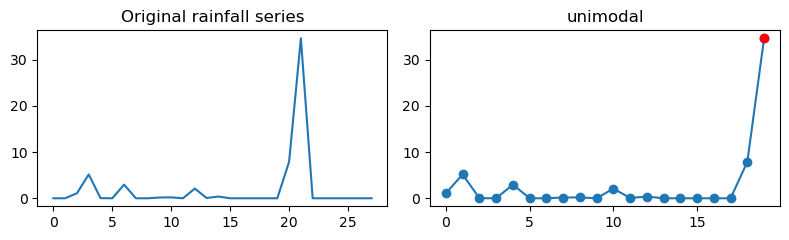

[1.2151012e-01 5.5457480e-02 1.0721724e-01 2.4824968e-02 6.5908262e-07
 1.7901770e-06 1.7750696e+00 5.6042361e-01 4.1279340e-01 1.6900677e-03
 1.9464911e-04 1.1829426e-04 2.1932834e-05 1.4306097e-04 6.2223360e-02
 1.5100601e-01 1.0564606e-04 1.2365295e-04 1.9034736e-05 4.6431844e-05
 2.1008993e-05 2.1718949e-04 1.6774407e-04 1.2266450e-04 1.4467565e-04
 1.5976616e-04 2.2062105e-01 2.0397780e+00 2.2687005e-01 1.0918039e-04
 1.2357518e-04 1.0795147e-03 1.1653277e-04 3.2038132e+01 3.8680542e-02
 2.0446267e-02 2.8441042e-01 1.9462100e-06 9.1962653e-07 3.7841775e-04
 4.1266531e-01]
Event index: 8745, result: unimodal, n_peaks: 1


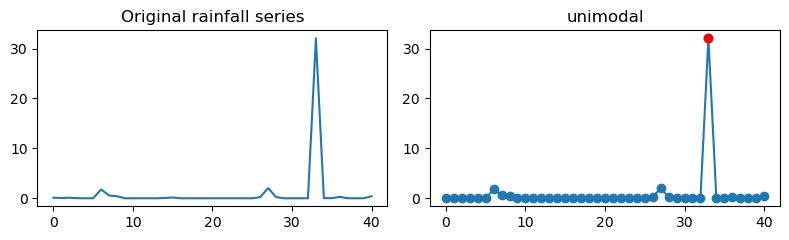

[37.005352]
Event index: 8757, result: unimodal, n_peaks: 1


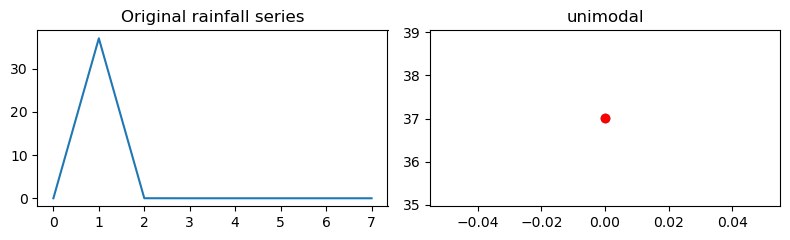

[1.78951368e-01 8.99493716e-06 1.12803841e+00 4.69867378e-01
 1.55166381e-05 8.77206003e-06 2.66660243e-01 4.32579696e-01
 9.21553146e-06 4.87387206e-06 1.45781878e-05 2.21956478e-04
 9.94043057e-06 4.05900073e-06 9.46540907e-02 2.96980405e+00
 9.74891245e-01 1.69584018e-05 3.01307659e-06 2.03167176e+00
 5.64548790e-01 1.22655706e-06 1.17365678e-04 8.67903233e-02
 4.70348477e-01 6.73720956e-01 6.48249984e-01 1.69696966e-06
 2.14689621e-03 2.49959898e+00 5.45707047e-02 7.07789525e-07
 1.25520185e-01 3.96803737e-01 1.04492354e+00 2.00949907e-02
 9.69936311e-01 1.40767588e-05 1.29661882e+00 6.89983749e+00
 1.65879112e-02 6.57390244e-03 1.74784131e-04 4.84312512e-02
 2.35591717e-02 3.15739726e-06 6.43860840e-05 8.26136849e-04
 5.10762902e-06 1.23493397e-03 5.22458792e-01 8.88827053e-05
 7.71067679e-01 6.02409104e-03 3.14012498e-01 1.60496211e+00
 2.63441825e+00 8.71845987e-05 4.39046994e-02 6.71310554e-05
 7.85761767e-06 8.19953675e-06 9.73352406e-04 1.34206891e+00
 6.61395311e-01 2.938213

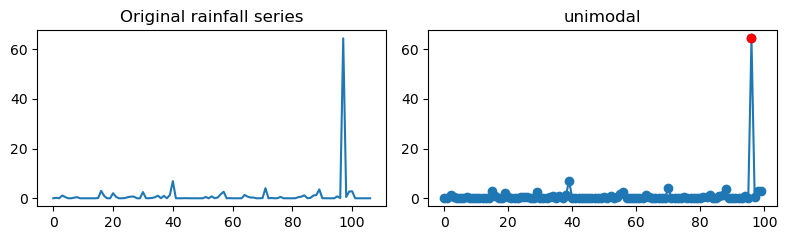

[1.0951964e+00 5.8414328e-01 1.7528824e-03 7.0238570e-03 1.0722544e+00
 3.2835271e+00 4.7813101e+00 2.7219436e+00 2.5317128e+00 3.7588260e-01
 2.2442307e+00 5.5571638e-02 4.9733462e-06 1.5408998e-05 1.1510370e-04
 6.2536319e-06 1.4741908e-01 1.2857081e-06 3.1555528e-06 5.7545849e-06
 2.8769881e-01 4.6441814e-01 2.6285469e-03 1.8339680e-06 2.9051541e-06
 7.8721368e-01 9.7045529e-01 2.3943563e-03 1.5077962e-06 5.3022080e-07
 1.5822764e-07 1.7330851e-06 8.2150375e-04 2.4148342e+01 4.6961024e-04
 5.0744155e-05 4.5737546e-05 1.9476582e-04 9.4788708e-02 1.4759874e+01
 1.4325823e-02 2.4356888e-04 1.4814053e-04 1.4617931e-04 1.8202131e-04
 1.7447285e-04 1.8729552e-04 3.2899567e+01 2.3644336e-04 6.2928824e+00
 2.9307454e+00]
Event index: 8790, result: multimodal, n_peaks: 3


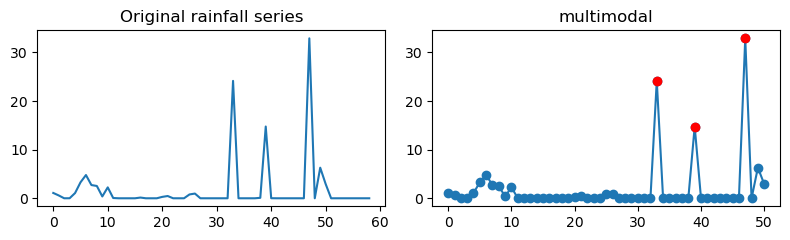

[2.4822433e-01 6.0704155e+00 7.2974920e-02 7.0125943e-01 2.9368252e-01
 1.3985632e-01 4.6846853e-06 1.5956057e-04 1.3527310e+01 1.2190757e+00
 3.3505529e-01 1.0915851e+01 5.2364555e-04 1.6405899e-04 1.9785745e-01
 5.5603752e+01 1.3187090e+00]
Event index: 8835, result: multimodal, n_peaks: 3


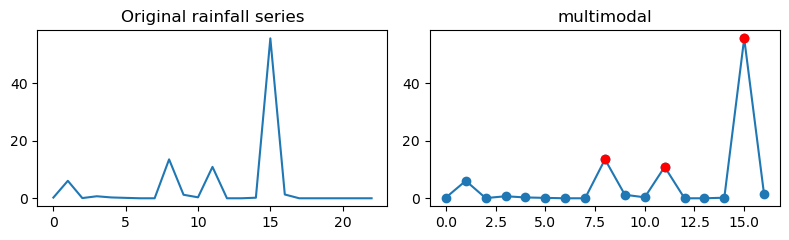

Pixel 886: 170 events
[7.7454557e+00 3.7801185e+00 7.2424712e+00 4.8632827e+00 6.4060721e+00
 5.1539034e-01 1.2249160e+00 5.5940574e-01 3.1570879e+01 1.5736164e+01
 1.3750648e+00 3.3578831e-03 1.5398833e+00 2.7316941e-03 2.0770116e-03
 1.0519772e-02 6.6353709e-01 1.9822884e-01]
Event index: 12219, result: unimodal, n_peaks: 1


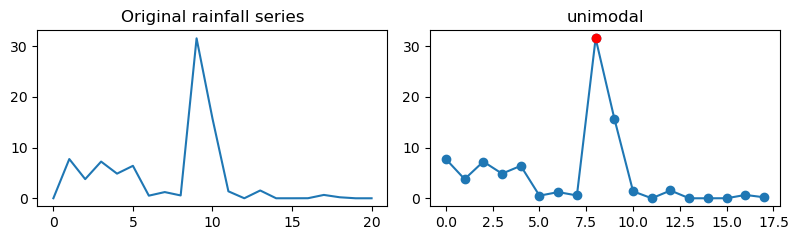

[50.176666   2.0107346]
Event index: 12246, result: unimodal, n_peaks: 1


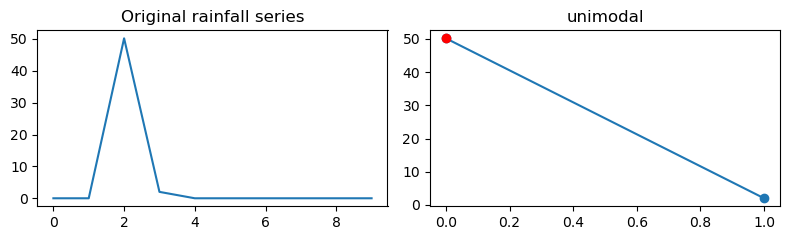

[20.005348  33.123436   4.8021088  1.9094785  3.9992642]
Event index: 12249, result: unimodal, n_peaks: 1


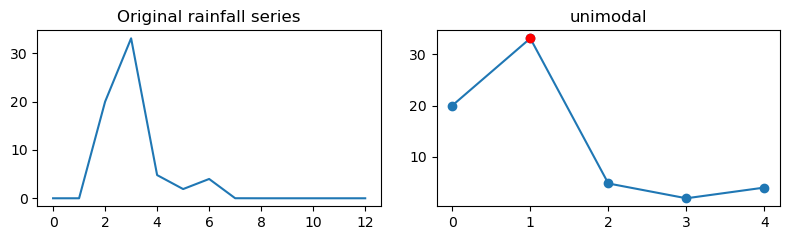

[ 0.27522033 43.533585    3.9789374   2.0217221   1.0072542   8.1950283
  1.2267179   8.992281   14.30001     5.7109919   9.4776506 ]
Event index: 12250, result: bimodal, n_peaks: 2


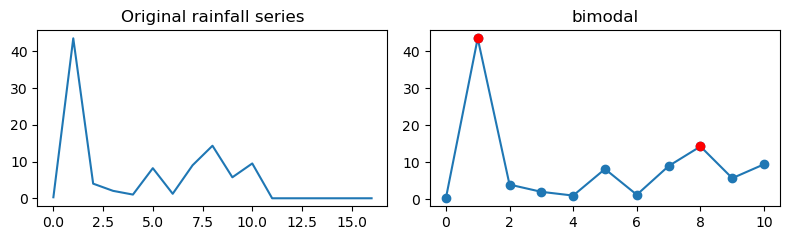

[10.372328   13.038882   31.478168    3.9883275   0.08004808]
Event index: 12254, result: unimodal, n_peaks: 1


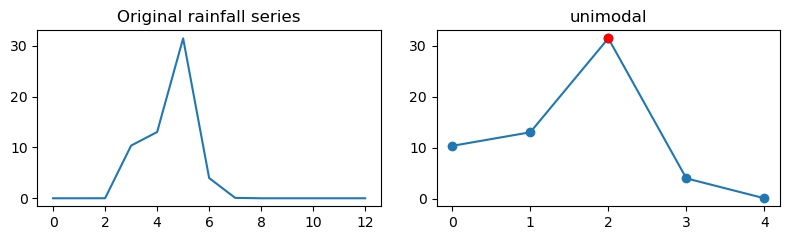

[8.02647305e+00 5.35726089e+01 3.75754261e+00 6.54621422e-01
 6.90322146e-02 3.44644533e-03 1.06834635e-01]
Event index: 12257, result: unimodal, n_peaks: 1


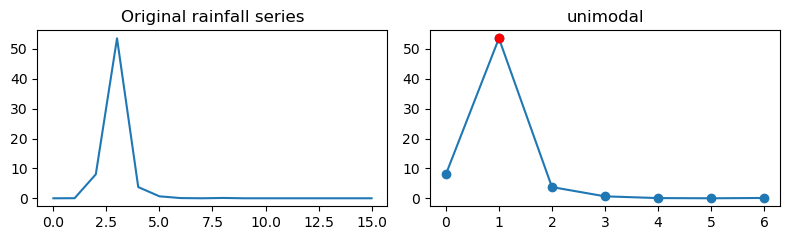

[ 0.05810177  0.97565615 35.831257   13.834122    3.720361  ]
Event index: 12263, result: unimodal, n_peaks: 1


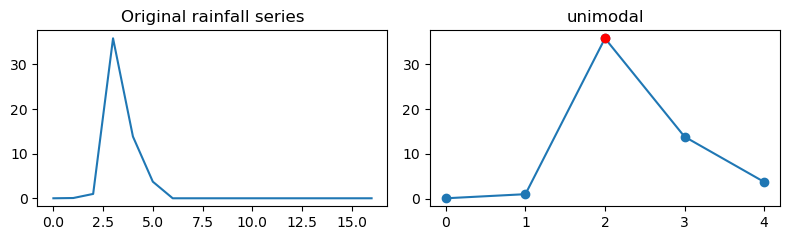

[ 1.6956818  32.000118    0.14532676]
Event index: 12273, result: unimodal, n_peaks: 1


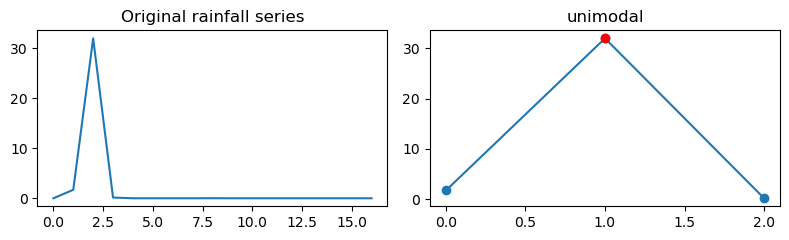

[5.3534251e-02 3.5330677e+01 1.3532080e+01 4.2208621e-01 1.8178042e-02
 5.6201565e-01]
Event index: 12279, result: unimodal, n_peaks: 1


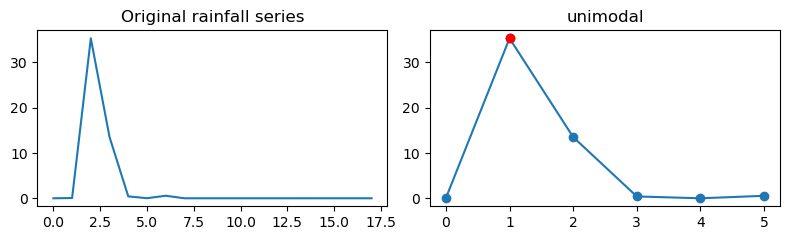

[ 0.29194891  2.547986   32.033749    1.668919   17.345419    0.76911867
  7.0660977   5.3763056 ]
Event index: 12281, result: unimodal, n_peaks: 1


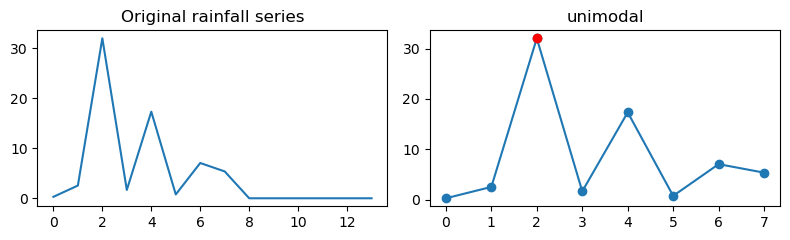

[8.2581720e+00 2.5291388e+00 1.0805301e-05 3.3610202e-03 3.0883032e+01
 3.8839037e+00]
Event index: 12293, result: unimodal, n_peaks: 1


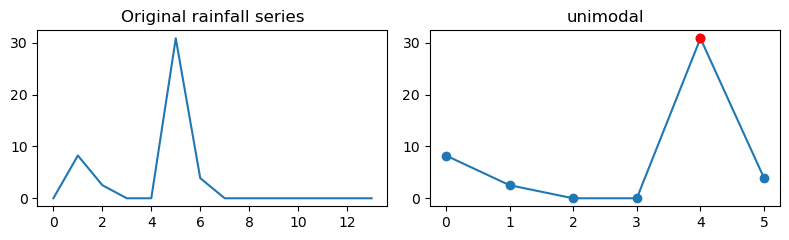

[1.1621162e+00 1.4667735e+00 6.3417733e-01 5.6148216e+01 1.3566434e+01
 2.0721631e+00 5.2416911e+00 7.7677548e-01 2.3145385e+00 8.8360439e-06
 2.6074471e-03 7.5548128e-03 2.6341725e-02 3.2505382e-02 2.7847771e-02
 1.0350449e-03 1.5092437e-05 7.6129727e-06 1.3245356e-06 6.5598215e-07
 1.3932162e-06 7.2542948e-06 6.3313311e-01 4.1821722e-02 9.0899527e-01]
Event index: 12302, result: unimodal, n_peaks: 1


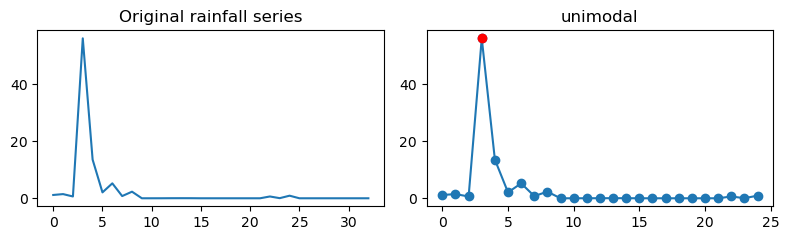

[2.8548931e+01 6.1565285e+01 1.5922172e+01 1.2614344e-03 5.0678540e-02
 7.1173780e-02]
Event index: 12309, result: unimodal, n_peaks: 1


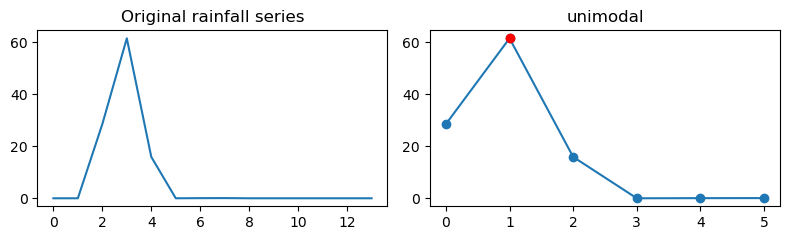

[ 2.0769362  44.277149    0.52592677]
Event index: 12314, result: unimodal, n_peaks: 1


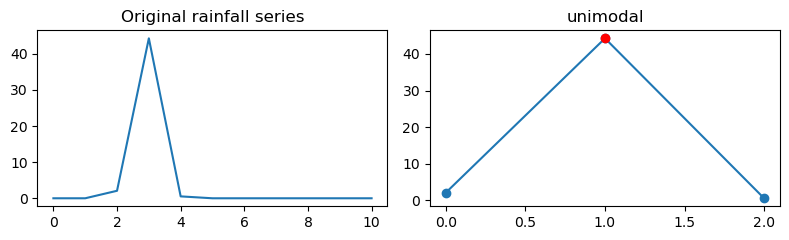

[1.2031468e+01 3.7100735e+01 8.8182926e+00 3.1842318e-01 6.5325228e-03
 9.8566682e-07 1.1158893e-06 1.3475482e-03 1.0612030e-03 1.6254472e-03
 3.1146116e-04 9.9281684e-02 5.0362056e-01 4.8638672e-02 1.9691954e-03
 2.9179435e-05 5.6527205e+00 2.9462807e+00 1.5940794e+00 1.6165660e-01
 2.2557089e-03 4.3841869e-06 5.1841130e-07 1.9434470e-01 4.8644814e-01]
Event index: 12317, result: unimodal, n_peaks: 1


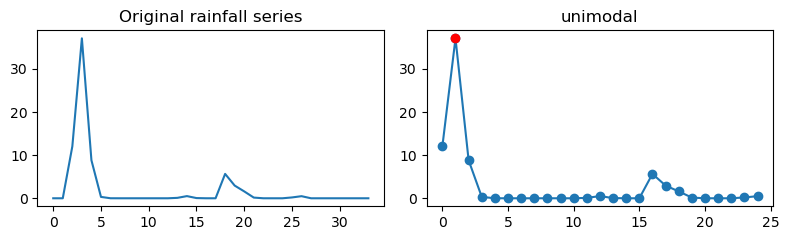

[3.1780235e+01 5.4347205e+00 6.9219460e+00 3.9655259e-01 4.6046064e-04
 7.2876501e-01]
Event index: 12318, result: unimodal, n_peaks: 1


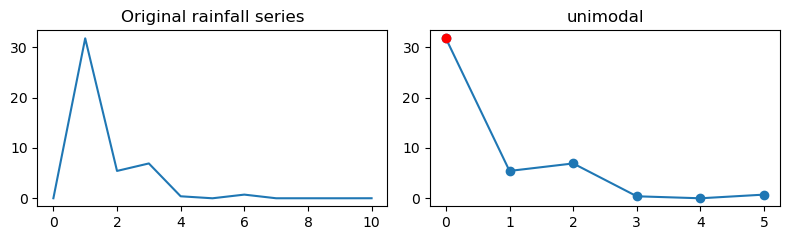

[9.4211376e-01 1.6475412e+00 1.3868732e+00 1.7834986e+00 1.6872658e+00
 1.0732235e+00 2.2946026e+00 4.9619722e+00 4.5914397e+00 8.1685438e+00
 4.4418478e+00 9.8391074e-01 2.0699861e+00 6.8349051e+00 4.1267710e+00
 3.3639562e+00 4.5788717e-02 1.3378791e+00 2.0566641e-01 1.6399418e-01
 1.0494723e+00 3.4457962e+01 1.0195038e+01 3.0094767e+00 3.5253670e+00
 1.5074059e+00 3.4001151e-03 1.4536573e-04 1.0326497e-03 2.6532349e-01
 3.7162080e+00 1.8933218e-03 3.4388396e-04 1.2931452e-03 3.8720625e-03
 1.3794551e-02 6.5740913e-02]
Event index: 12321, result: unimodal, n_peaks: 1


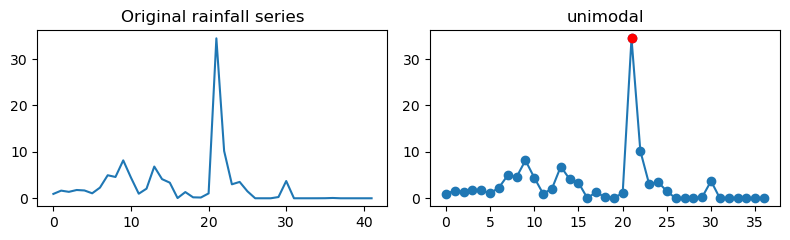

[5.5584389e-01 4.6564754e+01 5.7188497e+00 6.7032515e-06 1.7247639e-06
 1.4204705e-03 1.2026793e+00]
Event index: 12355, result: unimodal, n_peaks: 1


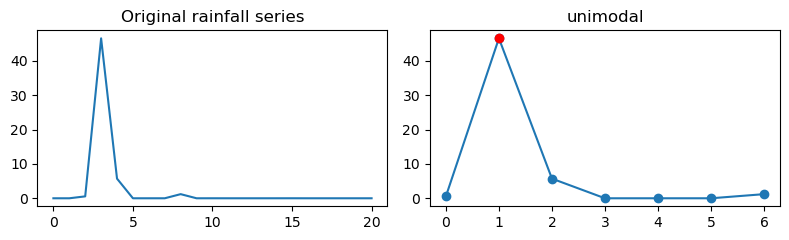

[ 3.7976427   7.6737766   0.55837113 46.370956    3.1376145 ]
Event index: 12367, result: unimodal, n_peaks: 1


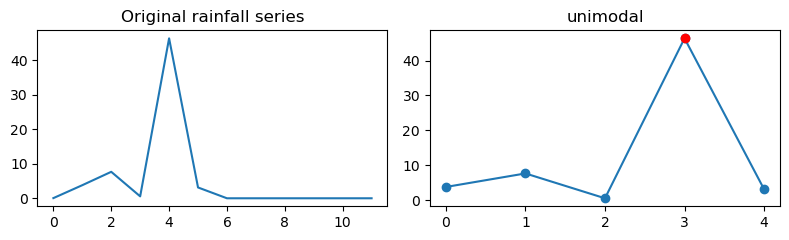

[1.0385918e-01 4.3776634e-01 5.0009994e-06 8.9420892e-06 8.9391051e-06
 5.3951484e-03 2.8127196e-01 6.1834536e+00 3.0213942e+01 2.6020808e+00
 9.5917612e-02 7.9255706e-01 8.6862883e-03 1.0813972e-01]
Event index: 12380, result: unimodal, n_peaks: 1


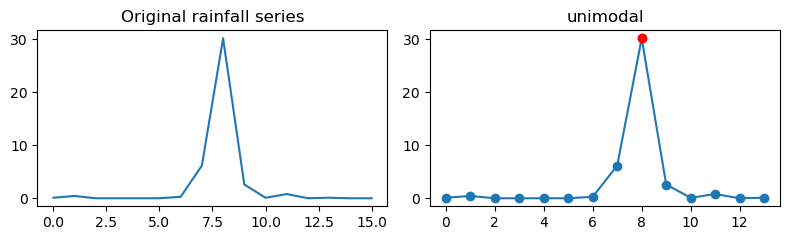

[ 0.06209023  0.13928007 31.6061401  14.0783997 ]
Event index: 12385, result: unimodal, n_peaks: 1


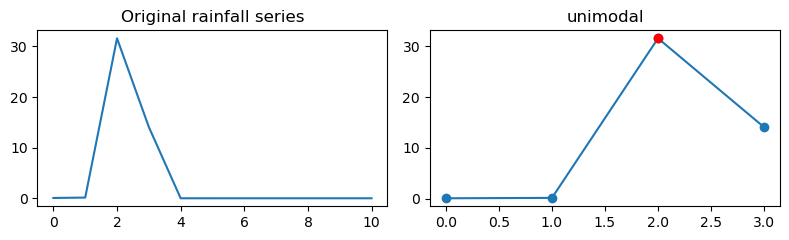

[ 1.3848283   3.6635504  31.538969   14.30497     5.4466538   0.88162136
  0.17908801]
Event index: 12388, result: unimodal, n_peaks: 1


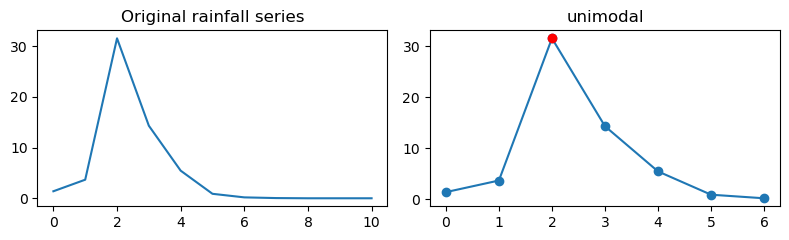

[1.2700434e-01 6.4419466e-04 7.1382833e-06 1.3075855e+00 7.4318510e-01
 9.0410022e-06 1.5689579e-01 1.1940174e-05 7.9601105e-06 9.4979650e-06
 7.7220941e-01 3.4720939e-02 1.7422923e+00 5.5214233e+00 8.7233686e+00
 7.5632922e-04 5.8413984e-06 5.8874939e-05 3.6597592e-01 1.5870672e+00
 3.7413240e-05 4.3750593e-01 4.2691222e-06 6.4455467e-06 5.5238252e-06
 2.7260528e-04 1.6801476e-02 1.8456942e-05 3.5393250e-03 5.1085277e+00
 1.8713371e-06 4.7735076e-02 7.7481527e-06 8.0060633e-03 7.2880089e-04
 1.6862743e-01 7.5818957e-06 2.1886797e+00 1.5531775e+00 4.2950496e-06
 1.9944315e+00 8.2198685e-01 8.2525000e-02 6.6002607e-02 4.4059098e-02
 1.1956139e-01 5.8987081e-01 1.8130791e+00 7.5248528e-01 4.5647335e-01
 1.1958551e-02 2.9268092e-06 3.0831993e-06 1.7576100e-02 3.5007260e+00
 5.2910538e+00 1.0720219e+01 4.6997600e+00 7.5145144e+00 1.5395365e+01
 1.7924072e+01 3.0487461e+01 6.6892710e+00 3.0421391e+00 1.8848485e+00
 6.8684405e-01 4.5330724e-01 3.0344355e-01 3.5802990e-01 6.2297791e-01
 8.905

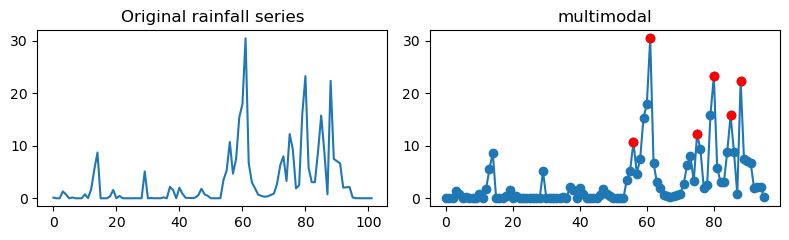

[ 3.5006881   0.80136943  0.34619167 32.299519   13.796257    0.29846513]
Event index: 12410, result: unimodal, n_peaks: 1


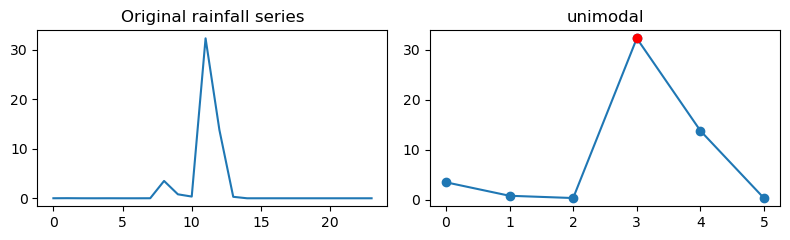

[ 0.62316024  3.5244324   2.3691771   7.6526852  36.945904    0.0660664 ]
Event index: 12417, result: unimodal, n_peaks: 1


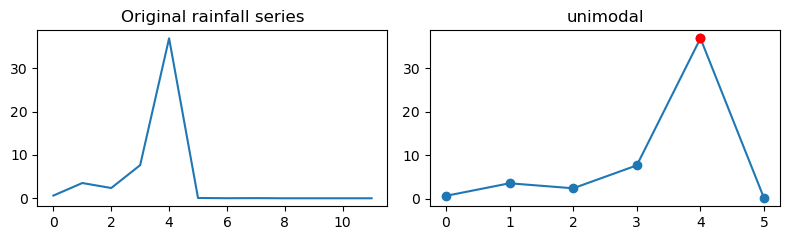

[ 2.9842839 45.614117   1.9355102]
Event index: 12438, result: unimodal, n_peaks: 1


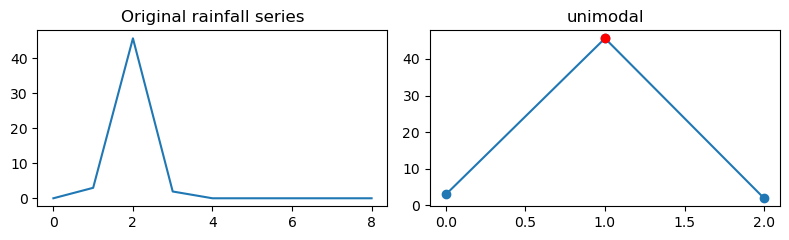

[4.97577667e+00 1.76653087e-01 1.11562679e-06 1.81285850e-06
 1.70335841e-06 1.55132477e-06 1.17575030e-06 1.69886823e-06
 1.93941810e-06 2.66391726e-06 3.76914591e-06 5.43958731e-06
 3.71961164e-06 3.92857874e-06 7.01660565e-06 4.39578616e-06
 1.18778325e-05 5.60195149e-05 2.81440007e-05 2.30484911e-05
 6.20230511e-02 1.78438926e+00 1.82394052e+00 1.48219863e-06
 4.56176110e-07 2.07406038e-06 1.23439528e-01 1.38953803e-02
 8.17857142e-07 1.15201658e-06 8.09089914e-02 2.00714035e+01
 3.90137106e-01 6.07964751e-07 5.08079946e-04 2.57861825e-06
 2.09308564e-06 2.89153886e+00 1.12755895e-01 1.04962206e+00
 5.36107942e-02 1.94677478e-03 5.48910141e-01 1.56481564e-01
 1.13207381e-02 1.14582729e+01 4.83498335e+00 5.59310913e-02
 1.53367722e+00 4.04828787e+00 2.83875990e+00 4.03710004e-07
 2.93097801e-05 1.16557294e-06 3.74923870e-02 8.50235551e-07
 1.14996597e-04 1.70994978e-02 1.27773108e-02 2.13684392e+00
 9.45554912e-01 1.62053728e+00 8.72349644e+00 1.94066748e-01
 1.01057969e-01 4.971230

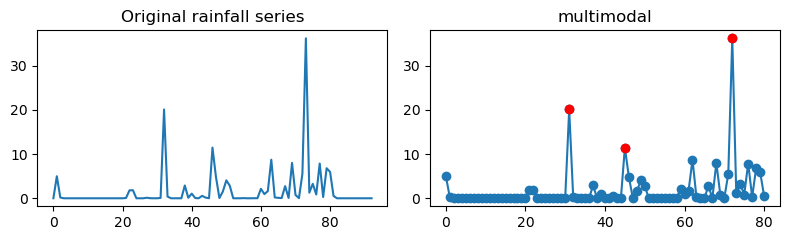

[12.410053 34.39212 ]
Event index: 12458, result: unimodal, n_peaks: 1


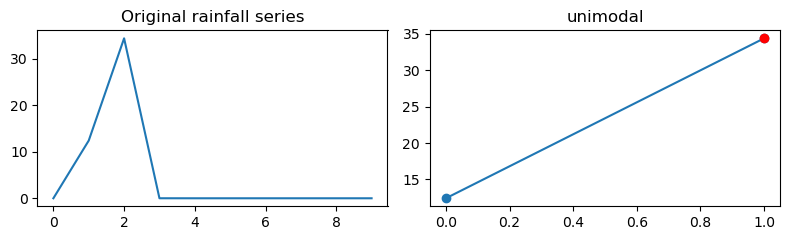

[1.9381868e+00 7.5337686e-02 1.5316818e-06 1.2675461e-06 4.5889890e-01
 3.6819386e+01 2.1834202e+00]
Event index: 12469, result: unimodal, n_peaks: 1


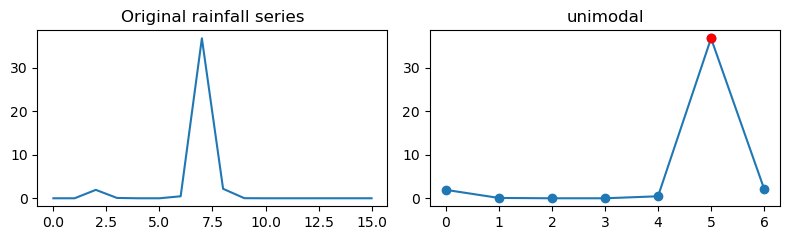

[9.79683697e-01 6.71593621e-02 5.04420996e-06 1.62923391e-06
 9.53540336e-07 1.00215264e-01 2.85063314e+00 1.01771854e-01
 6.96042001e-01 1.07914429e+01 6.91149294e-01 5.09352594e-06
 1.65737653e+00 1.41831279e+00 1.54173946e+00 4.10835637e-05
 7.28059933e-02 8.16241145e-01 1.42951622e+01 3.01142635e+01
 2.59388089e+00]
Event index: 12473, result: bimodal, n_peaks: 2


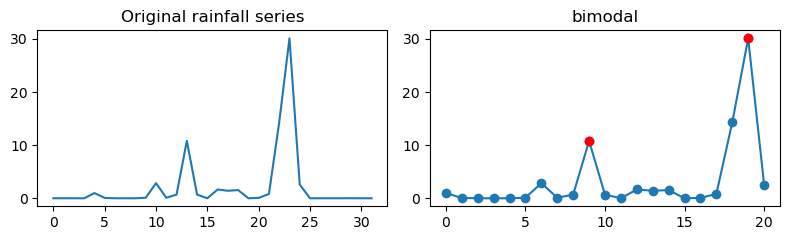

[1.0296267e-01 4.6533369e-02 8.2786195e-03 4.7935415e-03 7.1840681e-02
 1.8577494e-02 9.8580550e-03 5.1579338e+01 1.0303748e+00 7.6717059e-03
 1.8405879e-06 1.0295238e-06 1.8127400e-06 1.7974534e-06 2.7550033e-01]
Event index: 12474, result: unimodal, n_peaks: 1


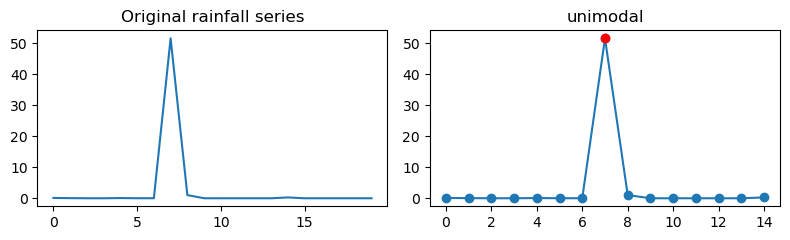

[2.32062078e+00 1.52295089e+00 1.41966505e+01 6.45950270e+00
 1.50932968e+00 1.74816298e+00 3.20317574e+01 1.08996639e+01
 1.07912521e+01 7.63296556e+00 1.13722820e+01 1.73425198e+00
 1.06228018e+00 8.21083605e-01 4.02185798e-01 2.95316994e-01
 8.61353874e-02 1.78246762e-06 6.54159635e-02]
Event index: 12477, result: multimodal, n_peaks: 3


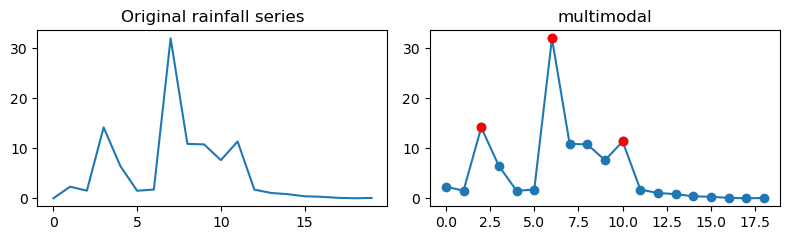

[3.7003717e-01 5.5793236e+01 2.0689953e+01 1.4036605e+01 2.1372252e+00
 8.7790843e-04 9.6425981e-07 3.6333227e-01 1.6243964e-01]
Event index: 12482, result: unimodal, n_peaks: 1


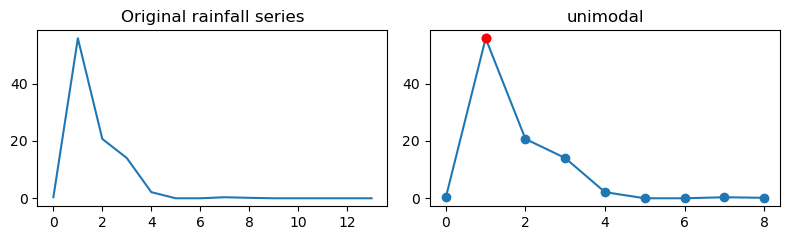

[ 0.27288863 11.053781   36.242851    2.9434364 ]
Event index: 12483, result: unimodal, n_peaks: 1


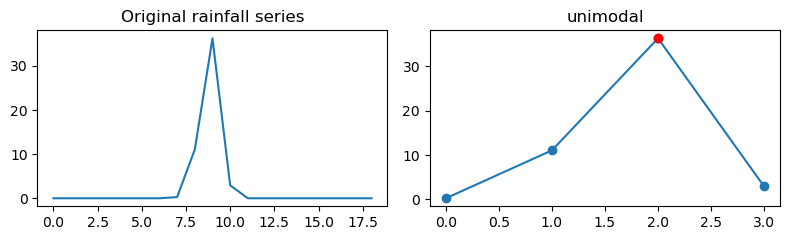

[11.179614  46.94487    7.3237205  9.2020922  3.2643301]
Event index: 12488, result: unimodal, n_peaks: 1


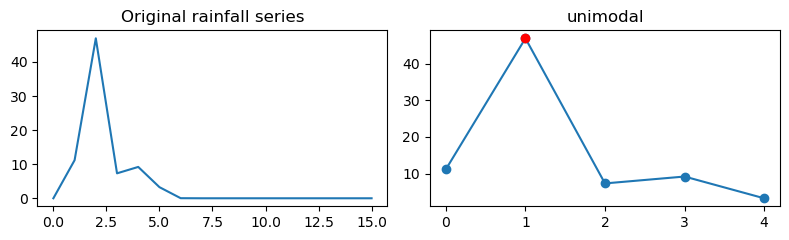

[ 4.0337744  32.23069     0.59617186  0.63423115]
Event index: 12491, result: unimodal, n_peaks: 1


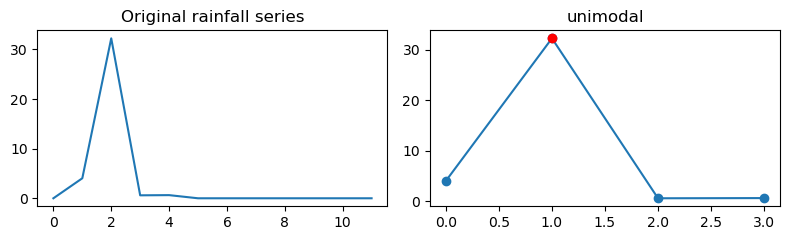

[8.3804315e-01 1.7175888e+00 9.0234512e-01 2.9619551e-01 1.3068150e-01
 1.3083470e-01 7.3639497e-02 3.2131290e-01 2.6087532e+00 3.9359481e+00
 1.1784804e+01 4.4030409e+00 2.9610991e+00 4.7135237e-01 2.8627686e+01
 3.0711676e+01 1.6734188e+01 4.3175316e-01 7.3971629e-01 3.3366766e-02
 1.2136379e-01 2.9791191e-01 3.1780913e-02 1.1616287e-02 8.7871775e-03
 2.3571875e-02 9.7003235e-03 4.7931105e-02 7.5841539e-02 4.9643010e-02
 7.2545752e-02 4.1598114e-03 1.7771479e-03 1.9422298e-02 1.1784526e-01
 9.1953874e-02]
Event index: 12494, result: bimodal, n_peaks: 2


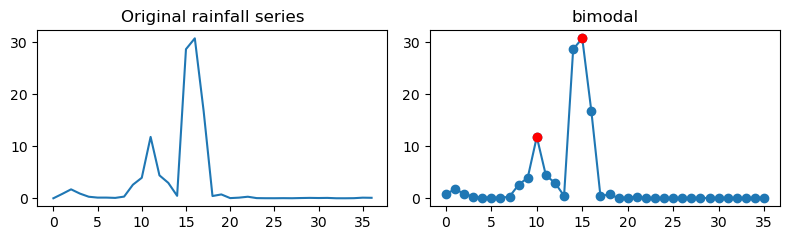

[ 0.3373324   6.082407   38.8964539  10.3455391  15.6881695   0.04099334
  0.05310816]
Event index: 12501, result: unimodal, n_peaks: 1


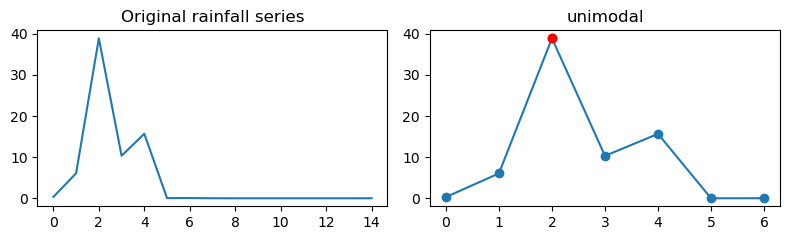

[2.4733447e-01 5.8157144e+00 5.3639045e+00 1.4485233e-02 5.5640867e-06
 1.1228674e-06 7.8800917e+00 4.4126770e+01 2.7159730e-01 2.0774426e+00
 6.2716728e-01 6.3433325e-01 1.7804350e-06 1.7979486e-06 2.0085268e+00]
Event index: 12503, result: unimodal, n_peaks: 1


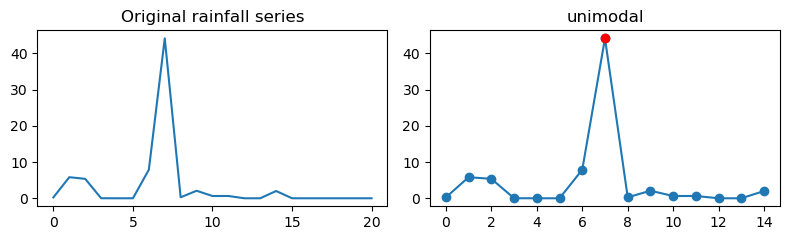

[ 0.27020925  2.4635899  31.899183   12.621489    5.0099506   2.5663469
  3.4244015   0.25753763  1.1859647   0.23945192]
Event index: 12507, result: unimodal, n_peaks: 1


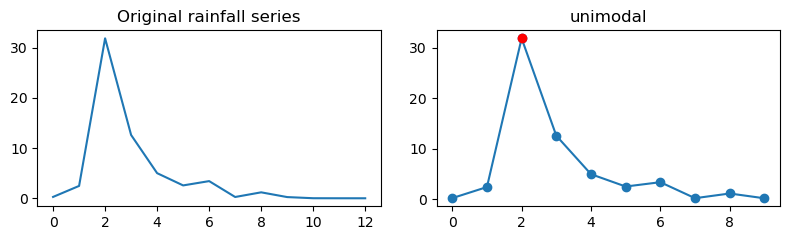

[3.2362840e-01 2.0165625e+00 5.5685740e+00 3.6940141e+00 5.7888951e+00
 4.9869018e+00 1.2543526e+01 4.7831216e+00 1.0723765e+00 1.1708038e+00
 8.0247698e+00 5.0356597e-01 4.6888888e-01 1.8966719e+00 1.8120375e+00
 1.8912230e+01 3.1555637e+01 8.6880598e+00 8.6793728e+00 8.5707836e+00
 4.1232553e-01 8.3485329e-01 1.0531295e+01 2.2987197e-01 7.5222645e+00
 1.9240486e+01 1.7066954e+01 4.9174786e+00 9.5821975e-04 2.1190058e-06
 3.8902635e-06 4.1319075e-01 3.0051559e-01 1.3187642e-01]
Event index: 12512, result: multimodal, n_peaks: 4


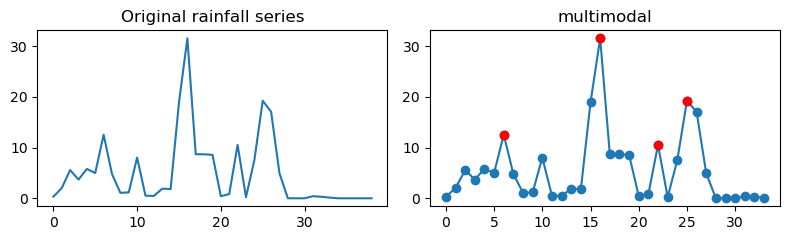

[ 2.8967323 46.87862    5.95188   11.441462   3.674669 ]
Event index: 12513, result: unimodal, n_peaks: 1


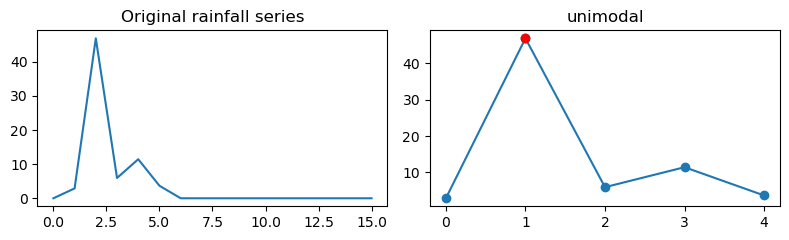

[ 6.2885909  30.356167    0.42055714  0.32580647  0.63601619]
Event index: 12520, result: unimodal, n_peaks: 1


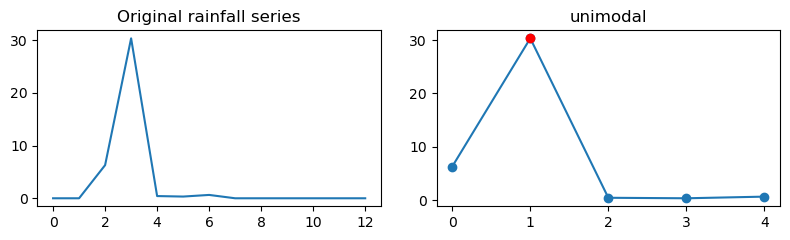

[ 1.2179192  32.457321   14.937968    6.2928233   0.55206054]
Event index: 12521, result: unimodal, n_peaks: 1


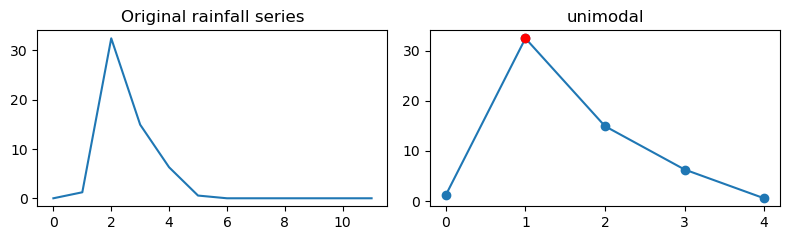

[7.9569678e+00 4.1109447e+01 9.7399745e-03 2.7766347e-02 1.7479295e-02
 1.1014830e-05 2.1072317e-06 2.3084201e-06 9.4711953e-01 5.5733907e-01
 6.0023694e+00]
Event index: 12532, result: unimodal, n_peaks: 1


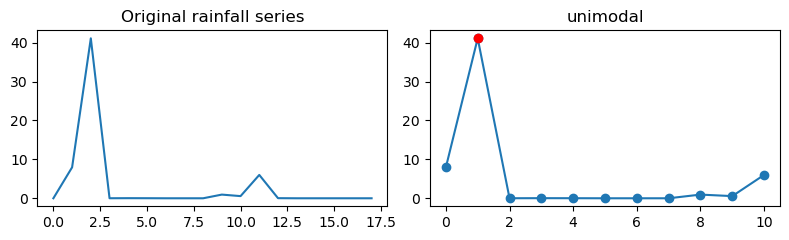

[ 1.8375354 33.343742   2.3964546]
Event index: 12538, result: unimodal, n_peaks: 1


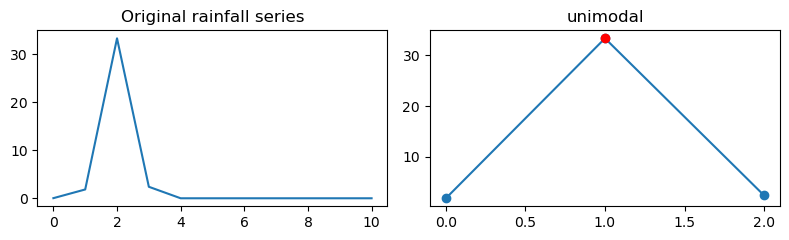

[1.9442004e+00 4.6103081e+01 1.1899244e+01 3.8864347e-01 7.4874144e-04
 3.5806229e-06 1.0684008e-06 6.1465255e-07 1.2261656e-06 3.3380153e+00
 1.6614628e+00 3.3450775e+00]
Event index: 12541, result: unimodal, n_peaks: 1


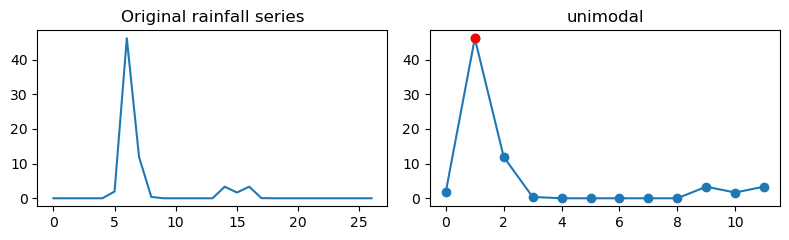

[3.9823647e+00 2.2337847e+00 3.9389271e-02 1.4210242e+01 2.3795040e+00
 3.0935400e+01 3.1756184e+00 7.4696569e+00 5.7560291e+00 2.6617777e-01
 5.0468302e-01 2.1467033e-01 1.3259085e-05 2.7419205e-04 1.7558566e+00
 1.7356156e-01 7.4941130e+00 1.5903526e-06 1.3431759e-06 8.2088643e-01
 1.5802668e-04 1.1062691e-01 2.9126173e-01]
Event index: 12548, result: unimodal, n_peaks: 1


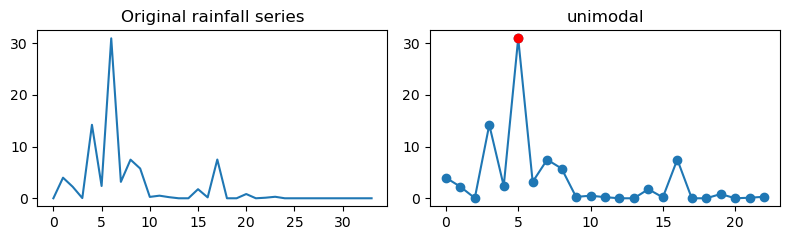

[ 0.39378744  3.069185   30.703741    3.9871619 ]
Event index: 12562, result: unimodal, n_peaks: 1


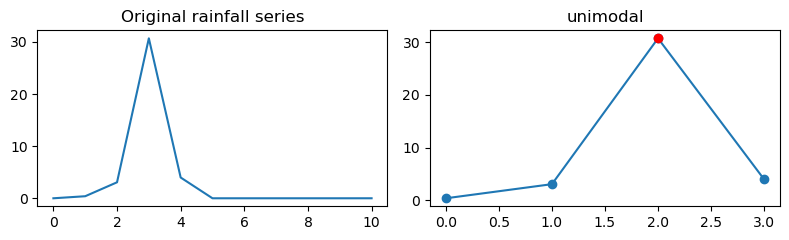

[ 0.27987143  0.59951103 33.356426    1.0224711 ]
Event index: 12570, result: unimodal, n_peaks: 1


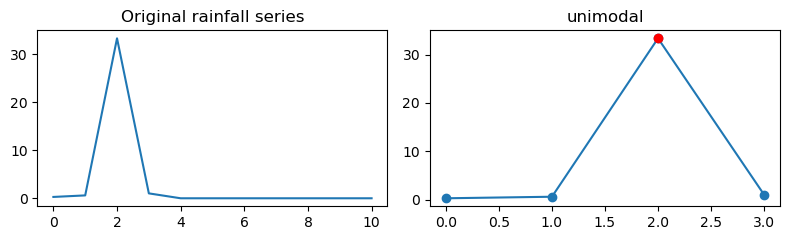

[ 5.8231611   0.19782361  0.13871305  0.62135768  2.8508976  14.945946
  0.17008705  0.55210459  1.2924807   1.0680817   4.4158812   2.2912502
  7.519393    0.21635185  1.6263653  32.493343   10.390312    0.27654958
  7.3368802   8.9873266   4.5700889   3.7191069   2.4337144   2.3743913 ]
Event index: 12573, result: bimodal, n_peaks: 2


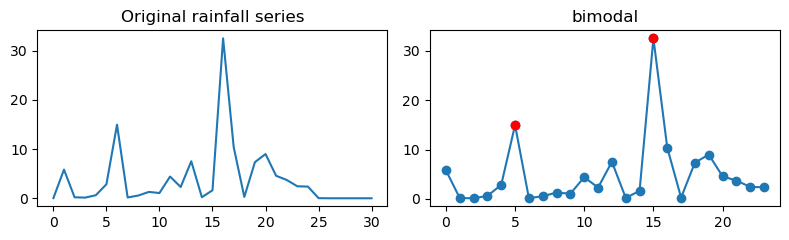

[ 6.4386382  55.405281    7.2518792   0.61706728]
Event index: 12574, result: unimodal, n_peaks: 1


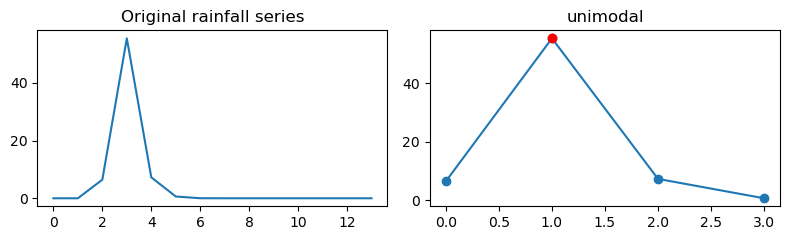

[2.0149751e+00 1.9817460e-02 4.1455445e-07 3.8092491e-01 4.1728730e+00
 1.5017699e+01 4.4516596e-01 1.0656374e+01 4.1950130e+00 2.3155537e+01
 5.4839187e+00 2.1658232e+00 6.8043723e+00 8.9934468e-01 8.4596100e+00
 2.7002935e+00 1.5942905e+00 2.3639243e+00 5.3124040e-01 6.5842676e+00
 1.0858108e+01 1.7287949e+01 3.0157473e+01 1.3142266e+01 1.2378203e+00
 1.8533010e-05 2.7580347e+00 8.1753025e+00 1.3871101e+00 2.2752415e-01
 1.8428090e+00 2.2156754e+00 1.3865229e+00 5.7091886e-01 5.7378672e-02
 6.9977507e-02 7.0620576e-06 6.4476311e-02 2.6137595e+00 1.4668796e+00
 7.3519781e-02 7.9559412e+00 8.2067290e-06 4.8596598e-06 5.7964406e+00
 1.7398114e+00 8.7932215e+00 2.6039391e+00 1.4639034e-05 1.2844610e-04
 5.9212707e-02 1.2696247e+00 2.3454782e-01]
Event index: 12577, result: multimodal, n_peaks: 3


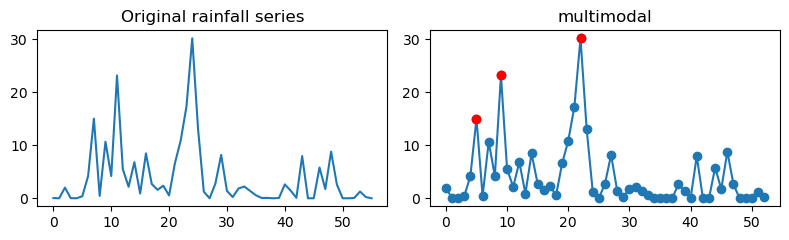

[ 1.5632714 21.819901  48.095814  16.293653 ]
Event index: 12583, result: unimodal, n_peaks: 1


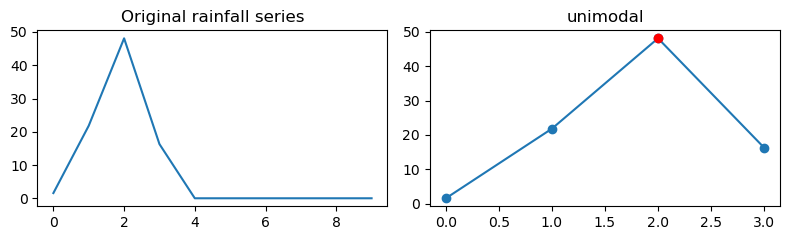

[ 0.12345345  8.23641586  1.45960093  1.91809237 37.2372398   2.1897521 ]
Event index: 12585, result: unimodal, n_peaks: 1


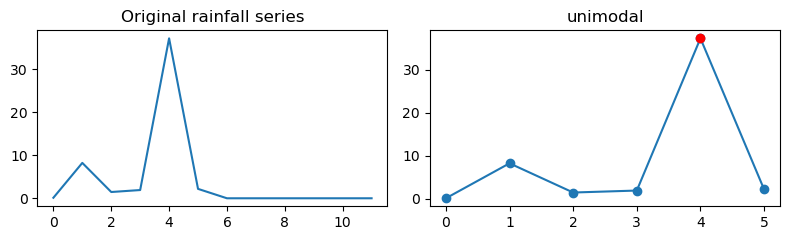

[48.76606    3.2835863]
Event index: 12586, result: unimodal, n_peaks: 1


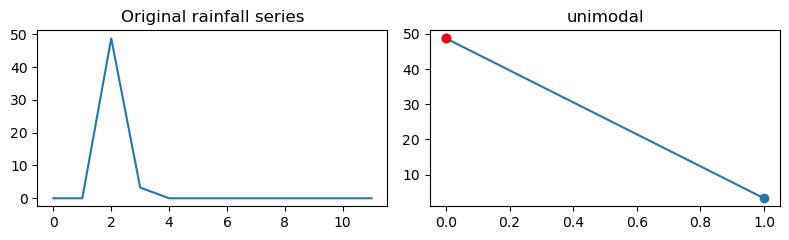

[5.6227036e+01 8.1622562e+00 3.0791059e-03 5.2637663e-03 1.1691845e-06
 1.8242920e-06 1.5886222e-06 1.7619928e-06 1.7110654e-06 2.4701642e-06
 1.1092548e-06 1.7066196e-06 9.8643297e-01 1.2107778e-01 9.8587096e-02]
Event index: 12590, result: unimodal, n_peaks: 1


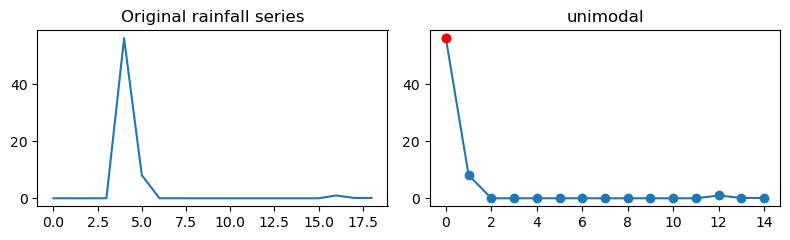

[5.4509874e-02 3.7812928e-04 1.4847406e-06 1.3596305e-06 2.2583663e-01
 7.8617817e-01 3.8958820e+01 3.2012811e+00]
Event index: 12591, result: unimodal, n_peaks: 1


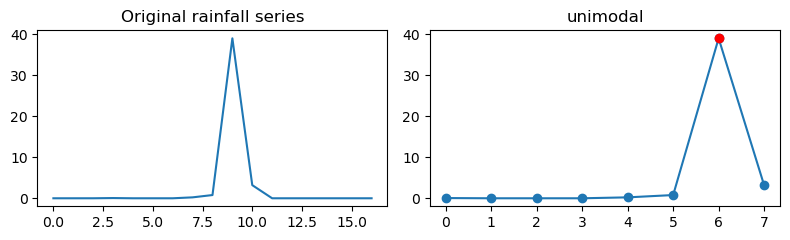

[4.4141817e-01 1.8452234e+00 7.0516748e+00 5.0919156e+00 2.6809318e+00
 1.5356450e+00 6.7724419e-01 1.4802611e+01 1.0607961e+01 2.1799129e-01
 5.8477367e-03 3.1159792e-02 4.2754665e-01 7.6703382e+00 4.2655764e+00
 4.5258207e+00 1.6931798e+00 1.0190792e+00 4.3462944e+00 9.5534067e+00
 6.2933993e+00 6.6313791e+00 1.0050770e+01 1.3250176e+01 8.6932116e+00
 7.1227660e+00 2.0063114e+01 3.7987648e+01 7.9005303e+00 4.0612383e+00
 2.0392635e+00 1.4863561e+00 1.1106656e+00 8.9108002e-01]
Event index: 12593, result: multimodal, n_peaks: 3


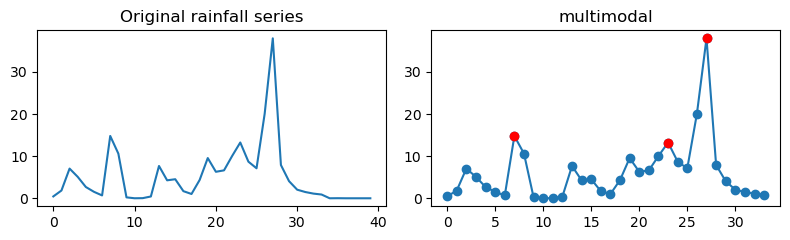

[ 6.68256474 33.4304314   2.56320906]
Event index: 12594, result: unimodal, n_peaks: 1


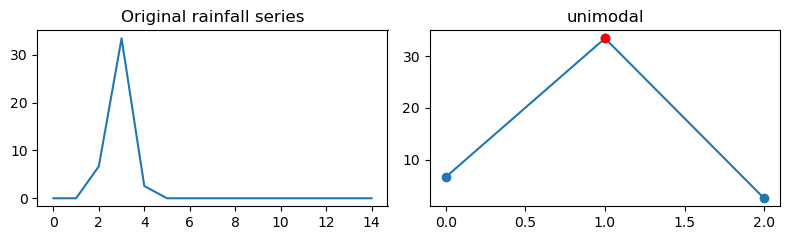

[1.6425618e+00 3.1393166e+00 3.2184657e-04 4.0102657e-04 3.0871349e-06
 2.5043539e-06 2.3577879e-06 3.8938773e-01 3.2808769e+01 5.9010949e-02
 7.4024615e+00 1.4035245e+00 4.3160573e-02 3.7523784e-02 2.2561829e-07
 9.8806270e-04 1.5694644e-06 5.7291575e-02 8.0822551e-01 6.1437935e-02]
Event index: 12595, result: unimodal, n_peaks: 1


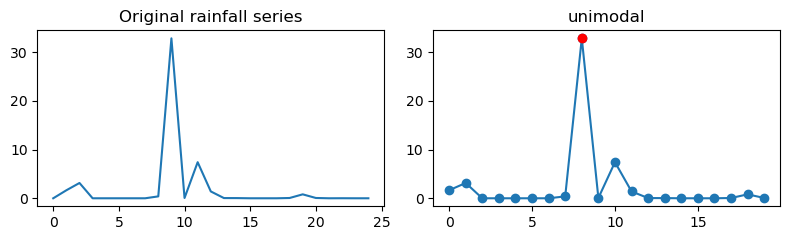

[ 0.07570228 31.718273    1.7156581 ]
Event index: 12596, result: unimodal, n_peaks: 1


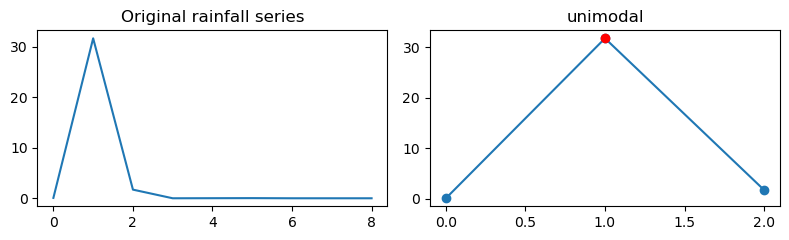

[3.5180104e+00 4.0540600e+00 5.3742480e+00 3.2156128e+01 7.6079254e+00
 7.2553186e-05 5.8718538e-01 1.6111383e-01 1.4178588e+01]
Event index: 12609, result: bimodal, n_peaks: 2


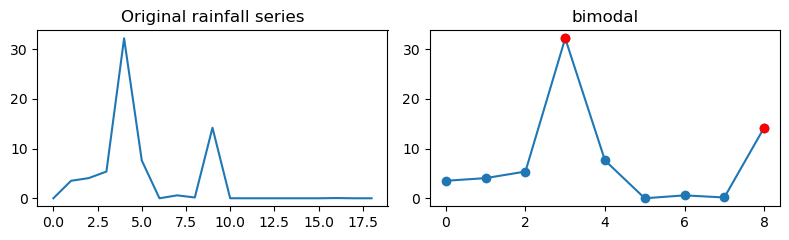

[1.3010473e+00 9.2612451e-01 1.5096109e-01 3.6536835e+01 5.6093941e+00
 8.5604433e-06 1.4386643e-01 3.8205402e+00 1.0423587e-06 6.0321730e-01]
Event index: 12615, result: unimodal, n_peaks: 1


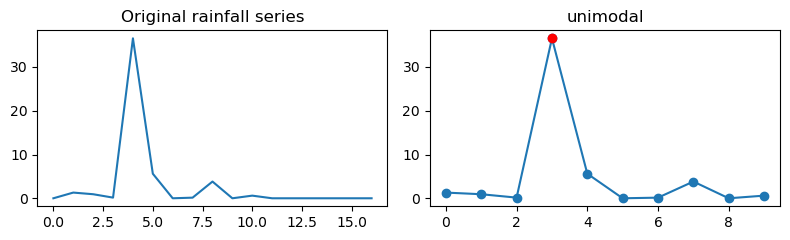

[ 2.4284434   3.9070525  10.561854   13.957721   10.442762   34.503689
 10.759189    3.0272212   0.98152125  0.28998968  0.25338471  0.41042337
  1.0566182   0.0827892   0.68387741  0.41237566]
Event index: 12616, result: unimodal, n_peaks: 1


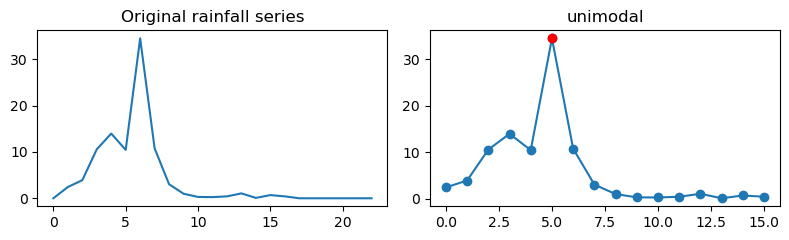

[ 3.4604475  34.257877    0.51410484]
Event index: 12630, result: unimodal, n_peaks: 1


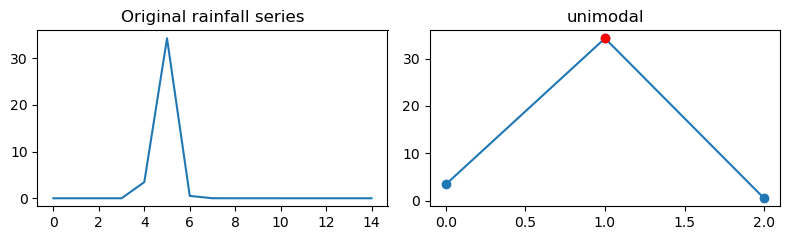

[ 0.15429041  5.1416554  39.55669    23.305908    5.7444549   0.34361836]
Event index: 12632, result: unimodal, n_peaks: 1


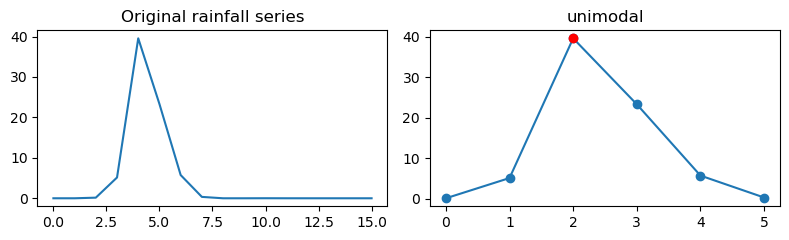

[1.1961231e+00 1.0631198e-01 4.6989074e+00 2.8505115e-02 2.3185551e-01
 4.0222130e+01 1.6726883e+01 5.1753861e-01 4.6782574e-01 6.0180587e-01
 3.2718280e-01 1.4938969e-04 2.4407252e-03 2.0328145e-03 1.1783572e-03
 3.8754910e-03 1.3440915e-03 1.2662618e-03 4.0495879e-04 1.4687406e-03
 5.5411542e-03 2.1815633e-02 2.6969817e-03 4.5337602e-02 4.6341029e-01
 2.3574041e-02 2.2766800e+00]
Event index: 12641, result: unimodal, n_peaks: 1


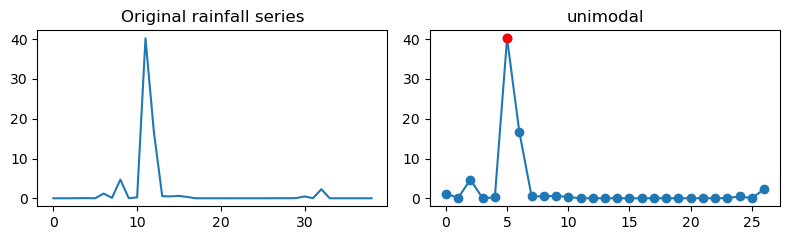

[ 2.2071464  37.564186    0.6414749  16.848658    1.9839021   0.14947385]
Event index: 12644, result: unimodal, n_peaks: 1


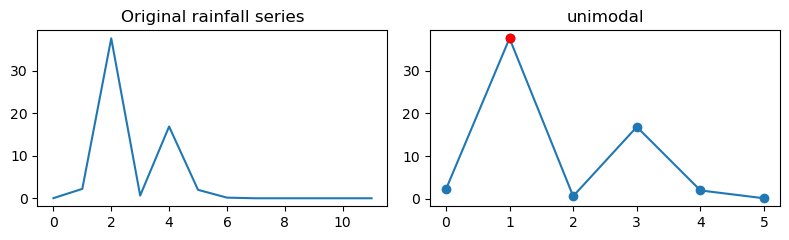

[7.1641397e+00 5.9674472e-01 1.3090727e-01 2.6167454e-06 2.0259724e-06
 5.8369728e-06 2.1552366e-06 2.7998513e-01 1.7219089e-01 3.6192201e-03
 1.7904151e-04 5.6889302e-01 3.1725392e-02 4.1615204e-03 6.8424292e+00
 1.4765060e+00 2.2758306e-05 2.7964813e-01 7.0070612e-01 1.2846085e-01
 1.5958188e-04 1.1867602e-06 1.3929769e-06 1.4217762e-06 1.9625925e-06
 8.1699207e-02 2.2826311e-01 4.9940784e+01 1.9819334e+00 4.7393460e-06
 1.1626763e-06 1.4386686e+00 5.1243968e+00 1.9114679e+00 9.2741057e-06
 1.3713745e+00 4.1180243e+00 1.7288054e+00 2.0053868e-01 1.7474152e-02
 1.0496662e-01 1.0738318e+00 3.3614582e-01 8.8495026e+00 7.0196461e-07
 2.3550692e-01 9.5832944e-01]
Event index: 12663, result: unimodal, n_peaks: 1


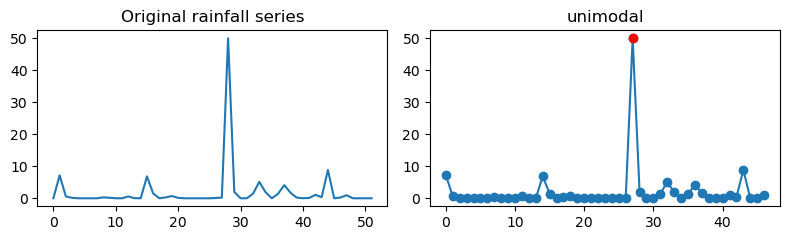

[2.45064512e-01 3.81134319e+00 1.03397034e-01 3.34445685e-02
 5.35637558e-01 7.19888973e+00 1.18742646e-05 2.32756656e-06
 2.87336957e-06 9.75999910e-07 2.29307807e-06 1.41377553e-01
 7.13346340e-03 3.54052663e+00 7.86798143e+00 1.09382229e+01
 1.41638088e+01 4.13794670e+01 1.78232110e+00 2.62049172e-04
 5.33589721e-03 2.36774111e+00 4.00077391e+00 1.08132800e-02
 1.38927877e-01 5.20372887e-05 5.45590156e-05 8.91331375e-01
 5.94066322e-01 2.46087611e-01 1.27361918e-05 8.80574465e-01
 1.44303352e-01 8.64415546e-04 2.86137629e-06 5.67204738e-03
 1.11687087e-01 2.92752148e-03 2.86530417e-06 1.17838733e-01]
Event index: 12664, result: unimodal, n_peaks: 1


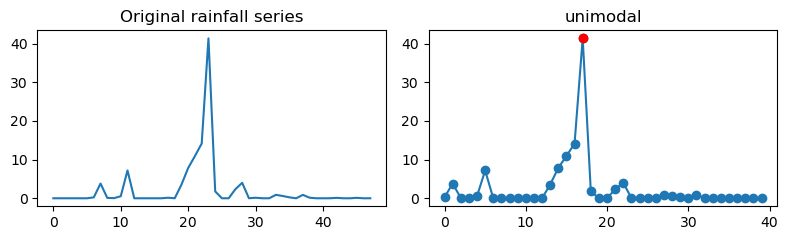

[1.7477125e+01 1.1452987e+00 6.6794460e-03 9.7949400e+00 3.2344082e+01
 9.7699368e-01 4.5595708e+00]
Event index: 12667, result: bimodal, n_peaks: 2


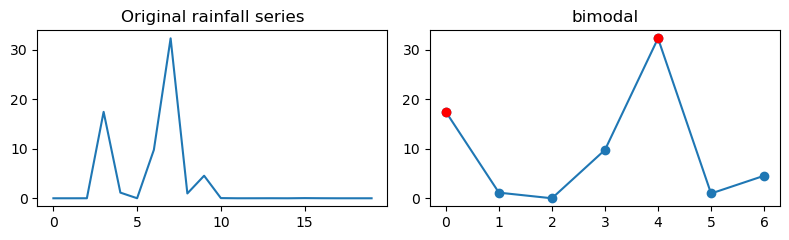

[38.502357 25.533108]
Event index: 12668, result: unimodal, n_peaks: 1


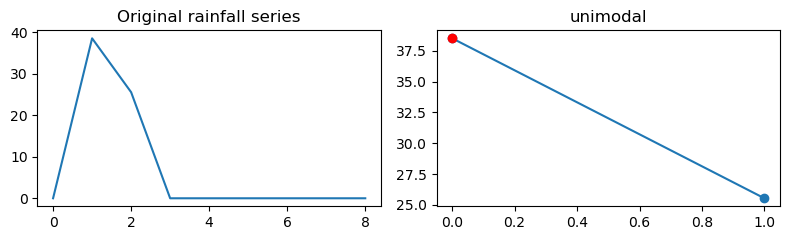

[ 2.1437149  5.2346139 44.930309   4.7340355]
Event index: 12670, result: unimodal, n_peaks: 1


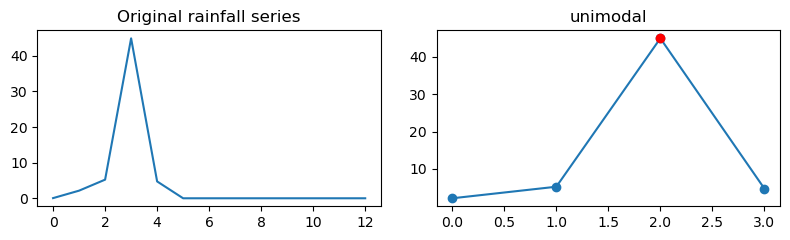

[2.3718238e+00 2.2608635e-01 2.2589916e-06 1.0534462e-06 3.1017232e-06
 1.1652954e-06 5.1307994e-01 1.8197042e+00 6.4333290e-01 1.8224319e-02
 3.2332328e-01 3.2225864e+01 2.1331985e+00 6.5752053e-01 5.4263935e-05
 9.9120114e-04 1.2767703e-04 4.2397719e-06 1.7879589e-02 2.6030678e-03
 1.8091660e+00 4.2919181e-02 7.8892596e-03 3.2840067e-01 1.9048029e+00
 1.7801832e-06 3.3495837e-06 1.9734775e-06 1.1898397e+00 2.8127803e-02
 1.9412264e-06 2.6352491e-06 1.6313422e-06 3.6315032e-06 9.8264265e+00
 3.2438645e+00 5.5354178e-01 2.2722615e-01 2.2119110e+00 4.1135845e+00
 5.6626868e+00 6.9287295e+00 3.3773651e+00 4.4517102e+00 2.1572039e+00
 9.9663800e-01 4.1527823e-05 1.4986485e-01 7.5433272e-01 9.2171989e-03
 1.4287293e+00 2.1723574e-06 4.3253508e-06 9.1531962e-01 6.0205549e-01]
Event index: 12684, result: unimodal, n_peaks: 1


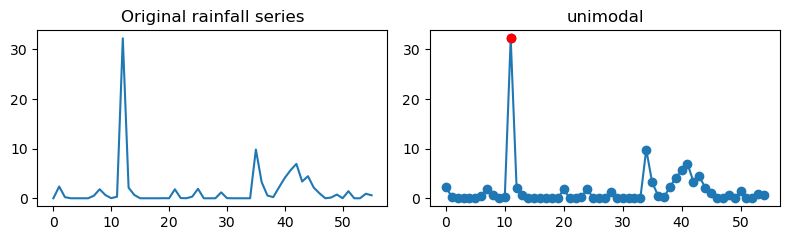

[2.1301359e-01 9.9272758e-02 9.1947732e-06 9.5572968e+00 3.1042540e+01
 5.5629098e-01]
Event index: 12714, result: unimodal, n_peaks: 1


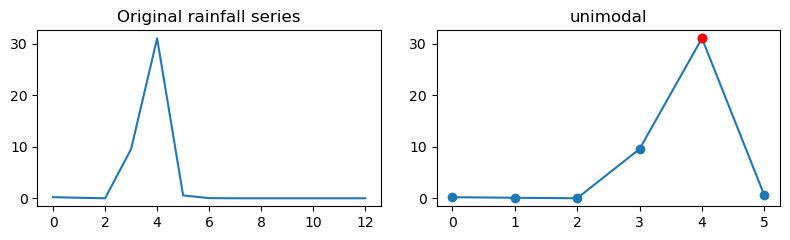

[4.4499898e-01 2.4499862e+00 1.7130540e-01 3.4061852e-01 2.3877630e-03
 3.9722257e+00 6.5375938e+00 6.0150423e+00 3.1611316e+00 5.0983748e+00
 1.9345938e+00 1.6181371e+00 4.2151074e+00 1.8444376e+01 3.8952000e+01
 9.3742170e+00 9.2330847e+00 1.5252793e+01 2.4070614e+01 2.1090405e+01
 5.8267908e+00 5.5103893e+00 3.3597865e+00 5.0560699e+00 3.6990855e+00
 3.5490799e+00 2.3160932e+00 1.5230912e+00 2.4556330e-01 1.4857020e-03
 5.7101756e-06 5.5947461e-05 2.2401943e-04 4.6675724e-01]
Event index: 12718, result: bimodal, n_peaks: 2


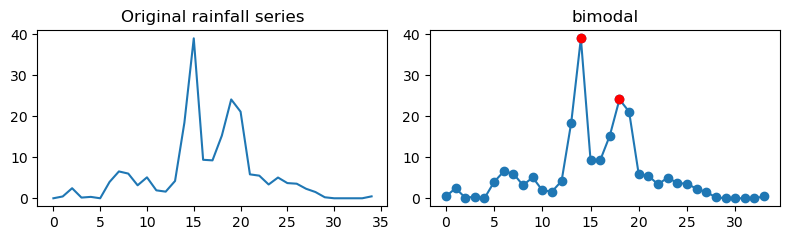

[1.6013026e+00 5.4256711e+00 7.1501851e-01 3.6739803e+01 1.1067421e+01
 8.6772661e+00 1.2511068e+01 1.1313392e-06 7.2373030e-07 1.1829553e-06
 1.3380488e-06 9.5365323e-02 2.1823452e+00 1.2561994e+01 2.9729107e+01
 1.4249589e+00 6.2419537e-02 1.6094880e-01 1.8103846e-06 2.7069734e-06
 2.1064236e-06 1.1767980e-06 1.5665572e-06 4.7583485e-01]
Event index: 12735, result: multimodal, n_peaks: 3


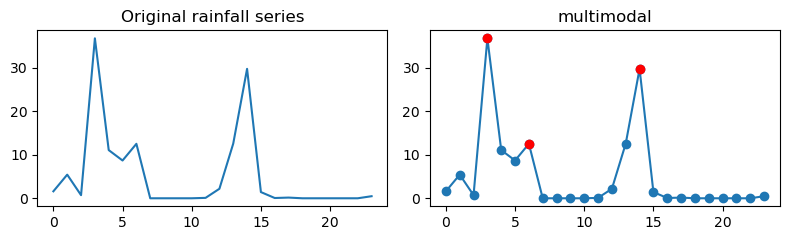

[ 0.07982657 28.095577   45.50914     4.3955913   0.13283473]
Event index: 12743, result: unimodal, n_peaks: 1


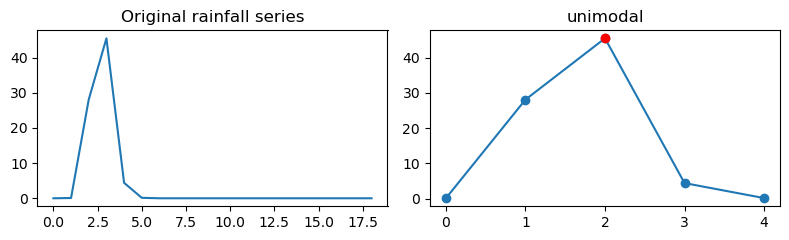

[3.5405976e-01 2.8346696e+00 2.9642708e+00 5.1795878e+00 9.1772652e+00
 8.5398817e+00 1.5074237e+01 1.7317127e+01 4.0961643e+01 8.2685585e+00
 1.3488199e+01 1.6971885e+00 1.3562691e-03 2.4492049e-06 1.5834141e-04
 3.5794149e-03 2.4589746e+00 1.2752552e+00 8.1673741e-02 7.4321002e-02]
Event index: 12759, result: unimodal, n_peaks: 1


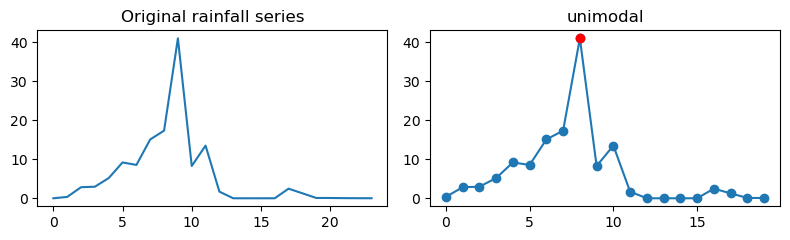

[3.8138263e+00 3.3627338e+01 5.7020068e+00 3.8122191e-06 5.1479721e-05
 1.3760564e-05 2.5786561e-04 6.0634404e-02 1.2086368e+00 5.1720066e+00
 1.1681465e+00 4.2787981e+00 4.9647343e-01 1.1340546e+01 2.5138242e+00
 1.0841022e-01 4.9529615e-04 6.0022244e-04 8.1564672e-03 5.5039302e-03
 3.3408359e-02 3.5032693e-01]
Event index: 12762, result: bimodal, n_peaks: 2


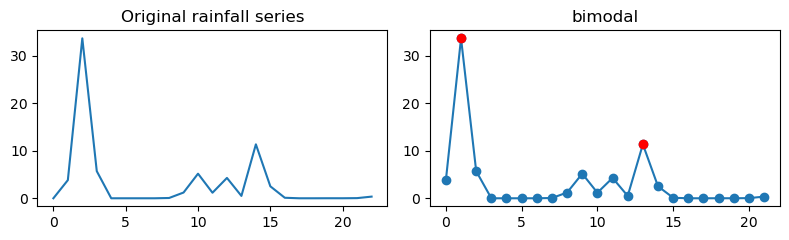

[1.19438410e-01 4.28460541e+01 1.11380224e+01 1.10264289e+00
 5.65535486e-01 5.16817331e-01 6.22096285e-02 1.25719535e+00
 6.73921633e+00 1.13759506e+00 1.02327408e-06 5.45765460e-01
 5.36387300e+00 2.83499789e+00 1.23334594e-01 3.92026959e-06
 1.33433980e-06 1.43533873e-06 1.12037344e-06 4.23601250e-06
 4.30349019e-06 2.91375494e+00 1.81631763e-02 7.72106250e-06
 1.00126708e-05 5.58455395e-06 8.37634385e-01]
Event index: 12766, result: unimodal, n_peaks: 1


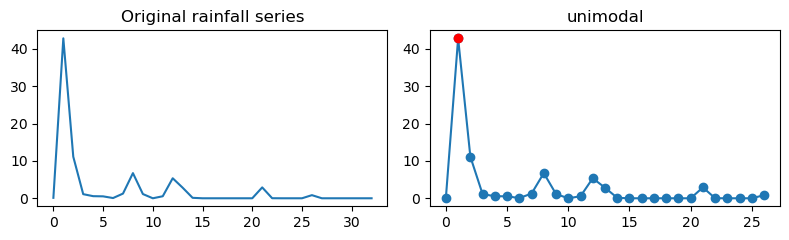

[5.5790015e-02 7.3035245e+00 5.9941044e+01 3.0314240e+01 1.2944098e-01]
Event index: 12776, result: unimodal, n_peaks: 1


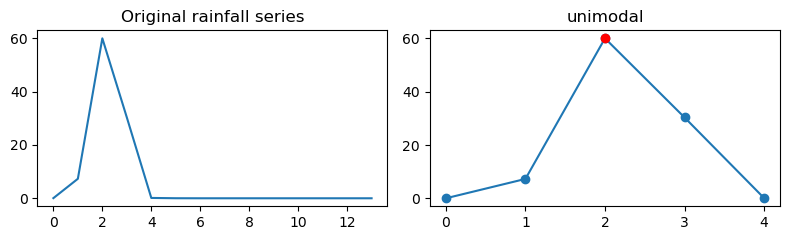

[ 0.06622931 33.412086    1.4324701 ]
Event index: 12782, result: unimodal, n_peaks: 1


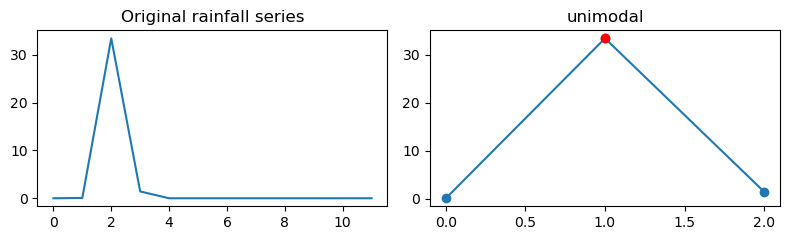

[6.69537401e+00 3.43998814e+00 4.08344458e-05 9.41771939e-02
 3.33200493e+01 3.38320851e+00 8.61396790e-01 1.65819615e-01
 6.62538671e+00 1.32730361e-02 1.99159110e+00]
Event index: 12785, result: unimodal, n_peaks: 1


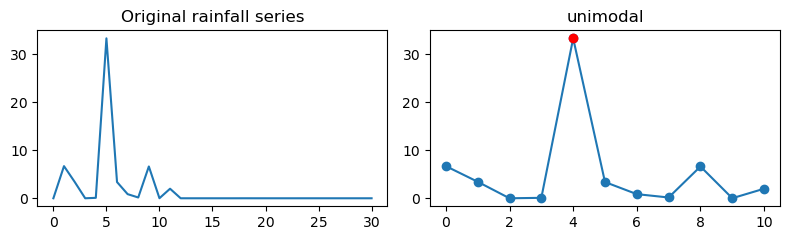

[3.2188469e-01 1.3342361e+00 2.4474089e+00 5.6829081e+00 1.1953848e+01
 1.1241668e+01 1.2764613e+01 1.9549725e+01 7.0602905e+01 3.5784676e+01
 2.7323212e+01 7.7327567e-01 2.2453089e+00 6.4451118e+00 1.0454664e+01
 2.7681690e-01 1.1967925e-02 4.5840556e-04 6.7371904e-05 1.7535651e-01]
Event index: 12788, result: multimodal, n_peaks: 3


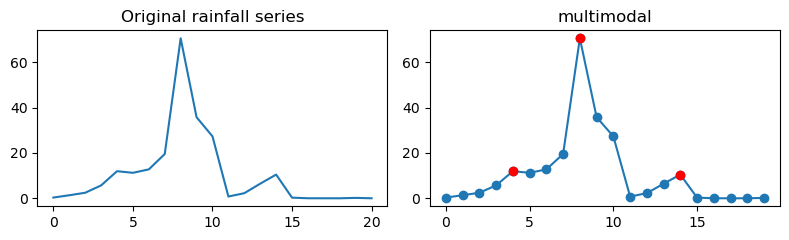

[3.1313665e+01 2.5225818e-01 7.9199108e-06 7.2414900e-07 2.2668657e-06
 1.0289849e+01 1.4838295e-06 8.7343365e-02 3.9922515e-01 6.4523659e+00]
Event index: 12789, result: bimodal, n_peaks: 2


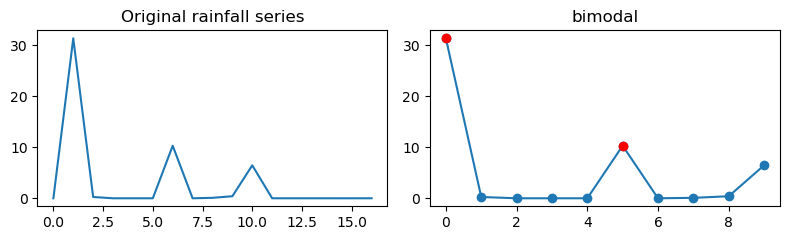

[3.5462039e+00 4.2296329e+01 2.4800287e+01 7.5657353e-02 1.5871235e-07
 4.6358086e-06 4.6769014e-07 7.2441850e-07 1.4776089e-06 1.0958106e-05
 1.2124678e-05 1.3628017e+00 2.7664298e-01]
Event index: 12790, result: unimodal, n_peaks: 1


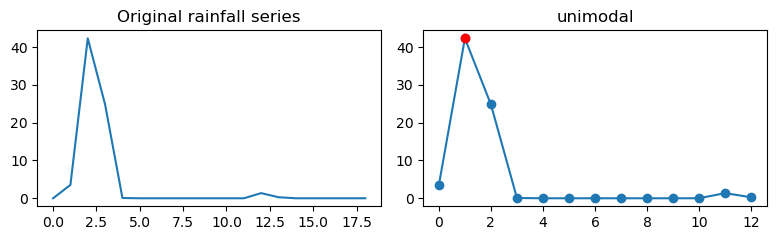

[1.9832584e-01 2.3923311e+00 2.5734234e+00 8.1920118e+00 3.0578494e-02
 3.0562965e-06 4.5311201e-01 1.1605151e-01 9.9583589e-02 1.7642406e-05
 8.7189545e-07 3.9282922e-02 3.6445089e-02 4.9279731e-07 1.9472966e-06
 2.5339575e-06 5.7423272e-04 4.4304352e+00 1.0438206e+01 2.0218301e+00
 5.7903752e+00 6.6310315e+00 1.1086070e+01 1.2254695e-05 1.0362161e-06
 1.2334324e-06 2.1856757e-01 5.2943142e-05 2.1977858e-06 6.4866815e-04
 1.4911350e-06 3.9695699e+00 3.0622143e-06 2.2546614e-03 1.9765490e+00
 4.2899959e-02 8.8501285e-04 9.9464655e-03 5.8897829e-01 4.4340210e+00
 6.5400586e+00 9.8210468e+00 1.1512652e+01 5.6149845e+00 4.6561198e+00
 3.2267372e+01 2.3082387e+00 4.2082277e-01 1.8629909e+00 2.3602486e-02
 1.1696634e-02 8.4273994e-01 3.1289113e-01 2.0173771e+00 4.5442843e+00
 5.2201023e+00 4.4548354e+00 4.5221410e+00 3.4554154e-01 4.3014159e+00
 3.5084307e+00 1.6449682e+00 3.1481113e-03 1.1597268e-01 3.9534814e+00
 8.2751598e+00 6.4084806e+00 7.3272877e+00 5.1651583e+00 1.7965057e+00
 1.274

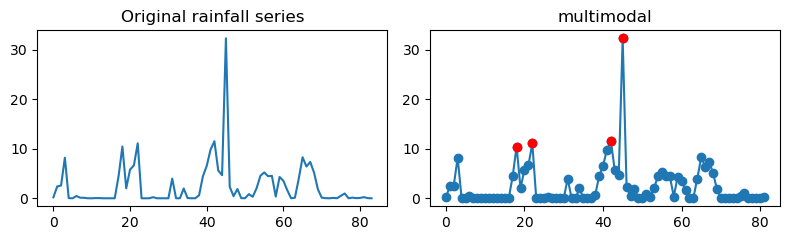

[ 0.28085726 41.10461     5.1780667 ]
Event index: 12797, result: unimodal, n_peaks: 1


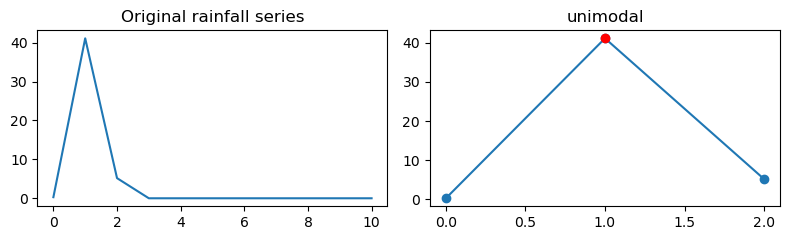

[ 0.05622218 38.098843    3.7025824 ]
Event index: 12798, result: unimodal, n_peaks: 1


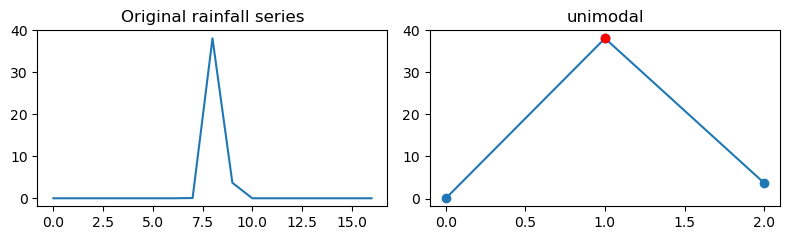

[2.0471542e-01 3.1231065e+00 2.0161681e+00 2.6114500e-01 2.2851933e-02
 7.0385581e-06 2.3075984e-06 6.4745203e-02 3.0630787e+01 2.7679858e+00]
Event index: 12808, result: unimodal, n_peaks: 1


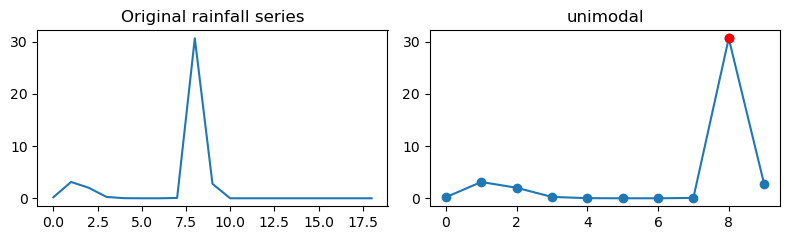

[ 7.4336658 31.452372 ]
Event index: 12825, result: unimodal, n_peaks: 1


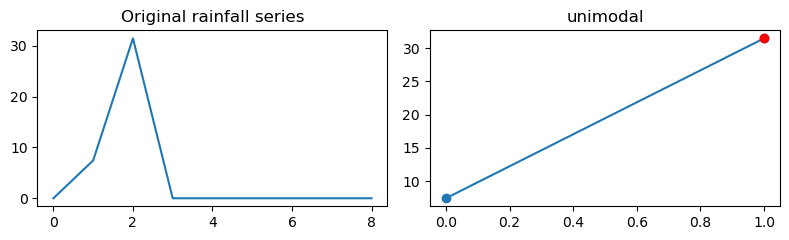

[ 9.2843876  43.772575    5.6295843   2.614665    0.52979225]
Event index: 12830, result: unimodal, n_peaks: 1


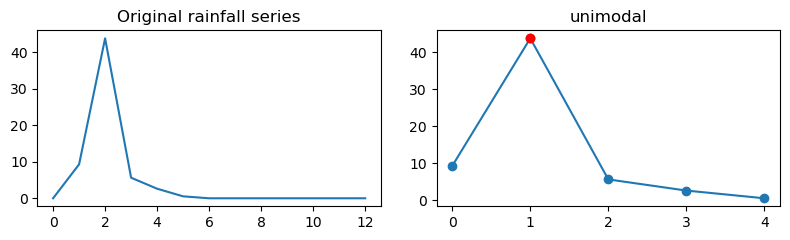

[1.01801195e+01 3.42346611e+01 6.00474691e+00 1.66082438e-02
 7.25323275e-07 2.32336736e+00 7.77849734e-01]
Event index: 12843, result: unimodal, n_peaks: 1


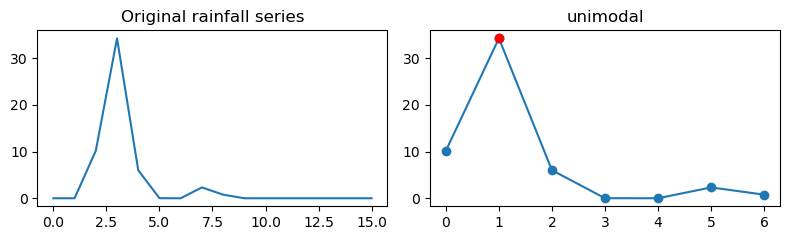

[9.7717412e-02 5.6772493e-02 4.5931265e-01 1.0608197e+00 9.3720350e+00
 6.0572920e+00 1.6178953e+01 4.8832784e+00 3.2821700e-01 6.2888868e-02
 2.3508449e-06 9.6751046e-07 1.3115040e-05 2.0366760e-02 9.0812397e-01
 1.3158511e-01 5.2172554e-06 2.5243241e-06 2.5814280e-02 3.0465779e-01
 3.5156017e+01 7.0267040e-01]
Event index: 12851, result: bimodal, n_peaks: 2


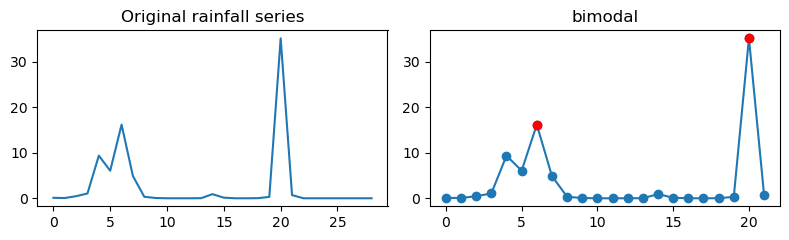

[3.0231383e+00 1.6535167e-02 4.3998369e-07 2.0728433e-03 3.6809151e+01
 4.8808079e+01 6.9391446e+00]
Event index: 12854, result: unimodal, n_peaks: 1


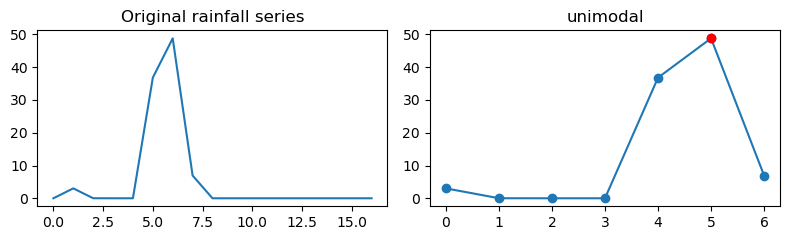

[20.844088 33.271633]
Event index: 12861, result: unimodal, n_peaks: 1


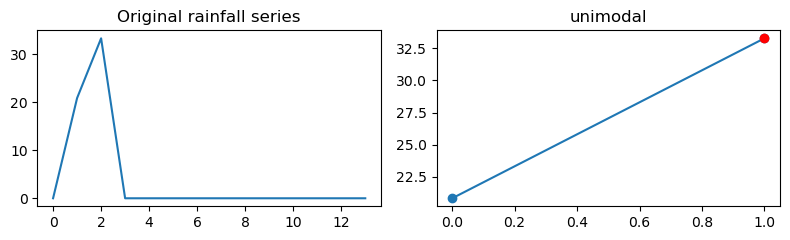

[13.018112  48.790676  16.728455   2.6000364]
Event index: 12872, result: unimodal, n_peaks: 1



KeyboardInterrupt



In [7]:
multi_events_one_pixel = rainfall_events_all_df[rainfall_events_all_df["peak_cell_id"] >= 1]

counts = multi_events_one_pixel["peak_cell_id"].value_counts()
busy_ids = counts[counts > 70].index

for pid, sub in multi_events_one_pixel[multi_events_one_pixel["peak_cell_id"].isin(busy_ids)].groupby("peak_cell_id"):
    print(f"Pixel {pid}: {len(sub)} events")

    for idx, row in sub.iterrows():
        values = np.fromstring(row["values"].strip("[]"), sep=" ")

        # Remove leading/trailing values below wet threshold
        wet = values > 0.05
        nonzero = np.flatnonzero(wet)

        if len(nonzero) == 0:
            continue

        trimmed_values = values[nonzero[0]:nonzero[-1] + 1]
        print(trimmed_values)
        result = classify_modality(trimmed_values)

        print(f"Event index: {idx}, result: {result['modality']}, n_peaks: {result['n_peaks']}")

        fig, axs = plt.subplots(ncols=2, figsize=(8, 2.5))
        axs[0].plot(values)
        axs[0].set_title("Original rainfall series")
        axs[1].plot(trimmed_values, marker="o")
        axs[1].scatter(result["peaks"], trimmed_values[result["peaks"]], color="red", zorder=3)
        axs[1].set_title(result["modality"])
        plt.tight_layout()
        plt.show()

0.37834134574012257


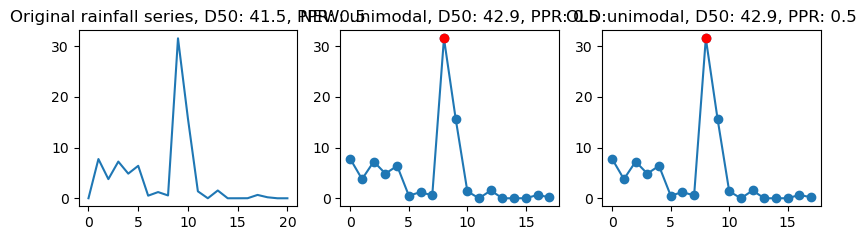

0.9614696067804327


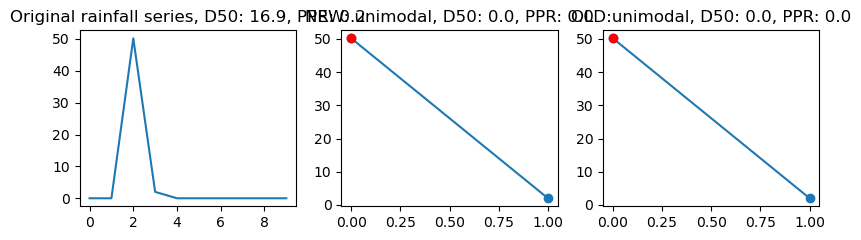

0.5187704469674277


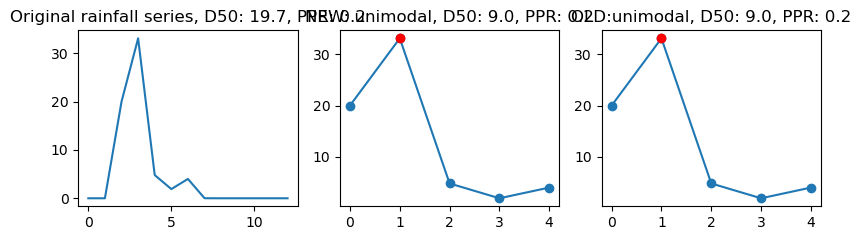

0.44097715199872584


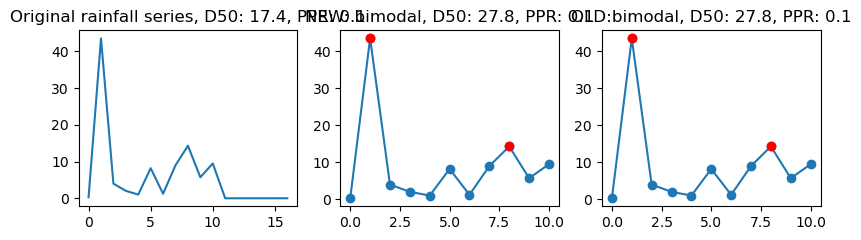

0.5338509425790033


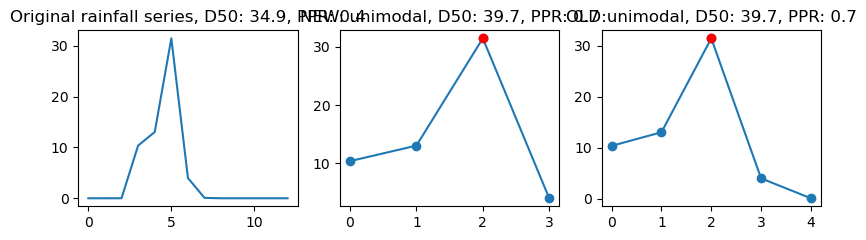

0.8090704652578609


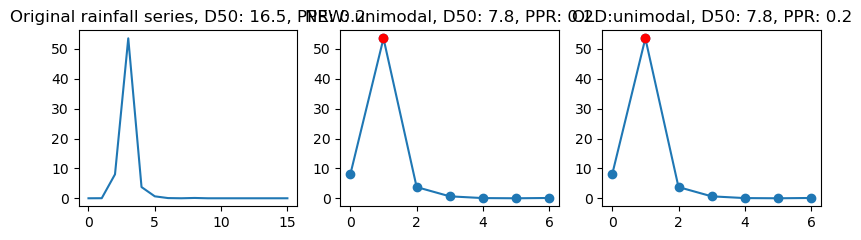

0.6584225221346165


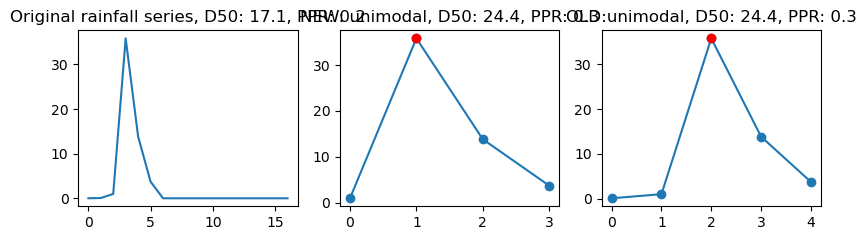

0.9452121682034056


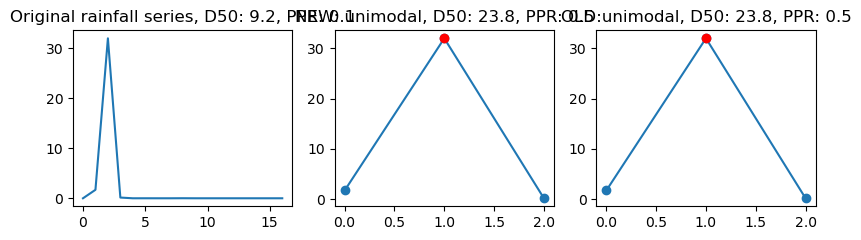

0.7075812570798468


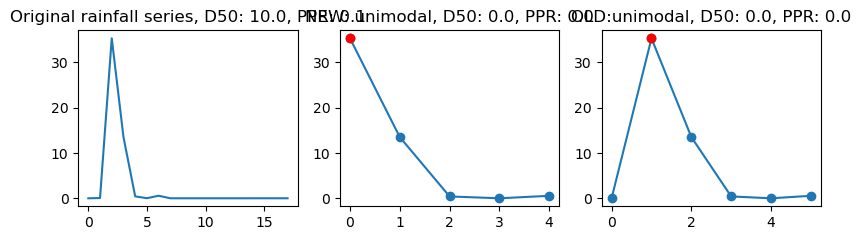

0.47740609742578094


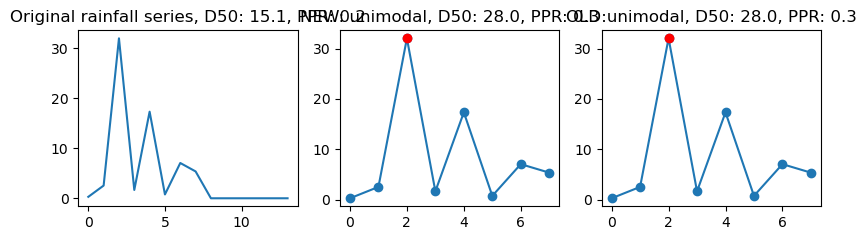

0.6778893424678318


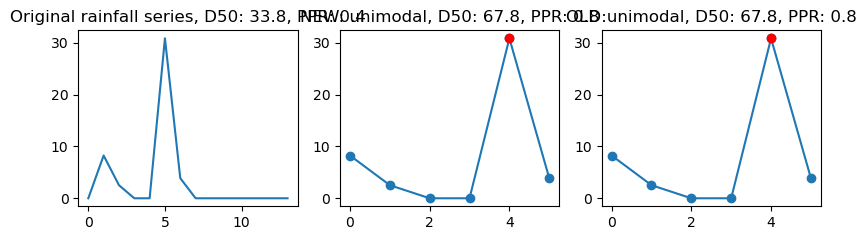

0.6600642033936794


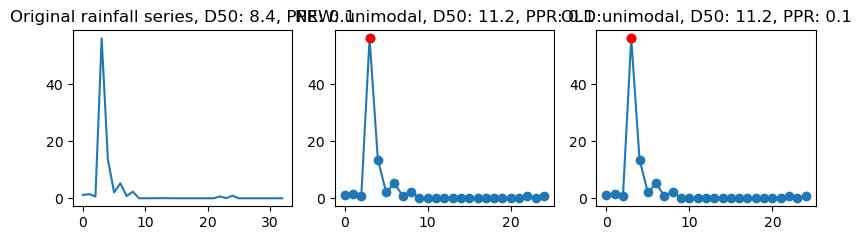

0.5799318848495431


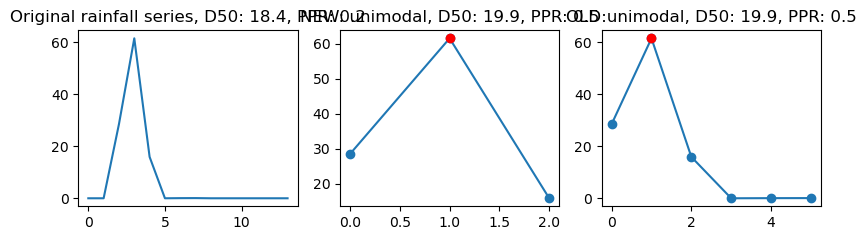

0.9444755777497316


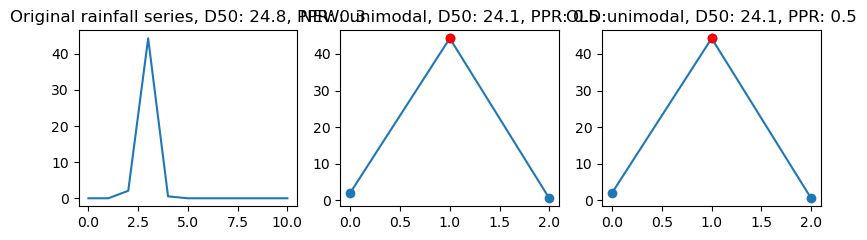

0.5302273209679439


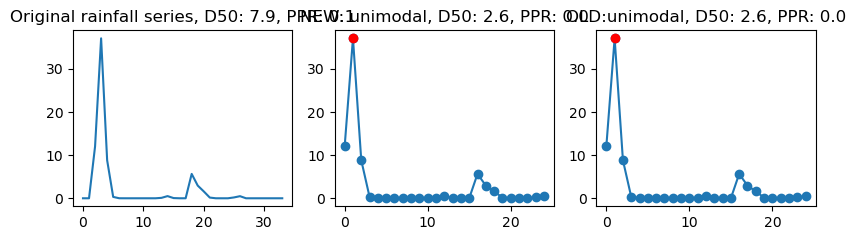

0.7017823614233522


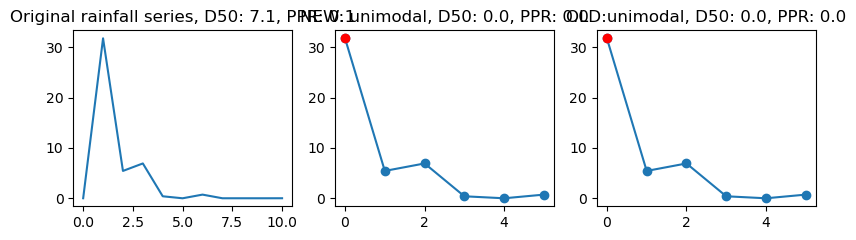

0.3134538989579253


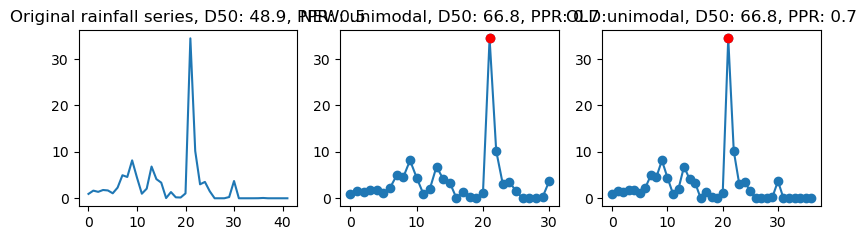

0.8614167876260934


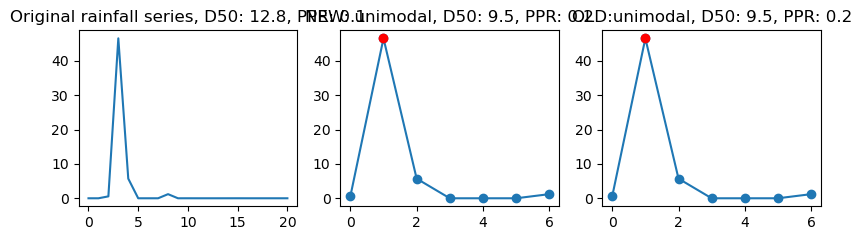

0.7529175875533751


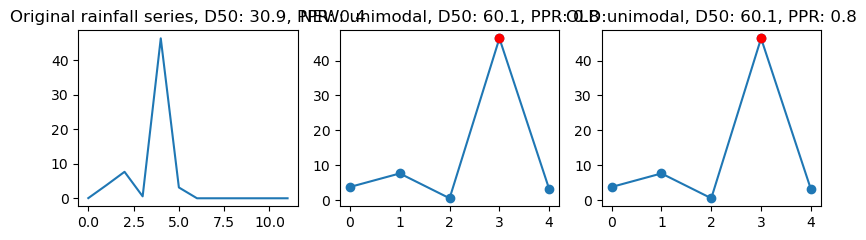

0.7399204941254324


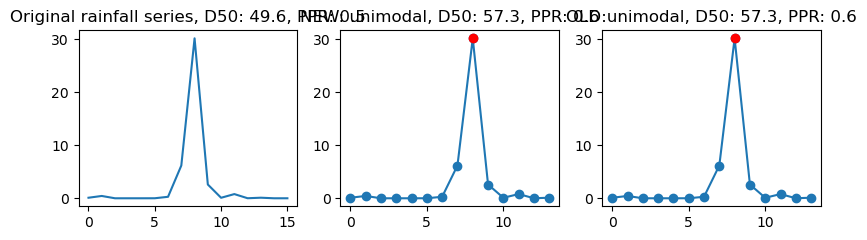

0.6887896663422883


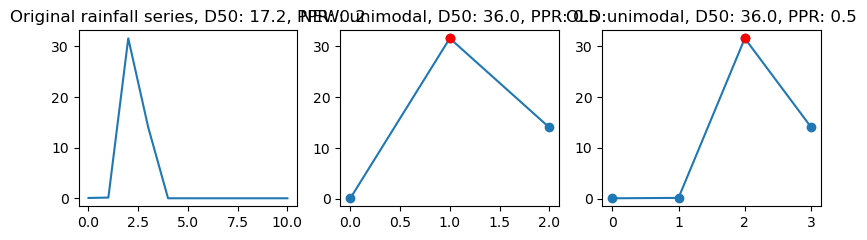

0.5490494212843335


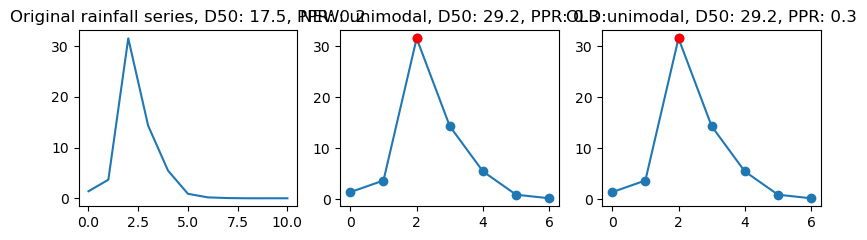

0.09245370331142792


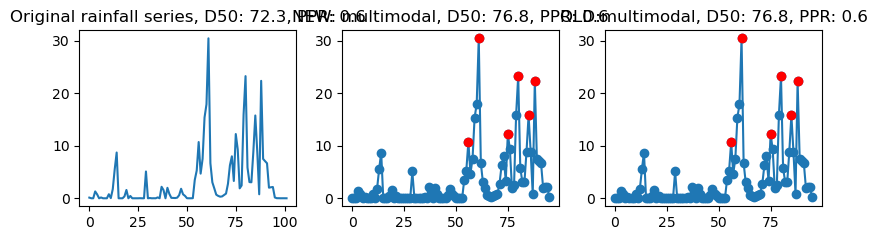

0.6322453823809548



KeyboardInterrupt



In [8]:
modal_class = []
for idx, row in sub.iterrows():
    print(row['peak_share'])
    values = np.fromstring(row["values"].strip("[]"), sep=" ")

    # Remove leading/trailing values below wet threshold
    wet = values > 0.1
    nonzero = np.flatnonzero(wet)

    if len(nonzero) == 0:
        continue

    trimmed_values = values[nonzero[0]:nonzero[-1] + 1]
    
    # Remove leading/trailing values below wet threshold
    wet = values > 0.05
    nonzero = np.flatnonzero(wet)

    if len(nonzero) == 0:
        continue

    trimmed_values_old = values[nonzero[0]:nonzero[-1] + 1]
    
    # print(trimmed_values)
    result = classify_modality(trimmed_values)
    result_old = classify_modality(trimmed_values_old)
    modal_class.append(result['modality'])
    #print(f"Event index: {idx}, result: {result['modality']}, n_peaks: {result['n_peaks']}")

    fig, axs = plt.subplots(ncols=3, figsize=(8, 2.5))
    axs[0].plot(values)
    axs[0].set_title(f"Original rainfall series, D50: {row['d50']:.1f}, PPR: {row['peak_position_ratio']:.1f}")
    axs[1].plot(trimmed_values, marker="o")
    axs[1].scatter(result["peaks"], trimmed_values[result["peaks"]], color="red", zorder=3)
    axs[1].set_title(f"NEW: {result['modality']}, D50: {row['d50_n']:.1f}, PPR: {row['peak_position_ratio_n']:.1f}")
    
    axs[2].plot(trimmed_values_old, marker="o")
    axs[2].scatter(result_old["peaks"], trimmed_values_old[result_old["peaks"]], color="red", zorder=3)
    axs[2].set_title(f"OLD:{result_old['modality']}, D50: {row['d50_n']:.1f}, PPR: {row['peak_position_ratio_n']:.1f}")    
    
    plt.tight_layout()
    plt.show()

sub['modal_class'] = modal_class

### Build multiple linear regression

In [47]:
features = ["max_precip", "total_acc", "d50_n"]
X = unimodal_events[features]
y = unimodal_events["10cm_area"]

# --- fit ---
model = LinearRegression().fit(X, y)
print("Intercept:", round(model.intercept_, 3))
print("Coefficients (change in 10cm_area per 1 unit of each variable):")
print(pd.Series(model.coef_, index=features).round(4))

# --- how accurate is the model? ---
print("\nR2, in-sample:", round(model.score(X, y), 3))

cv_pred = cross_val_predict(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0))
print("R2, cross-validated:", round(r2_score(y, cv_pred), 3))      # the honest number: tested on events not used for fitting
print("RMSE (cv):", round(np.sqrt(mean_squared_error(y, cv_pred)), 3), "| MAE (cv):", round(mean_absolute_error(y, cv_pred), 3))

# --- how much does each variable contribute? ---
full_r2 = model.score(X, y)
rows = []
for f in features:
    others = [c for c in features if c != f]
    r2_alone = LinearRegression().fit(X[[f]], y).score(X[[f]], y)                   # R2 using only this variable
    r2_without = LinearRegression().fit(X[others], y).score(X[others], y)           # R2 using everything except it
    rows.append({"variable": f, "R2_alone": r2_alone, "R2_lost_if_removed": full_r2 - r2_without})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))

# --- coefficients on a common scale (so the two variables can be compared) ---
Xz, yz = (X - X.mean()) / X.std(), (y - y.mean()) / y.std()
print("\nStandardised coefficients (SD change in 10cm_area per 1 SD change in the variable):")
print(pd.Series(LinearRegression().fit(Xz, yz).coef_, index=features).round(3))

def cv_r2(cols):
    p = cross_val_predict(LinearRegression(), unimodal_events[cols], y, cv=KFold(5, shuffle=True, random_state=1))
    return r2_score(y, p)
print(cv_r2(["max_precip", "total_acc"]), cv_r2(features))

# --- prediction (pass a DataFrame so the column names match) ---
# print("\nPrediction for max_precip=30, total_acc=300:", model.predict(pd.DataFrame([[30, 300]], columns=features)))

Intercept: -0.313
Coefficients (change in 10cm_area per 1 unit of each variable):
max_precip    0.0124
total_acc     0.0028
d50_n         0.0015
dtype: float64

R2, in-sample: 0.871
R2, cross-validated: 0.842
RMSE (cv): 0.095 | MAE (cv): 0.076

   variable  R2_alone  R2_lost_if_removed
max_precip     0.760               0.198
 total_acc     0.665               0.046
     d50_n     0.102               0.029

Standardised coefficients (SD change in 10cm_area per 1 SD change in the variable):
max_precip    0.635
total_acc     0.319
d50_n         0.180
dtype: float64
0.8196439114464893 0.8452804674260468


In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

features = ["max_precip", "total_acc", "d50_n"]
X = unimodal[features]
y = unimodal["10cm_area"]

# --- fit ---
model = LinearRegression().fit(X, y)
print("Intercept:", round(model.intercept_, 3))
print("Coefficients (change in 10cm_area per 1 unit of each variable):")
print(pd.Series(model.coef_, index=features).round(4))

# --- how accurate is the model? ---
print("\nR2, in-sample:", round(model.score(X, y), 3))

cv_pred = cross_val_predict(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0))
print("R2, cross-validated:", round(r2_score(y, cv_pred), 3))      # the honest number: tested on events not used for fitting
print("RMSE (cv):", round(np.sqrt(mean_squared_error(y, cv_pred)), 3), "| MAE (cv):", round(mean_absolute_error(y, cv_pred), 3))

# --- how much does each variable contribute? ---
full_r2 = model.score(X, y)
rows = []
for f in features:
    others = [c for c in features if c != f]
    r2_alone = LinearRegression().fit(X[[f]], y).score(X[[f]], y)                   # R2 using only this variable
    r2_without = LinearRegression().fit(X[others], y).score(X[others], y)           # R2 using everything except it
    rows.append({"variable": f, "R2_alone": r2_alone, "R2_lost_if_removed": full_r2 - r2_without})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))

# --- coefficients on a common scale (so the two variables can be compared) ---
Xz, yz = (X - X.mean()) / X.std(), (y - y.mean()) / y.std()
print("\nStandardised coefficients (SD change in 10cm_area per 1 SD change in the variable):")
print(pd.Series(LinearRegression().fit(Xz, yz).coef_, index=features).round(3))

def cv_r2(cols):
   p = cross_val_predict(LinearRegression(), sub[cols], y, cv=KFold(5, shuffle=True, random_state=1))
   return r2_score(y, p)
print(cv_r2(["max_precip", "total_acc"]), cv_r2(features))

# --- prediction (pass a DataFrame so the column names match) ---
# print("\nPrediction for max_precip=30, total_acc=300:", model.predict(pd.DataFrame([[30, 300]], columns=features)))

Intercept: -0.325
Coefficients (change in 10cm_area per 1 unit of each variable):
max_precip    0.0136
total_acc     0.0022
d50_n         0.0015
dtype: float64

R2, in-sample: 0.86
R2, cross-validated: 0.812
RMSE (cv): 0.103 | MAE (cv): 0.08

   variable  R2_alone  R2_lost_if_removed
max_precip     0.751               0.274
 total_acc     0.571               0.050
     d50_n     0.093               0.031

Standardised coefficients (SD change in 10cm_area per 1 SD change in the variable):
max_precip    0.670
total_acc     0.296
d50_n         0.183
dtype: float64
0.8112494951461715 0.8348796602855441


In [45]:
unimodal_events = sub[sub['modal_class'] =='unimodal']

In [65]:
# xvar, yvar = "max_precip", "10cm_area"

# # Apply the same NaN filter the regression uses, *before* counting,
# # so ">20 events" means >20 usable events
# clean = rainfall_events_all_df.dropna(subset=[xvar, yvar, "hc_at_peak"])
# clean = clean[clean["peak_cell_id"] >= 0]      # ngroup gives -1 for NaN indices

# counts = clean["peak_cell_id"].value_counts()
# busy_ids = counts[counts > 20].index
# print(f"{len(busy_ids)} pixels with >20 events")

# # R² and p for each busy pixel
# rows = []
# for pid, sub in clean[clean["peak_cell_id"].isin(busy_ids)].groupby("peak_cell_id"):
#     r2, p = find_linear_relationship(sub, yvar, xvar)
#     spearmans_corr, spearmans_p_value = stats.spearmanr(sub[yvar], sub[xvar])
#     rows.append({"peak_cell_id": pid, "r2": r2, "p": p, "n": len(sub),
#                  "x_idx_global": sub["x_idx_global"].iloc[0],
#                  "y_idx_global": sub["y_idx_global"].iloc[0],
#                  "spearmans_corr_coefficient":spearmans_corr,
#                 "x_coord": sub["x_coord"].iloc[0],
#                 "y_coord": sub["y_coord"].iloc[0],})

# pix_stats = pd.DataFrame(rows)
# pix_stats[["spearmans_corr_coefficient"]] = pix_stats[["spearmans_corr_coefficient"]].apply(pd.to_numeric, errors="coerce")
# pix_stats = pix_stats.dropna(subset=["spearmans_corr_coefficient"])

# top8 = pix_stats.nlargest(8, "spearmans_corr_coefficient")
# bottom8 = pix_stats.nsmallest(8, "spearmans_corr_coefficient")


# plot_pixel_grid(top8, "Pixels (>20 events) with highest R²"); plt.show()
# plot_pixel_grid(bottom8, "Pixels (>20 events) with lowest R²"); plt.show()